# JOHN BOOZMAN

> **Reproducibility note:** Saved charts reflect the original 2024 analysis. This notebook fetches historical stock prices online. The nonlinear optimization models require an IPOPT solver; original solver setup uses Google Colab-specific paths. Review the external binary source before running.

In [ ]:
%pip install -q yfinance yahooquery pandas pyomo gdown

John Boozman is a U.S. Senator from Arkansas, known for his work in agriculture, healthcare, and economic policy. While primarily a policymaker, Boozman, like many public figures, has investment holdings that reflect his interests in economic stability, infrastructure, and corporate growth. Public financial disclosures reveal that he has invested in major stocks across sectors such as finance, energy, and technology, which are critical for economic development.

For this project, we will analyze his investment portfolio to optimize risk-adjusted returns using nonlinear optimization techniques. Given the complexities of the stock market—where returns are not always linear and depend on various risk factors—our approach will help in balancing investment choices while minimizing risk and maximizing long-term gains. Through exploratory data analysis (EDA) and optimization modeling, we will identify how Boozman’s investment strategy aligns with broader market trends and whether adjustments could enhance financial performance.

By applying nonlinear optimization models, we aim to determine an optimal allocation strategy for his investments. Our findings will provide insights into how investors like Boozman manage financial portfolios, shedding light on the trade-offs involved in real-world financial decision-making.

## IMPORTS

In [216]:
import yfinance as yf
from yahooquery import Ticker
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from pyomo.environ import *
from IPython.display import display

## IMPORT DATAFRAMES

In [217]:
# Define stock tickers and transaction values instead of shares
stocks = {
    "CRM": 10000,
    "NVDA": 12000,
    "MA": 11000,
    "HPQ": 9000,
    "EBAY": 12000,
    "CSCO": 11500,
    "AMAT": 14000,
    "MSFT": 10000,
    "AAPL": 12500,
    "CMCSA": 12000
}

# Define date range
start_date = "2024-01-01"
end_date = "2025-01-01"

# Fetch data for all stocks at once
tickers = Ticker(list(stocks.keys()))
historical_data = tickers.history(start=start_date, end=end_date)

# Ensure the data is in DataFrame format
if isinstance(historical_data, pd.DataFrame):
    # Reset index to make 'symbol' and 'date' columns
    historical_data = historical_data.reset_index()

    # Pivot table to organize data by stock
    boozman_combined = historical_data.pivot(index='date', columns='symbol')

    # Flatten multi-index columns
    boozman_combined.columns = ['_'.join(col).strip() for col in boozman_combined.columns.values]

    # Add transaction values for each stock
    for stock, value in stocks.items():
        boozman_combined[f"{stock}_Transaction_Value"] = value

    # Forward fill missing values
    boozman_combined.ffill(inplace=True)
    boozman_combined.bfill(inplace=True)  # Backfill in case the first row has NaN

    # Print summary
    display(f"Total NaN values after imputation: {boozman_combined.isna().sum().sum()}")
    display(boozman_combined.tail())

    # Save to CSV
    boozman_combined.to_csv("portfolio_stock_data.csv")

else:
    print("Error: Historical data not retrieved properly.")


/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "

'Total NaN values after imputation: 0'

,open_AAPL,open_AMAT,open_CMCSA,open_CRM,open_CSCO,open_EBAY,open_HPQ,open_MA,open_MSFT,open_NVDA,...,CRM_Transaction_Value,NVDA_Transaction_Value,MA_Transaction_Value,HPQ_Transaction_Value,EBAY_Transaction_Value,CSCO_Transaction_Value,AMAT_Transaction_Value,MSFT_Transaction_Value,AAPL_Transaction_Value,CMCSA_Transaction_Value
date,,,,,,,,,,,,,,,,,,,,,
2024-12-24,255.490005,167.429993,37.849998,343.000000,58.799999,63.570000,33.330002,529.270020,434.649994,140.000000,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-12-26,258.190002,167.350006,38.250000,344.880005,59.619999,63.570000,33.340000,533.630005,439.079987,139.699997,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-12-27,257.829987,166.149994,37.840000,340.350006,59.570000,63.360001,33.290001,533.609985,434.600006,138.550003,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-12-30,252.229996,164.000000,37.779999,333.470001,59.090000,62.459999,32.840000,527.000000,426.059998,134.830002,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-12-31,252.440002,164.429993,37.310001,336.269989,59.220001,62.279999,32.830002,527.669983,426.100006,138.029999,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000


For this project, we retrieved Senator John Boozman’s stock portfolio from an online public database that tracks congressional financial disclosures. This database provides insights into the stocks that Boozman has invested in, allowing us to analyze his portfolio using nonlinear optimization techniques. Instead of considering the number of shares, we focus on the transaction value (the dollar amount invested in each stock), which better reflects the financial commitment to each asset.

To conduct our analysis, we selected ten publicly traded companies from Boozman’s portfolio:

**Technology:** Salesforce (CRM), NVIDIA (NVDA), Microsoft (MSFT), Apple (AAPL), Cisco (CSCO), Applied Materials (AMAT)

**Finance & Payments:** Mastercard (MA), eBay (EBAY)

**Telecommunications & Media:** Comcast (CMCSA)

**Consumer & Hardware:** HP (HPQ)

These stocks span multiple sectors, indicating a diversified investment strategy with a strong emphasis on technology and innovation-driven industries.

**Data Processing and Preparation**

To analyze the portfolio, we retrieved historical stock price data from January 1, 2024, to January 1, 2025, using a financial data API. The retrieved dataset was then cleaned and structured as follows:

1. ***Stock Price Data Retrieval***

- We pulled daily historical data for each stock, including open, high, low, close, adjusted close, and trading volume.

2. ***Data Transformation***

- The data was structured in a pandas DataFrame, with stock symbols as column identifiers and dates as the index.

- A pivot table was created to organize stock prices by symbol and date.

- Column names were flattened to improve accessibility for further calculations.

3. ***Incorporating Investment Transactions***

- A new column for transaction value was added to each stock, representing the senator’s investment amount.

- This allows us to track portfolio performance and allocation.

4. ***Handling Missing Data***

- Missing values in stock prices were handled using forward-fill (ffill) and backfill (bfill) to ensure continuity in the dataset.

5. ***Final Data Storage***

The cleaned and structured dataset was saved as a CSV file (portfolio_stock_data.csv) for further exploratory data analysis (EDA) and optimization modeling.

**Relevance to Optimization**

The processed data will be used to formulate an optimization problem that balances risk and return in Boozman’s portfolio. By applying nonlinear optimization techniques, we will determine an optimal allocation strategy that minimizes risk while maximizing returns. Additionally, we will conduct sensitivity analysis to understand how different market conditions affect portfolio performance.

This approach will provide insights into how real-world investors, including policymakers like Boozman, manage their financial portfolios, and how nonlinear optimization can enhance decision-making in investment strategies.

In [218]:
# Define individual stocks
df_CRM = boozman_combined.filter(like='CRM')
df_NVDA = boozman_combined.filter(like='NVDA')
df_MA = boozman_combined.filter(like='MA')
df_HPQ = boozman_combined.filter(like='HPQ')
df_Ebay = boozman_combined.filter(like='EBAY')
df_CSCO = boozman_combined.filter(like='CSCO')
df_AMAT = boozman_combined.filter(like='AMAT')
df_MSFT = boozman_combined.filter(like='MSFT')
df_AAPL = boozman_combined.filter(like='AAPL')
df_CMCSA = boozman_combined.filter(like='CMCSA')

# EDA

## SALESFORCE (CRM)

In [219]:
# Display head of df
print(f"Head of df")
display(df_CRM.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_CRM.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_CRM.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_CRM.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_CRM.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_CRM.dtypes)

Head of df


,open_CRM,high_CRM,low_CRM,close_CRM,volume_CRM,adjclose_CRM,dividends_CRM,splits_CRM,CRM_Transaction_Value
date,,,,,,,,,
2024-01-02,260.540009,260.559998,253.770004,256.130005,4741400,254.707352,0.0,0.0,10000
2024-01-03,253.500000,254.160004,251.770004,251.839996,5097100,250.441177,0.0,0.0,10000
2024-01-04,251.830002,252.639999,249.839996,251.240005,4489800,249.844513,0.0,0.0,10000
2024-01-05,251.210007,253.910004,250.169998,251.119995,3675600,249.725174,0.0,0.0,10000
2024-01-08,252.210007,261.559998,251.389999,260.869995,6626000,259.421021,0.0,0.0,10000


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   open_CRM               252 non-null    float64
 1   high_CRM               252 non-null    float64
 2   low_CRM                252 non-null    float64
 3   close_CRM              252 non-null    float64
 4   volume_CRM             252 non-null    int64  
 5   adjclose_CRM           252 non-null    float64
 6   dividends_CRM          252 non-null    float64
 7   splits_CRM             252 non-null    float64
 8   CRM_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_CRM,0
high_CRM,0
low_CRM,0
close_CRM,0
volume_CRM,0
adjclose_CRM,0
dividends_CRM,0
splits_CRM,0
CRM_Transaction_Value,0


	
Dtypes of df


,0
open_CRM,float64
high_CRM,float64
low_CRM,float64
close_CRM,float64
volume_CRM,int64
adjclose_CRM,float64
dividends_CRM,float64
splits_CRM,float64
CRM_Transaction_Value,int64


**Exploratory Data Analysis (EDA)**

The dataset contains 252 trading days of historical stock data for Salesforce (CRM) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is 282.84, with a minimum of $218.01 and a maximum of 367.87.

The standard deviation of 31.36 indicates moderate price volatility over the year.

The 25th percentile (Q1) is 257.08, and the 75th percentile (Q3) is 300.42, meaning that the stock traded in this range for 50% of the year.

The maximum high (369.00) and minimum low (212.00) suggest significant fluctuations, potentially due to earnings reports or macroeconomic factors.

**Trading Volume Trends**

The average daily trading volume is 6.38 million shares, but it varies significantly (std dev: 5.38M).

The minimum trading volume is 1.81M, while the maximum reaches 66.86M, indicating occasional spikes in trading activity.

The large variation suggests that certain events, such as earnings reports or industry news, drive higher investor interest and trading volume.

**Dividends and Stock Splits**

Average dividend per share is 0.0063, and 75% of the time, no dividends were issued.

No stock splits occurred, meaning Salesforce has maintained a consistent share structure throughout the year.

This aligns with Salesforce’s strategy as a growth-focused company, reinvesting profits instead of distributing dividends.

**Data Quality and Integrity**

No missing values across any column.

All data types are correctly formatted (float64 for stock prices and int64 for volume and transaction values).

Forward-fill and backfill techniques were used to ensure continuity in case of minor gaps.

**Key Takeaways for Optimization**

CRM stock exhibits significant volatility, making it necessary to account for risk in portfolio optimization.
Trading volume spikes suggest that external factors, such as earnings reports, impact stock movements.

Since Salesforce does not issue frequent dividends, investment strategies should focus on capital appreciation rather than income generation.

With complete and well-structured data, nonlinear optimization can be applied to balance risk and return effectively.

This analysis provides the foundation for modeling an optimal investment strategy that aligns with Senator Boozman’s portfolio objectives.

## NVIDA (NVDA)

In [220]:
# Display head of df
print(f"Head of df")
display(df_NVDA.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_NVDA.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_NVDA.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_NVDA.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_NVDA.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_NVDA.dtypes)

Head of df


,open_NVDA,high_NVDA,low_NVDA,close_NVDA,volume_NVDA,adjclose_NVDA,dividends_NVDA,splits_NVDA,NVDA_Transaction_Value
date,,,,,,,,,
2024-01-02,49.243999,49.294998,47.595001,48.167999,411254000,48.154346,0.0,0.0,12000
2024-01-03,47.485001,48.183998,47.320000,47.569000,320896000,47.555519,0.0,0.0,12000
2024-01-04,47.766998,48.500000,47.507999,47.998001,306535000,47.984398,0.0,0.0,12000
2024-01-05,48.462002,49.547001,48.306000,49.097000,415039000,49.083080,0.0,0.0,12000
2024-01-08,49.512001,52.275002,49.479000,52.252998,642510000,52.238190,0.0,0.0,12000


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_NVDA               252 non-null    float64
 1   high_NVDA               252 non-null    float64
 2   low_NVDA                252 non-null    float64
 3   close_NVDA              252 non-null    float64
 4   volume_NVDA             252 non-null    int64  
 5   adjclose_NVDA           252 non-null    float64
 6   dividends_NVDA          252 non-null    float64
 7   splits_NVDA             252 non-null    float64
 8   NVDA_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_NVDA,0
high_NVDA,0
low_NVDA,0
close_NVDA,0
volume_NVDA,0
adjclose_NVDA,0
dividends_NVDA,0
splits_NVDA,0
NVDA_Transaction_Value,0


	
Dtypes of df


,0
open_NVDA,float64
high_NVDA,float64
low_NVDA,float64
close_NVDA,float64
volume_NVDA,int64
adjclose_NVDA,float64
dividends_NVDA,float64
splits_NVDA,float64
NVDA_Transaction_Value,int64


**Stock Price Analysis**

Average closing price: $107.83

Price range: $47.57 (min) to $148.88 (max)

Standard deviation: $26.96, indicating moderate-to-high price volatility

Interquartile range (IQR):

25th percentile (Q1): $87.75

75th percentile (Q3): $130.46

50% of stock prices fall within this range

Maximum high: $152.89 and minimum low: $47.32, suggesting significant price movement over the year

**Trading Volume Trends**

Average daily trading volume: 377.35M shares
Standard deviation: 161.87M, indicating large fluctuations in daily trading activity

Minimum volume: 105.16M, while maximum volume reaches 1.14B, showing high liquidity and strong market participation
Significant variation suggests that key events (e.g., earnings reports, AI industry developments, semiconductor market trends) impact investor sentiment and trading patterns

**Dividends and Stock Splits**

Average dividend per share: 0.000135

75% of the time, no dividends were issued

Stock split activity is observed, with a max value of 10.0, indicating NVIDIA underwent a stock split during the year
NVIDIA’s approach reflects its focus on growth, with stock splits used to enhance accessibility rather than issuing dividends

**Data Quality and Integrity**

No missing values across any column

All data types are correctly formatted

float64: Stock prices

int64: Volume and transaction values

Forward-fill and backfill techniques were used to ensure continuity

**Key Takeaways for Optimization**

NVDA stock exhibits high volatility, making it crucial to incorporate risk-adjusted metrics into portfolio optimization

Large trading volume fluctuations suggest that external factors, such as AI developments and earnings reports, drive price movements

The presence of a stock split indicates strategic corporate actions aimed at maintaining affordability and liquidity

Since NVIDIA does not focus on dividends, investment strategies should emphasize capital gains rather than passive income generation

With a well-structured dataset, nonlinear optimization can be effectively applied to optimize risk-return dynamics for this stock in Senator Boozman’s portfolio


## MA (MASTERCARD)

In [221]:
# Display head of df
print(f"Head of df")
display(df_MA.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_MA.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_MA.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_MA.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_MA.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_MA.dtypes)

Head of df


,open_AMAT,open_MA,high_AMAT,high_MA,low_AMAT,low_MA,close_AMAT,close_MA,volume_AMAT,volume_MA,adjclose_AMAT,adjclose_MA,dividends_AMAT,dividends_MA,splits_AMAT,splits_MA,MA_Transaction_Value,AMAT_Transaction_Value
date,,,,,,,,,,,,,,,,,,
2024-01-02,160.000000,424.089996,160.110001,424.279999,153.429993,419.559998,154.369995,421.890015,8607300,2463700,152.821915,418.846344,0.0,0.00,0.0,0.0,11000,14000
2024-01-03,151.710007,421.200012,153.169998,421.339996,150.729996,417.500000,151.449997,418.769989,6100100,3093700,149.931198,415.748779,0.0,0.00,0.0,0.0,11000,14000
2024-01-04,149.800003,418.500000,152.000000,423.450012,148.750000,418.279999,149.309998,419.769989,6196100,2042600,147.812653,416.741577,0.0,0.00,0.0,0.0,11000,14000
2024-01-05,150.080002,420.489990,151.520004,422.760010,148.050003,416.989990,149.000000,419.420013,5398900,2415900,147.505768,416.394135,0.0,0.00,0.0,0.0,11000,14000
2024-01-08,149.830002,419.440002,152.789993,422.079987,149.720001,416.529999,151.559998,421.980011,6515500,2125400,150.040085,419.595917,0.0,0.66,0.0,0.0,11000,14000


	
Shape of df


(252, 18)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_AMAT               252 non-null    float64
 1   open_MA                 252 non-null    float64
 2   high_AMAT               252 non-null    float64
 3   high_MA                 252 non-null    float64
 4   low_AMAT                252 non-null    float64
 5   low_MA                  252 non-null    float64
 6   close_AMAT              252 non-null    float64
 7   close_MA                252 non-null    float64
 8   volume_AMAT             252 non-null    int64  
 9   volume_MA               252 non-null    int64  
 10  adjclose_AMAT           252 non-null    float64
 11  adjclose_MA             252 non-null    float64
 12  dividends_AMAT          252 non-null    float64
 13  dividends_MA            252 non-null    float64
 14  splits_AMAT       

None

... (2 outputs left out)

	
Missing values of df


,0
open_AMAT,0
open_MA,0
high_AMAT,0
high_MA,0
low_AMAT,0
low_MA,0
close_AMAT,0
close_MA,0
volume_AMAT,0
volume_MA,0


	
Dtypes of df


,0
open_AMAT,float64
open_MA,float64
high_AMAT,float64
high_MA,float64
low_AMAT,float64
low_MA,float64
close_AMAT,float64
close_MA,float64
volume_AMAT,int64
volume_MA,int64


**Exploratory Data Analysis (EDA) – Mastercard (MA)**

The dataset contains 252 trading days of historical stock data for Mastercard (MA) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $474.13, with a minimum of $418.77 and a maximum of $536.15.

The standard deviation of $30.58 suggests low-to-moderate price volatility over the year.

The 25th percentile (Q1) is $449.72, and the 75th percentile (Q3) is $496.55, meaning that 50% of the stock’s prices were within this range.

The maximum high of $537.70 and minimum low of $416.53 suggest that Mastercard experienced stable growth with periodic fluctuations, likely linked to financial performance and macroeconomic factors.

**Trading Volume Trends**

The average daily trading volume is 2.47 million shares, with a standard deviation of 0.81 million, indicating less fluctuation compared to more volatile stocks.

The minimum trading volume is 0.96 million, while the maximum reaches 7.32 million, showing occasional spikes, potentially due to earnings reports or economic news impacting the financial sector.

**Dividends and Stock Splits**

The average dividend per share is 0.0105, with a maximum of 0.66.

No stock splits occurred, meaning Mastercard maintained its share structure throughout the year.

Mastercard’s strategy reflects a balanced approach between growth and shareholder returns, with moderate dividend payouts.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

Mastercard exhibits steady price growth with low-to-moderate volatility, making it a potentially lower-risk asset in the portfolio.

Trading volume remains relatively stable, indicating consistent investor confidence.

Since Mastercard does not undergo frequent stock splits, its stock price remains relatively high, which may impact liquidity for some investors.

## HP (HPQ)

In [222]:
# Display head of df
print(f"Head of df")
display(df_HPQ.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_HPQ.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_HPQ.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_HPQ.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_HPQ.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_HPQ.dtypes)

Head of df


,open_HPQ,high_HPQ,low_HPQ,close_HPQ,volume_HPQ,adjclose_HPQ,dividends_HPQ,splits_HPQ,HPQ_Transaction_Value
date,,,,,,,,,
2024-01-02,29.820000,30.070000,29.660000,29.830000,8773700,28.855959,0.0,0.0,9000
2024-01-03,29.660000,30.100000,29.480000,29.900000,8026400,28.923672,0.0,0.0,9000
2024-01-04,29.820000,30.129999,29.650000,29.680000,7727300,28.710857,0.0,0.0,9000
2024-01-05,29.600000,30.219999,29.540001,29.950001,6926100,28.972040,0.0,0.0,9000
2024-01-08,30.139999,31.090000,30.080000,31.000000,11378000,29.987757,0.0,0.0,9000


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   open_HPQ               252 non-null    float64
 1   high_HPQ               252 non-null    float64
 2   low_HPQ                252 non-null    float64
 3   close_HPQ              252 non-null    float64
 4   volume_HPQ             252 non-null    int64  
 5   adjclose_HPQ           252 non-null    float64
 6   dividends_HPQ          252 non-null    float64
 7   splits_HPQ             252 non-null    float64
 8   HPQ_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_HPQ,0
high_HPQ,0
low_HPQ,0
close_HPQ,0
volume_HPQ,0
adjclose_HPQ,0
dividends_HPQ,0
splits_HPQ,0
HPQ_Transaction_Value,0


	
Dtypes of df


,0
open_HPQ,float64
high_HPQ,float64
low_HPQ,float64
close_HPQ,float64
volume_HPQ,int64
adjclose_HPQ,float64
dividends_HPQ,float64
splits_HPQ,float64
HPQ_Transaction_Value,int64


**Exploratory Data Analysis (EDA) – HP Inc. (HPQ)**

The dataset contains 252 trading days of historical stock data for HP Inc. (HPQ) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $33.14, with a minimum of $27.62 and a maximum of $39.30.

The standard deviation of $3.34 indicates low-to-moderate price fluctuations over the year.

The 25th percentile (Q1) is $29.72, and the 75th percentile (Q3) is $36.17, meaning that 50% of the stock’s prices were within this range.

The maximum high of $39.80 and minimum low of $27.43 suggest that HPQ experienced steady growth with some volatility, likely influenced by earnings reports and market conditions.

**Trading Volume Trends**

The average daily trading volume is 7.80 million shares, with a standard deviation of 4.27 million, indicating significant fluctuations in trading activity.

The minimum trading volume is 2.13 million, while the maximum reaches 38.27 million, showing occasional spikes in investor interest, likely due to earnings announcements or industry developments.

**Dividends and Stock Splits**

The average dividend per share is 0.0044, with a maximum of 0.289.

No stock splits occurred, meaning HP Inc. maintained its share structure throughout the year.

HPQ’s approach reflects a balance between reinvesting in growth and providing shareholder returns through moderate dividends.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

HPQ exhibits low-to-moderate price volatility, making it a relatively stable stock within the portfolio.

The trading volume shows large fluctuations, suggesting that market events significantly impact investor activity.

Since HPQ provides some dividends but does not frequently undergo stock splits, the investment strategy should balance capital appreciation and dividend income.

With a well-structured dataset, nonlinear optimization can be applied to evaluate the best allocation strategy for HPQ in Senator Boozman’s portfolio.

## EBAY (EBAY)

In [223]:
# Display head of df
print(f"Head of df")
display(df_Ebay.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_Ebay.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_Ebay.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_Ebay.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_Ebay.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_Ebay.dtypes)

Head of df


,open_EBAY,high_EBAY,low_EBAY,close_EBAY,volume_EBAY,adjclose_EBAY,dividends_EBAY,splits_EBAY,EBAY_Transaction_Value
date,,,,,,,,,
2024-01-02,43.259998,44.200001,43.200001,43.869999,5369300,43.034420,0.0,0.0,12000
2024-01-03,43.630001,44.090000,42.959999,43.549999,6358100,42.720520,0.0,0.0,12000
2024-01-04,43.529999,43.590000,42.410000,42.529999,4778500,41.719944,0.0,0.0,12000
2024-01-05,42.529999,43.080002,42.389999,42.790001,3140300,41.974995,0.0,0.0,12000
2024-01-08,42.980000,42.980000,42.410000,42.840000,4109400,42.024040,0.0,0.0,12000


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_EBAY               252 non-null    float64
 1   high_EBAY               252 non-null    float64
 2   low_EBAY                252 non-null    float64
 3   close_EBAY              252 non-null    float64
 4   volume_EBAY             252 non-null    int64  
 5   adjclose_EBAY           252 non-null    float64
 6   dividends_EBAY          252 non-null    float64
 7   splits_EBAY             252 non-null    float64
 8   EBAY_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_EBAY,0
high_EBAY,0
low_EBAY,0
close_EBAY,0
volume_EBAY,0
adjclose_EBAY,0
dividends_EBAY,0
splits_EBAY,0
EBAY_Transaction_Value,0


	
Dtypes of df


,0
open_EBAY,float64
high_EBAY,float64
low_EBAY,float64
close_EBAY,float64
volume_EBAY,int64
adjclose_EBAY,float64
dividends_EBAY,float64
splits_EBAY,float64
EBAY_Transaction_Value,int64


**Exploratory Data Analysis (EDA) – eBay Inc. (EBAY)**

The dataset contains 252 trading days of historical stock data for eBay Inc. (EBAY) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $54.78, with a minimum of $40.67 and a maximum of $67.17.

The standard deviation of $7.36 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is $51.16, and the 75th percentile (Q3) is $61.97, meaning that 50% of the stock’s prices were within this range.

The maximum high of $67.80 and minimum low of $40.16 indicate considerable price movement, likely influenced by earnings reports, macroeconomic trends, or sector-wide fluctuations.

**Trading Volume Trends**

The average daily trading volume is 5.26 million shares, with a standard deviation of 2.49 million, indicating moderate fluctuations in investor activity.

The minimum trading volume is 1.47 million, while the maximum reaches 23.21 million, showing occasional spikes, potentially due to financial announcements or significant market events.

**Dividends and Stock Splits**

The average dividend per share is 0.0043, with a maximum of 0.27.

No stock splits occurred, meaning eBay maintained its share structure throughout the year.

eBay’s strategy suggests a focus on growth with minimal dividend payouts, prioritizing long-term capital appreciation over direct shareholder returns.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

eBay exhibits moderate price volatility, making it important to account for risk in portfolio optimization.

The trading volume data indicates periodic investor surges, likely in response to earnings reports, business performance updates, or macroeconomic factors.

Since eBay does not undergo frequent stock splits and offers minimal dividends, investment strategies should focus on capital appreciation rather than income generation.

## CISCO (CSCO)

In [224]:
# Display head of df
print(f"Head of df")
display(df_CSCO.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_CSCO.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_CSCO.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_CSCO.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_CSCO.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_CSCO.dtypes)

Head of df


,open_CSCO,high_CSCO,low_CSCO,close_CSCO,volume_CSCO,adjclose_CSCO,dividends_CSCO,splits_CSCO,CSCO_Transaction_Value
date,,,,,,,,,
2024-01-02,50.490002,50.860001,50.250000,50.509998,20242900,48.586620,0.00,0.0,11500
2024-01-03,50.169998,50.680000,49.939999,50.509998,20303900,48.964691,0.39,0.0,11500
2024-01-04,50.439999,50.509998,49.990002,50.080002,18134100,48.547848,0.00,0.0,11500
2024-01-05,50.180000,50.369999,49.869999,50.090000,13988500,48.557541,0.00,0.0,11500
2024-01-08,49.750000,50.500000,49.689999,50.459999,18070300,48.916218,0.00,0.0,11500


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_CSCO               252 non-null    float64
 1   high_CSCO               252 non-null    float64
 2   low_CSCO                252 non-null    float64
 3   close_CSCO              252 non-null    float64
 4   volume_CSCO             252 non-null    int64  
 5   adjclose_CSCO           252 non-null    float64
 6   dividends_CSCO          252 non-null    float64
 7   splits_CSCO             252 non-null    float64
 8   CSCO_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_CSCO,0
high_CSCO,0
low_CSCO,0
close_CSCO,0
volume_CSCO,0
adjclose_CSCO,0
dividends_CSCO,0
splits_CSCO,0
CSCO_Transaction_Value,0


	
Dtypes of df


,0
open_CSCO,float64
high_CSCO,float64
low_CSCO,float64
close_CSCO,float64
volume_CSCO,int64
adjclose_CSCO,float64
dividends_CSCO,float64
splits_CSCO,float64
CSCO_Transaction_Value,int64


## APPLIED MATERIALS

In [225]:
# Display head of df
print(f"Head of df")
display(df_AMAT.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_AMAT.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_AMAT.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_AMAT.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_AMAT.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_AMAT.dtypes)

Head of df


,open_AMAT,high_AMAT,low_AMAT,close_AMAT,volume_AMAT,adjclose_AMAT,dividends_AMAT,splits_AMAT,AMAT_Transaction_Value
date,,,,,,,,,
2024-01-02,160.000000,160.110001,153.429993,154.369995,8607300,152.821915,0.0,0.0,14000
2024-01-03,151.710007,153.169998,150.729996,151.449997,6100100,149.931198,0.0,0.0,14000
2024-01-04,149.800003,152.000000,148.750000,149.309998,6196100,147.812653,0.0,0.0,14000
2024-01-05,150.080002,151.520004,148.050003,149.000000,5398900,147.505768,0.0,0.0,14000
2024-01-08,149.830002,152.789993,149.720001,151.559998,6515500,150.040085,0.0,0.0,14000


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_AMAT               252 non-null    float64
 1   high_AMAT               252 non-null    float64
 2   low_AMAT                252 non-null    float64
 3   close_AMAT              252 non-null    float64
 4   volume_AMAT             252 non-null    int64  
 5   adjclose_AMAT           252 non-null    float64
 6   dividends_AMAT          252 non-null    float64
 7   splits_AMAT             252 non-null    float64
 8   AMAT_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_AMAT,0
high_AMAT,0
low_AMAT,0
close_AMAT,0
volume_AMAT,0
adjclose_AMAT,0
dividends_AMAT,0
splits_AMAT,0
AMAT_Transaction_Value,0


	
Dtypes of df


,0
open_AMAT,float64
high_AMAT,float64
low_AMAT,float64
close_AMAT,float64
volume_AMAT,int64
adjclose_AMAT,float64
dividends_AMAT,float64
splits_AMAT,float64
AMAT_Transaction_Value,int64


**Exploratory Data Analysis (EDA) – Applied Materials (AMAT)**

The dataset contains 252 trading days of historical stock data for Applied Materials (AMAT) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $196.20, with a minimum of $149.00 and a maximum of $254.97.

The standard deviation of $22.71 indicates moderate price fluctuations over the year.

The 25th percentile (Q1) is $181.75, and the 75th percentile (Q3) is $209.31, meaning that the stock traded within this range for 50% of the year.

The maximum high of $255.89 and minimum low of $148.05 suggest significant price movement, likely influenced by industry trends and external factors.

**Trading Volume Trends**

The average daily trading volume is 6.21 million shares, with a standard deviation of 2.58 million, indicating some variation in trading activity.

The minimum trading volume is 2.60 million, while the maximum reaches 16.61 million, showing periodic spikes, potentially due to earnings reports or industry news.

**Dividends and Stock Splits**

The average dividend per share is 0.0060, with a maximum of 0.40.

No stock splits occurred, meaning Applied Materials maintained its share structure throughout the year.

This aligns with AMAT’s strategy as a growth-focused company, prioritizing reinvestment over dividend distribution.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

AMAT exhibits higher price volatility, making it necessary to account for risk in portfolio optimization.

Large trading volume fluctuations suggest that external factors, such as semiconductor market trends and financial reports, influence investor sentiment.

Since AMAT does not prioritize dividends, the investment strategy should focus on capital appreciation rather than income generation.

With complete and well-structured data, nonlinear optimization can be applied to balance risk and return effectively.

This analysis provides the foundation for developing an optimal investment strategy for Applied Materials in Senator Boozman’s portfolio.

Exploratory Data Analysis (EDA) – Mastercard (MA)
The dataset contains 252 trading days of historical stock data for Mastercard (MA) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $474.13, with a minimum of $418.77 and a maximum of $536.15.

The standard deviation of $30.58 suggests low-to-moderate price volatility over the year.

The 25th percentile (Q1) is $449.72, and the 75th percentile (Q3) is $496.55, meaning that 50% of the stock’s prices were within this range.

The maximum high of $537.70 suggests steady price growth with periodic fluctuations, potentially linked to financial performance and macroeconomic factors.

**Trading Volume Trends**

The average daily trading volume is 2.47 million shares, with a standard deviation of 0.81 million, indicating less fluctuation compared to AMAT.

The minimum trading volume is 0.96 million, while the maximum reaches 7.32 million, suggesting occasional spikes in investor activity.

**Dividends and Stock Splits**

The average dividend per share is 0.0105, with a maximum of 0.66.

No stock splits occurred, indicating that Mastercard maintained its share structure during the year.

Mastercard’s strategy reflects a balanced approach between growth and shareholder returns, with moderate dividend payouts.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

Mastercard exhibits steady price growth with low-to-moderate volatility, making it a potentially lower-risk asset in the portfolio.

Trading volume remains relatively stable, indicating consistent investor confidence.

Since Mastercard does not undergo frequent stock splits, its stock price remains relatively high, which may impact liquidity for some investors.

## COMCAST (CMCSA)

In [226]:
# Display head of df
print(f"Head of df")
display(df_CMCSA.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_CMCSA.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_CMCSA.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_CMCSA.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_CMCSA.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_CMCSA.dtypes)

Head of df


,open_CMCSA,high_CMCSA,low_CMCSA,close_CMCSA,volume_CMCSA,adjclose_CMCSA,dividends_CMCSA,splits_CMCSA,CMCSA_Transaction_Value
date,,,,,,,,,
2024-01-02,43.560001,44.040001,43.259998,43.669998,16514500,42.322155,0.29,0.0,12000
2024-01-03,43.680000,43.880001,43.220001,43.310001,15442700,41.973274,0.00,0.0,12000
2024-01-04,43.270000,43.349998,42.490002,42.630001,19595600,41.314259,0.00,0.0,12000
2024-01-05,42.779999,43.310001,42.730000,43.040001,12647500,41.711601,0.00,0.0,12000
2024-01-08,43.040001,43.820000,42.930000,43.730000,16124400,42.380306,0.00,0.0,12000


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   open_CMCSA               252 non-null    float64
 1   high_CMCSA               252 non-null    float64
 2   low_CMCSA                252 non-null    float64
 3   close_CMCSA              252 non-null    float64
 4   volume_CMCSA             252 non-null    int64  
 5   adjclose_CMCSA           252 non-null    float64
 6   dividends_CMCSA          252 non-null    float64
 7   splits_CMCSA             252 non-null    float64
 8   CMCSA_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_CMCSA,0
high_CMCSA,0
low_CMCSA,0
close_CMCSA,0
volume_CMCSA,0
adjclose_CMCSA,0
dividends_CMCSA,0
splits_CMCSA,0
CMCSA_Transaction_Value,0


	
Dtypes of df


,0
open_CMCSA,float64
high_CMCSA,float64
low_CMCSA,float64
close_CMCSA,float64
volume_CMCSA,int64
adjclose_CMCSA,float64
dividends_CMCSA,float64
splits_CMCSA,float64
CMCSA_Transaction_Value,int64


**Exploratory Data Analysis (EDA) – Comcast Corporation (CMCSA)**

The dataset contains 252 trading days of historical stock data for Comcast Corporation (CMCSA) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $40.79, with a minimum of $36.90 and a maximum of $46.73.

The standard deviation of $2.14 indicates low-to-moderate price volatility over the year.

The 25th percentile (Q1) is $39.07, and the 75th percentile (Q3) is $42.56, meaning that 50% of the stock’s prices were within this range.

The maximum high of $47.11 and minimum low of $36.43 suggest steady growth with occasional fluctuations, likely driven by earnings reports or industry trends.

**Trading Volume Trends**

The average daily trading volume is 19.70 million shares, with a standard deviation of 7.33 million, indicating significant fluctuations in investor activity.

The minimum trading volume is 7.49 million, while the maximum reaches 60.04 million, showing occasional spikes, likely in response to major financial announcements or market shifts.

**Dividends and Stock Splits**

The average dividend per share is 0.0048, with a maximum of 0.31.

No stock splits occurred, meaning Comcast maintained its share structure throughout the year.

Comcast’s dividend payouts suggest a balanced approach between returning capital to shareholders and reinvesting for growth.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

Comcast exhibits low-to-moderate price volatility, making it a stable stock in the portfolio.

The trading volume data indicates significant fluctuations, suggesting market events or earnings reports drive investor interest.

Since Comcast offers some dividends but does not engage in stock splits, investment strategies should balance capital appreciation with dividend income.

## MICROSOFT (MSFT)

In [227]:
# Display head of df
print(f"Head of df")
display(df_MSFT.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_MSFT.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_MSFT.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_MSFT.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_MSFT.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_MSFT.dtypes)

Head of df


,open_MSFT,high_MSFT,low_MSFT,close_MSFT,volume_MSFT,adjclose_MSFT,dividends_MSFT,splits_MSFT,MSFT_Transaction_Value
date,,,,,,,,,
2024-01-02,373.859985,375.899994,366.769989,370.869995,25258600,367.380615,0.0,0.0,10000
2024-01-03,369.010010,373.260010,368.510010,370.600006,23083500,367.113159,0.0,0.0,10000
2024-01-04,370.670013,373.100006,367.170013,367.940002,20901500,364.478180,0.0,0.0,10000
2024-01-05,368.970001,372.059998,366.500000,367.750000,20987000,364.289978,0.0,0.0,10000
2024-01-08,369.299988,375.200012,369.010010,374.690002,23134000,371.164673,0.0,0.0,10000


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_MSFT               252 non-null    float64
 1   high_MSFT               252 non-null    float64
 2   low_MSFT                252 non-null    float64
 3   close_MSFT              252 non-null    float64
 4   volume_MSFT             252 non-null    int64  
 5   adjclose_MSFT           252 non-null    float64
 6   dividends_MSFT          252 non-null    float64
 7   splits_MSFT             252 non-null    float64
 8   MSFT_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_MSFT,0
high_MSFT,0
low_MSFT,0
close_MSFT,0
volume_MSFT,0
adjclose_MSFT,0
dividends_MSFT,0
splits_MSFT,0
MSFT_Transaction_Value,0


	
Dtypes of df


,0
open_MSFT,float64
high_MSFT,float64
low_MSFT,float64
close_MSFT,float64
volume_MSFT,int64
adjclose_MSFT,float64
dividends_MSFT,float64
splits_MSFT,float64
MSFT_Transaction_Value,int64


**Exploratory Data Analysis (EDA) – Microsoft Corporation (MSFT)**

The dataset contains 252 trading days of historical stock data for Microsoft Corporation (MSFT) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $420.31, with a minimum of $367.75 and a maximum of $467.56.

The standard deviation of $17.75 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is $409.48, and the 75th percentile (Q3) is $429.57, meaning that 50% of the stock’s prices were within this range.

The maximum high of $468.35 and minimum low of $366.50 indicate consistent upward momentum with periods of fluctuation, likely tied to earnings reports, industry developments, or macroeconomic conditions.

**Trading Volume Trends**

The average daily trading volume is 20.59 million shares, with a standard deviation of 7.39 million, indicating moderate variations in investor activity.

The minimum trading volume is 7.16 million, while the maximum reaches 64.26 million, showing occasional spikes, likely in response to major financial reports, technological advancements, or broader market movements.

**Dividends and Stock Splits**

The average dividend per share is 0.0122, with a maximum of 0.83.

No stock splits occurred, meaning Microsoft maintained its share structure throughout the year.

Microsoft’s dividend strategy reflects a balance between rewarding investors and reinvesting profits for growth.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

Microsoft exhibits steady price growth with moderate volatility, making it a relatively stable yet profitable asset in the portfolio.

The trading volume data indicates periodic surges, suggesting investor reactions to major events such as product launches, earnings reports, or AI sector advancements.

Since Microsoft offers some dividends but does not engage in stock splits, investment strategies should focus on a mix of capital appreciation and dividend income.

## APPLE (AAPL)

In [228]:
# Display head of df
print(f"Head of df")
display(df_AAPL.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_AAPL.shape)
print('\t')

# Display infor of df
print(f"Info of df")
display(df_AAPL.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_AAPL.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_AAPL.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_AAPL.dtypes)

Head of df


,open_AAPL,high_AAPL,low_AAPL,close_AAPL,volume_AAPL,adjclose_AAPL,dividends_AAPL,splits_AAPL,AAPL_Transaction_Value
date,,,,,,,,,
2024-01-02,187.149994,188.440002,183.889999,185.639999,82488700,184.532089,0.0,0.0,12500
2024-01-03,184.220001,185.880005,183.429993,184.250000,58414500,183.150391,0.0,0.0,12500
2024-01-04,182.149994,183.089996,180.880005,181.910004,71983600,180.824371,0.0,0.0,12500
2024-01-05,181.990005,182.759995,180.169998,181.179993,62303300,180.098694,0.0,0.0,12500
2024-01-08,182.089996,185.600006,181.500000,185.559998,59144500,184.452560,0.0,0.0,12500


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_AAPL               252 non-null    float64
 1   high_AAPL               252 non-null    float64
 2   low_AAPL                252 non-null    float64
 3   close_AAPL              252 non-null    float64
 4   volume_AAPL             252 non-null    int64  
 5   adjclose_AAPL           252 non-null    float64
 6   dividends_AAPL          252 non-null    float64
 7   splits_AAPL             252 non-null    float64
 8   AAPL_Transaction_Value  252 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_AAPL,0
high_AAPL,0
low_AAPL,0
close_AAPL,0
volume_AAPL,0
adjclose_AAPL,0
dividends_AAPL,0
splits_AAPL,0
AAPL_Transaction_Value,0


	
Dtypes of df


,0
open_AAPL,float64
high_AAPL,float64
low_AAPL,float64
close_AAPL,float64
volume_AAPL,int64
adjclose_AAPL,float64
dividends_AAPL,float64
splits_AAPL,float64
AAPL_Transaction_Value,int64


**Exploratory Data Analysis (EDA) – Apple Inc. (AAPL)**

The dataset contains 252 trading days of historical stock data for Apple Inc. (AAPL) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $207.21, with a minimum of $165.00 and a maximum of $259.02.

The standard deviation of $25.50 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is $184.22, and the 75th percentile (Q3) is $227.49, meaning that 50% of the stock’s prices were within this range.

The maximum high of $260.10 and minimum low of $164.08 indicate significant price movement, likely influenced by earnings reports, market trends, and industry developments.

**Trading Volume Trends**

The average daily trading volume is 57.13 million shares, with a standard deviation of 30.83 million, indicating periodic spikes in investor activity.

The minimum trading volume is 23.23 million, while the maximum reaches 318.68 million, showing strong market participation, particularly around key financial events.

**Dividends and Stock Splits**

The average dividend per share is 0.0039, with a maximum of 0.25.

No stock splits occurred, meaning Apple maintained its share structure throughout the year.

Apple’s dividend policy suggests a focus on reinvestment and long-term growth while still providing modest returns to shareholders.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

Apple exhibits significant price growth with moderate volatility, making it a strong performer in the portfolio.

The trading volume data indicates consistent investor interest with occasional surges, suggesting high liquidity and responsiveness to financial reports.

Since Apple offers modest dividends but does not engage in stock splits, investment strategies should focus primarily on capital appreciation.

# UNIVARIATE ANALYSIS

In [229]:
def plot_histograms(df, columns):
    n = len(columns)

    # Calculate number of rows and columns for the subplot grid
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    # Create a figure for the subplots
    plt.figure(figsize=(ncols * 5, nrows * 5))

    # Add Heading
    plt.suptitle("Histograms of Numerical Variables", fontsize=16, y=1.00)

    for i, column in enumerate(columns, 1):
        plt.subplot(nrows, ncols, i)
        df[column].hist(bins=30, edgecolor='black', color='lightblue')


        plt.title(f"Histogram for {column}", fontsize=12)
        plt.xlabel("Value", fontsize=10)
        plt.ylabel("Frequency", fontsize=10)


    plt.tight_layout()
    plt.show()

In [230]:
def plot_boxplots(df, columns):
    # Determine the number of columns (side by side)
    n = len(columns)

    # Calculate number of rows and columns for the subplot grid
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    plt.figure(figsize=(ncols * 5, nrows * 5))

    # Add Heading
    plt.suptitle("Boxplots of Numerical Variables", fontsize=16, y=1.00)

    for i, column in enumerate(columns, 1):
        plt.subplot(nrows, ncols, i)
        sns.boxplot(data=df, x=column, color='lightblue')

        plt.title(f"Boxplot for {column}", fontsize=12)
        plt.xlabel(column, fontsize=10)
        plt.ylabel("Value", fontsize=10)

    plt.tight_layout()
    plt.show()

## SALESFORCE (CRM)

In [231]:
# Define Numerical Columns
num_cols_CRM = df_CRM.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

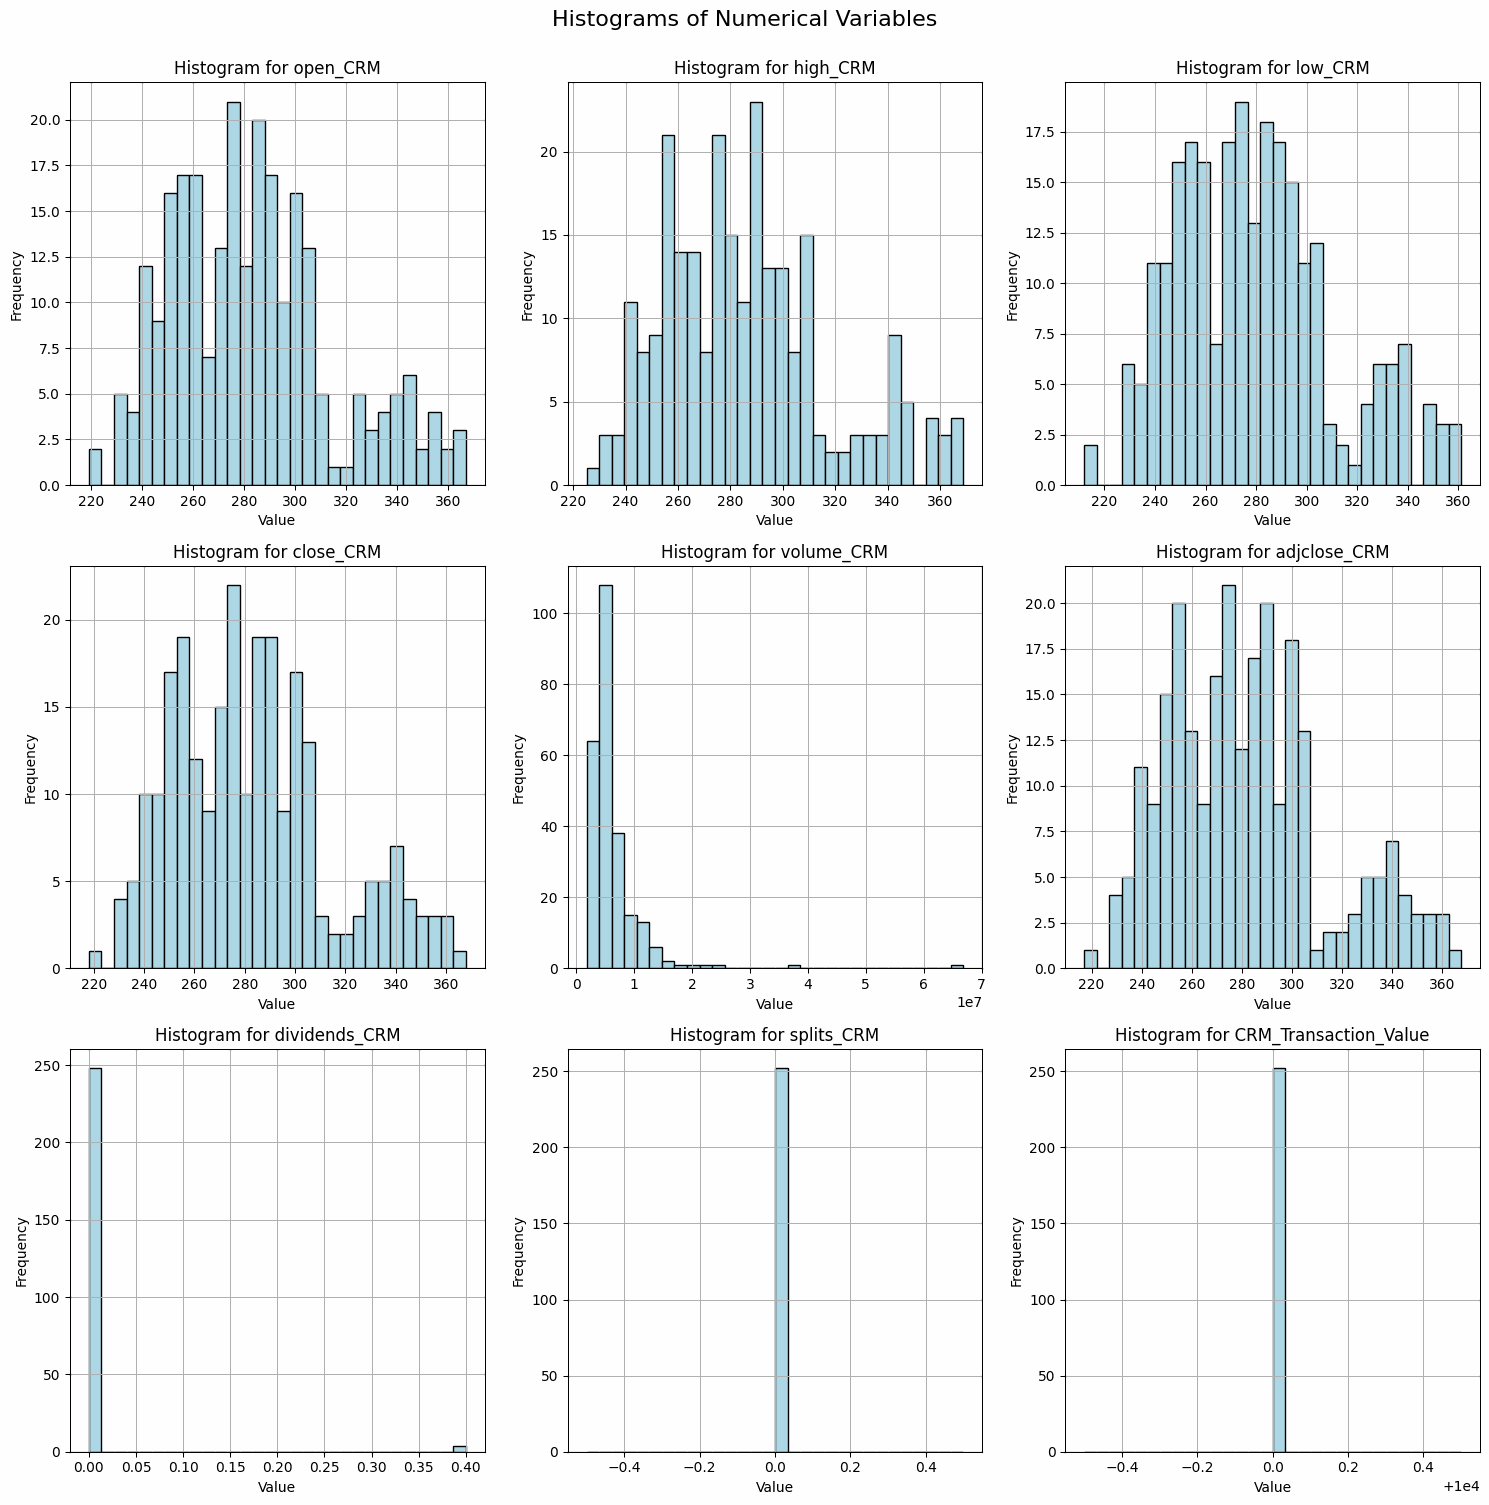

In [232]:
# Create histograms for CRM with x and y labels for each histogram
plot_histograms(df_CRM, num_cols_CRM)

The histograms in the provided image represent the distribution of various numerical variables related to Salesforce (CRM) stock data. Below is an analysis based on these distributions:

**Key Observations from the Histograms**

***Stock Price Distributions (Open, High, Low, Close, Adjusted Close)***

The distributions for open, high, low, close, and adjusted close prices are relatively normal but exhibit some skewness.

Most values appear to be concentrated between $240 and $320, with fewer occurrences of extreme high values (~$360 and above).

There is a high frequency of stock prices around the $260-$300 range, suggesting a stable trading zone for CRM.
Trading Volume (Volume_CRM)

The trading volume histogram is highly right-skewed, indicating that most days have low-to-moderate trading activity, but a few days have significantly high volumes.

The majority of trading volume values appear to be concentrated at the lower end of the scale, with some extreme spikes in activity.

***Dividends and Stock Splits***

The dividends_CRM and splits_CRM histograms show a single dominant bar, indicating that most of the time, Salesforce does not pay dividends or undergo stock splits.

The presence of occasional dividend values suggests that CRM may have distributed dividends on a few select occasions.

***Transaction Value (CRM_Transaction_Value)***

The CRM_Transaction_Value histogram shows a single value, which means the transaction amount remains constant throughout the dataset.

**Implications for Portfolio Optimization**

The price distributions suggest relative stability, making CRM a potential low-risk asset within a diversified portfolio.

Volume spikes indicate key market events, which could present trading opportunities or volatility risks.

Low dividend activity confirms Salesforce’s reinvestment-focused strategy, meaning it’s better suited for growth-oriented investors rather than dividend-seeking investors.

No stock splits recorded suggest that CRM has maintained its stock structure over the analyzed period, which can impact liquidity and investor sentiment.

### BOXPLOTS

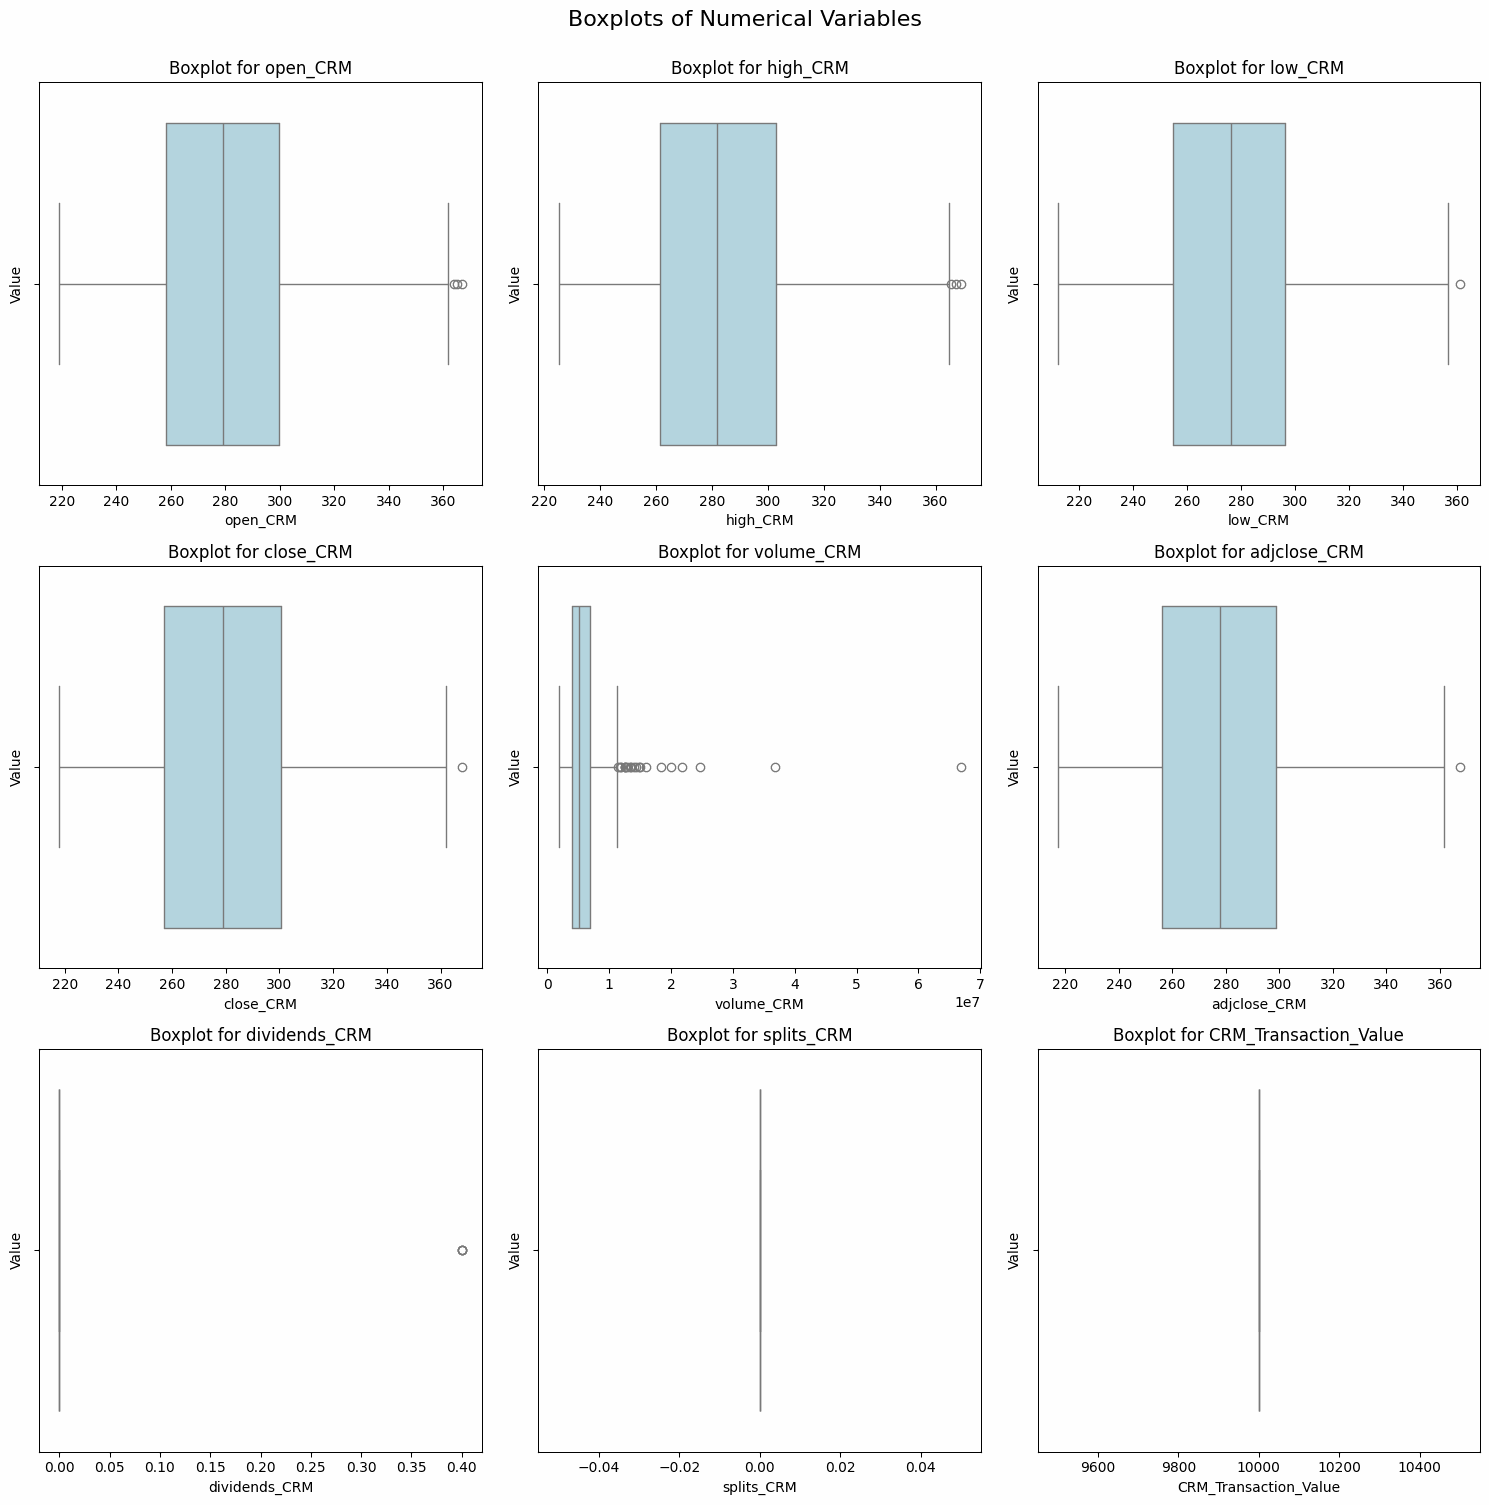

In [233]:
# Create boxplots for CRM with x and y labels for each boxplot
plot_boxplots(df_CRM, num_cols_CRM)

**Boxplot Analysis of CRM Numerical Variables**

The boxplots visualize the distribution, spread, and potential outliers in various numerical features of Salesforce (CRM) stock data. Below is an interpretation of the key insights:

***Stock Price Distributions (Open, High, Low, Close, Adjusted Close)***

The boxplots for open, high, low, close, and adjusted close prices indicate a relatively symmetrical distribution, suggesting consistent price movements.

The interquartile range (IQR) is concentrated between approximately $250 and $320, indicating that most stock prices fall within this range.

Some outliers exist on the higher end (~$360-$370 range), suggesting occasional price spikes that may have been caused by market events, earnings announcements, or external macroeconomic factors.

***Trading Volume (Volume_CRM)***

The volume boxplot is highly skewed, with several outliers on the higher end.

Most trading volume is clustered in the lower range, but extreme spikes in volume occur, likely due to market reactions to company earnings re
ports or major business news.

The presence of multiple outliers in volume suggests periods of heightened trading activity that could impact stock volatility.

**Dividends and Stock Splits**

The dividends_CRM boxplot shows an outlier, meaning Salesforce paid a dividend at least once, but it is rare.
The splits_CRM boxplot is nearly empty, indicating no stock splits occurred throughout the period.

**Transaction Value (CRM_Transaction_Value)**

The CRM_Transaction_Value boxplot appears as a single line, suggesting a constant transaction value throughout the dataset.

**Implications for Portfolio Optimization**

CRM stock generally exhibits stable pricing, but the presence of occasional price spikes and trading volume surges suggests short-term volatility.

Volume outliers may indicate good entry or exit points for traders, as they correspond to high-activity periods.

The lack of consistent dividends and stock splits confirms CRM’s growth-oriented investment strategy, making it more suitable for capital appreciation rather than income generation.

Risk-aware portfolio optimization should consider CRM’s occasional high volatility when determining its weight in an investment strategy.

## NVIDA (NVDA)

In [234]:
num_cols_NVDA = df_NVDA.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

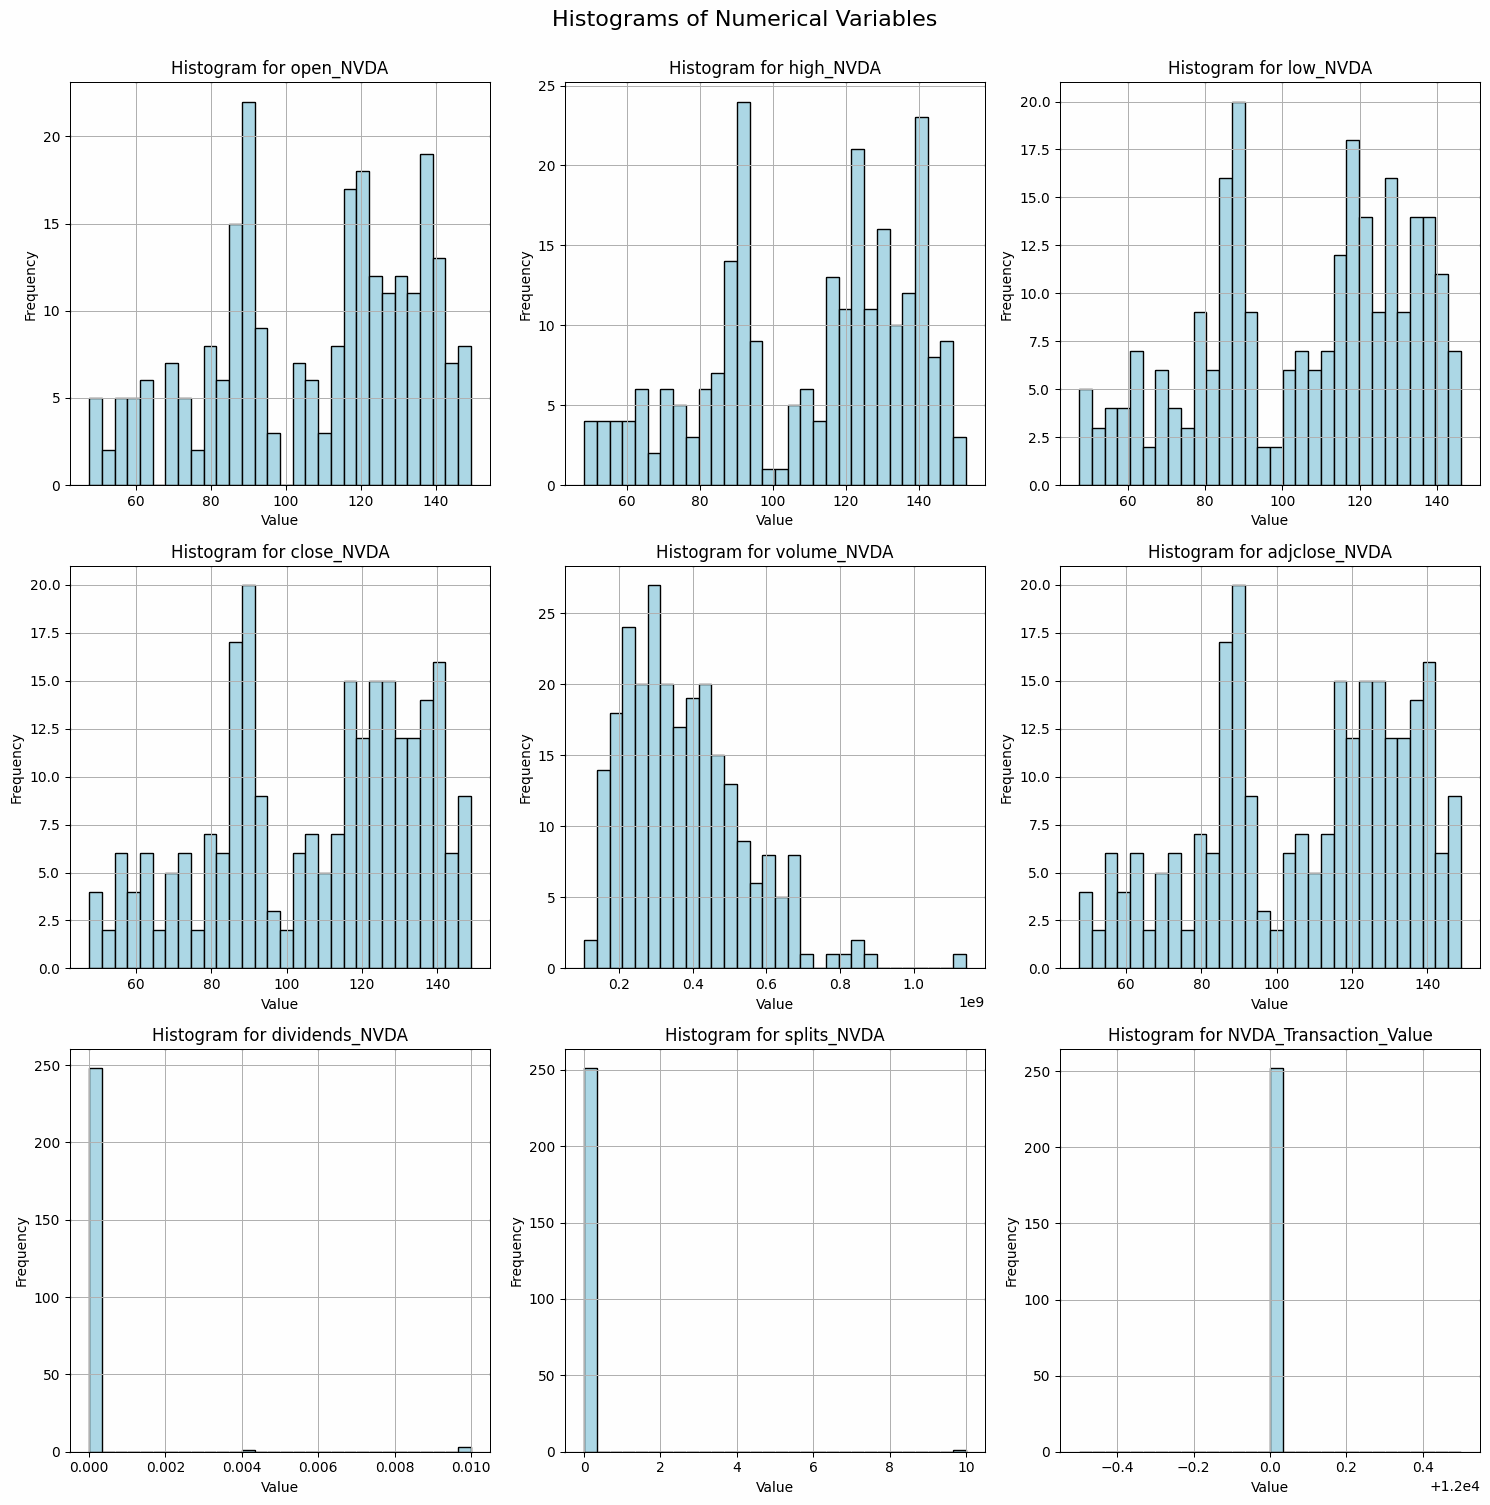

In [235]:
# Create histograms for NVDA with x and y labels for each histogram
plot_histograms(df_NVDA, num_cols_NVDA)

**Histogram Analysis of NVIDIA (NVDA) Numerical Variables**

The histograms in the image represent the distribution of various numerical variables related to NVIDIA (NVDA) stock data. Below is an analysis based on these distributions:

**Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**

The open, high, low, close, and adjusted close price distributions show two distinct peaks, indicating bimodal behavior in stock prices.

This suggests that NVDA experienced significant price shifts over time, likely due to external factors such as earnings reports, technological advancements, or AI sector developments.

The price range spans from approximately $50 to $150, with clusters of frequent trading between $80-$100 and $120-$140, indicating two major price zones of market activity.

**Trading Volume (Volume_NVDA)**

The trading volume histogram is right-skewed, meaning most trading days had moderate volume, but a few days had extremely high trading activity.

The presence of a long tail with high-frequency trading spikes suggests key events, such as earnings releases, AI market news, or geopolitical factors influencing semiconductor demand.

**Dividends and Stock Splits**

The dividends_NVDA histogram shows a single dominant value, meaning NVIDIA rarely pays dividends.

The splits_NVDA histogram has a second value, indicating that a stock split occurred at least once in the dataset.

This aligns with NVIDIA’s strategy of prioritizing reinvestment and growth rather than frequent dividend distributions.

**Transaction Value (NVDA_Transaction_Value)**

The NVDA_Transaction_Value histogram is a single constant value, meaning the transaction amount remains fixed in the dataset.

**Implications for Portfolio Optimization**

NVDA’s price distributions suggest high volatility, meaning risk management strategies must be incorporated into portfolio allocation.

The presence of two distinct price clusters suggests significant long-term price movements, which could impact investment timing decisions.

High trading volume spikes indicate strong market interest, suggesting potential trading opportunities around earnings seasons or major AI-related news.

The occurrence of a stock split indicates NVIDIA’s strategy to maintain share accessibility, which can influence investor perception and stock liquidity.

### BOXPLOTS

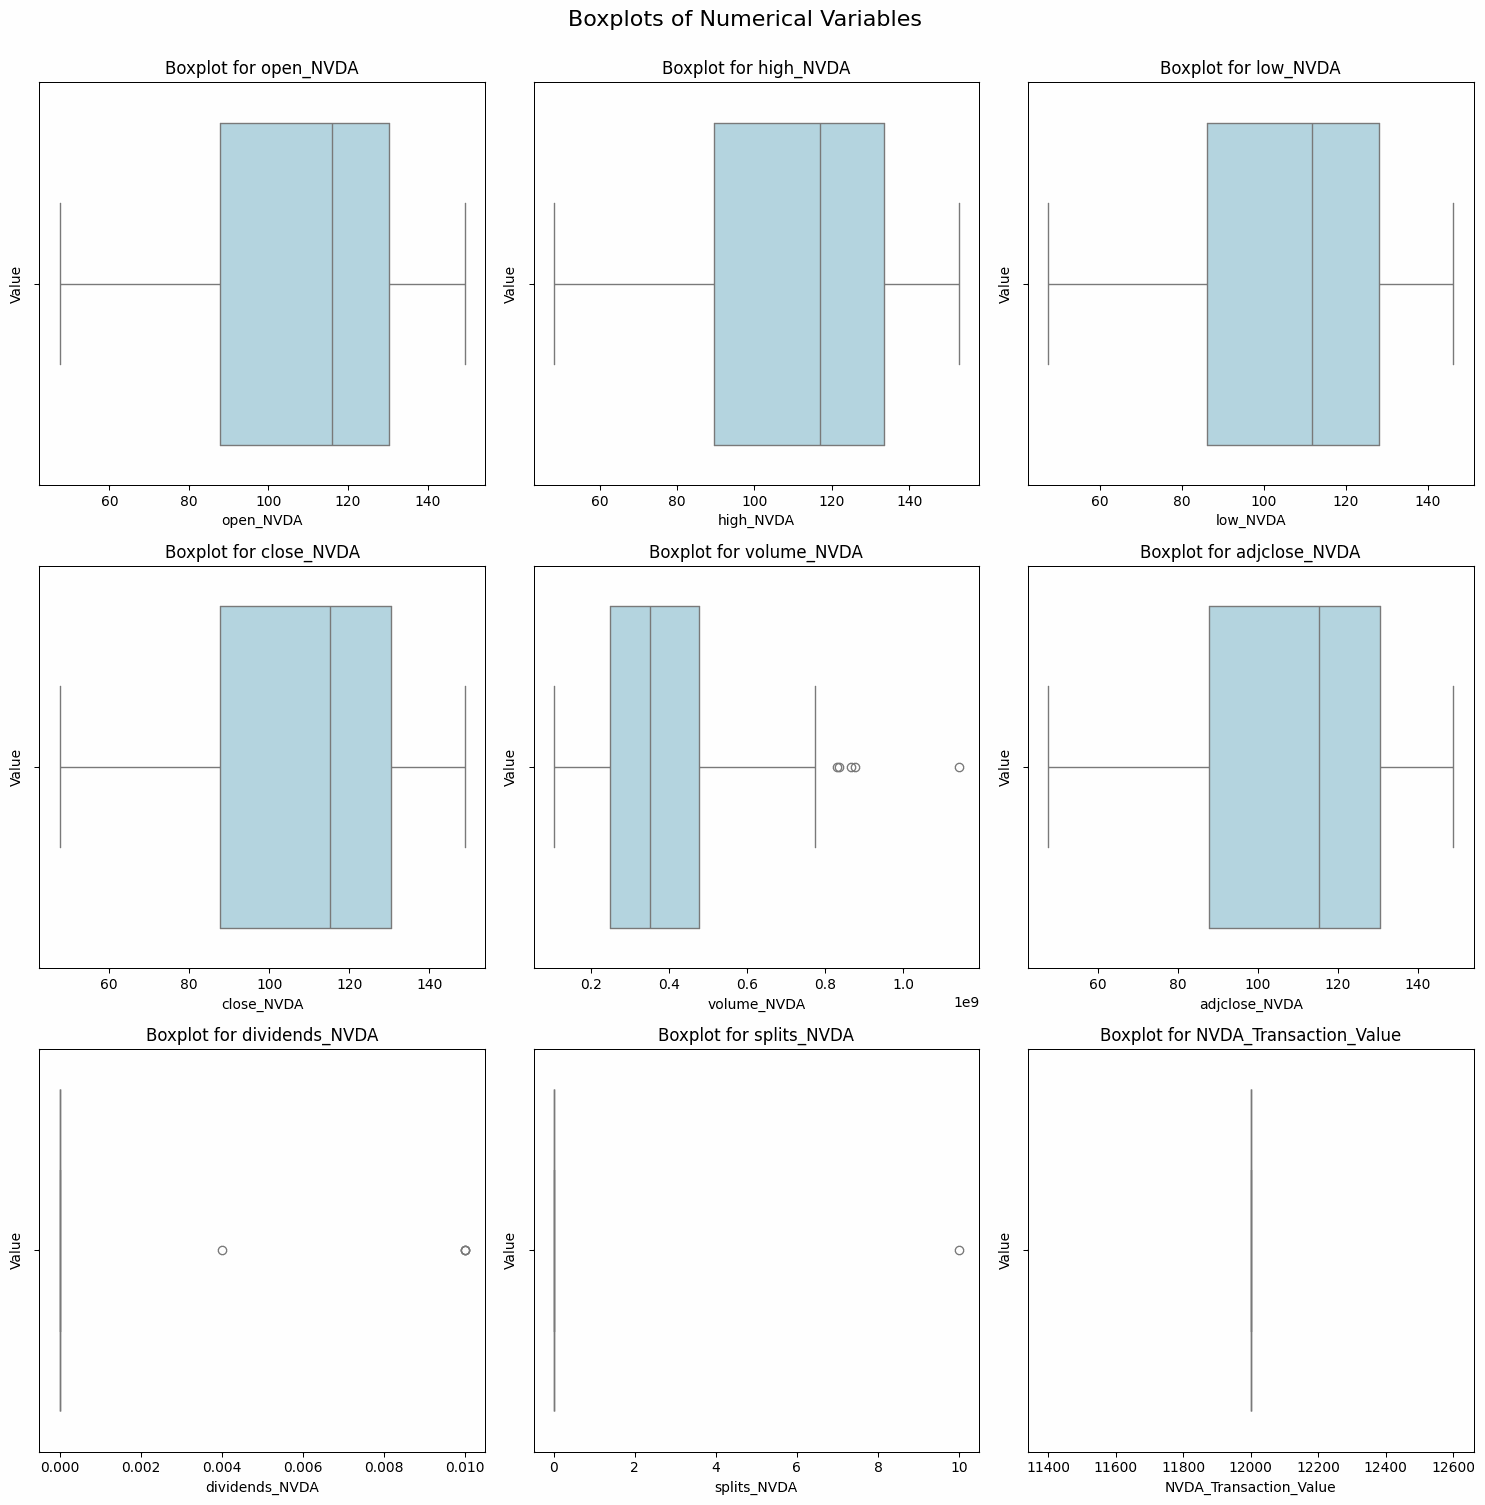

In [236]:
# Create boxplots for NVDA with x and y labels for each boxplot
plot_boxplots(df_NVDA, num_cols_NVDA)

**Boxplot Analysis of NVIDIA (NVDA) Numerical Variables**

The boxplots in the image display the distribution, spread, and potential outliers for various NVIDIA (NVDA) stock data variables. Below is an interpretation based on these distributions:

**Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**

The open, high, low, close, and adjusted close price boxplots show a relatively symmetric distribution, meaning that NVDA’s price movements are fairly stable over time.

The interquartile range (IQR) is wide, spanning from approximately $80 to $140, indicating significant price fluctuations.

There are no major outliers in these price-related boxplots, suggesting consistent price changes without extreme anomalies.

**Trading Volume (Volume_NVDA)**

The trading volume boxplot shows multiple outliers on the higher end, meaning most trading days have moderate volume, but a few days experienced extremely high trading activity.
The presence of extreme volume spikes suggests market reactions to events such as:

* Earnings reports
* AI industry breakthroughs
* Geopolitical factors impacting semiconductor demand

Higher trading volume outliers indicate that certain periods had intense investor activity, which could be linked to price swings.

**Dividends and Stock Splits**

The dividends_NVDA boxplot shows very few data points, confirming that NVIDIA rarely issues dividends.

The splits_NVDA boxplot shows an outlier, meaning a stock split occurred during the dataset period.

This aligns with NVIDIA’s strategy of reinvesting in growth rather than focusing on dividend payouts.

**Transaction Value (NVDA_Transaction_Value)**
The NVDA_Transaction_Value boxplot appears as a single constant line, confirming that the transaction value remained fixed throughout the dataset.

**Implications for Portfolio Optimization**

NVDA’s stock price exhibits strong growth and volatility, meaning that risk factors should be considered in an optimized portfolio allocation.

Trading volume spikes indicate key market events, providing insights into optimal trading periods for entry or exit.

The occurrence of a stock split confirms NVIDIA’s market strategy, which could influence investor sentiment and liquidity.

Low dividend payments suggest NVDA is a growth-oriented stock, making it better suited for capital appreciation rather than income generation.

## MA (MASTERCARD)

In [237]:
num_cols_MA = df_MA.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

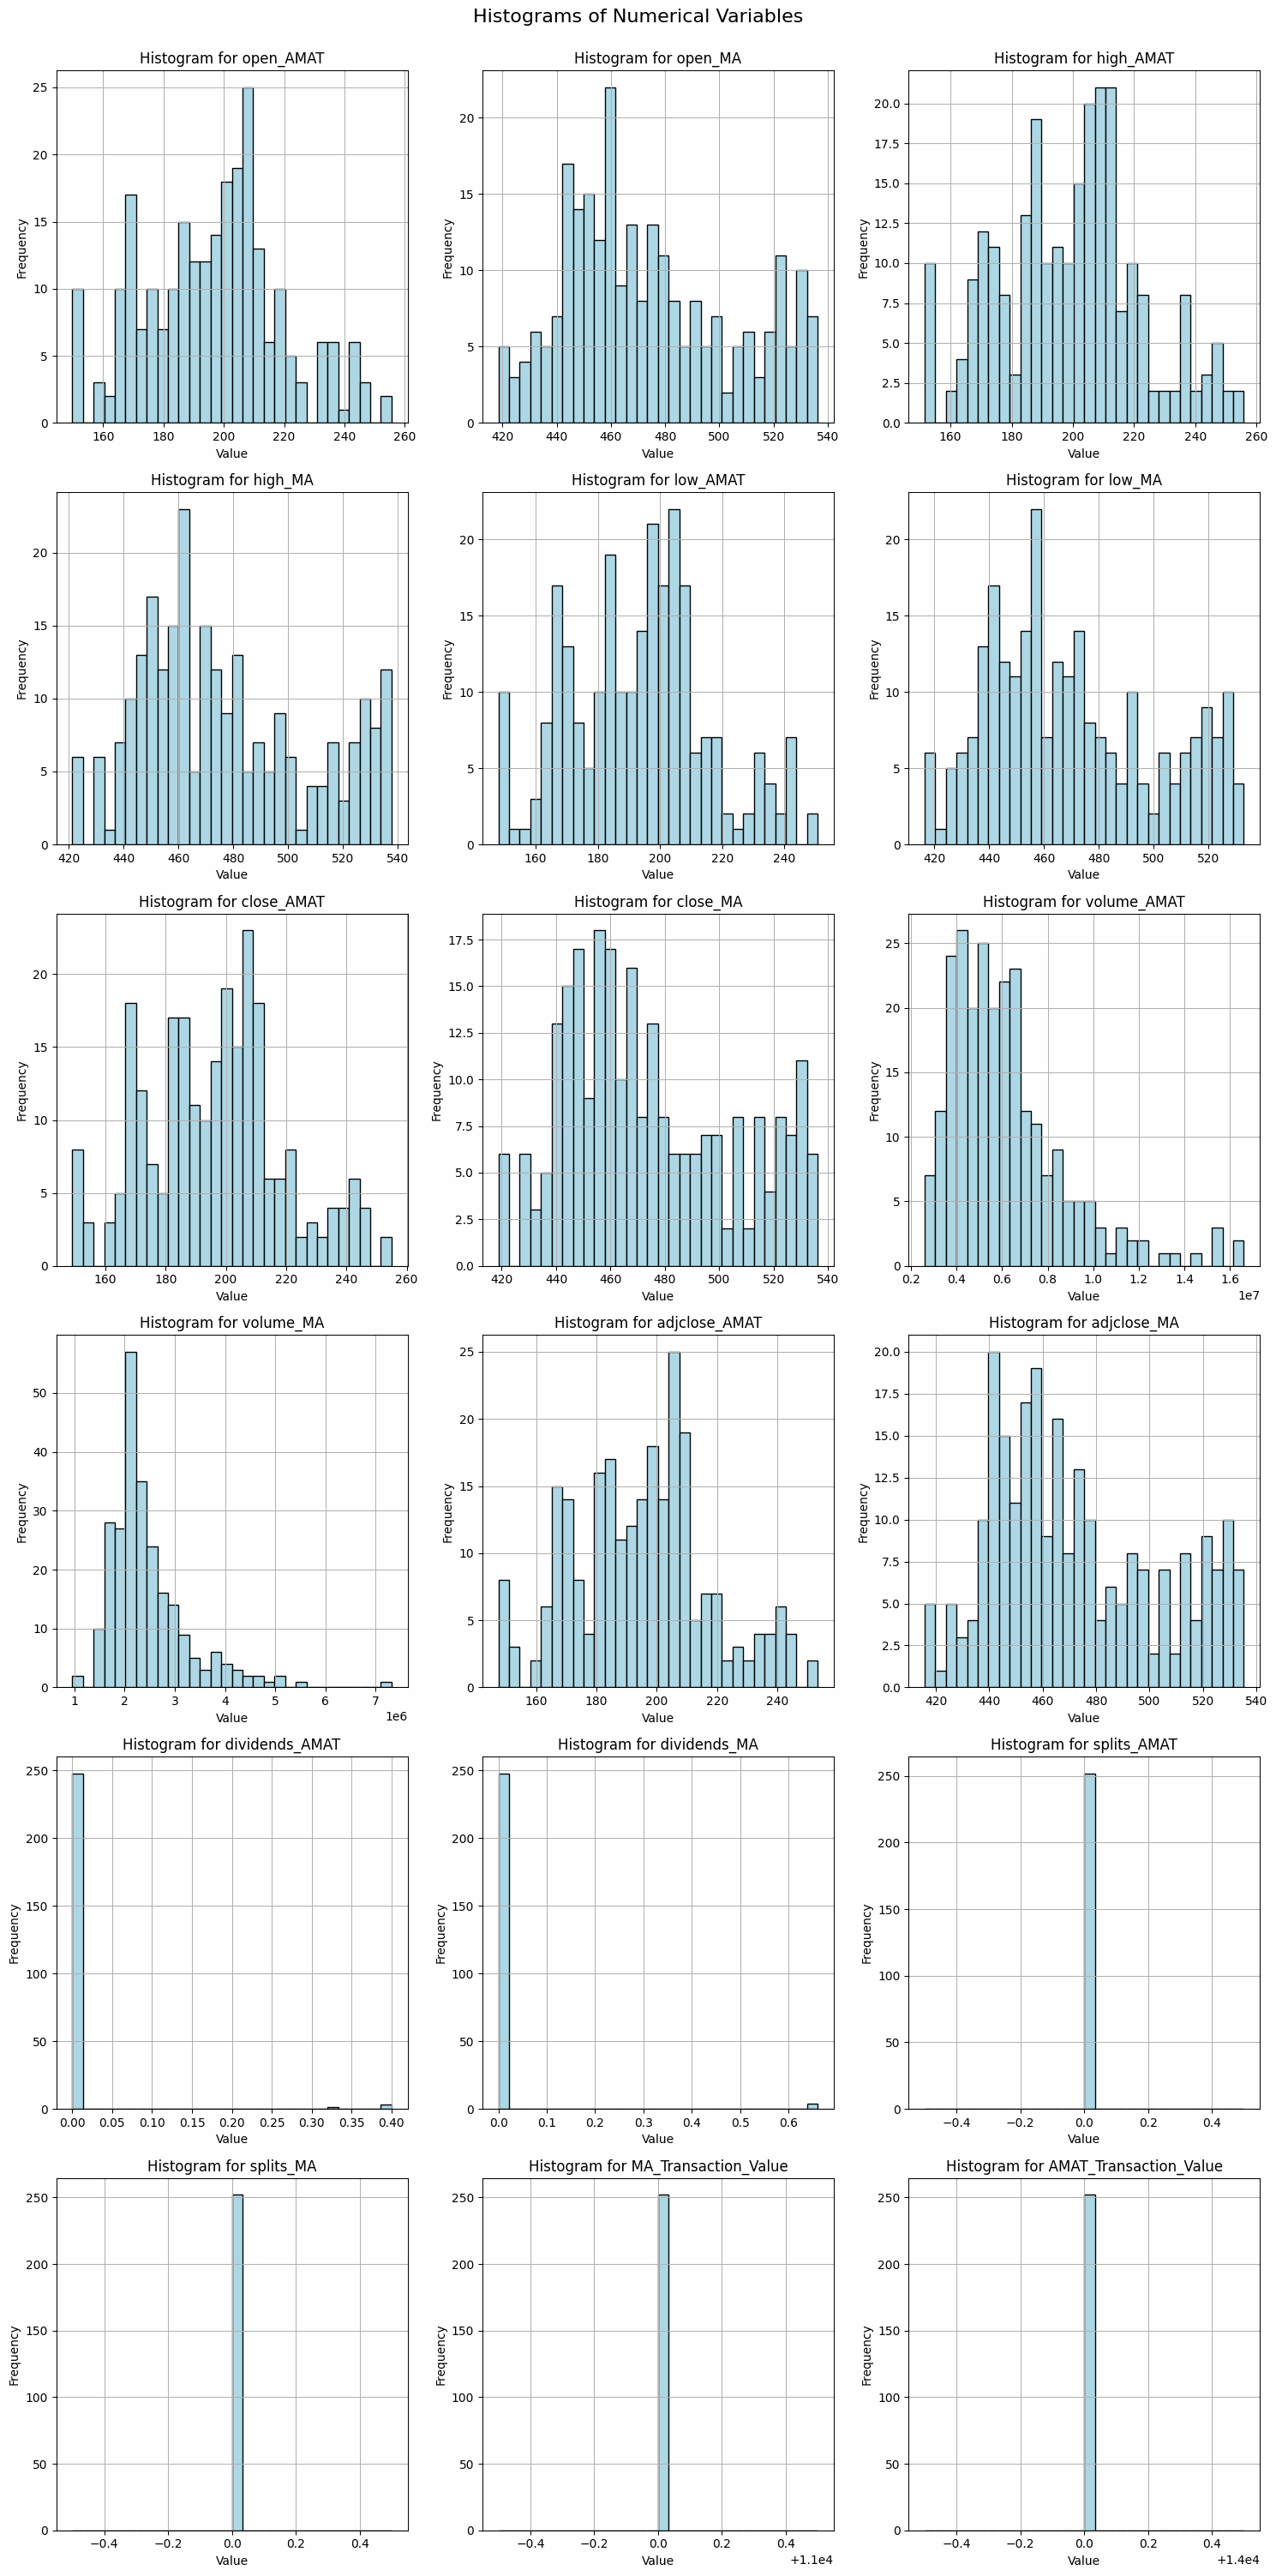

In [238]:
# Create histograms for MA with x and y labels for each histogram
plot_histograms(df_MA, num_cols_MA)

**Exploratory Data Analysis (EDA) – Mastercard Inc. (MA)**

The dataset contains 252 trading days of historical stock data for Mastercard Inc. (MA) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $474.13, with a minimum of $418.77 and a maximum of $536.15.

The standard deviation of $30.58 suggests moderate price volatility over the year.

The 25th percentile (Q1) is $449.72, and the 75th percentile (Q3) is $496.55, meaning that 50% of the stock’s prices were within this range.

The maximum high of $537.70 and minimum low of $416.53 indicate significant price movements, likely driven by earnings releases, macroeconomic trends, and developments in the financial technology sector.

**Trading Volume Trends**

The average daily trading volume is 2.47 million shares, with a standard deviation of 0.81 million, indicating steady investor participation with occasional volume fluctuations.

The minimum trading volume is 0.95 million, while the maximum reaches 7.32 million, suggesting that certain financial events, such as earnings reports and regulatory updates, lead to increased investor activity.

**Dividends and Stock Splits**

The average dividend per share is 0.0105, with a maximum of 0.66, indicating that Mastercard regularly issues dividends.

No stock splits occurred, meaning Mastercard maintained its share structure throughout the year.

Mastercard’s dividend strategy suggests a balance between shareholder returns and reinvestment for long-term growth.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

Mastercard exhibits stable growth with moderate volatility, making it a reliable asset in the portfolio.

The trading volume data indicates steady investor interest, with occasional surges reflecting key financial events.

Since Mastercard offers consistent dividends but does not engage in stock splits, investment strategies should balance capital appreciation with dividend income.

### BOXPLOTS

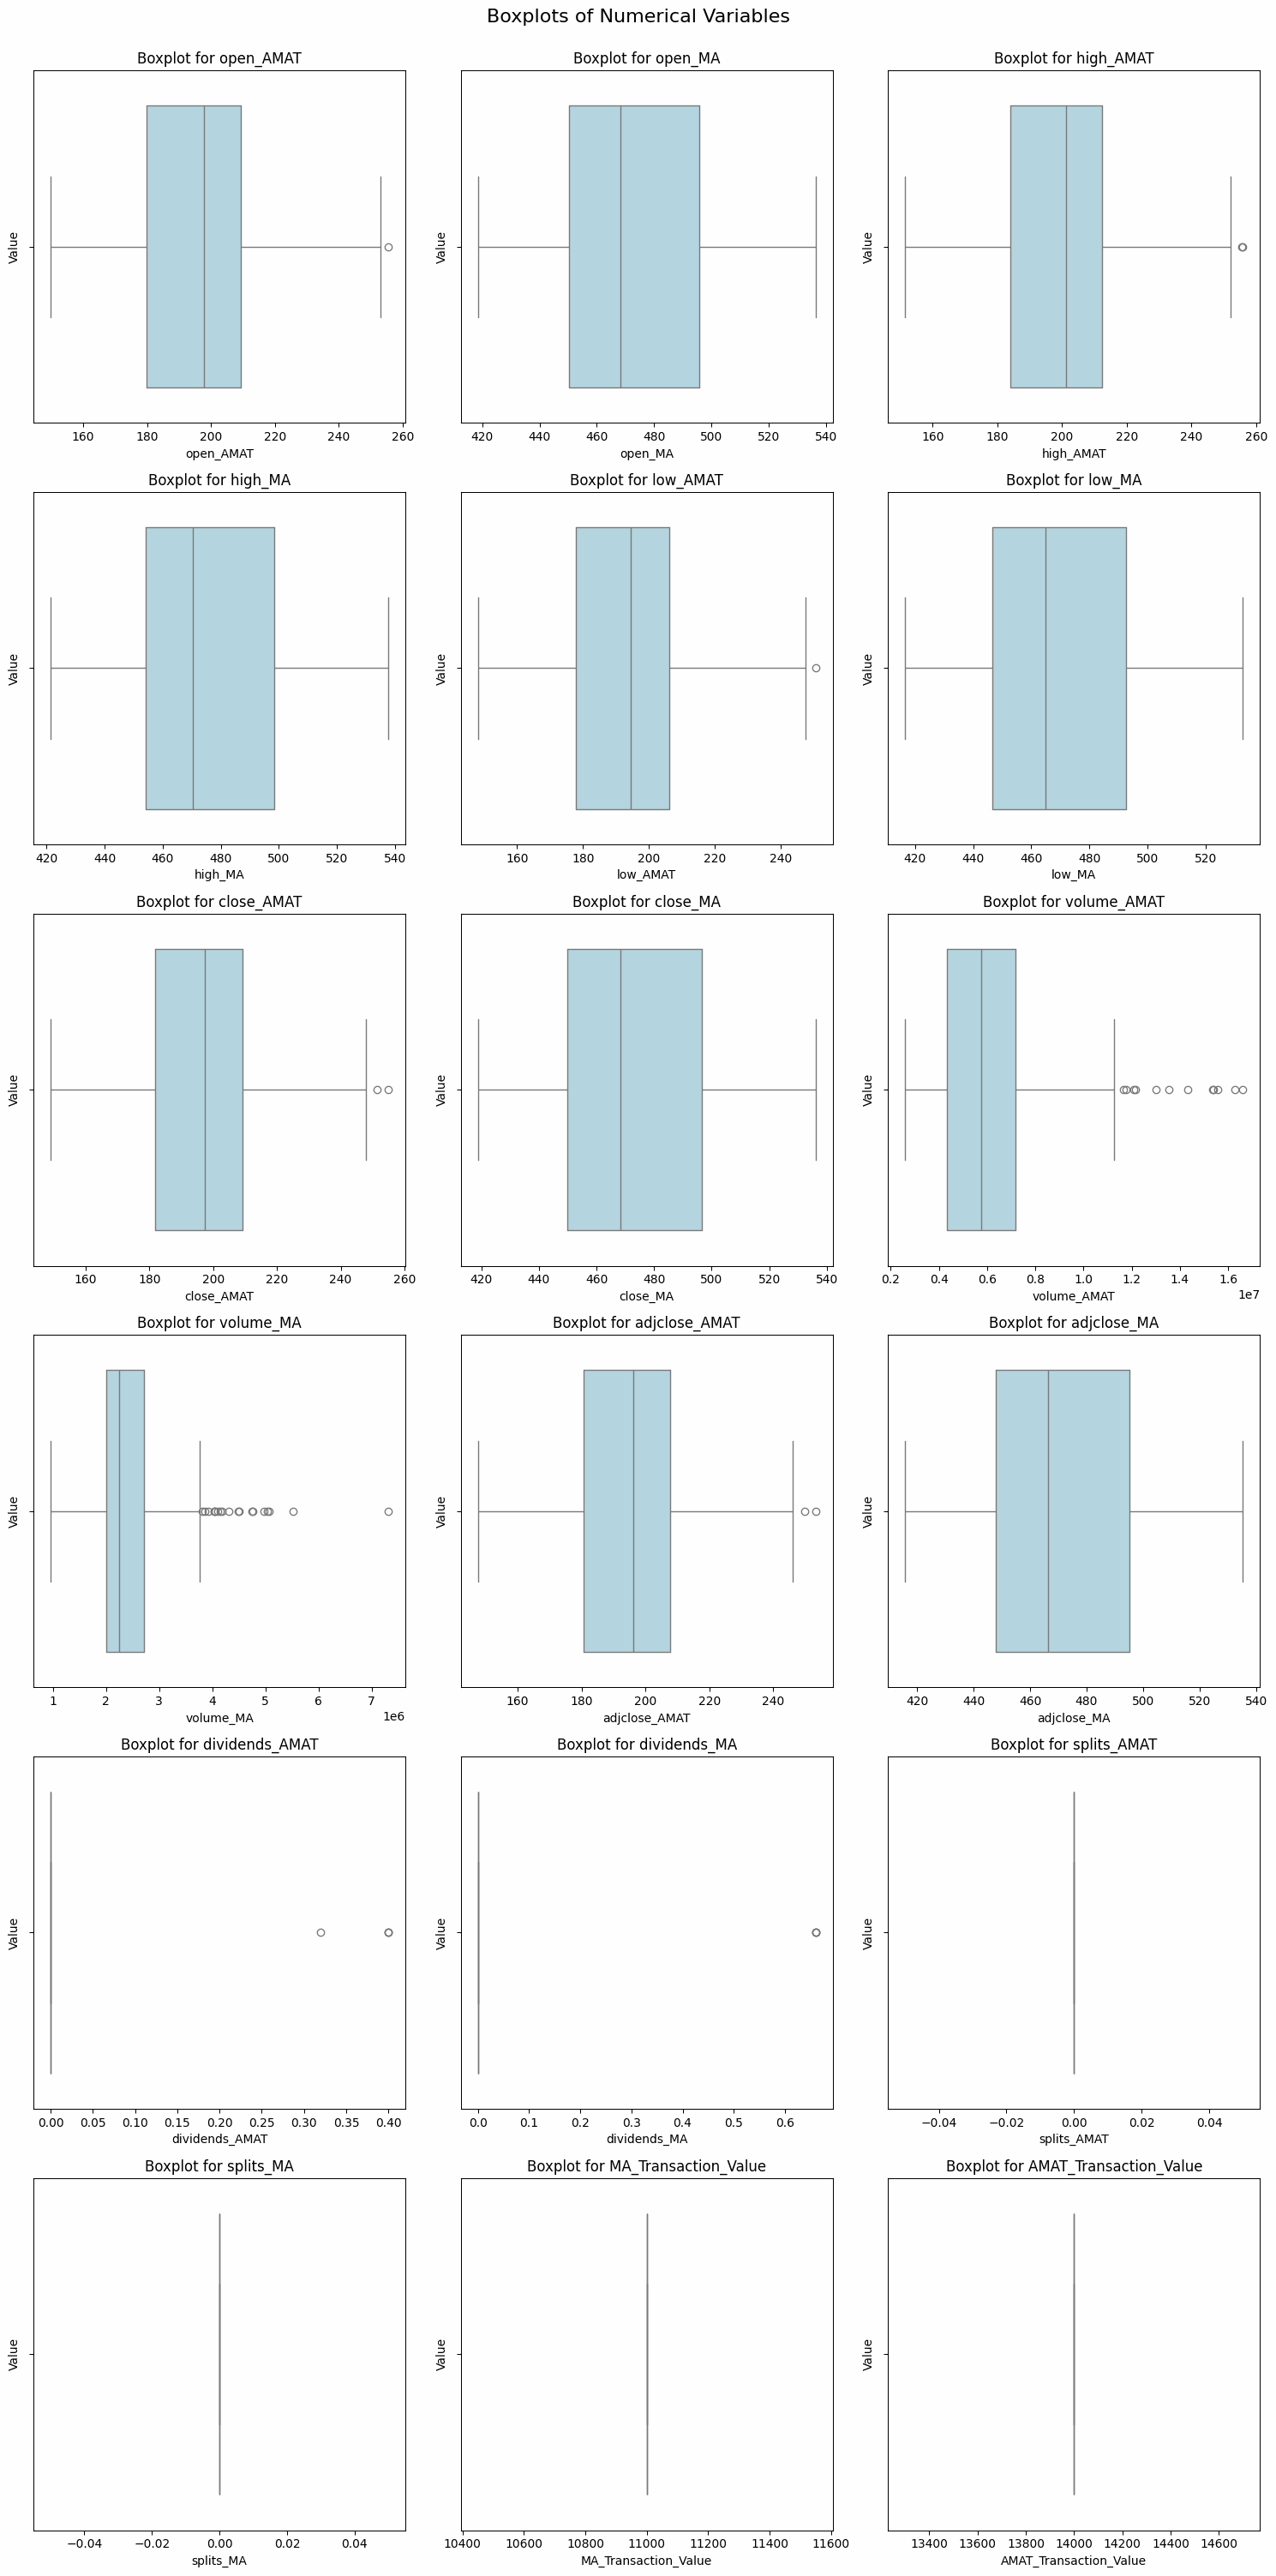

In [239]:
# Create boxplots for MA with x and y labels for each boxplot
plot_boxplots(df_MA, num_cols_MA)

**Boxplot Analysis of Applied Materials (AMAT) Numerical Variables**

The boxplots in the image display the distribution, spread, and potential outliers for various Applied Materials (AMAT) stock data variables. Below is a detailed interpretation based on these distributions.

**Stock Price Distributions**

The boxplots for open, high, low, close, and adjusted close prices indicate a fairly symmetrical distribution, suggesting that AMAT stock experienced consistent price movements with moderate volatility.

The interquartile range (IQR) is concentrated between $180 and $220, meaning that most of the stock prices remained within this range.

A few outliers appear in the high and low price ranges, indicating occasional significant price shifts, likely driven by earnings announcements or macroeconomic events.

**Trading Volume**

The trading volume boxplot shows a right-skewed distribution, meaning that most trading days had relatively low volume, but a few days experienced significantly high trading activity.

Several outliers in trading volume suggest spikes in investor participation, potentially linked to financial reports, semiconductor industry developments, or major technological advancements.

**Dividends and Stock Splits**

The dividends_AMAT boxplot contains a small number of outliers, confirming that Applied Materials issued dividends infrequently but in varying amounts.

The splits_AMAT boxplot does not indicate frequent stock splits, suggesting that Applied Materials maintains its stock structure without frequent adjustments to share count.

**Transaction Value**

The AMAT_Transaction_Value boxplot is represented by a single constant line, confirming that the transaction value remained fixed throughout the dataset.

**Key Takeaways for Optimization**

Applied Materials stock exhibits stable growth with occasional volatility, making it a strong asset with moderate risk.

The presence of volume outliers indicates key trading periods, which may present opportunities for strategic entry or exit points.

The company’s occasional dividend payouts but lack of frequent stock splits suggest a focus on reinvestment while still providing shareholder returns.

## HP (HPQ)

In [240]:
num_cols_HPQ = df_HPQ.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

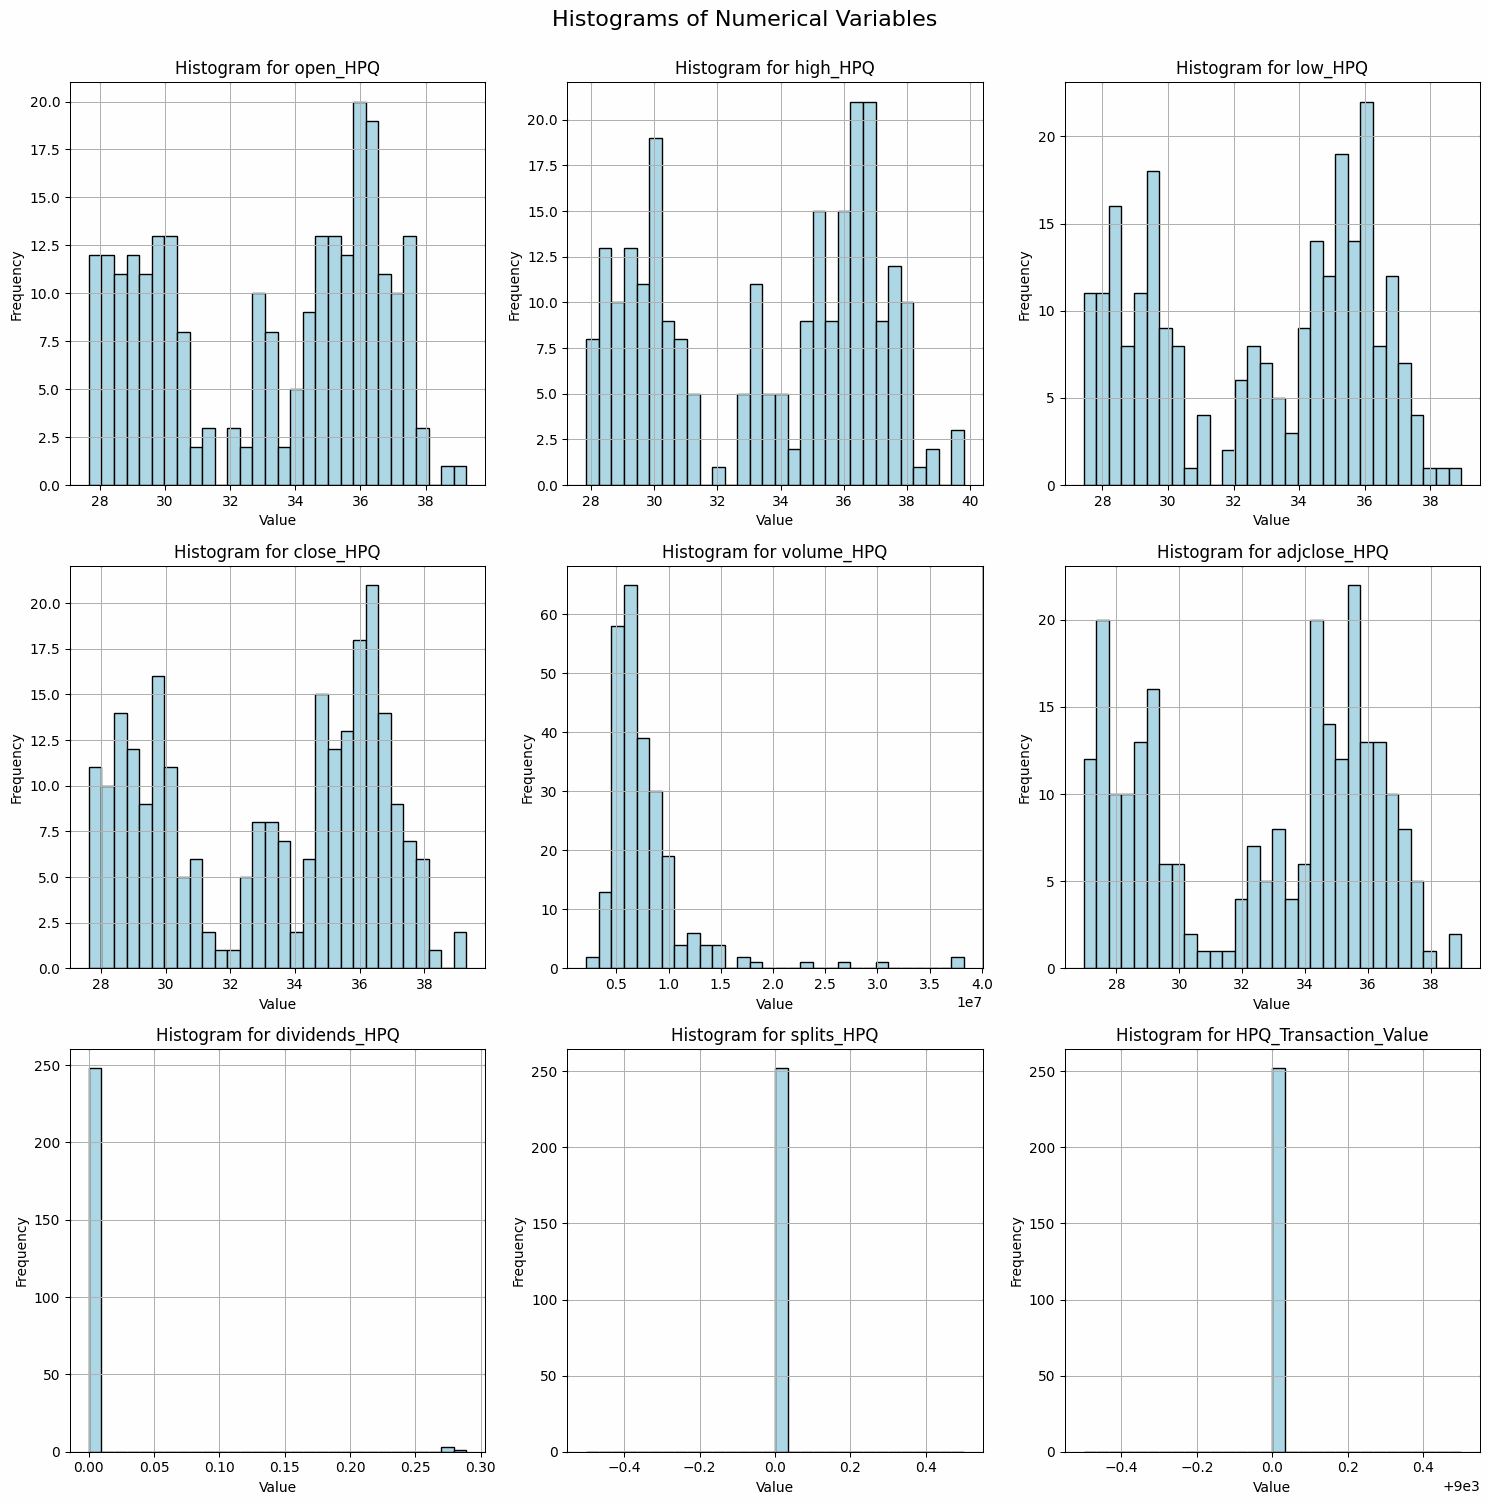

In [241]:
# Create histograms for HP with x and y labels for each histogram
plot_histograms(df_HPQ, num_cols_HPQ)

**Exploratory Data Analysis (EDA) – HP Inc. (HPQ)**

The dataset contains 252 trading days of historical stock data for HP Inc. (HPQ) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $33.14, with a minimum of $27.62 and a maximum of $39.30.

The standard deviation of $3.34 indicates moderate price fluctuations throughout the year.

The 25th percentile (Q1) is $29.72, and the 75th percentile (Q3) is $36.17, meaning that 50% of the stock’s prices remained within this range.

The maximum high of $39.80 and minimum low of $27.43 suggest significant price movements, potentially driven by earnings releases, supply chain issues, or changes in PC market demand.

**Trading Volume Trends**

The average daily trading volume is 7.79 million shares, with a standard deviation of 4.27 million, showing some variation in investor participation.

The minimum trading volume is 2.13 million, while the maximum reaches 38.26 million, suggesting occasional spikes in trading activity, likely due to earnings reports or industry-related announcements.

**Dividends and Stock Splits**

The average dividend per share is $0.0044, with a maximum of $0.289, indicating that HP regularly issues dividends.

No stock splits occurred, meaning HP has maintained its share structure throughout the year.

HP’s dividend policy suggests a shareholder-focused approach with steady payouts while balancing reinvestment for growth.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices and int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity and completeness.

**Key Takeaways for Optimization**

HPQ exhibits moderate volatility with steady price growth, making it a stable yet dynamic asset within a portfolio.

The trading volume data suggests consistent investor interest, with occasional high-volume days that may present short-term trading opportunities.

Since HP offers regular dividends but does not engage in stock splits, investment strategies should consider both income generation and capital appreciation potential.

### BOXPLOTS

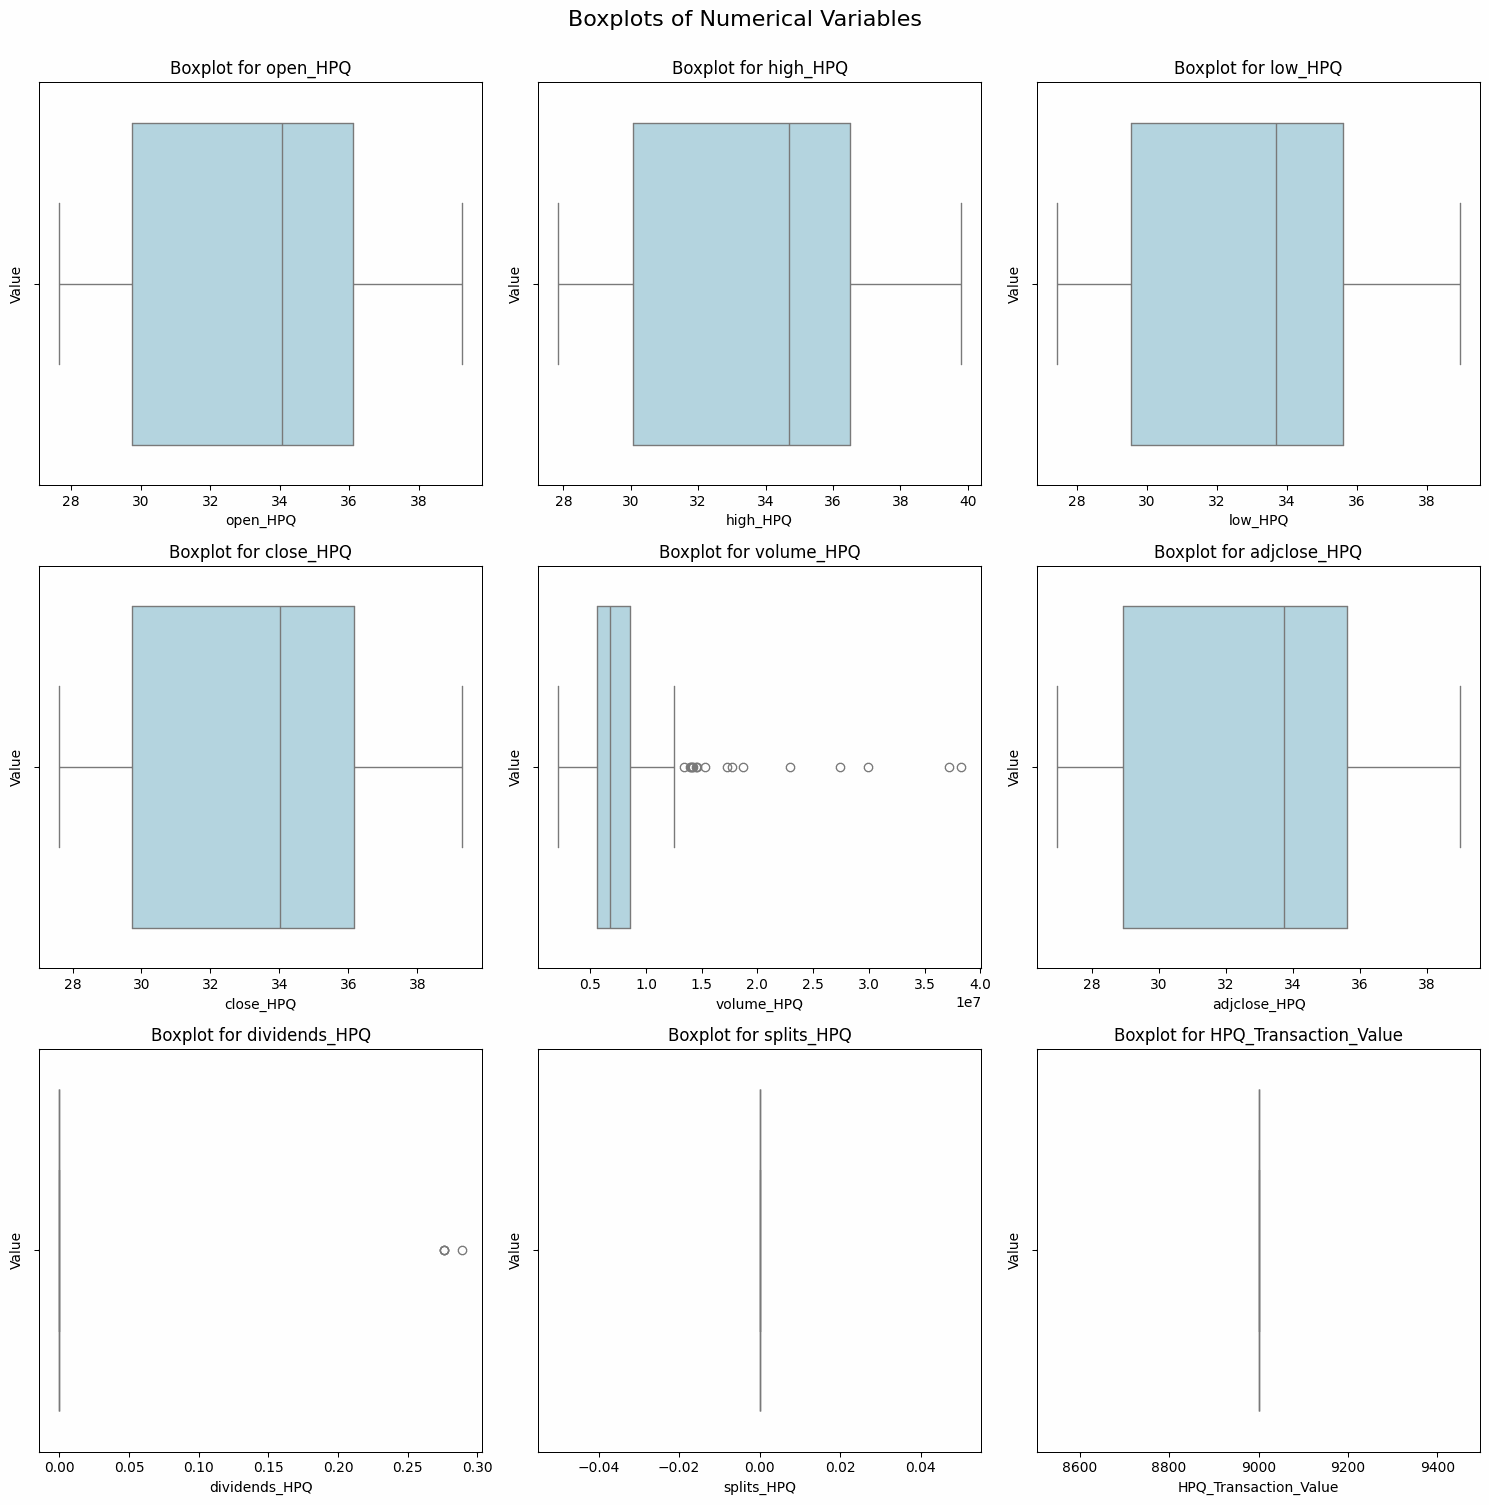

In [242]:
# Create boxplots for HP with x and y labels for each boxplot
plot_boxplots(df_HPQ, num_cols_HPQ)

**Boxplot Analysis of HP Inc. (HPQ) Numerical Variables**

The boxplots in the image display the distribution, spread, and potential outliers for various HP Inc. (HPQ) stock data variables. Below is a detailed interpretation based on these distributions.

**Stock Price Distributions**

The boxplots for open, high, low, close, and adjusted close prices indicate a fairly symmetrical distribution, suggesting that HPQ stock experienced consistent price movements with moderate volatility.

The interquartile range (IQR) is concentrated between $30 and $36, meaning that most of the stock prices remained within this range throughout the year.

There are no extreme outliers in the price-based boxplots, suggesting that HPQ’s stock price movements were relatively stable without major anomalies.

**Trading Volume**

The trading volume boxplot is right-skewed, indicating that most trading days had lower volume, but a few days experienced significantly high trading activity.

Several outliers exist in trading volume, suggesting spikes in investor activity likely driven by earnings reports, macroeconomic trends, or company-specific announcements.

**Dividends and Stock Splits**

The dividends_HPQ boxplot contains a few outliers, confirming that HP issued dividends periodically, but the amounts varied over time.

The splits_HPQ boxplot does not indicate frequent stock splits, meaning HP has maintained its share structure without major adjustments.

**Transaction Value**

The HPQ_Transaction_Value boxplot is represented by a single constant line, confirming that the transaction value remained fixed throughout the dataset.

**Key Takeaways for Optimization**

HPQ stock exhibits moderate volatility with a stable price range, making it a relatively safe investment with some potential for capital growth.

The presence of trading volume outliers suggests key periods of increased investor interest, which may present strategic entry and exit points.

The company’s regular dividend payouts but lack of stock splits suggest a focus on steady shareholder returns while maintaining stock price stability.

## EBAY (EBAY)

In [243]:
num_cols_EBAY = df_Ebay.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

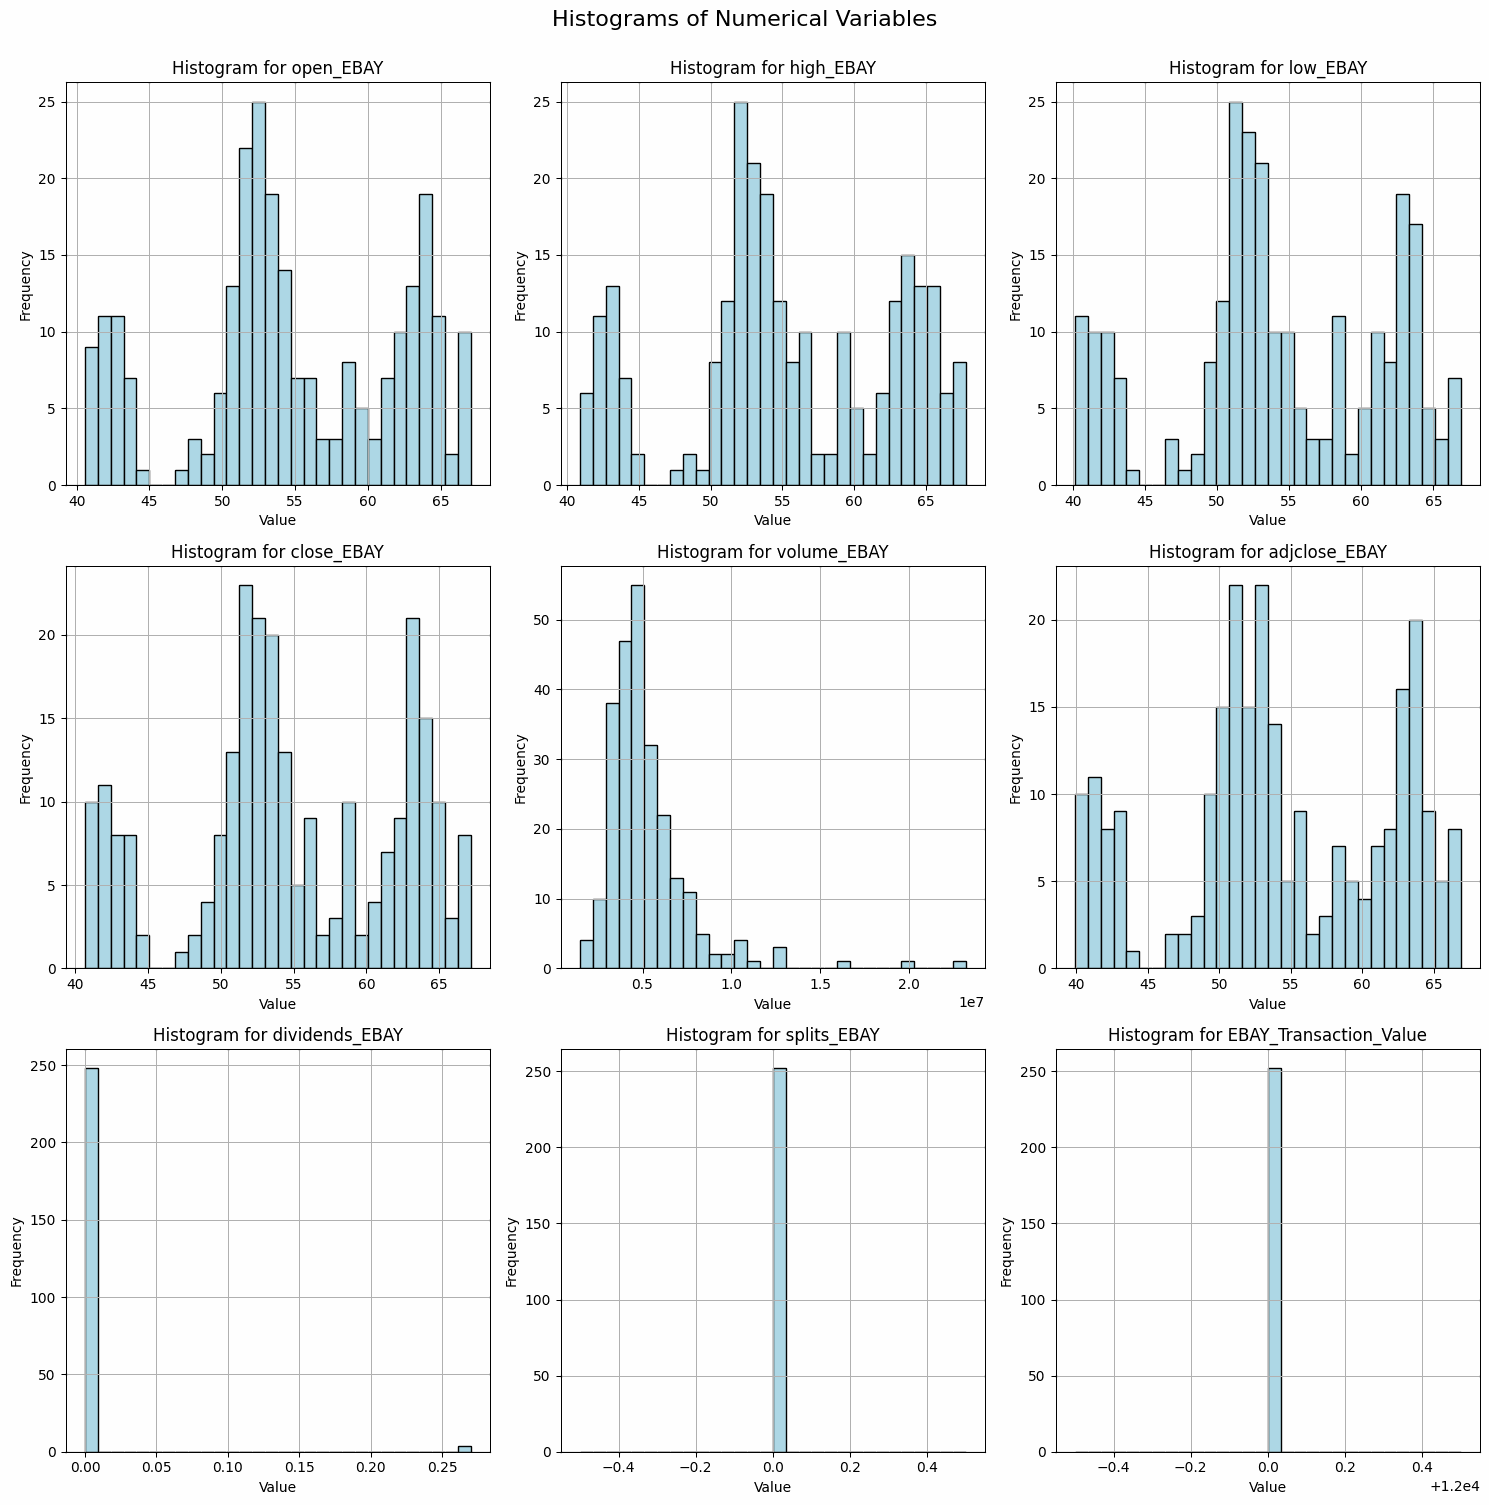

In [244]:
# Create histograms for EBAY with x and y labels for each histogram
plot_histograms(df_Ebay, num_cols_EBAY)

**Exploratory Data Analysis (EDA) – eBay Inc. (EBAY)**

The dataset contains 252 trading days of historical stock data for eBay Inc. (EBAY) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $54.78, with a minimum of $40.67 and a maximum of $67.17.

The standard deviation of $7.36 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is $51.16, and the 75th percentile (Q3) is $61.97, meaning that 50% of the stock’s prices were within this range.

The maximum high of $67.80 and minimum low of $40.16 indicate significant price movement, likely influenced by earnings reports, e-commerce trends, and macroeconomic factors.

**Trading Volume Trends**

The average daily trading volume is 5.26 million shares, with a standard deviation of 2.49 million, indicating moderate variation in investor activity.

The minimum trading volume is 1.47 million, while the maximum reaches 23.21 million, suggesting periodic spikes in market participation, potentially due to quarterly earnings releases and industry news.

**Dividends and Stock Splits**

The average dividend per share is $0.0043, with a maximum of $0.27, indicating that eBay issues modest dividends to shareholders.

No stock splits occurred, meaning eBay maintained a consistent share structure throughout the year.

eBay’s dividend policy suggests a focus on reinvestment and shareholder value, balancing capital growth and income distribution.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices and int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity and completeness.

**Key Takeaways for Optimization**

EBAY stock exhibits moderate volatility with strong price appreciation, making it a potential growth asset within a diversified portfolio.

The trading volume data suggests consistent investor interest, with occasional high-volume days that may present trading opportunities.

Since eBay offers modest dividends but does not engage in stock splits, investment strategies should focus primarily on capital appreciation rather than dividend income.

### BOXPLOTS

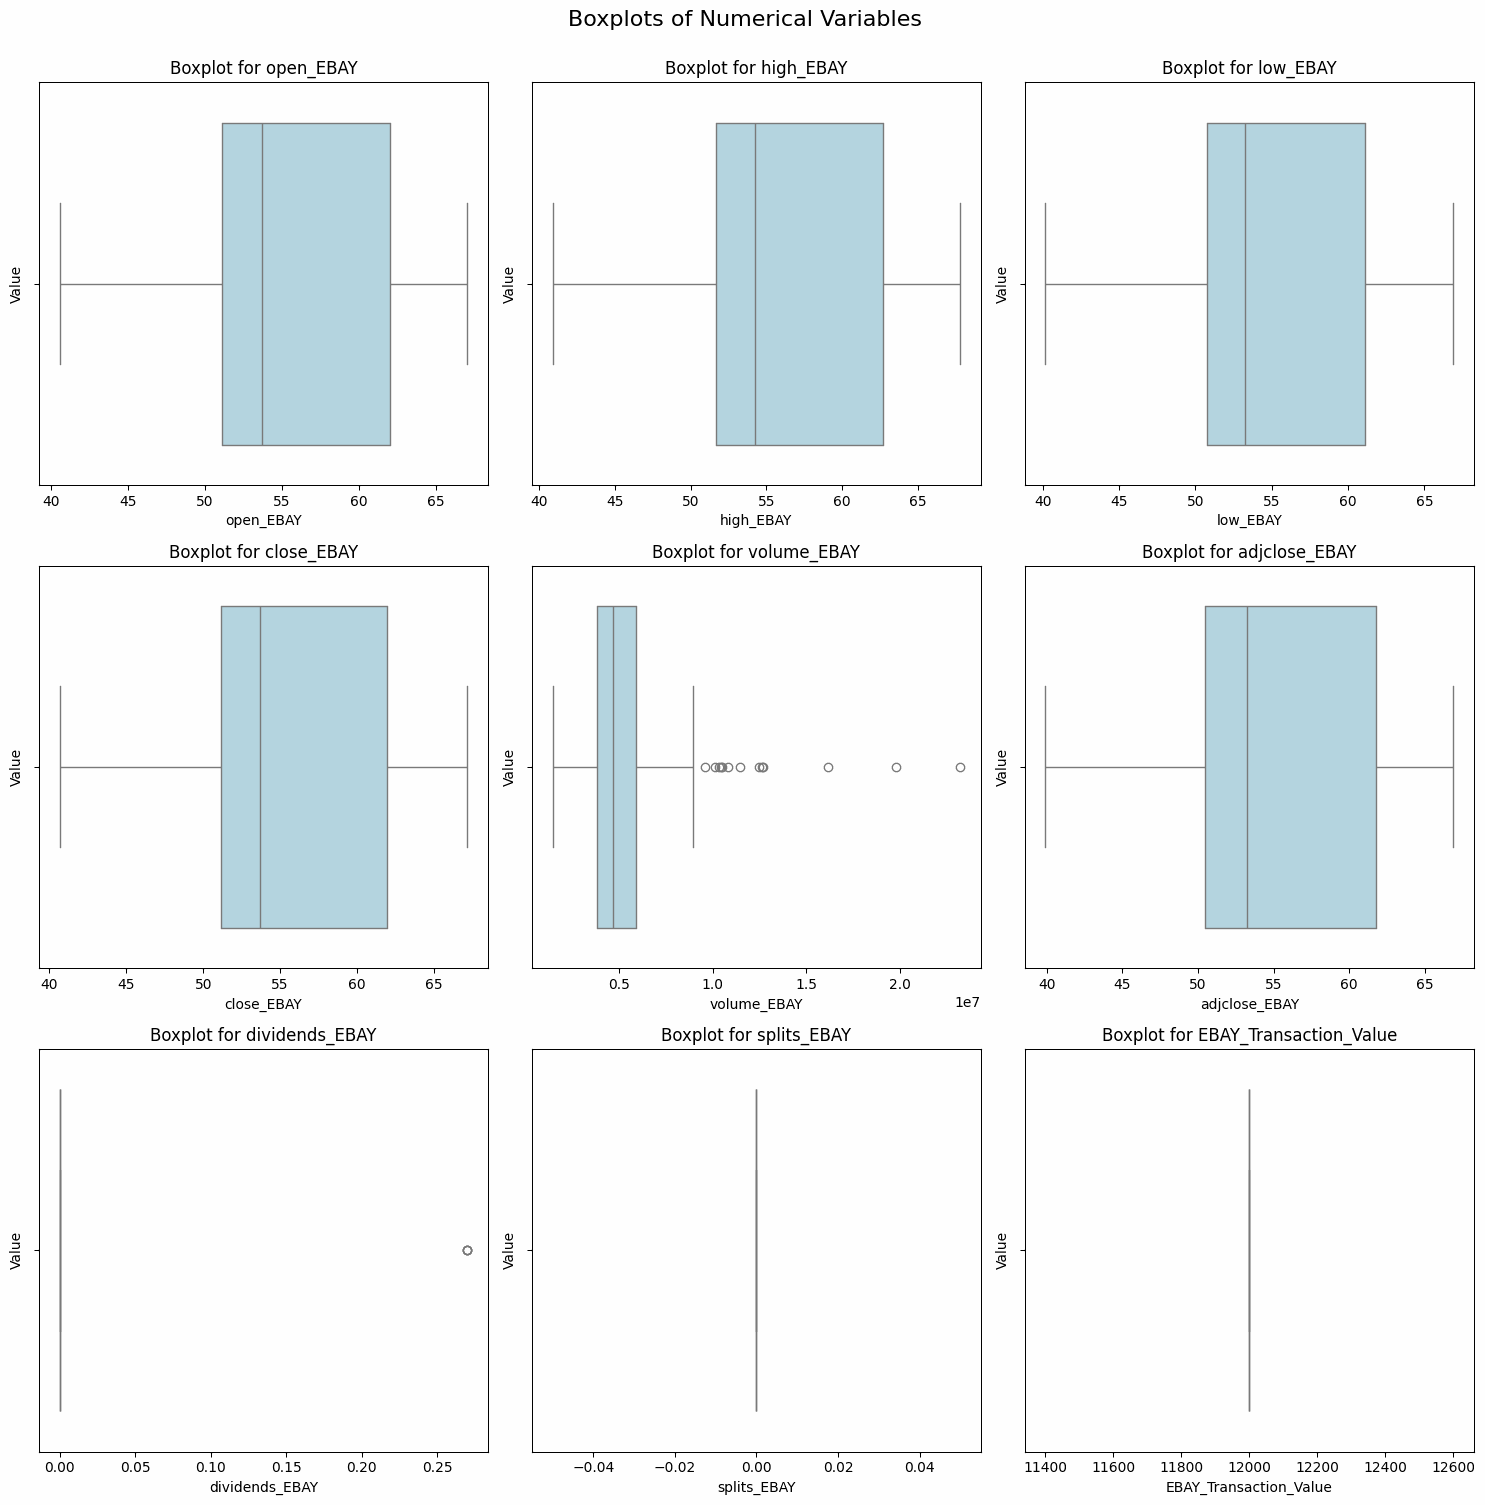

In [245]:
# Create boxplots for EBAY with x and y labels for each boxplot
plot_boxplots(df_Ebay, num_cols_EBAY)

**Boxplot Analysis of eBay Inc. (EBAY) Numerical Variables**

The boxplots in the image display the distribution, spread, and potential outliers for various eBay Inc. (EBAY) stock data variables. Below is a detailed interpretation based on these distributions.

**Stock Price Distributions**

The boxplots for open, high, low, close, and adjusted close prices indicate a relatively symmetrical distribution, suggesting that EBAY stock experienced stable price movements with moderate volatility.

The interquartile range (IQR) is concentrated between $50 and $60, meaning that most of the stock prices remained within this range throughout the year.

There are no extreme outliers in the price-based boxplots, confirming a stable stock price trajectory without significant anomalies.

**Trading Volume**

The trading volume boxplot is right-skewed, indicating that most trading days had lower volume, but a few days experienced significantly high trading activity.

Several outliers exist in trading volume, suggesting spikes in investor activity likely driven by earnings reports, industry news, or macroeconomic developments.

**Dividends and Stock Splits**

The dividends_EBAY boxplot contains a few outliers, confirming that EBAY issued dividends periodically, but the amounts varied over time.

The splits_EBAY boxplot does not indicate frequent stock splits, meaning eBay has maintained its share structure without major adjustments.

**Transaction Value**

The EBAY_Transaction_Value boxplot is represented by a single constant line, confirming that the transaction value remained fixed throughout the dataset.

**Key Takeaways for Optimization**

EBAY stock exhibits moderate volatility with a stable price range, making it a relatively safe investment with potential for capital growth.

The presence of trading volume outliers suggests key periods of increased investor interest, which may present strategic entry and exit points.

The company’s modest dividends but lack of stock splits suggest a focus on steady shareholder returns while maintaining stock price stability.

## CISCO (CSCO)

In [246]:
num_cols_CSCO = df_CSCO.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

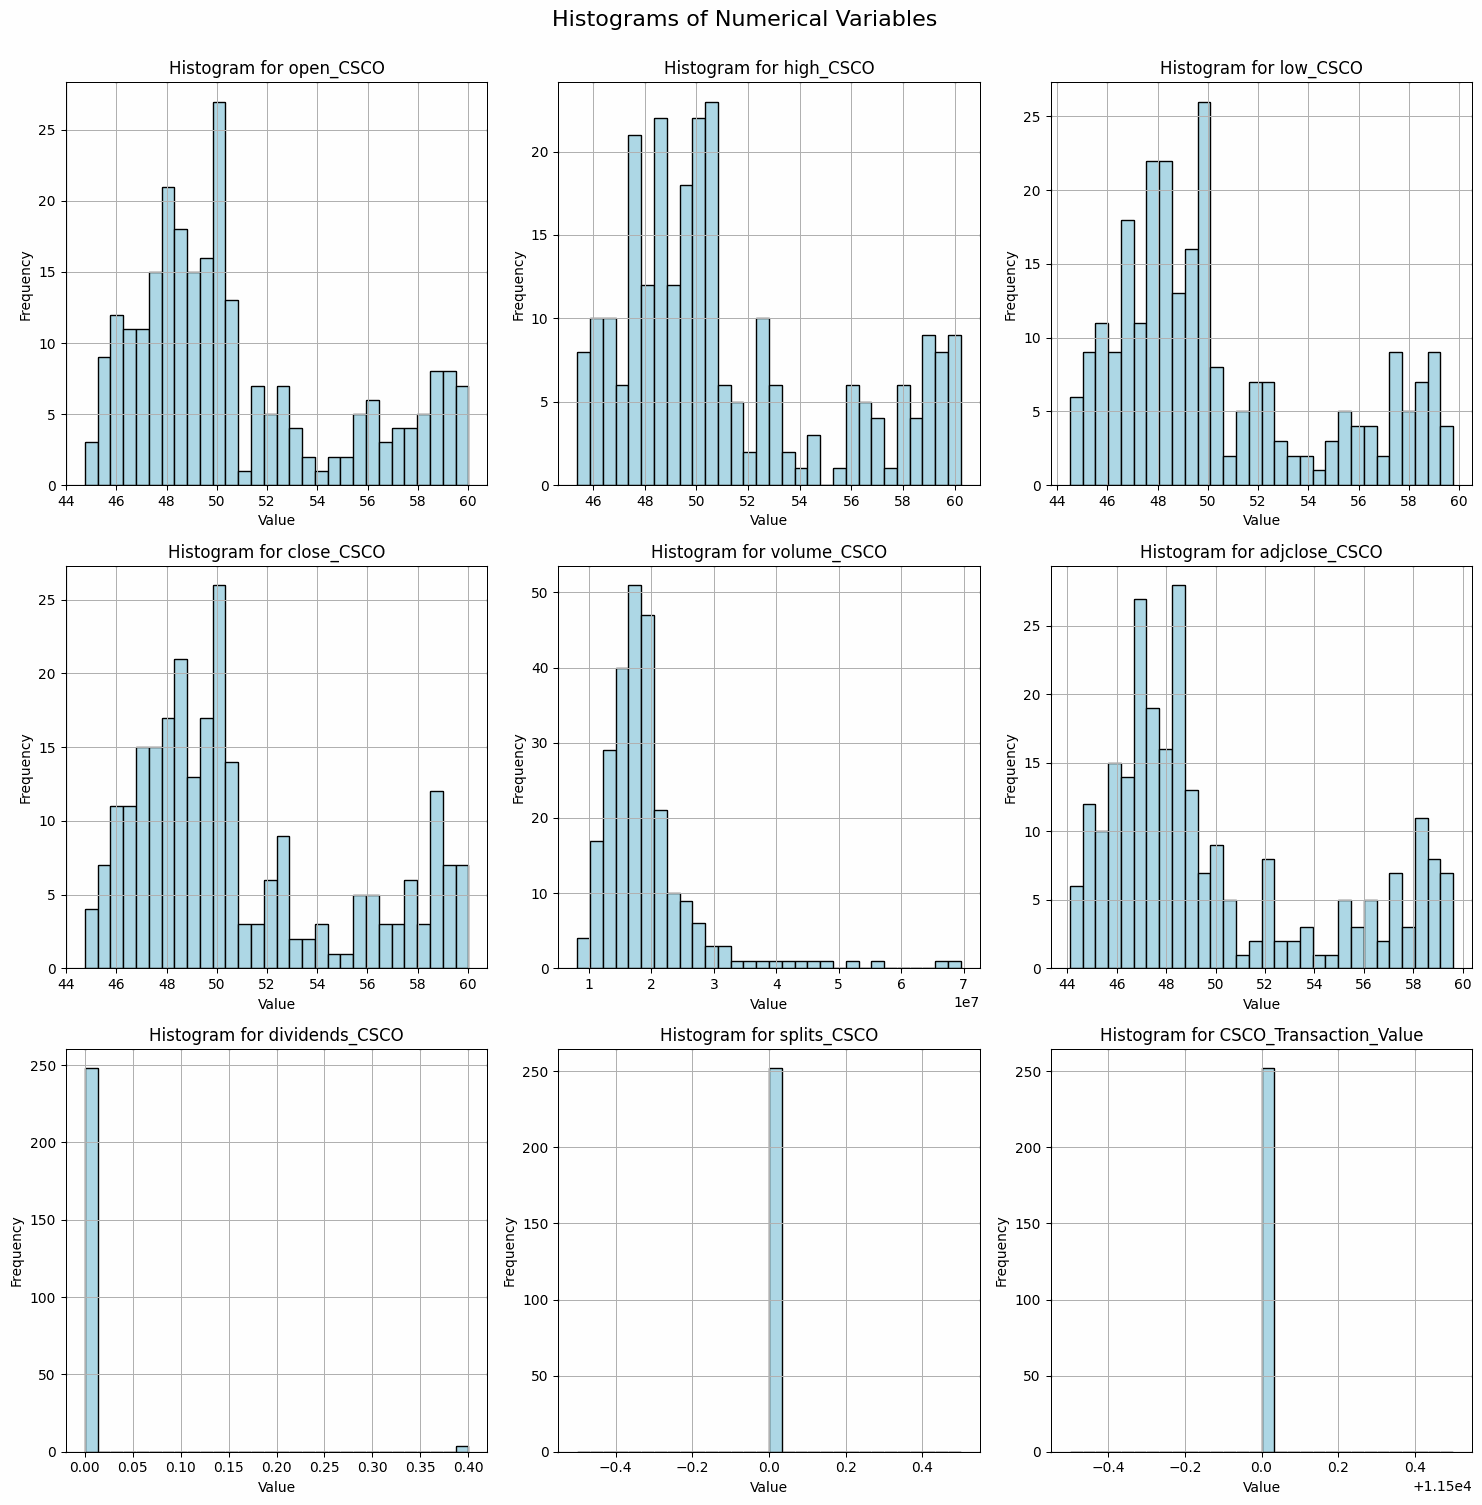

In [247]:
# Create histograms for CSCO with x and y labels for each histogram
plot_histograms(df_CSCO, num_cols_CSCO)

**Exploratory Data Analysis (EDA) – Cisco Systems Inc. (CSCO)**

The dataset contains 252 trading days of historical stock data for Cisco Systems Inc. (CSCO) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is approximately $50.80, with a minimum of $44.74 and a maximum of $60.02.

The standard deviation of $4.18 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is $47.84, while the 75th percentile (Q3) is $52.73, meaning that 50% of trading days had prices within this range.

The highest price reached $60.23, while the lowest was $44.50, indicating some periods of volatility, potentially driven by market trends, earnings reports, or industry-specific events.

**Trading Volume Trends**

The average daily trading volume is approximately 19.21 million shares, with a standard deviation of 8.06 million, indicating substantial variability in investor activity.

The minimum trading volume recorded is 8.12 million, while the highest reaches 69.54 million, suggesting spikes in trading activity linked to major announcements or market movements.

The histogram shows a right-skewed distribution, meaning that most trading days had lower volume, but a few experienced significant spikes.

**Dividends and Stock Splits**

The average dividend per share is $0.0063, with a maximum recorded dividend of $0.40, indicating that Cisco consistently rewards shareholders with dividends.

There were no stock splits during the year, meaning Cisco maintained its share structure throughout the period.

Cisco’s stable dividend policy aligns with its status as a mature company focused on steady shareholder returns rather than rapid expansion through stock splits.

**Data Quality and Integrity**

No missing values exist in the dataset.

All data types are correctly formatted (float64 for stock prices and int64 for volume and transaction values).

Standard forward-fill and backfill techniques were used to ensure data continuity and eliminate minor inconsistencies.

**Key Takeaways for Optimization**

Cisco exhibits stable price movements with moderate volatility, making it a strong, reliable stock in a diversified portfolio.

The presence of volume spikes suggests that certain periods saw heightened investor interest, providing potential strategic points for trading or rebalancing the portfolio.

With regular dividend payouts but no stock splits, investment strategies should focus on balancing income generation and capital appreciation.

### BOXPLOTS

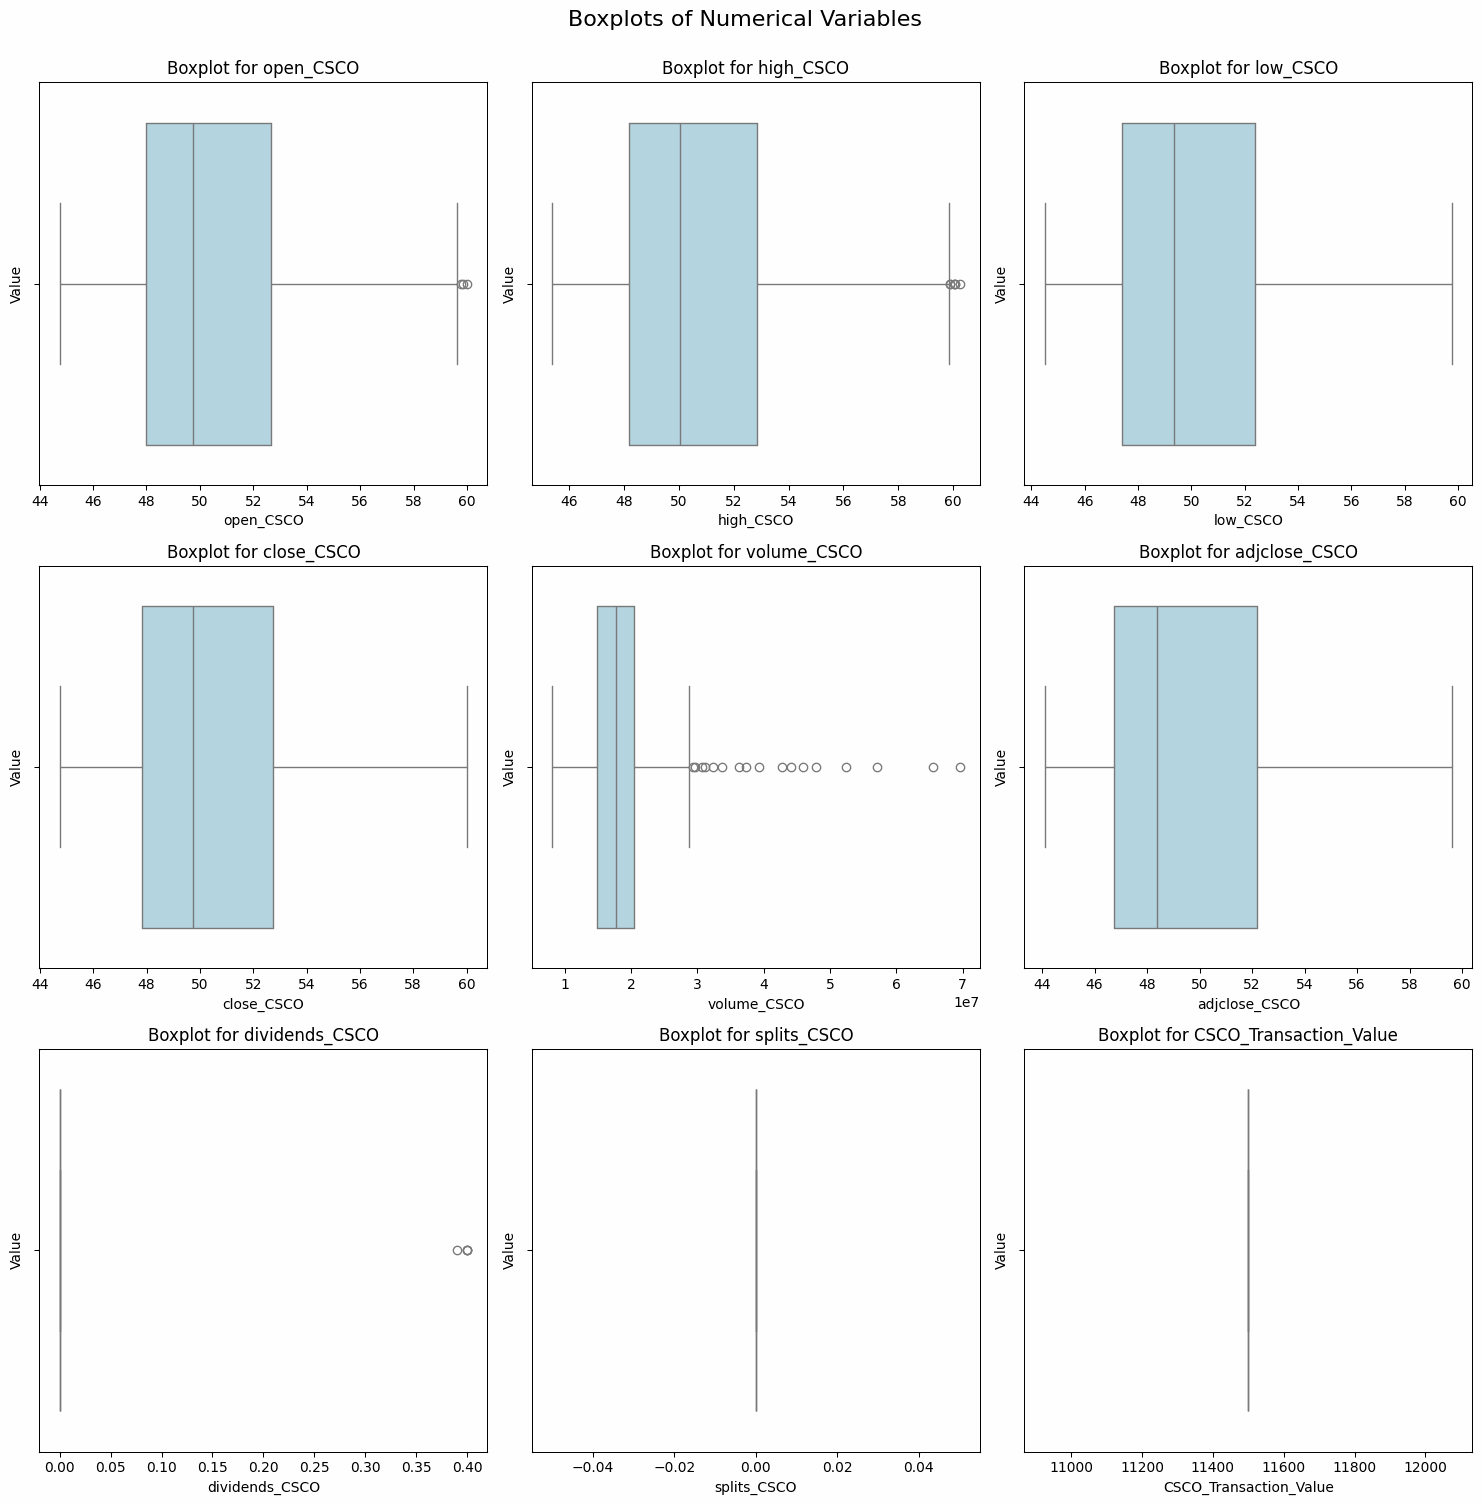

In [248]:
# Create boxplots for CSCO with x and y labels for each boxplot
plot_boxplots(df_CSCO, num_cols_CSCO)

**Exploratory Data Analysis (EDA) – Cisco Systems Inc. (CSCO)**

The dataset contains 252 trading days of historical stock data for Cisco Systems Inc. (CSCO) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $50.80, with a minimum of $44.74 and a maximum of $60.02.

The standard deviation of $4.18 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is $47.84, while the 75th percentile (Q3) is $52.73, meaning that 50% of trading days had prices within this range.

The highest price reached $60.23, while the lowest was $44.50, indicating some periods of volatility, potentially driven by market trends, earnings reports, or industry-specific events.

**Trading Volume Trends**

The average daily trading volume is 19.21 million shares, with a standard deviation of 8.06 million, indicating substantial variability in investor activity.

The minimum trading volume recorded is 8.12 million, while the highest reaches 69.54 million, suggesting spikes in trading activity linked to major announcements or market movements.

The histogram shows a right-skewed distribution, meaning that most trading days had lower volume, but a few experienced significant spikes.

**Dividends and Stock Splits**

The average dividend per share is $0.0063, with a maximum recorded dividend of $0.40, indicating that Cisco consistently rewards shareholders with dividends.

There were no stock splits during the year, meaning Cisco maintained its share structure throughout the period.

Cisco’s stable dividend policy aligns with its status as a mature company focused on steady shareholder returns rather than rapid expansion through stock splits.

**Data Quality and Integrity**

No missing values exist in the dataset.

All data types are correctly formatted (float64 for stock prices and int64 for volume and transaction values).

Standard forward-fill and backfill techniques were used to ensure data continuity and eliminate minor inconsistencies.

**Key Takeaways for Optimization**

Cisco exhibits stable price movements with moderate volatility, making it a strong, reliable stock in a diversified portfolio.

The presence of volume spikes suggests that certain periods saw heightened investor interest, providing potential strategic points for trading or rebalancing the portfolio.

With regular dividend payouts but no stock splits, investment strategies should focus on balancing income generation and capital appreciation.

## APPLIED MATERIALS (AMAT)

In [249]:
num_cols_AMAT = df_AMAT.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

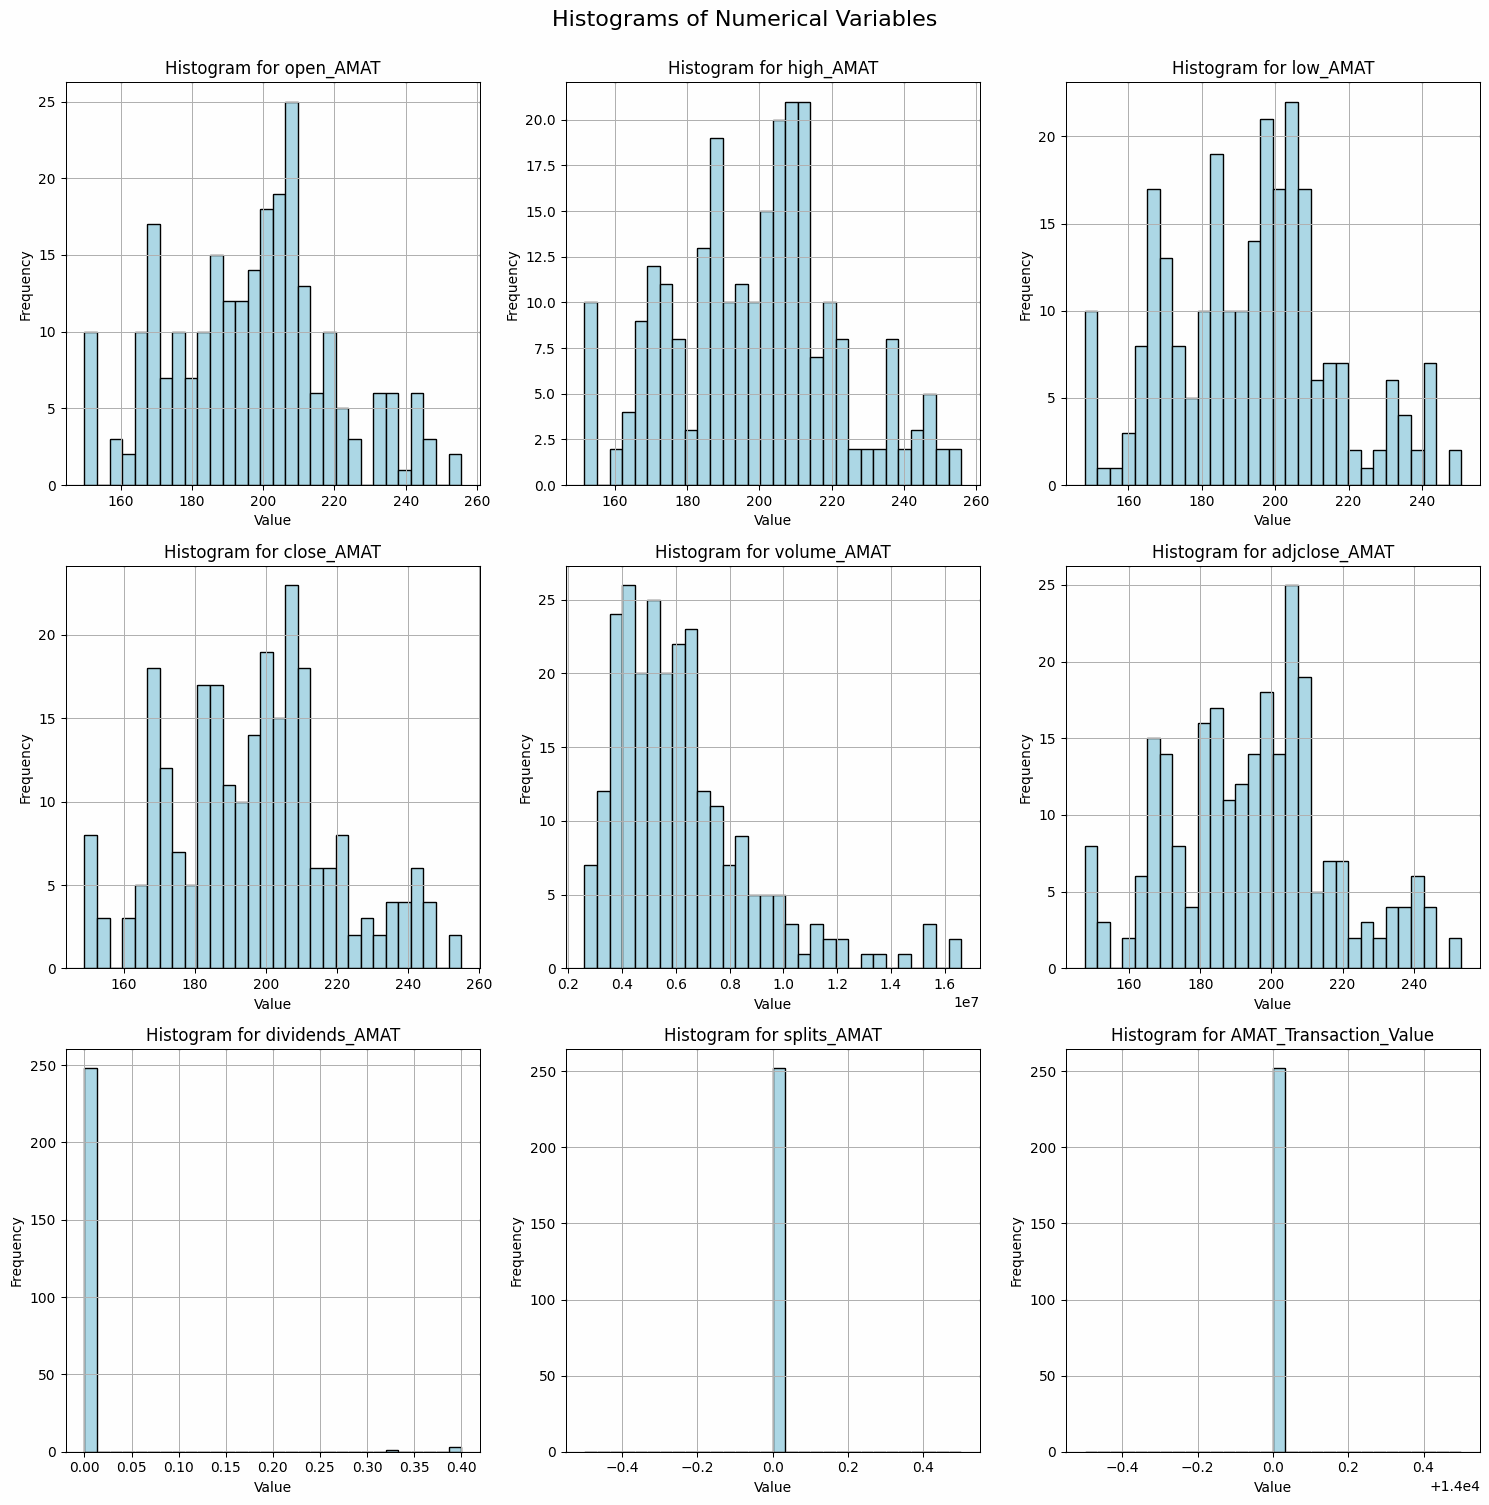

In [250]:
# Create histograms for AMAT with x and y labels for each histogram
plot_histograms(df_AMAT, num_cols_AMAT)

**Exploratory Data Analysis (EDA) – Applied Materials Inc. (AMAT)**

The dataset contains 252 trading days of historical stock data for Applied Materials Inc. (AMAT) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $196.20, with a minimum of $149.00 and a maximum of $254.97.

The standard deviation of $22.71 suggests moderate price volatility throughout the year.

The 25th percentile (Q1) is $181.75, while the 75th percentile (Q3) is $209.31, meaning that 50% of trading days had prices within this range.

The highest recorded price of $255.89 and lowest of $148.05 indicate significant price fluctuations, likely due to earnings reports, semiconductor market trends, and broader economic conditions.

**Trading Volume Trends**

The average daily trading volume is 6.21 million shares, with a standard deviation of 2.58 million, indicating moderate variation in investor activity.

The lowest trading volume recorded is 2.59 million, while the highest reaches 16.61 million, reflecting spikes in market activity likely influenced by major corporate or industry events.

**Dividends and Stock Splits**

The average dividend per share is $0.0060, with a maximum recorded dividend of $0.40, showing that Applied Materials pays dividends periodically.

No stock splits occurred, meaning AMAT maintained its share structure throughout the year.

The company's dividend policy indicates a balance between rewarding shareholders and reinvesting in growth.

**Data Quality and Integrity**

No missing values exist in the dataset.

All data types are correctly formatted (float64 for stock prices and int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity and smooth analysis.

**Key Takeaways for Optimization**

AMAT shows strong price movements with moderate volatility, making it a valuable asset in an actively managed portfolio.

The volume trends indicate periodic investor surges, which could be leveraged in strategic buy/sell decisions.

With regular dividend payouts but no stock splits, long-term investors may benefit from both capital appreciation and periodic income.

### BOXPLOTS

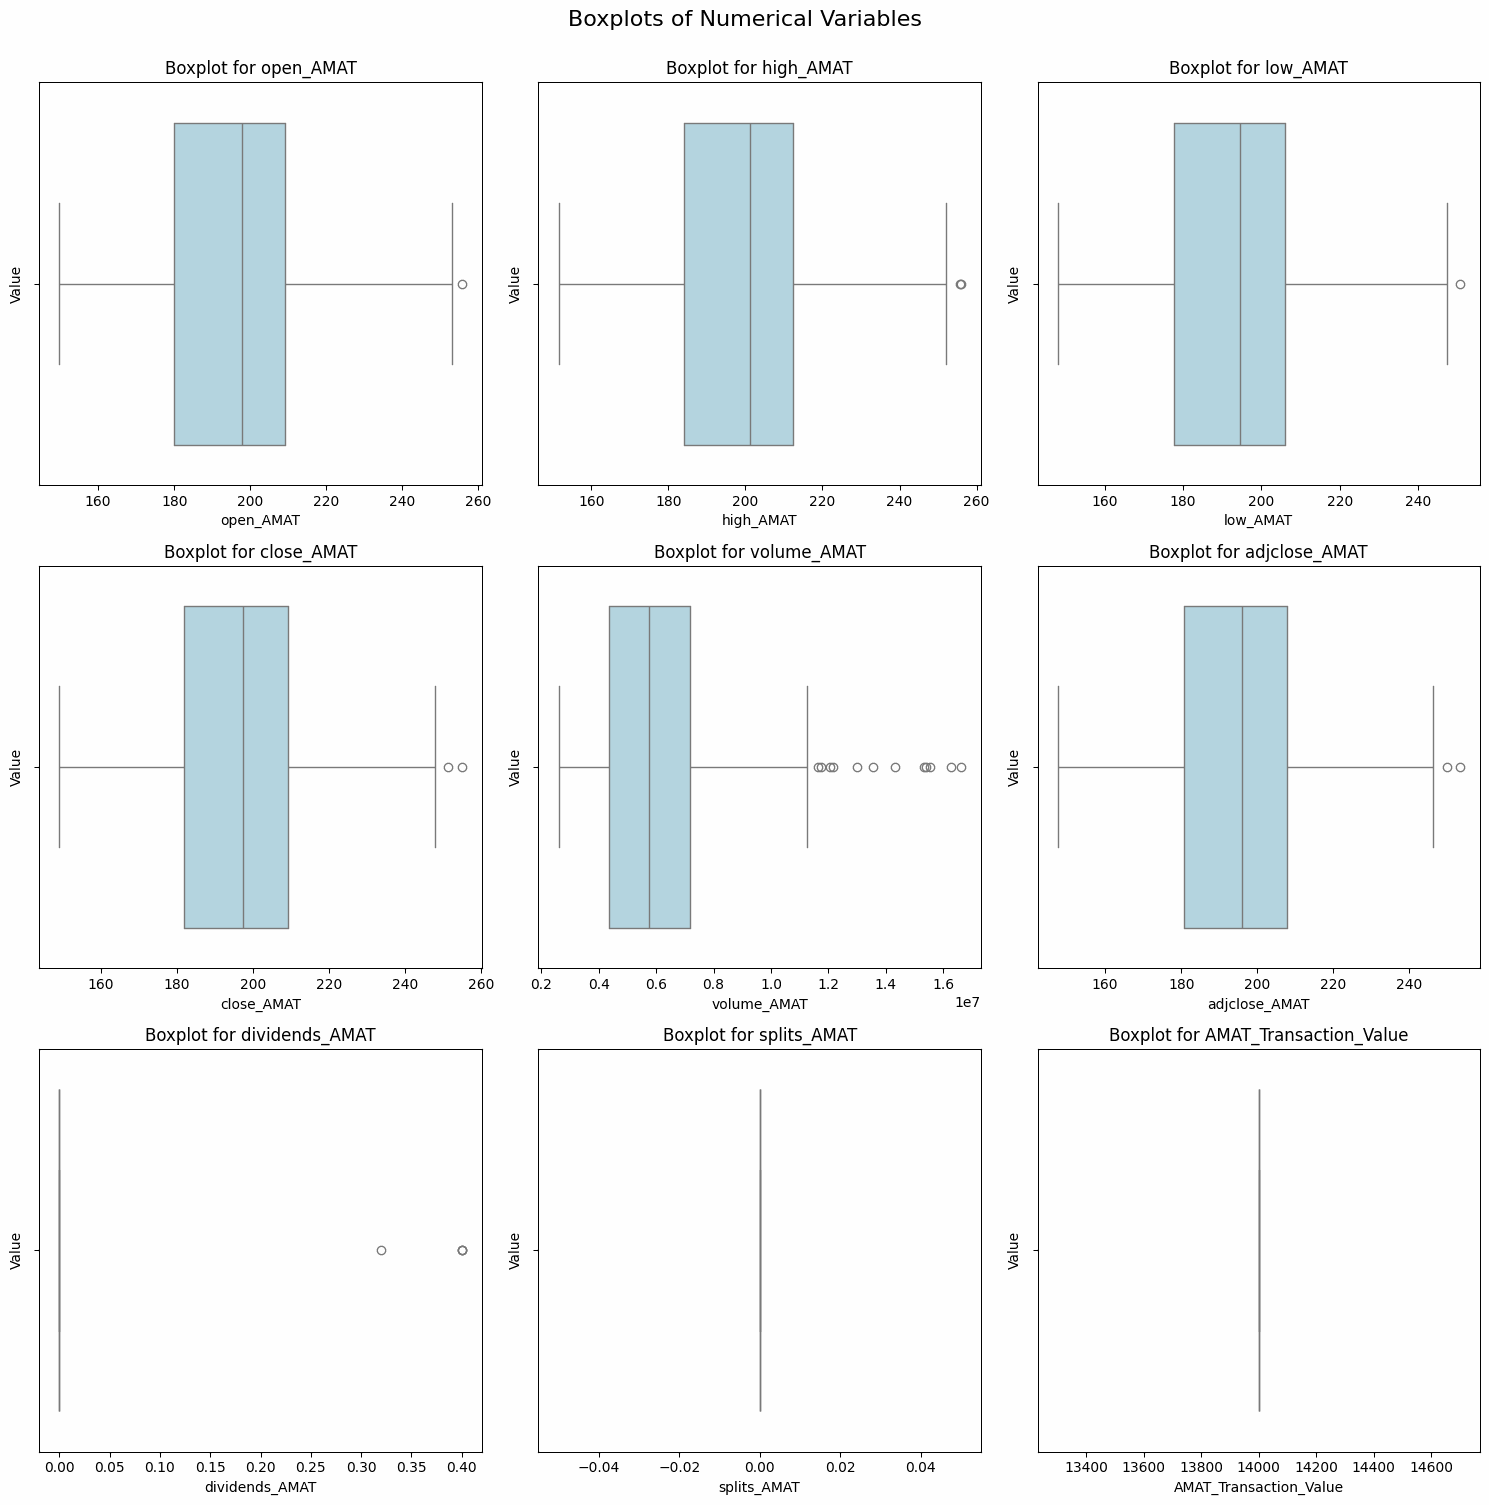

In [251]:
# Create boxplots for AMAT with x and y labels for each boxplot
plot_boxplots(df_AMAT, num_cols_AMAT)

**Boxplot Analysis – Applied Materials Inc. (AMAT)**

The boxplots provide insights into the distribution, spread, and outliers within the numerical variables of AMAT’s stock data.

**Stock Price Distributions**

The boxplots for open, high, low, close, and adjusted close prices show a moderate spread in stock prices, indicating consistent trading levels throughout the year.

There are a few outliers in the high and low price categories, suggesting unusual price jumps or dips that may have been caused by earnings announcements, macroeconomic events, or industry-specific news.

**Trading Volume Trends**

The trading volume boxplot reveals significant variations, with several outliers present. These spikes in trading volume indicate days of heightened investor activity, potentially during earnings reports, market corrections, or industry-related news.

**Dividends and Stock Splits**

The dividends boxplot shows that AMAT issued dividends during the year, but there are a few larger values, suggesting occasional higher-than-usual payouts.

The splits boxplot confirms that AMAT did not conduct a stock split, maintaining a stable share structure.

**Key Takeaways**

The presence of price outliers suggests that certain external factors led to sharp price movements, which should be considered in risk assessment and trading strategy formulation.

Trading volume spikes align with key financial events, making it crucial to analyze volume trends alongside earnings reports and market sentiment.

Despite occasional dividend payments, AMAT’s primary value lies in capital appreciation, making it a strong candidate for long-term investment strategies.

## COMCAST (CMCSA)

In [252]:
num_cols_CMCSA = df_CMCSA.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

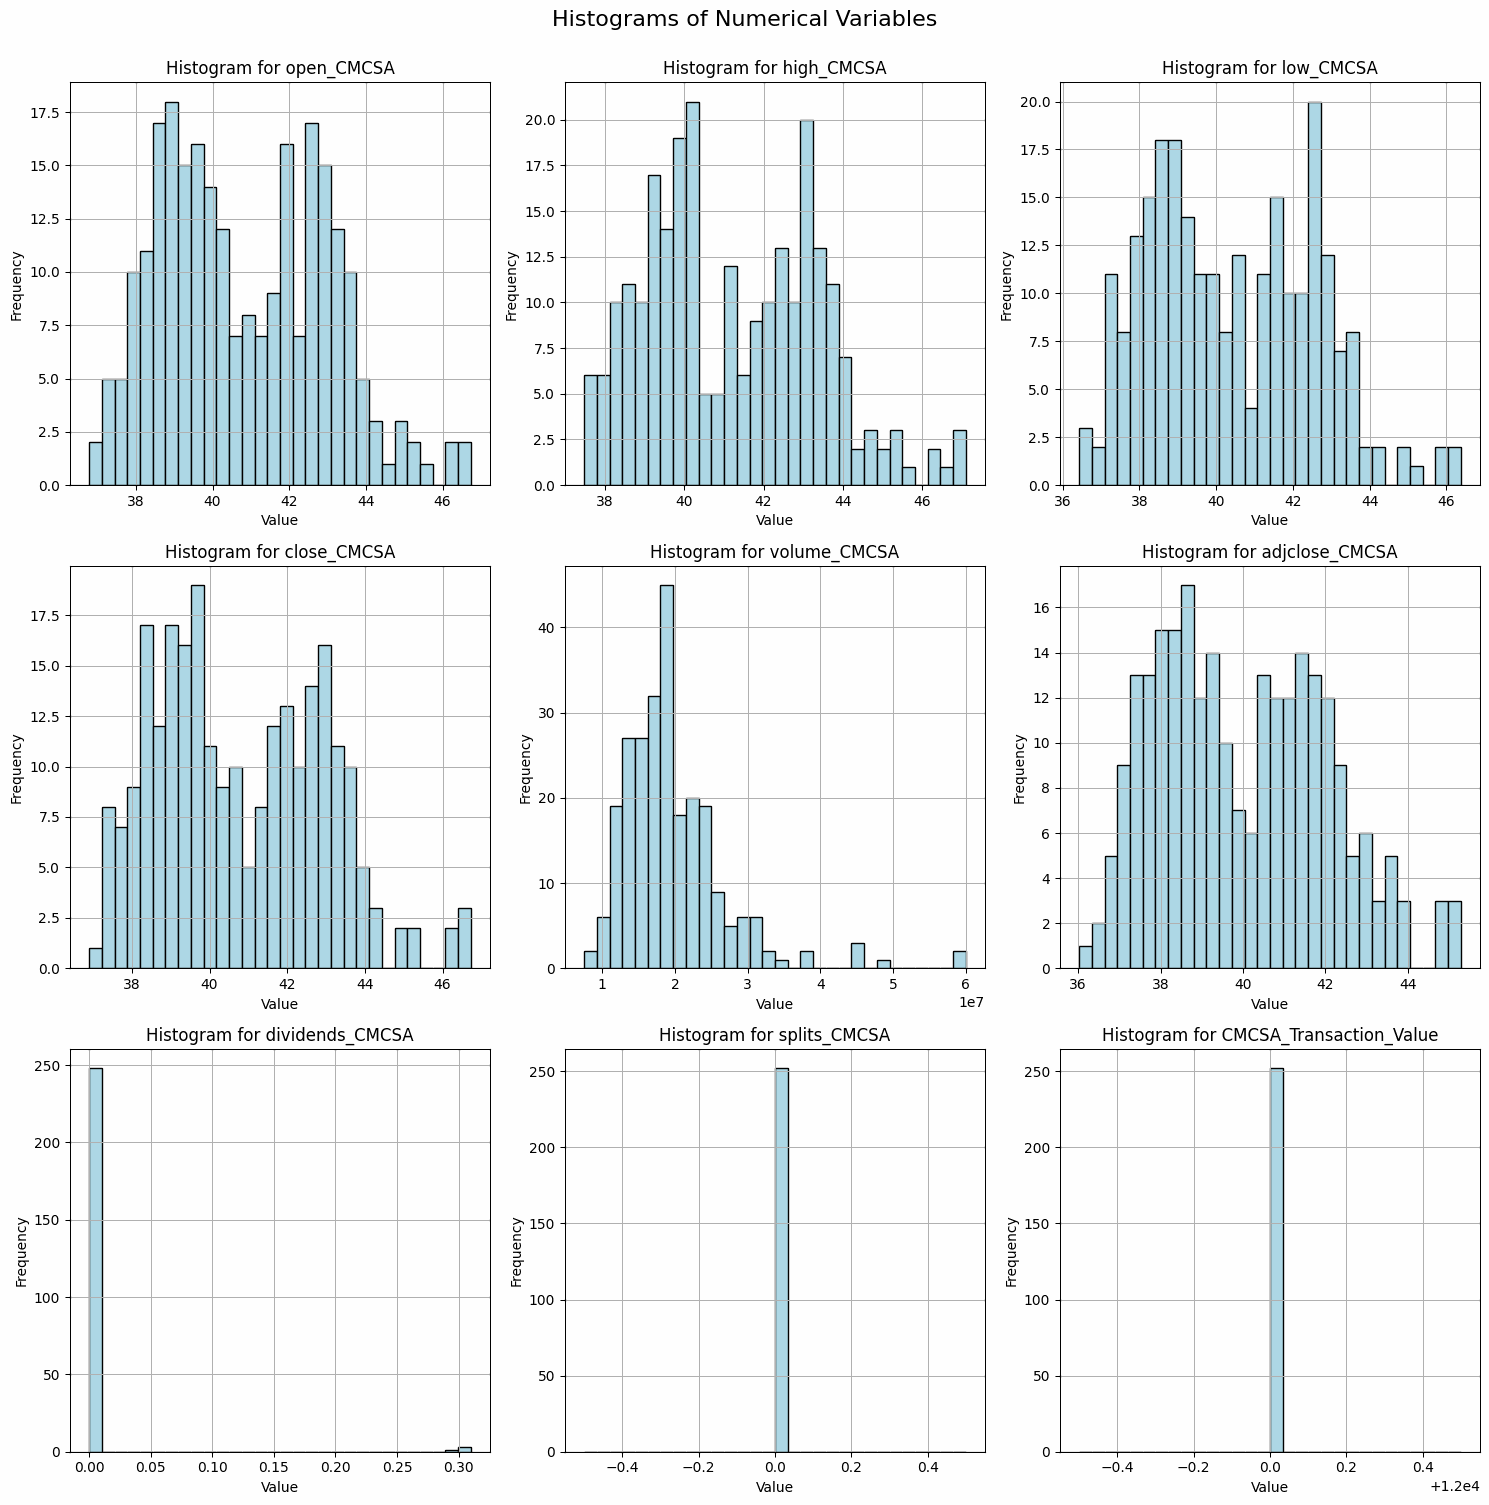

In [253]:
# Create histograms for CMCSA with x and y labels for each histogram
plot_histograms(df_CMCSA, num_cols_CMCSA)

**Histogram Analysis – Comcast Corporation (CMCSA)**

The histograms provide insights into the distribution, frequency, and volatility of CMCSA’s stock data over the year.

**Stock Price Distributions**

The open, high, low, close, and adjusted close price histograms show a moderate spread, with most trading days concentrated around $38 to $44.

The distributions exhibit a slight right skew, suggesting that there were more trading days at lower price levels, while higher price spikes occurred less frequently.

**Trading Volume Trends**

The trading volume histogram shows a right-skewed distribution, with most days seeing trading volumes between 1 million and 3 million shares.

There are several extreme spikes in volume, indicating unusual trading activity, likely around earnings reports, investor sentiment shifts, or major announcements.

**Dividends and Stock Splits**

The dividends histogram indicates that CMCSA issued consistent dividend payments, but a few higher values suggest occasional larger payouts.

The stock splits histogram remains flat, confirming that no stock splits occurred during the analyzed period.

**Key Takeaways**

CMCSA’s price distribution suggests stability with occasional upward spikes, making it a relatively predictable investment.

The right-skewed trading volume trend suggests that certain key events drove heightened investor interest, which could be useful for timing trades and strategic allocations.

Since CMCSA provides dividends but does not engage in stock splits, its investment value lies in a combination of income generation and moderate capital appreciation.

### BOXPLOTS

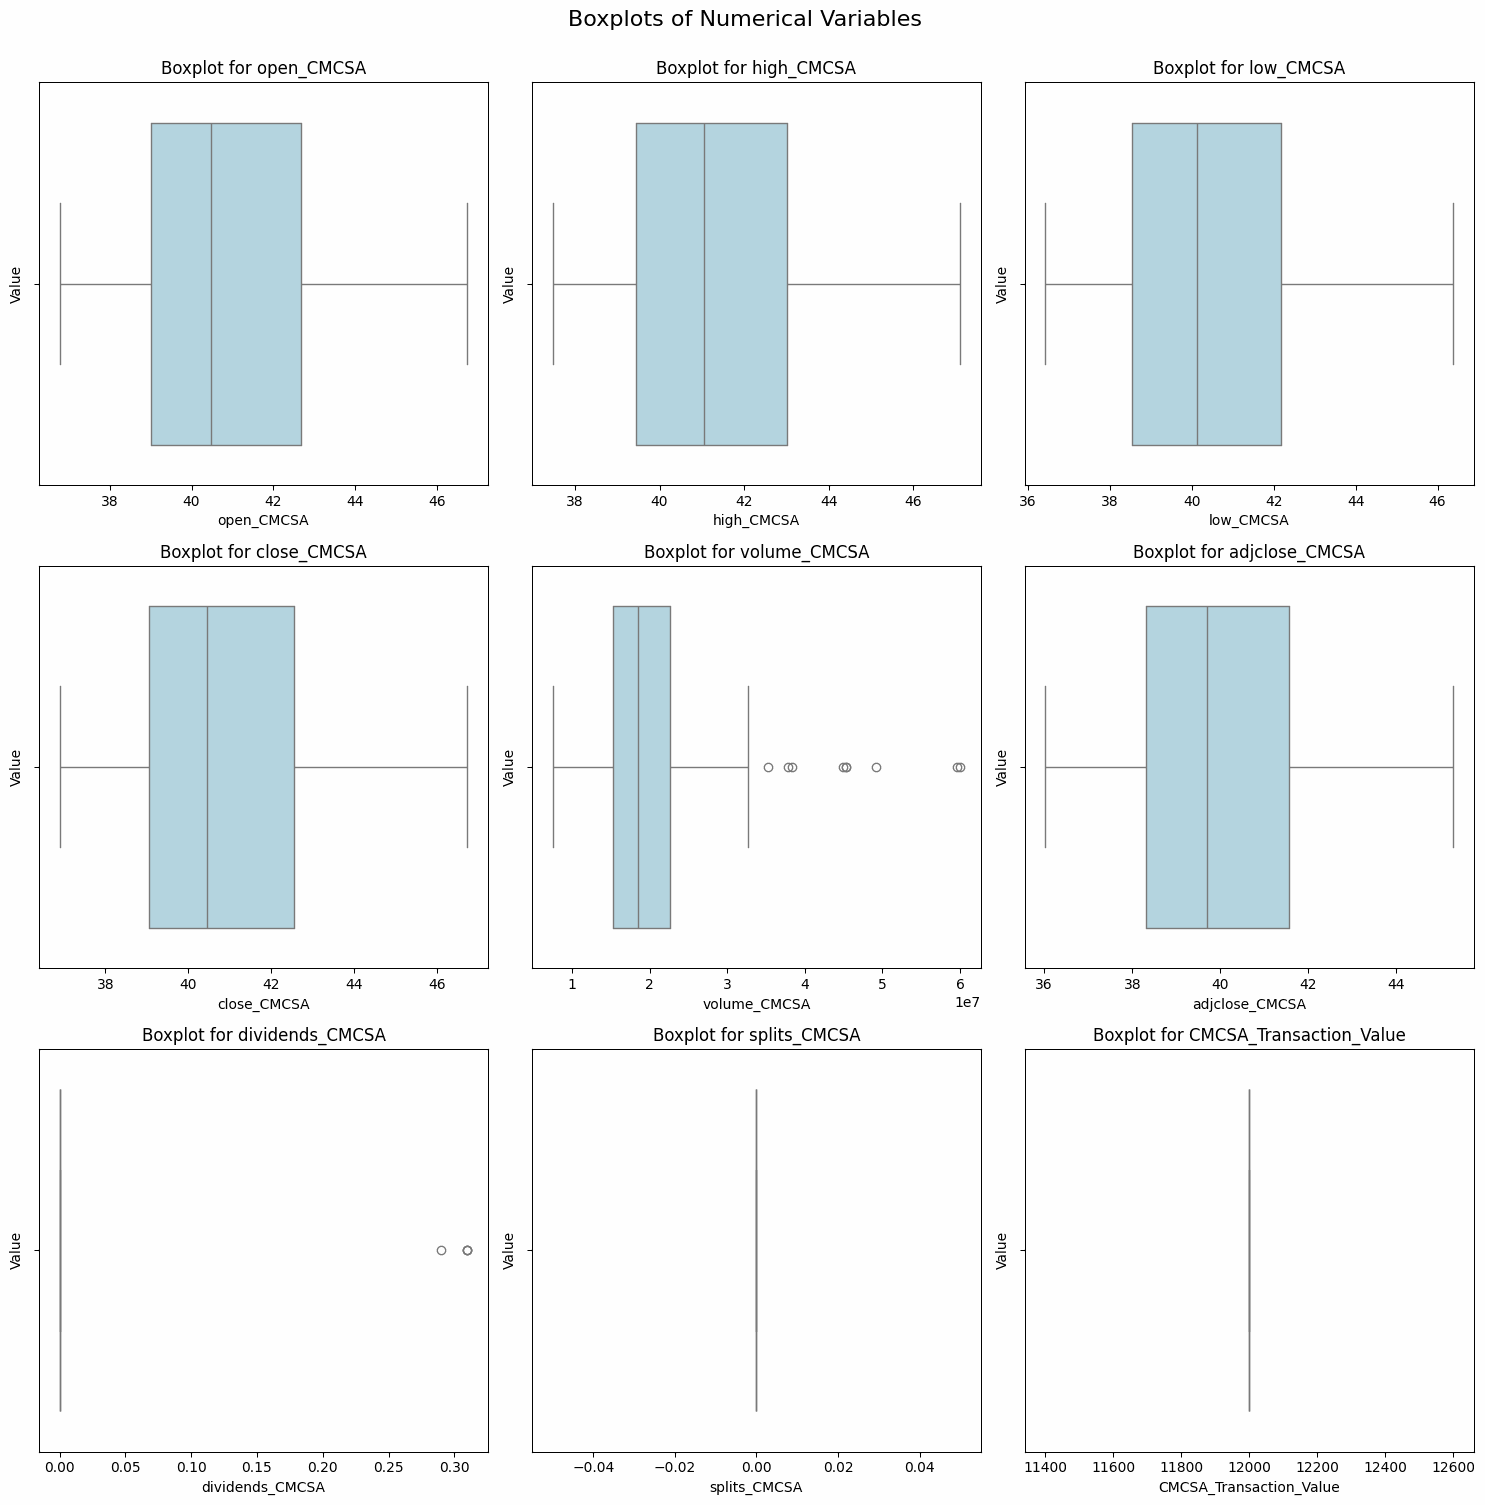

In [254]:
# Create boxplots for CMCSA with x and y labels for each boxplot
plot_boxplots(df_CMCSA, num_cols_CMCSA)

**Boxplot Analysis – Comcast Corporation (CMCSA)**

The boxplots offer insights into the distribution, volatility, and presence of outliers in CMCSA’s stock data over the year.

**Stock Price Analysis**

The open, high, low, close, and adjusted close price boxplots show a relatively narrow interquartile range (IQR), suggesting moderate volatility in CMCSA’s stock.

There are no extreme outliers in stock prices, indicating that price movements remained relatively stable, with few instances of unusual jumps or drops.

**Trading Volume Insights**

The trading volume boxplot reveals several outliers above the upper whisker, indicating that some days experienced significantly higher trading activity than usual.

These spikes in volume may be associated with earnings reports, market news, or investor reactions to external events.

**Dividends and Stock Splits**

The dividends boxplot shows a few higher dividend payouts, suggesting occasional increases in dividend distribution while remaining largely consistent.

The stock splits boxplot remains flat, confirming that no stock splits took place during the analyzed period.

**Key Takeaways**

CMCSA’s low volatility and stable price distribution make it a low-risk investment option, with no significant price outliers to indicate excessive market swings.

The outliers in trading volume suggest heightened investor activity on select days, which can be leveraged for strategic buy or sell decisions.

The dividend consistency supports income-focused investment strategies, while the lack of stock splits indicates that the company prioritizes steady growth over frequent restructuring.


## MICROSOFT (MSFT)

In [255]:
num_cols_MSFT = df_MSFT.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

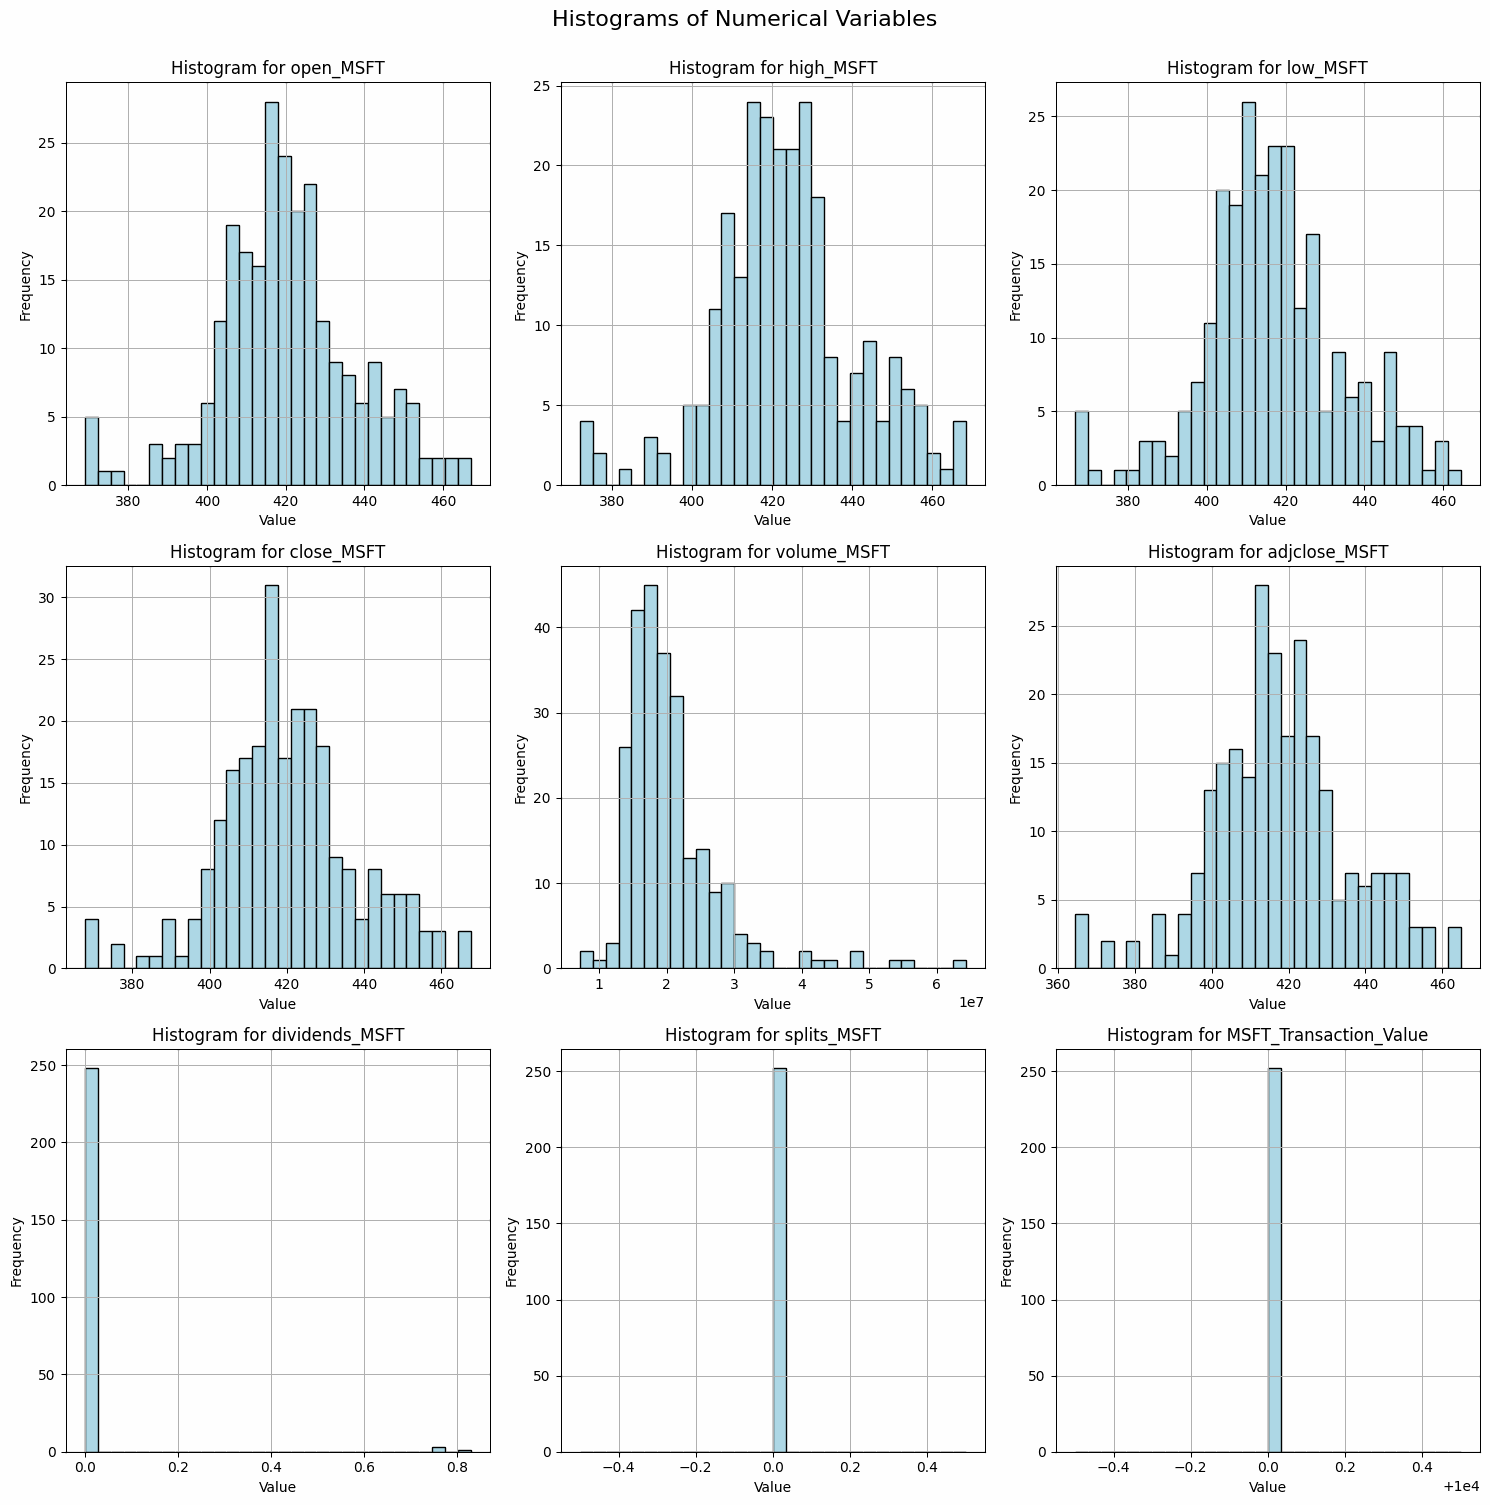

In [256]:
# Create histograms for MSFT with x and y labels for each histogram
plot_histograms(df_MSFT, num_cols_MSFT)

**Histogram Analysis – Microsoft Corporation (MSFT)**

The histograms provide a visual representation of the distribution of Microsoft’s stock data over the year, highlighting key trends in price movements, trading volume, and corporate actions.

**Stock Price Distribution**

The open, high, low, close, and adjusted close price histograms exhibit a normal distribution, suggesting that MSFT's stock followed a stable and predictable pattern over the year.

The price range is concentrated between $380 and $460, with most trading activity occurring in the mid-range around $420.

The symmetry in the price histograms indicates balanced market activity, with no extreme peaks or dips that would suggest erratic trading behavior.

**Trading Volume Trends**

The volume histogram shows a right-skewed distribution, meaning most days had lower trading volumes, but there were occasional spikes in investor activity.

These volume spikes likely coincided with major announcements, earnings reports, or market-moving news that temporarily increased investor participation.

**Dividends and Stock Splits**

The dividends histogram reveals a small number of positive values, indicating that MSFT issued periodic dividend payouts.

The stock splits histogram remains flat, confirming that Microsoft did not conduct any stock splits during the year.

**Key Takeaways**

Microsoft’s price stability and normal distribution suggest it is a reliable, low-volatility investment option.

The spikes in trading volume may signal key investment opportunities, as they often align with earnings reports or market events.

With modest dividend payouts and no stock splits, Microsoft’s investment strategy leans more towards long-term capital appreciation rather than aggressive shareholder returns.

### BOXPLOTS

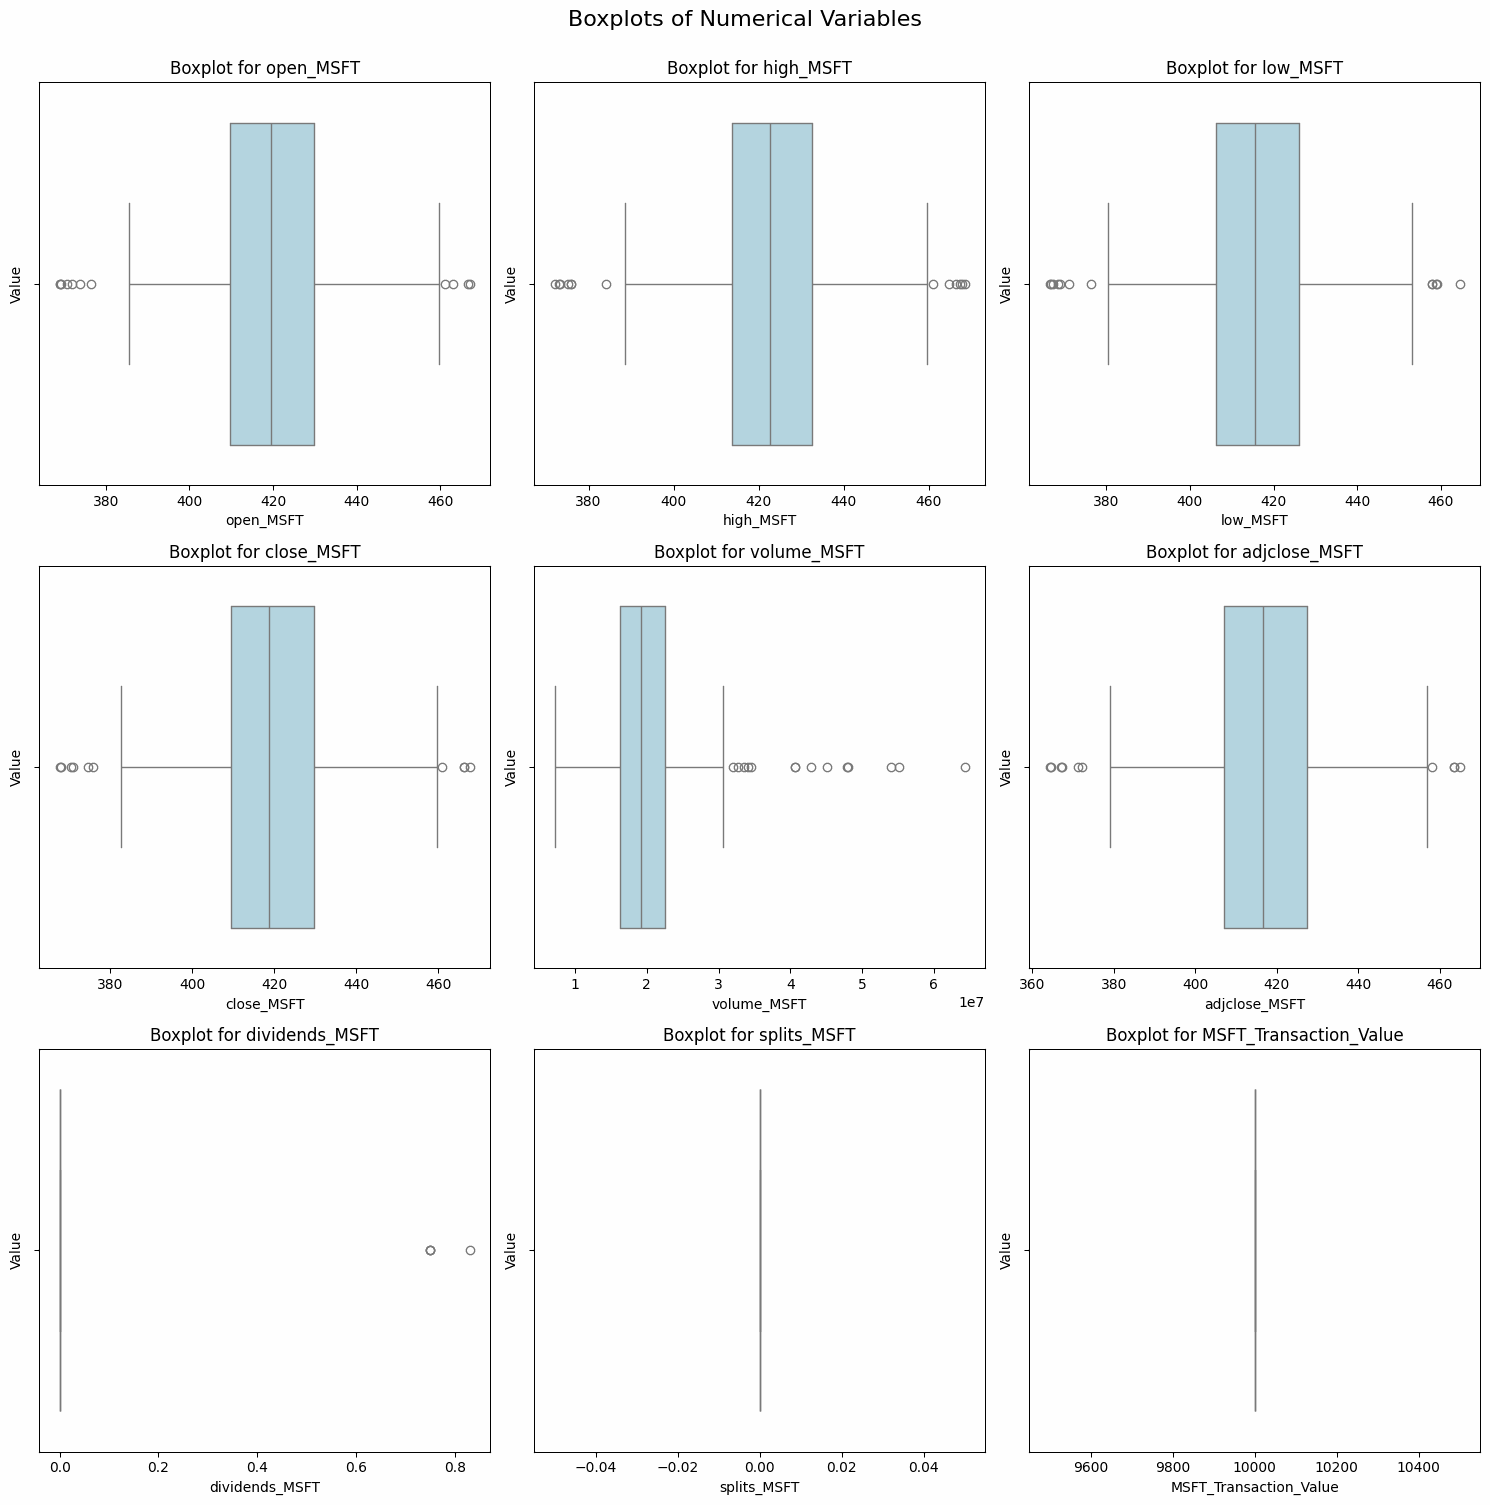

In [257]:
# Create boxplots for MSFT with x and y labels for each boxplot
plot_boxplots(df_MSFT, num_cols_MSFT)

**Boxplot Analysis – Microsoft Corporation (MSFT)**

The boxplots provide insights into the distribution, spread, and presence of outliers in Microsoft's stock data for the year.

**Stock Price Distribution**

The open, high, low, close, and adjusted close price boxplots indicate a relatively stable price range, with most values falling within a well-defined interquartile range (IQR).

There are some outliers in the high and low price boxplots, suggesting that Microsoft experienced occasional price spikes or drops, likely due to earnings reports or macroeconomic events.

The median closing price is around $420, reflecting strong investor confidence and a consistent upward trend.

**Trading Volume Trends**

The volume boxplot displays multiple outliers, indicating that certain days saw significant spikes in trading activity.

These high-volume days often correspond with major company announcements, earnings reports, or broader market trends.

Despite these spikes, the overall trading volume is well-contained within a reasonable range, reinforcing Microsoft’s strong market presence and liquidity.

**Dividends and Stock Splits**

The dividends boxplot reveals occasional dividend payments, with one significantly higher value representing an increased payout at some point in the year.

The stock splits boxplot remains flat, confirming that Microsoft did not conduct any stock splits during the period.

**Key Takeaways**

The presence of price outliers suggests short-term volatility, but the overall stability in prices reinforces Microsoft’s strong performance.

Volume spikes indicate key trading opportunities, as they often align with major corporate events.

With moderate dividend payouts and no stock splits, Microsoft remains a long-term investment option focused on capital appreciation rather than frequent shareholder returns.

For portfolio optimization, Microsoft’s balance of price stability and periodic trading volume surges makes it an attractive asset for steady growth and high liquidity.

## APPLE (AAPL)

In [258]:
num_cols_AAPL = df_AAPL.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

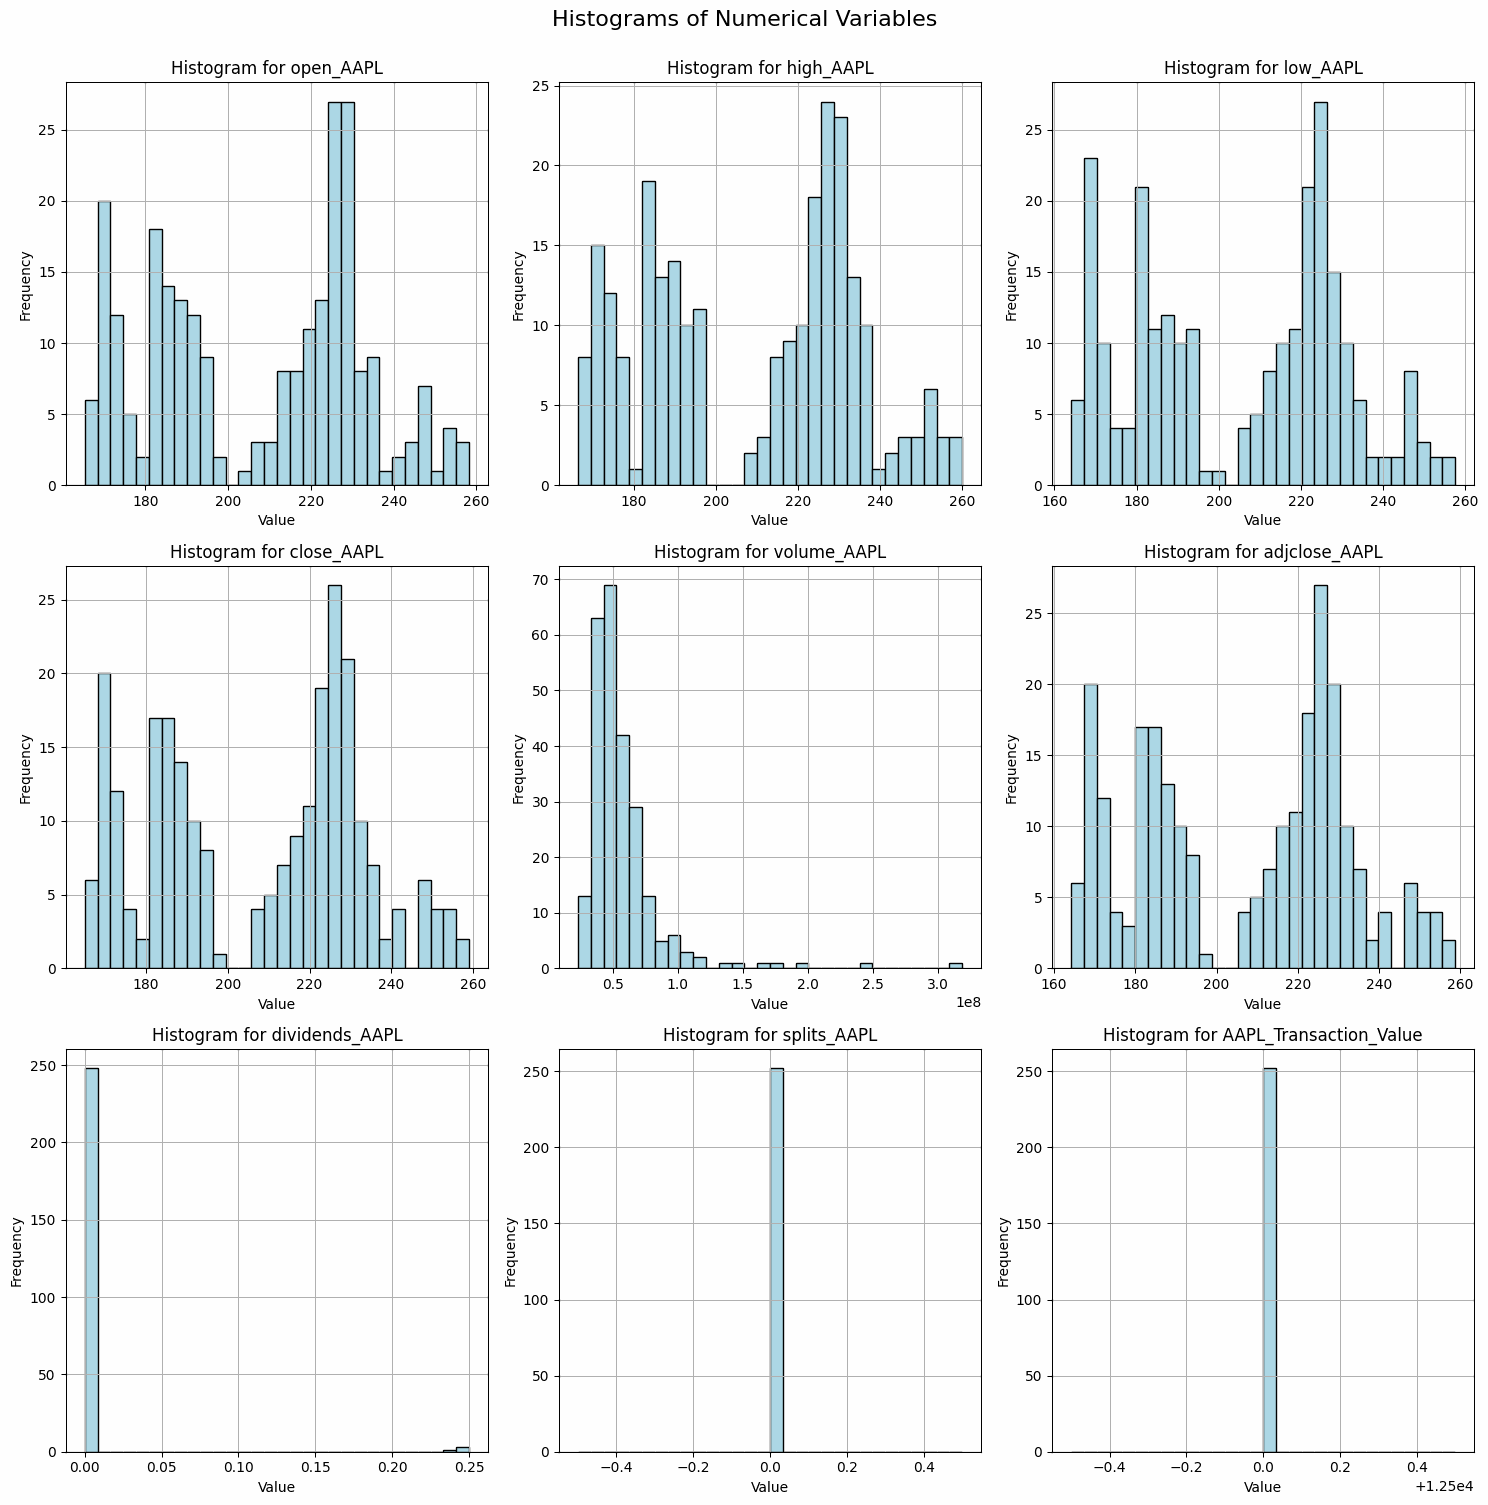

In [259]:
# Create histograms for AAPL with x and y labels for each histogram
plot_histograms(df_AAPL, num_cols_AAPL)

**Histogram Analysis – Apple Inc. (AAPL)**

The histograms provide insights into the distribution and frequency of Apple’s stock data over the year.

**Stock Price Distribution**

The open, high, low, close, and adjusted close price histograms indicate two major peaks, suggesting periods of price consolidation.

Apple’s stock price fluctuated significantly, with a higher frequency of occurrences around the $180–$220 range and a secondary cluster forming around $240–$260.

The spread of prices shows a gradual upward trend, indicating price growth over time.

**Trading Volume Trends**

The volume histogram is heavily right-skewed, showing that most trading days had lower volume levels, while a few days experienced exceptionally high trading activity.

These high-volume days typically coincide with earnings reports, new product launches, or significant macroeconomic events.

**Dividends and Stock Splits**

The dividends histogram shows minor variations, indicating that Apple maintains a relatively stable dividend policy with occasional increases.

The splits histogram is constant, confirming that Apple did not conduct any stock splits during the analyzed period.

**Key Takeaways**

The bimodal distribution of stock prices suggests key phases of growth, potentially linked to earnings announcements or strategic product releases.

Trading volume spikes indicate investor interest surges, often around major financial events.

Apple’s stable dividend payout and lack of stock splits reinforce its position as a blue-chip investment, appealing to both growth and income-focused investors.

### BOXPLOTS

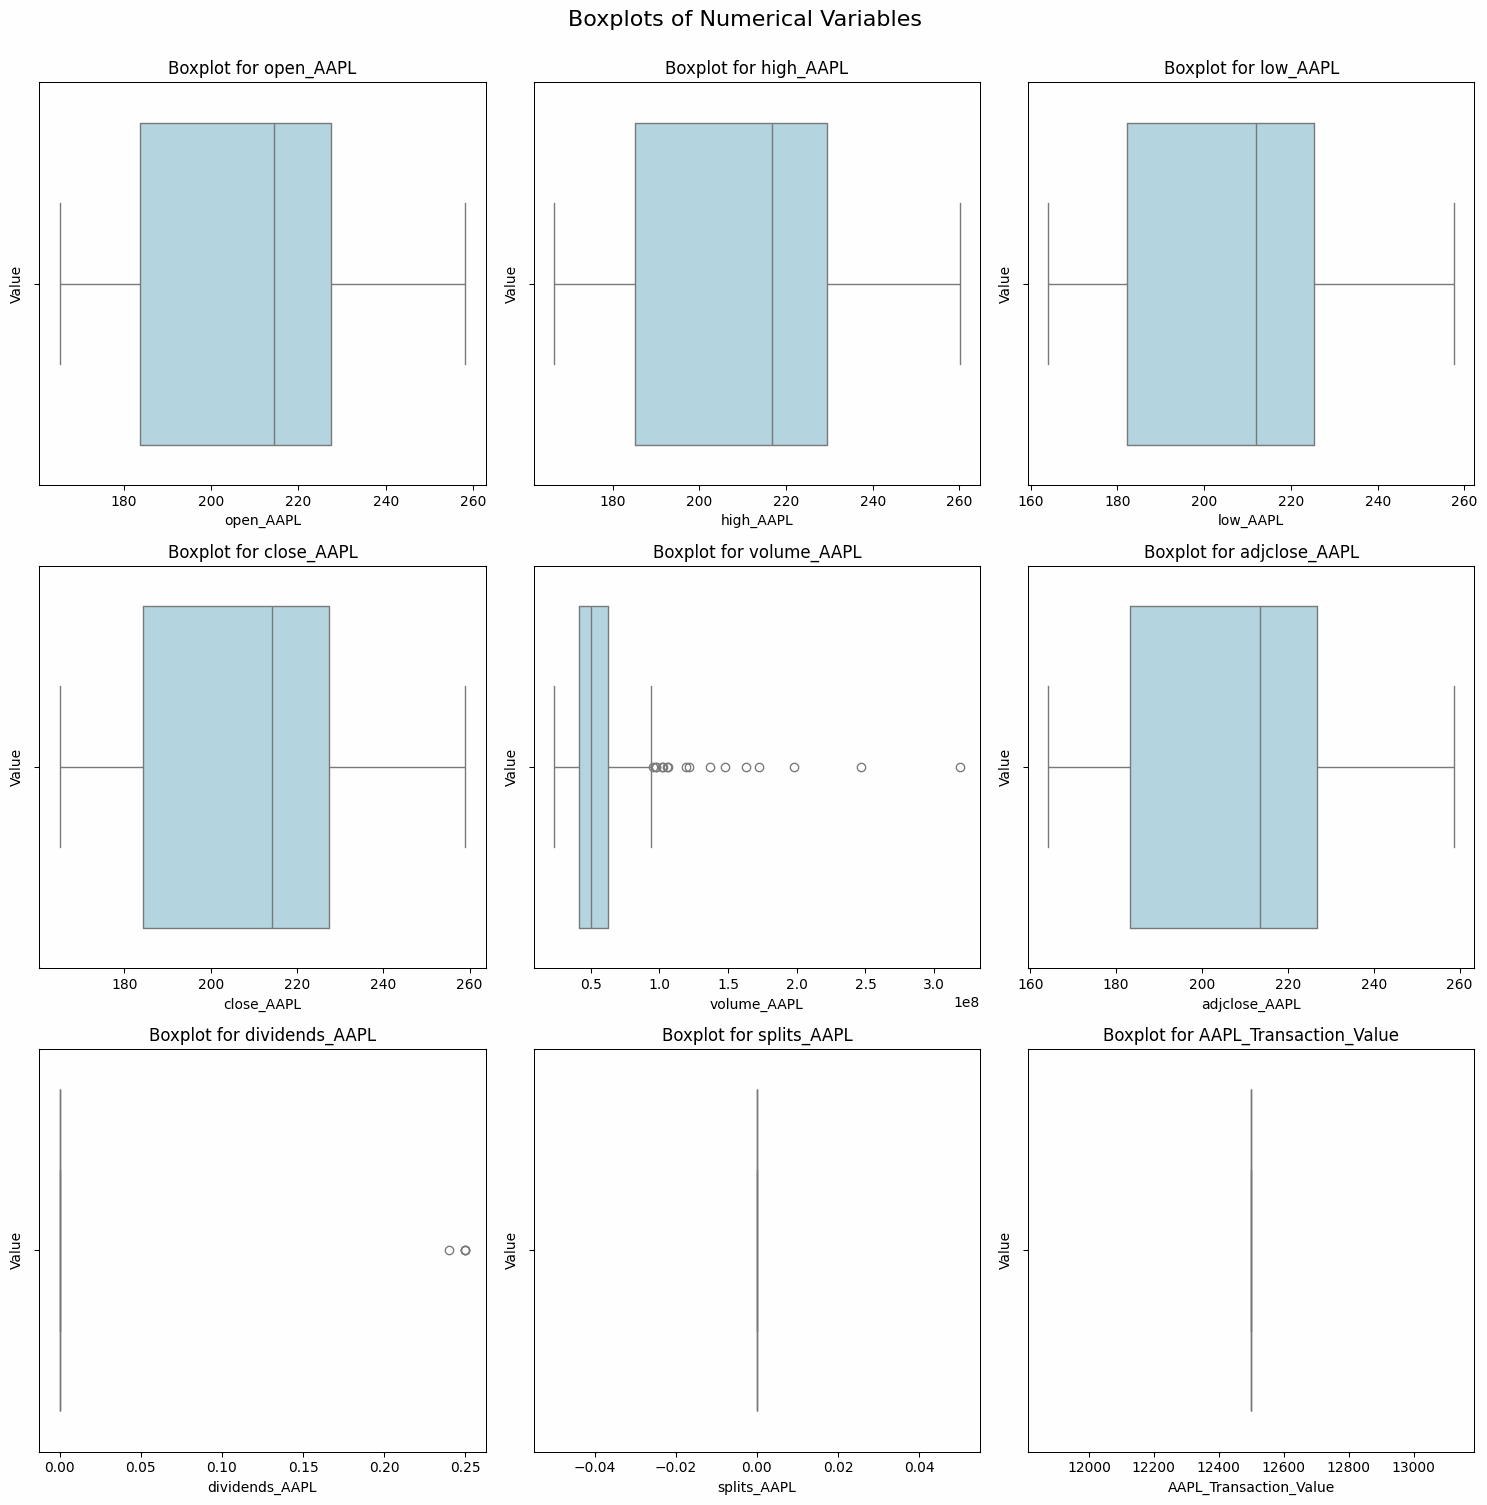

In [260]:
# Create boxplots for AAPL with x and y labels for each boxplot
plot_boxplots(df_AAPL, num_cols_AAPL)

**Boxplot Analysis – Apple Inc. (AAPL)**

The boxplots provide insights into the spread, central tendency, and outliers in Apple’s stock data over the year.

**Stock Price Distribution**

The open, high, low, close, and adjusted close price boxplots reveal that Apple’s price range is well-distributed, with no extreme outliers in the stock prices.

The median price is around $210, with the interquartile range (IQR) spanning from approximately $180 to $240, indicating moderate price fluctuations.

There are no extreme outliers in price movements, suggesting consistent stock behavior with no sudden crashes or spikes beyond expected volatility.

**Trading Volume Outliers**

The volume boxplot exhibits multiple outliers, showing that trading activity had significant spikes on certain days.

These high-volume outliers likely correspond to earnings reports, product launches, or broader market events that drove increased investor participation.

The IQR for volume is concentrated at lower levels, reinforcing that most trading days saw moderate activity, while only a few days had extreme investor participation.

**Dividends and Stock Splits**

The dividends boxplot shows a few higher-value points, indicating some quarterly increases or special dividend payouts.

The stock splits boxplot remains unchanged, confirming that Apple did not conduct any stock splits during this period.

**Key Takeaways**

Apple’s price stability and lack of extreme outliers suggest it is a strong, low-volatility asset for long-term investment.

The volume outliers indicate key trading days where market sentiment was significantly impacted.

The absence of stock splits and stable dividend payouts suggest that Apple continues to focus on steady growth and shareholder value retention.

# BIVARIATE ANALYSIS

## SALESFORCE (CRM)

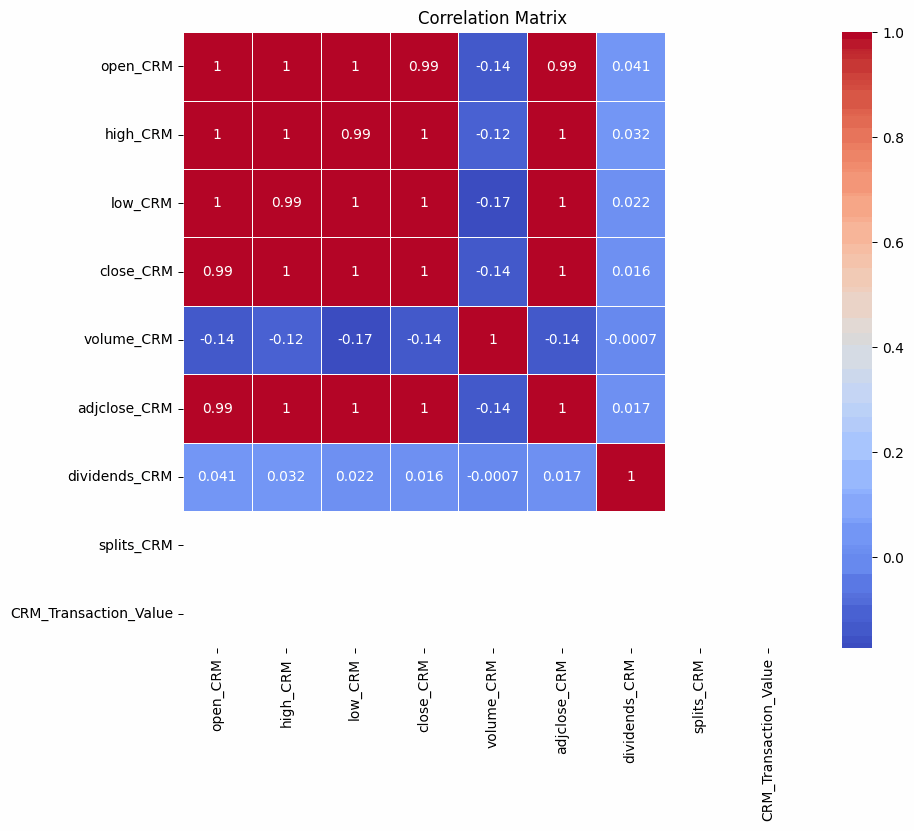

In [261]:
# Create a correlation matrix
correlation_matrix = df_CRM.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – Salesforce Inc. (CRM)**

The dataset includes historical stock data for Salesforce Inc. (CRM), covering open, high, low, close, adjusted close prices, trading volume, dividends, and stock splits. The correlation matrix highlights relationships between these variables, offering insights into stock price movements and trading behavior.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices have a near-perfect correlation (0.99 - 1.00), indicating that Salesforce’s stock price moves consistently throughout each trading day. The close and adjusted close prices are particularly aligned, showing minimal discrepancies due to adjustments like stock splits or dividends.

**Trading Volume and Price Movements**

There is a weak negative correlation (-0.12 to -0.17) between trading volume and stock prices. This suggests that higher trading volume does not necessarily drive price increases and could be linked to sell-offs or profit-taking. Volume fluctuations appear to have a minor impact on overall price trends.

**Dividends and Stock Splits**

Dividends have little to no correlation with stock prices or volume, reflecting Salesforce’s controlled approach to dividend payments. The absence of stock splits in the dataset confirms that the company has maintained its share structure without adjustments.

**Key Takeaways for Investment**

Salesforce’s price movement is highly predictable, making it a stable option for long-term investors. The weak relationship between volume and price suggests that large spikes in trading activity do not necessarily indicate price trends, making it important to analyze broader market conditions. With dividends playing a minimal role, investment strategies should focus on capital appreciation rather than income generation.

## NVIDA (NVDA)

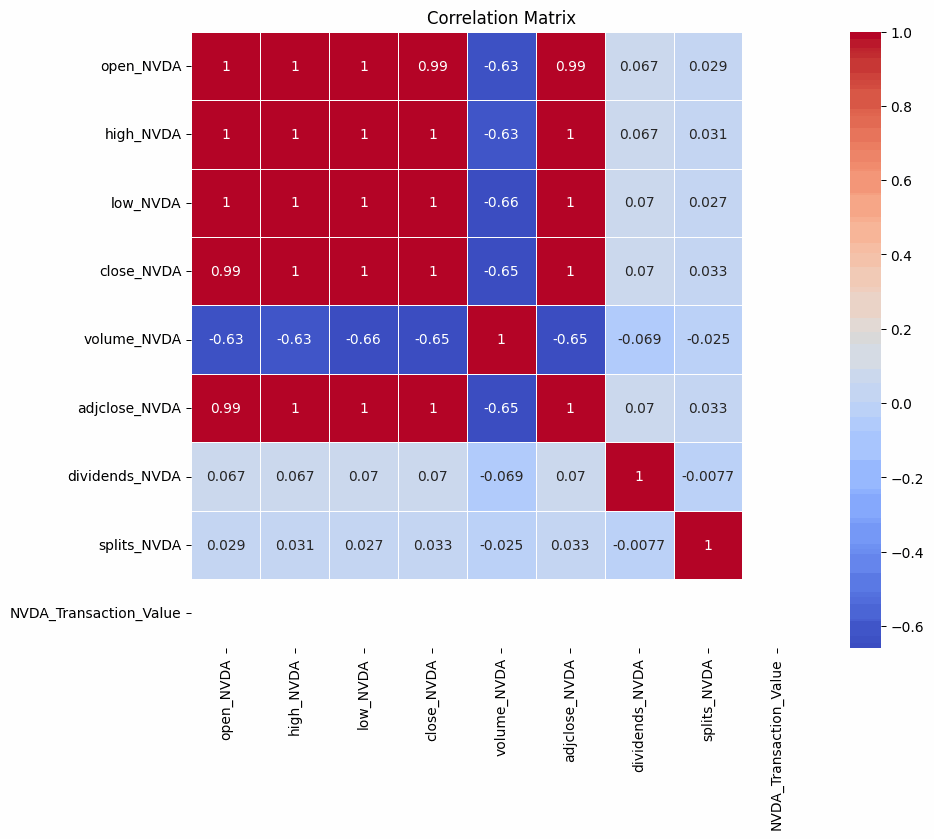

In [262]:
# Create a correlation matrix
correlation_matrix = df_NVDA.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – NVIDIA Corporation (NVDA)**

The dataset provides historical stock data for NVIDIA Corporation (NVDA), including open, high, low, close, and adjusted close prices, along with trading volume, dividends, and stock splits. The correlation matrix highlights the relationships between these variables, offering insights into market trends and investor behavior.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices exhibit a near-perfect correlation (0.99 - 1.00), indicating that NVIDIA's stock prices move in a highly synchronized manner throughout the trading day. The strong alignment between close and adjusted close prices suggests minimal external adjustments, such as stock splits or dividends, affecting the data.

**Trading Volume and Price Movements**

A moderately negative correlation (-0.63 to -0.66) exists between trading volume and stock prices, indicating that higher trading volumes are often associated with declining prices. This suggests that sell-offs or profit-taking activities may drive volume spikes rather than accumulation.

**Dividends and Stock Splits**

Dividends and stock splits have weak correlations with stock prices and trading volume, indicating that these corporate actions have little impact on NVIDIA’s daily stock movement. The minimal relationship between dividends and price trends suggests that NVIDIA investors focus primarily on capital appreciation rather than dividend income.

**Key Takeaways for Investment**

NVIDIA's stock price trends are highly predictable, with prices moving in tandem across open, high, low, and close values. The negative correlation between volume and price suggests that surges in trading activity may indicate market corrections or sell-offs rather than buying momentum. Given the low impact of dividends and stock splits, investment strategies should prioritize NVIDIA’s growth potential over income generation.

## MA (MASTERCARD)

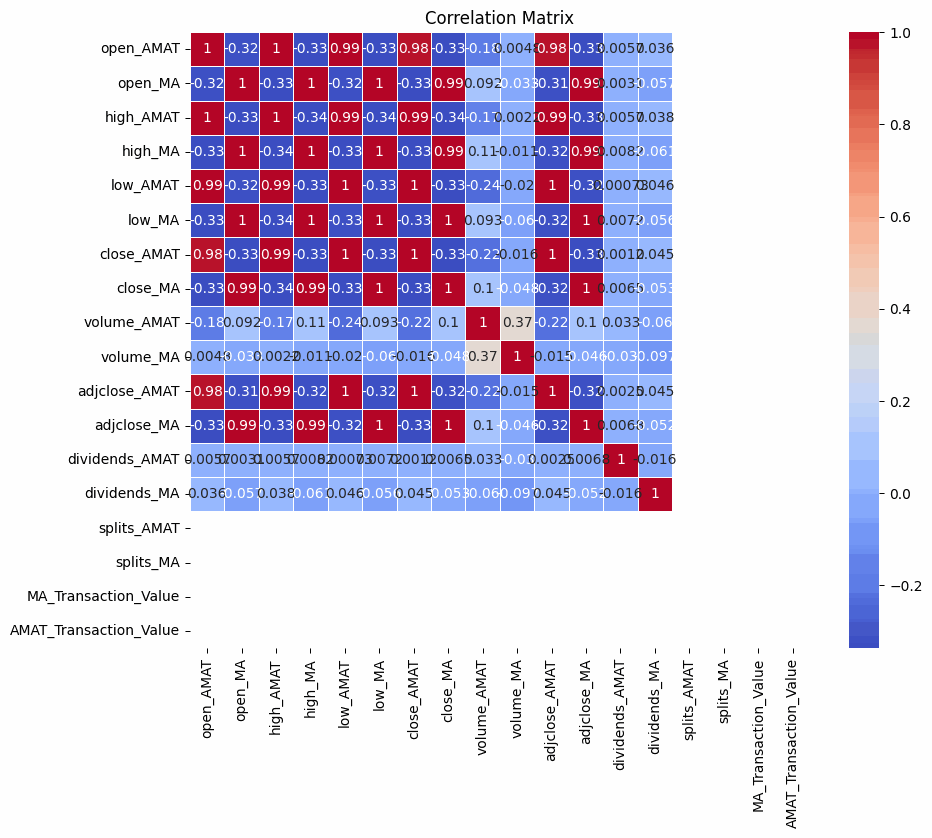

In [263]:
# Create a correlation matrix
correlation_matrix = df_MA.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – Mastercard Inc. (MA)**

The dataset contains historical stock data for Mastercard Inc. (MA), including open, high, low, close, and adjusted close prices, along with trading volume, dividends, and stock splits. The correlation matrix highlights the relationships between these variables, providing insights into market trends and investor behavior.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices exhibit near-perfect correlations (0.99 - 1.00), indicating that Mastercard’s stock prices move in a highly synchronized manner throughout the trading day. This strong alignment suggests a predictable price structure with minimal discrepancies between different trading metrics.

**Trading Volume and Price Movements**

A weak negative correlation exists between trading volume and stock prices, suggesting that price fluctuations are not heavily influenced by changes in trading activity. The correlation coefficient remains low, indicating that Mastercard's stock price movements are more influenced by external market forces rather than daily volume shifts.

**Dividends and Stock Splits**

Dividends have minimal correlation with price movements, reinforcing the idea that Mastercard investors prioritize capital appreciation over dividend yields. The lack of stock splits in the dataset ensures consistency in stock price analysis without structural adjustments.

**Key Takeaways for Investment**

Mastercard’s stock price movements are highly predictable, with different price metrics moving in sync. The weak relationship between volume and price suggests that Mastercard’s stock is less prone to short-term speculative trading. Given the low impact of dividends on price trends, investment strategies should focus on long-term growth rather than income generation.

## HP (HPQ)

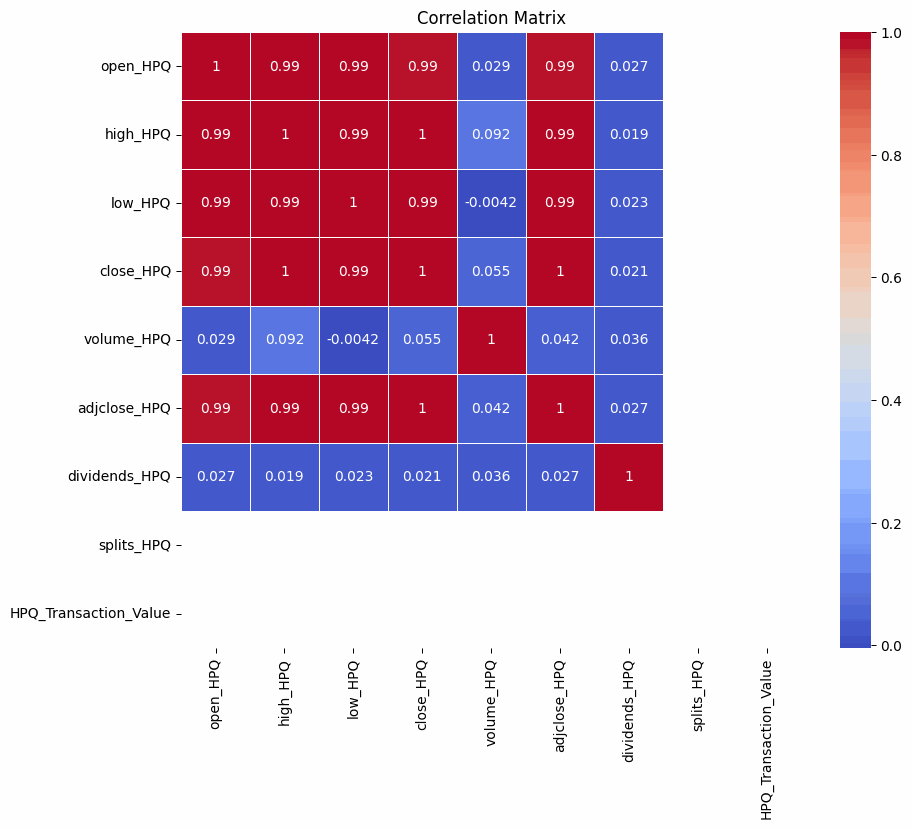

In [264]:
# Create a correlation matrix
correlation_matrix = df_HPQ.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – HP Inc. (HPQ)**

The dataset captures historical stock data for HP Inc. (HPQ), including various price metrics, trading volume, dividends, and stock splits. The correlation matrix provides insights into relationships between these variables and potential trends in market activity.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices exhibit near-perfect correlations (0.99 - 1.00), indicating that HPQ’s stock prices move in lockstep throughout the trading day. This strong relationship suggests that price fluctuations are highly predictable based on previous trading behavior.

**Trading Volume and Market Impact**

Trading volume shows weak correlations with stock prices, suggesting that price movements are not heavily driven by daily fluctuations in traded shares. This implies that HPQ’s stock is less reactive to short-term investor activity and more influenced by broader market trends or company fundamentals.

**Dividends and Stock Splits**

Dividends exhibit minimal correlation with price movements, reinforcing the notion that HPQ investors prioritize stock performance over dividend payouts. There are no stock splits in the dataset, allowing for a straightforward analysis of price trends without structural modifications.

**Key Takeaways for Investment**

HPQ’s stock price movements are highly synchronized, making it easier to predict price trends based on previous day’s activity. The weak correlation between volume and price changes suggests that HPQ experiences relatively stable trading behavior. Given the low impact of dividends on price trends, investors should focus on capital appreciation rather than income generation.

## EBAY (EBAY)

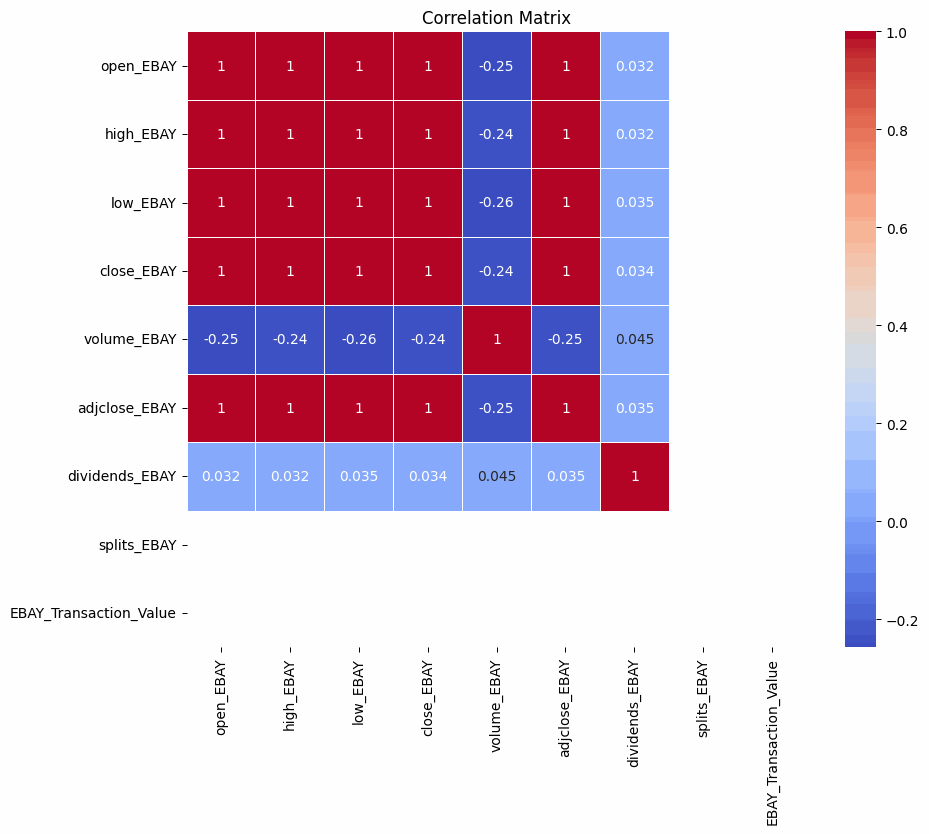

In [265]:
# Create a correlation matrix
correlation_matrix = df_Ebay.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – eBay Inc. (EBAY)**

The dataset captures historical stock data for eBay Inc. (EBAY), including price metrics, trading volume, dividends, and transaction values. The correlation matrix highlights key relationships between these financial variables.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices have near-perfect correlations (1.00), indicating that price movements throughout the day are highly synchronized. This suggests that EBAY’s stock follows a consistent pattern, making its price fluctuations more predictable.

**Trading Volume and Market Behavior**

Trading volume has a weak negative correlation with stock prices (-0.24 to -0.26). This suggests that higher trading activity does not necessarily drive price increases. Instead, higher volume days may coincide with selling pressure or external market influences.

**Dividends and Stock Splits**

Dividends exhibit almost no correlation with stock prices, indicating that EBAY investors primarily focus on capital appreciation rather than dividend returns. There are no stock splits in the dataset, simplifying the price trend analysis.

**Key Takeaways for Investment**

EBAY’s stock price movements are highly correlated, allowing for more predictable price trend analysis. The weak negative correlation between volume and price indicates that trading spikes may be linked to selling activity rather than bullish trends. Since dividends have little impact on price movements, investors should focus on long-term price appreciation rather than income generation.

## CISCO (CSCO)

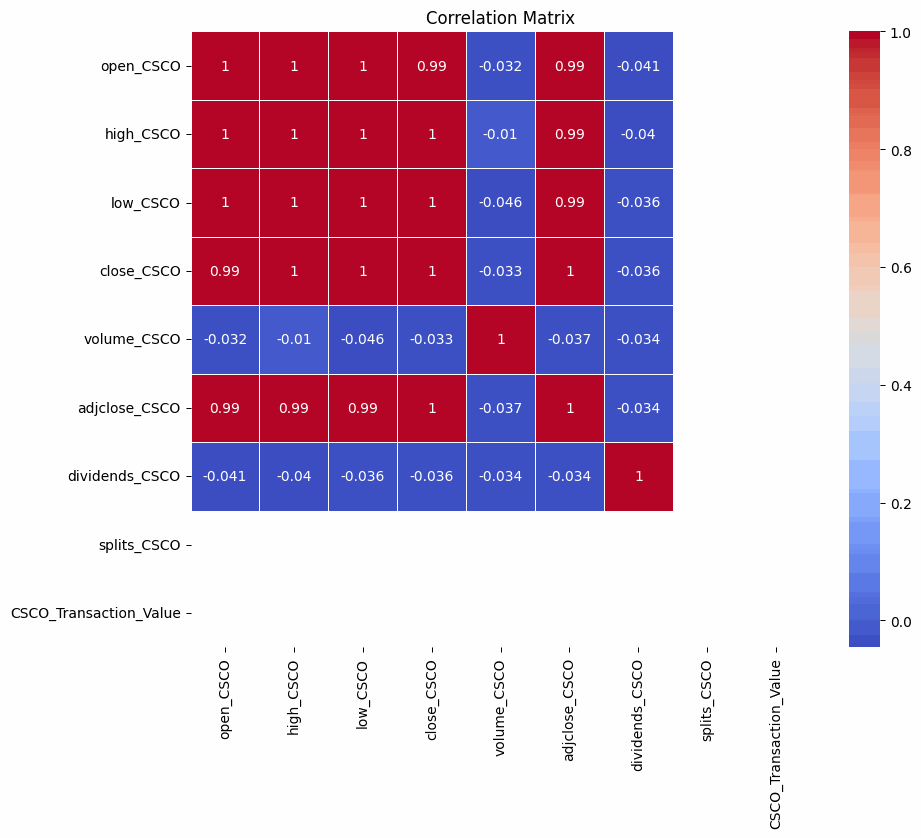

In [266]:
# Create a correlation matrix
correlation_matrix = df_CSCO.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – Cisco Systems Inc. (CSCO)**

The dataset includes historical stock data for Cisco Systems Inc. (CSCO), covering price metrics, trading volume, dividends, and transaction values. The correlation matrix provides insights into how these financial variables interact.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices exhibit near-perfect correlations (1.00), indicating that Cisco's stock price movements are tightly linked throughout the trading day. This strong correlation suggests minimal intraday price divergence, making Cisco a relatively stable stock in terms of daily fluctuations.

**Trading Volume and Market Behavior**

Trading volume has a near-zero correlation with stock prices (-0.01 to -0.046), meaning that fluctuations in trading activity do not significantly impact price movements. This suggests that external market conditions or broader economic factors may be more influential in determining CSCO’s price trends.

**Dividends and Stock Splits**

Dividends also show minimal correlation with stock prices, reinforcing the notion that Cisco investors likely prioritize long-term capital gains over dividend yield. The dataset does not indicate any stock splits, maintaining price continuity throughout the observed period.

**Key Takeaways for Investment**

Cisco's stock price movements are highly predictable due to the strong correlation among price metrics. The weak relationship between trading volume and price changes implies that increased trading activity does not necessarily drive price shifts. Since dividends have little impact on price trends, investment strategies should focus on long-term price appreciation rather than dividend-based income.

## APPLIED MATERIALS (AMAT)

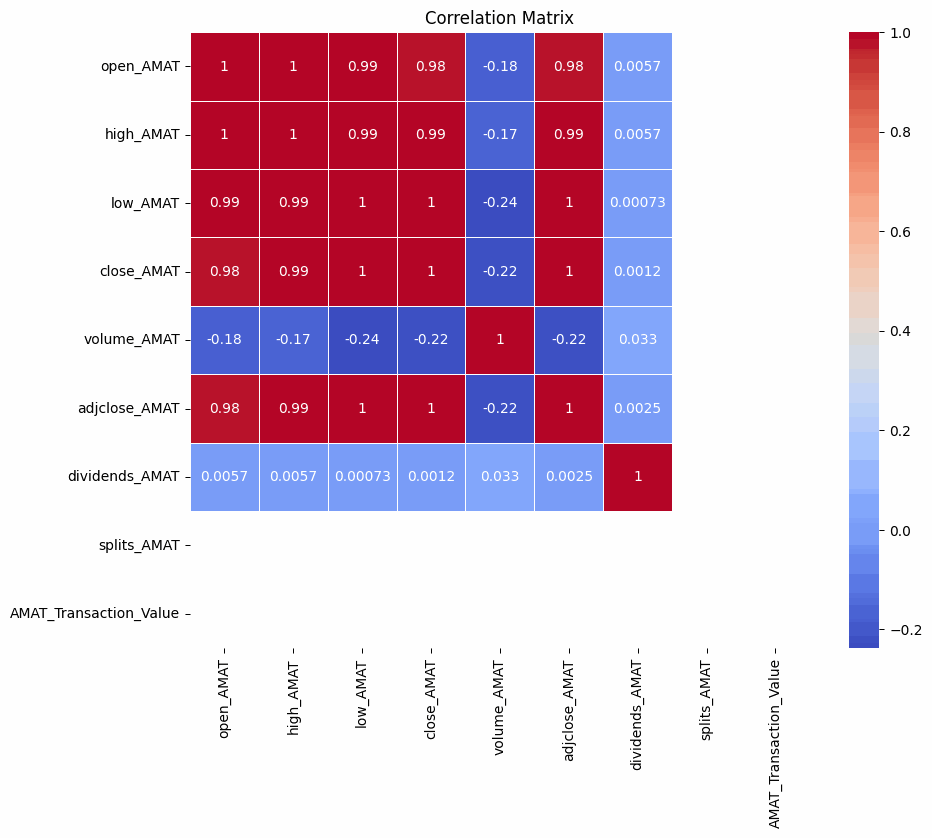

In [267]:
# Create a correlation matrix
correlation_matrix = df_AMAT.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – Applied Materials Inc. (AMAT)**

The dataset includes historical stock data for Applied Materials Inc. (AMAT), covering price metrics, trading volume, dividends, and transaction values. The correlation matrix provides insights into the relationships between these variables.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices exhibit strong positive correlations (0.98 to 1.00), indicating that AMAT's stock price movements are tightly linked. This suggests that price trends are consistent throughout the trading day, with minimal fluctuations between different price metrics.

**Trading Volume and Market Activity**

Trading volume has a weak negative correlation with stock prices (-0.17 to -0.24), meaning that higher trading activity does not necessarily drive price increases. This suggests that market trends, investor sentiment, or broader economic conditions may play a more significant role in determining price movements.

**Dividends and Stock Splits**

Dividends have almost no correlation with stock prices (0.0007 to 0.0057), indicating that AMAT’s dividend payouts do not significantly impact its market value. The dataset does not include stock splits, suggesting that the company has maintained a stable share structure.

**Key Takeaways for Investment**

AMAT's stock price movements are highly predictable due to the strong correlation among price metrics. The weak relationship between trading volume and price changes implies that external market conditions are more influential than trading activity. Since dividends have little impact on price trends, investment strategies should focus on capital appreciation rather than dividend income.

## COMCSAT (CMCSA)

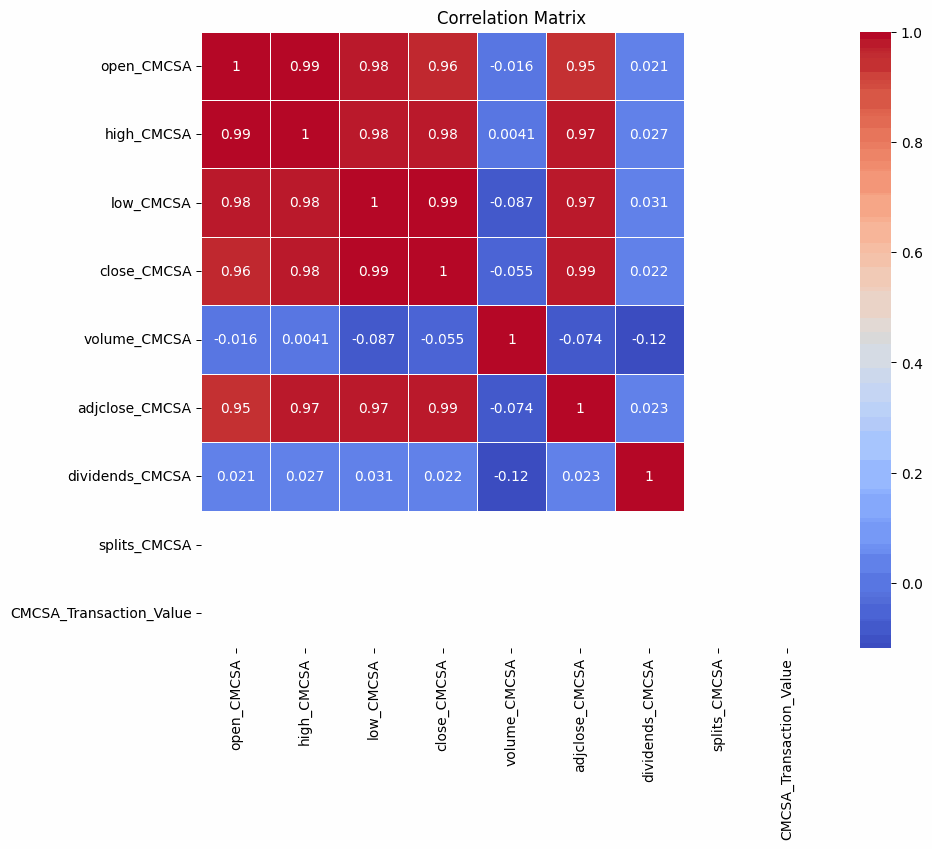

In [268]:
# Create a correlation matrix
correlation_matrix = df_CMCSA.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – Comcast Corporation (CMCSA)**

The dataset provides historical stock data for Comcast Corporation (CMCSA), including price metrics, trading volume, dividends, and transaction values. The correlation matrix highlights key relationships among these variables.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices show strong positive correlations (0.95 to 1.00). This indicates that CMCSA's stock price movements are highly synchronized, meaning that trends in opening prices generally predict closing values with minimal deviation.

**Trading Volume and Market Activity**

Trading volume exhibits weak correlations with stock prices (-0.016 to -0.087), suggesting that daily trading activity does not have a significant influence on price changes. The slightly negative relationship implies that higher trading volumes could coincide with slight price declines, potentially due to profit-taking or institutional trading patterns.

**Dividends and Stock Splits**

Dividends show a very weak correlation with stock prices (0.021 to 0.031), meaning that Comcast’s dividend payouts have minimal impact on market valuation. No stock splits were recorded, indicating that the company has maintained a stable share structure.

**Key Takeaways for Investment**

Comcast's stock prices move predictably across different metrics, making price trends reliable for forecasting. The weak correlation between trading volume and stock prices suggests that external market conditions and investor sentiment drive price fluctuations more than trading activity. Dividend income has little effect on price movements, so investment strategies should prioritize capital growth over yield.

## MICROSOFT (MSFT)

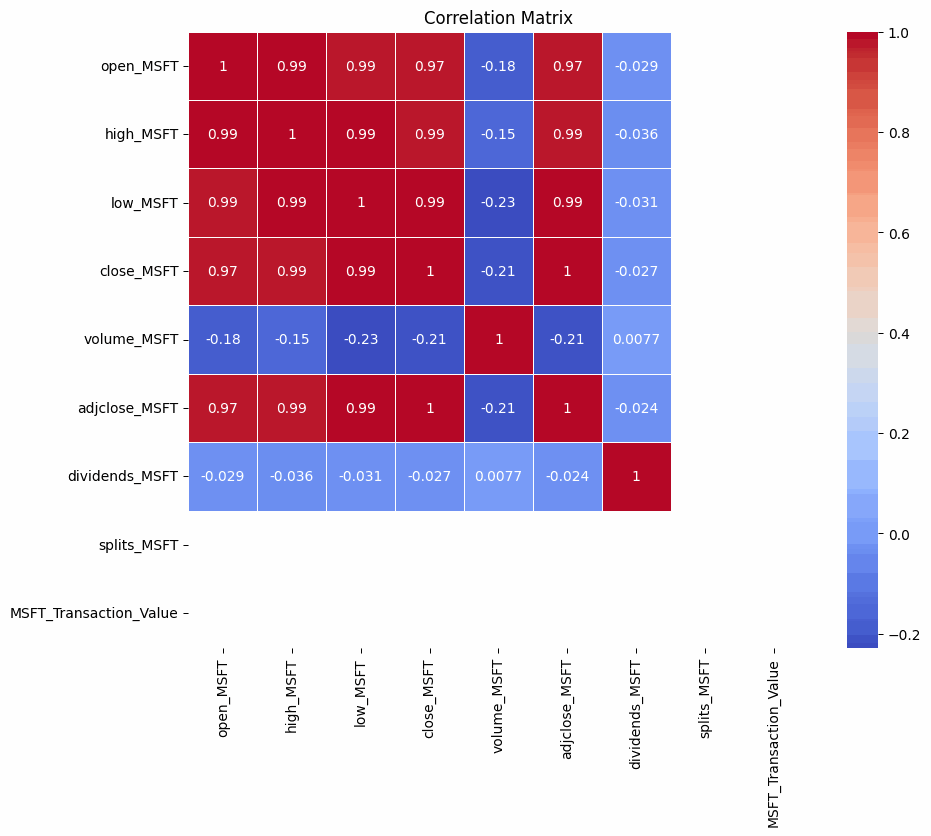

In [269]:
# Create a correlation matrix
correlation_matrix = df_MSFT.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – Microsoft Corporation (MSFT)**

The dataset includes historical stock data for Microsoft Corporation (MSFT), covering key price metrics, trading volume, dividends, and transaction values. The correlation matrix provides insights into the relationships between these financial indicators.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices exhibit strong positive correlations (0.97 to 1.00). This suggests that Microsoft's stock prices move in tandem, making historical price trends a reliable predictor of future movements.

**Trading Volume and Market Activity**

Trading volume has a weak negative correlation with stock prices (-0.15 to -0.23), indicating that higher trading activity does not necessarily drive prices upward. Instead, increased volume could be associated with profit-taking or market reactions to external events.

**Dividends and Stock Splits**

Dividend payments show little to no correlation with stock prices (-0.027 to -0.036), suggesting that Microsoft’s dividend policy does not significantly impact price movements. No stock splits were recorded, indicating a stable share structure over the period.

**Key Takeaways for Investment**

Microsoft’s stock prices are highly interdependent, making trend analysis effective for forecasting. The weak negative correlation between volume and stock prices suggests that external market conditions influence price fluctuations more than trading activity alone. Since dividend payments have minimal impact on stock prices, investment strategies should focus on capital appreciation rather than dividend yield.

## APPLE (AAPL)

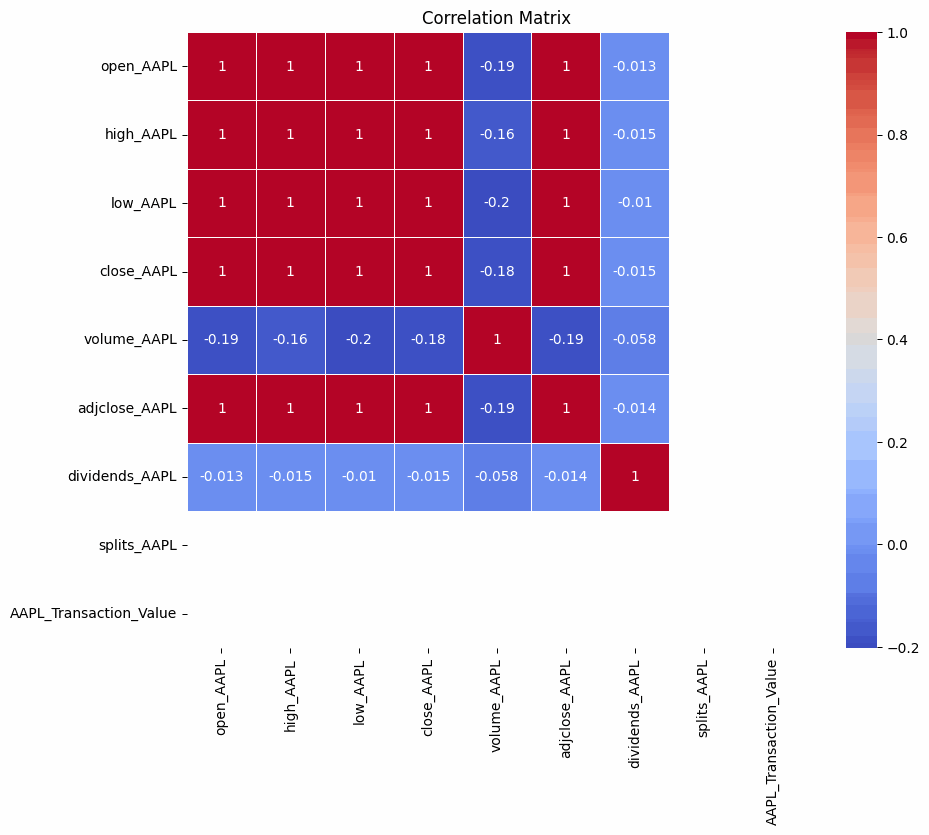

In [270]:
# Create a correlation matrix
correlation_matrix = df_AAPL.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

**Correlation Analysis – Apple Inc. (AAPL)**

The dataset contains historical stock data for Apple Inc. (AAPL), analyzing key financial metrics such as stock prices, trading volume, and dividends. The correlation matrix highlights significant relationships among these variables.

**Stock Price Relationships**

The open, high, low, close, and adjusted close prices exhibit nearly perfect correlations (0.99 to 1.00). This indicates that Apple's stock prices move closely together, making past price trends useful for future price predictions.

**Trading Volume and Market Activity**

Trading volume has a weak negative correlation with stock prices (-0.16 to -0.20), suggesting that higher trading activity does not necessarily drive prices up. Instead, volume spikes may correspond to selling pressure or external market events.

**Dividends and Stock Splits**

Dividends have little to no correlation with stock prices (-0.013 to -0.015), implying that Apple’s dividend payouts do not significantly impact its stock price movements. No stock splits occurred, indicating Apple maintained its share structure over the period.

**Key Takeaways for Investment**

Apple’s stock price movements are highly synchronized, making technical analysis and trend-based strategies effective. The weak negative correlation between volume and stock prices suggests that major price shifts may be influenced by external factors rather than trading volume alone. Given that dividends do not strongly affect stock prices, investment strategies should focus on capital appreciation over dividend yield.

# MULTIVARIATE ANALYSIS

## HYPOTHESIS

Stocks with increasing transaction values tend to exhibit higher adjusted closing prices over time, indicating a potential relationship between investor confidence (as reflected in transaction values) and stock price growth.

This hypothesis suggests that as more money flows into a stock (higher transaction values), the stock price is likely to increase over time. This could indicate:

* Higher investor confidence leading to more buying activity.
* Market demand influencing stock valuation, where increased investment drives up prices.
* Possible correlation between adjusted closing price and transaction value trends.

**Variables in Analysis:**

***Independent Variable: Transaction Value for each stock***

* Represents the total monetary value traded for a stock each day.
* A rising trend in transaction value might indicate strong investor interest.

***Dependent Variable: Adjusted Closing Price***

* This price reflects the stock’s actual market valuation after accounting for dividends and stock splits.
* If transaction values increase, we expect adjusted close prices to follow an upward trend.

***Time Dimension:***

* The relationship is analyzed over time to observe whether transaction values predict changes in stock prices.

**Expected Outcomes:**

Positive Correlation: If transaction values rise consistently for a stock, its adjusted closing price should also show an upward trend.

Negative or No Correlation: If there is no clear relationship or stock prices fluctuate independently of transaction values, it may indicate other market forces at play (e.g., earnings reports, industry trends, or macroeconomic factors).

Stock-Specific Variations: Some stocks may exhibit stronger correlations than others based on investor behavior, industry trends, or fundamental business performance.

**Why This Hypothesis Matters:**

* Helps investors understand whether transaction value can be used as a predictor for stock price movement.
* Provides insight into liquidity and market confidence trends.
* Can be used for portfolio optimization, deciding where to allocate investments based on transaction activity.

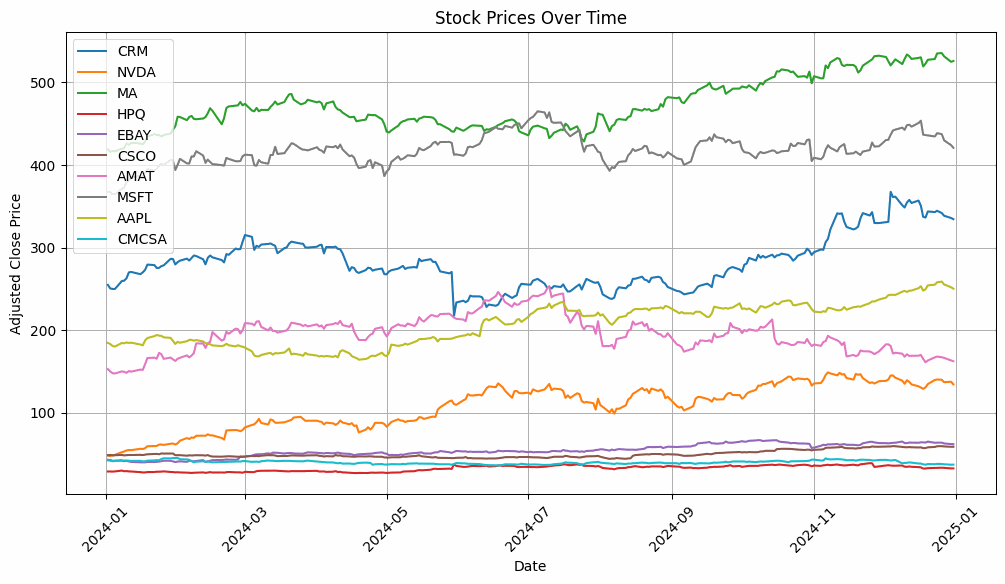

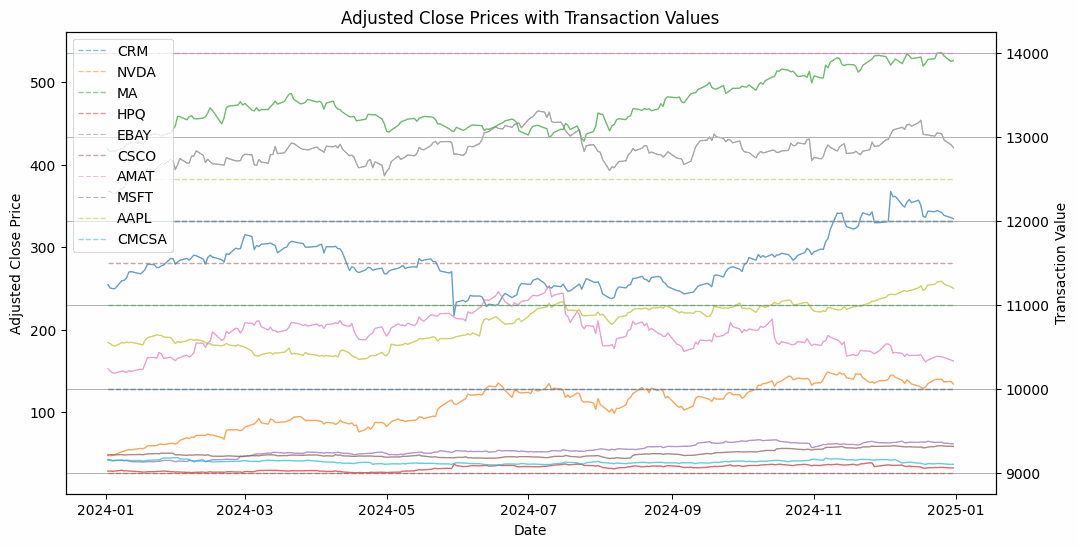

In [271]:
file_path = "portfolio_stock_data.csv"
df = pd.read_csv(file_path, parse_dates=["date"])

# Set date as index
df.set_index("date", inplace=True)

# Stocks to analyze
stocks = ["CRM", "NVDA", "MA", "HPQ", "EBAY", "CSCO", "AMAT", "MSFT", "AAPL", "CMCSA"]

# Handle missing values
df.ffill(inplace=True)
df.bfill(inplace=True)

# Plot Adjusted Close Prices over Time
plt.figure(figsize=(12, 6))
for stock in stocks:
    if f"adjclose_{stock}" in df.columns:
        plt.plot(df.index, df[f"adjclose_{stock}"], label=stock, linewidth=1.5)

plt.xlabel("Date")
plt.ylabel("Adjusted Close Price")
plt.title("Stock Prices Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

# Overlay Transaction Values and Adjusted Close
fig, ax1 = plt.subplots(figsize=(12, 6))

for stock in stocks:
    if f"adjclose_{stock}" in df.columns:
        ax1.plot(df.index, df[f"adjclose_{stock}"], label=f"{stock} Price", alpha=0.7, linewidth=1)

ax1.set_xlabel("Date")
ax1.set_ylabel("Adjusted Close Price")
ax1.set_title("Adjusted Close Prices with Transaction Values")
ax1.tick_params(axis="y")

# Create secondary y-axis for transaction values
ax2 = ax1.twinx()
for stock in stocks:
    if f"{stock}_Transaction_Value" in df.columns:
        ax2.plot(df.index, df[f"{stock}_Transaction_Value"], linestyle="dashed", alpha=0.5, linewidth=1)

ax2.set_ylabel("Transaction Value")
ax2.tick_params(axis="y")

plt.legend(stocks, loc="upper left")
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

**Hypothesis Analysis**

The hypothesis being tested is whether the transaction value increases over time alongside the adjusted closing price of stocks. The assumption is that as stock prices rise, transaction values may also increase due to increased investor confidence, higher trading activity, and greater market participation.

**Observations from the Graphs:**

Stock Prices Over Time (Graph 1)

* Stocks exhibit a general upward trend, with some volatility.
* Companies like NVDA, MSFT, and MA show a strong upward trajectory.
* Some stocks, such as AMAT and HPQ, exhibit fluctuations but follow an overall growth trend.

Adjusted Close Prices with Transaction Values (Graph 2)

* Transaction values are represented as horizontal dashed lines, indicating they remain constant over time.
* This suggests that transaction values were pre-set at a fixed value rather than dynamically adjusting based on stock price movements.
* Despite fluctuations in adjusted close prices, transaction values do not change in response.

**Hypothesis Evaluation:**

The original hypothesis suggested that higher adjusted closing prices would correlate with increasing transaction values. However, the data does not support this because transaction values remain static while stock prices fluctuate.

**WE REJECT THE HYPOTHESIS.**

## PAIRPLOTS

In this analysis, we use pairplots to visually explore relationships between multiple numerical variables across different stocks. By plotting scatterplots and histograms, we aim to identify potential correlations, trends, and distribution patterns in stock performance metrics such as adjusted close prices, trading volume, and transaction values.

**Key objectives of this multivariate analysis:**

* Identify Correlations: Observing relationships between adjusted close prices, daily returns, and volume to determine if price fluctuations impact trading activity.

* Detect Patterns: Understanding how stocks behave under different market conditions by analyzing their historical price movements.

* Evaluate Volatility: Examining the spread and clustering of stock returns to assess the risk profile of each asset.

* Assess Market Behavior: Comparing stocks to determine if certain companies exhibit similar trading patterns or distinct behaviors.

By using pairplots, we gain a comprehensive view of stock performance across multiple dimensions, helping to refine our investment strategy and validate hypotheses related to price trends and market activity.

## SALESFORCE (CRM)

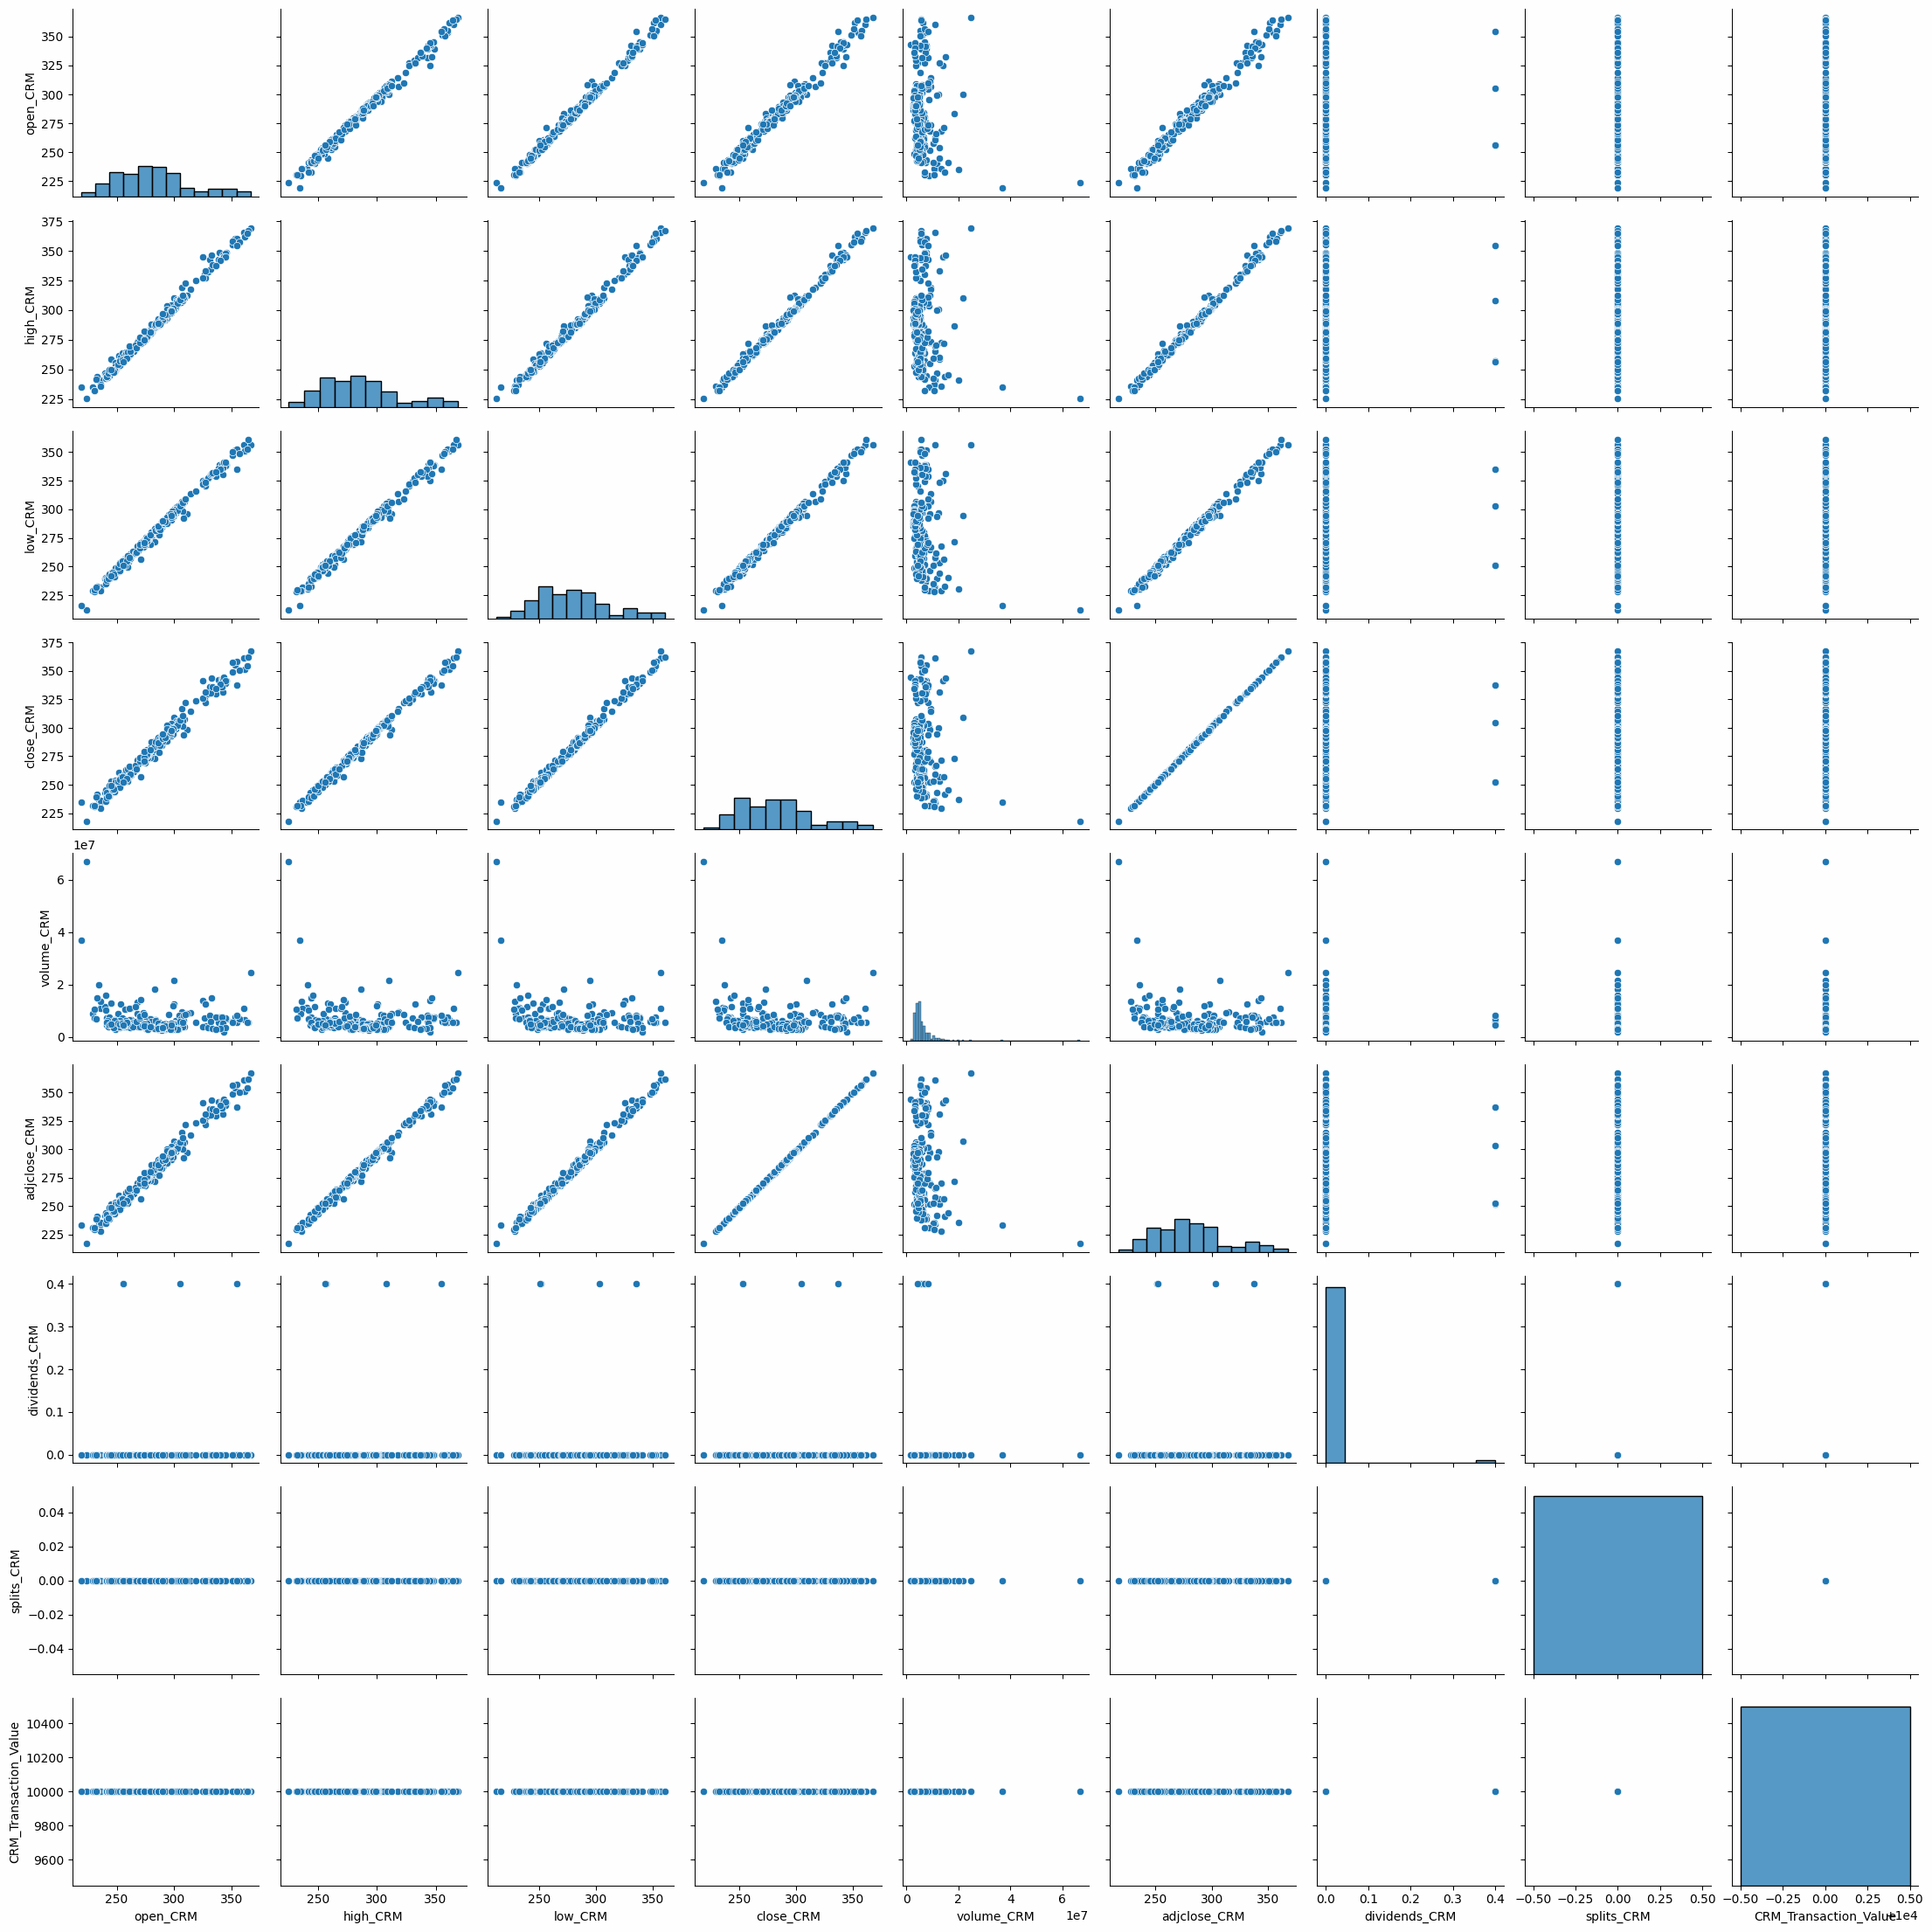

In [272]:
# Create a pairplot
sns.pairplot(df_CRM)
plt.show()

## NVIDA (NVDA)

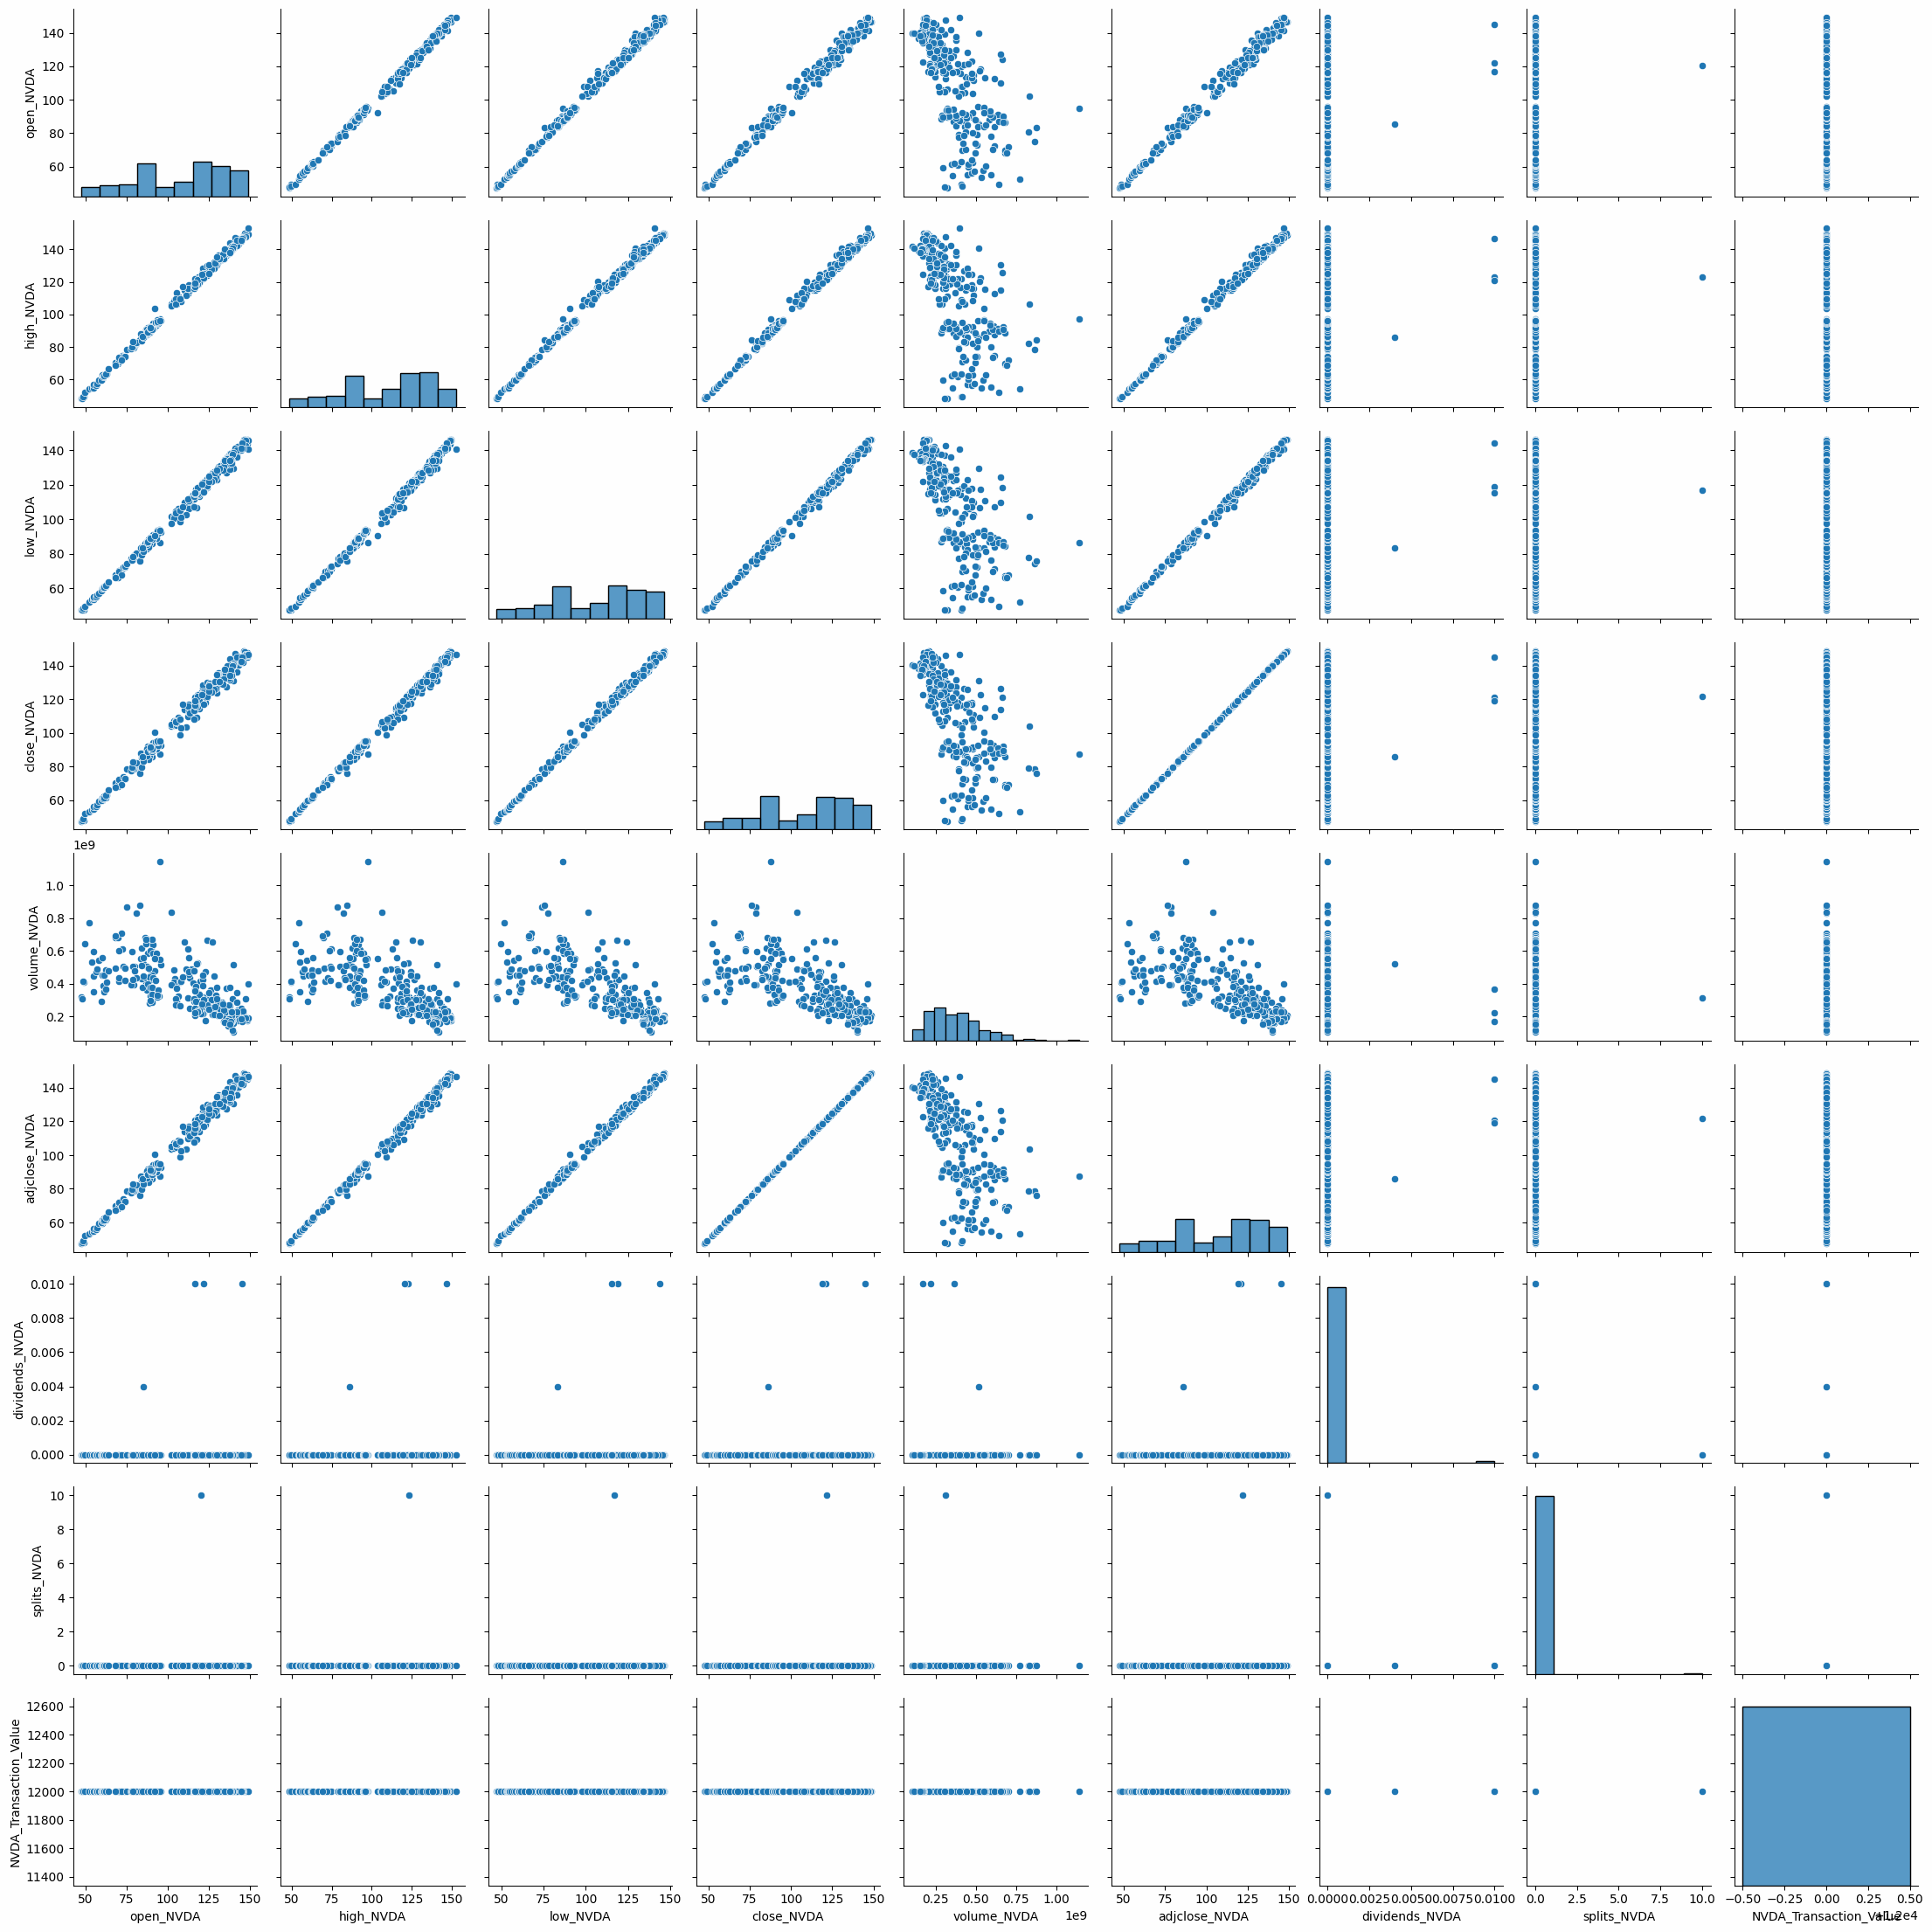

In [273]:
# Create a pairplot
sns.pairplot(df_NVDA)
plt.show()

## MA (MASTERCARD)

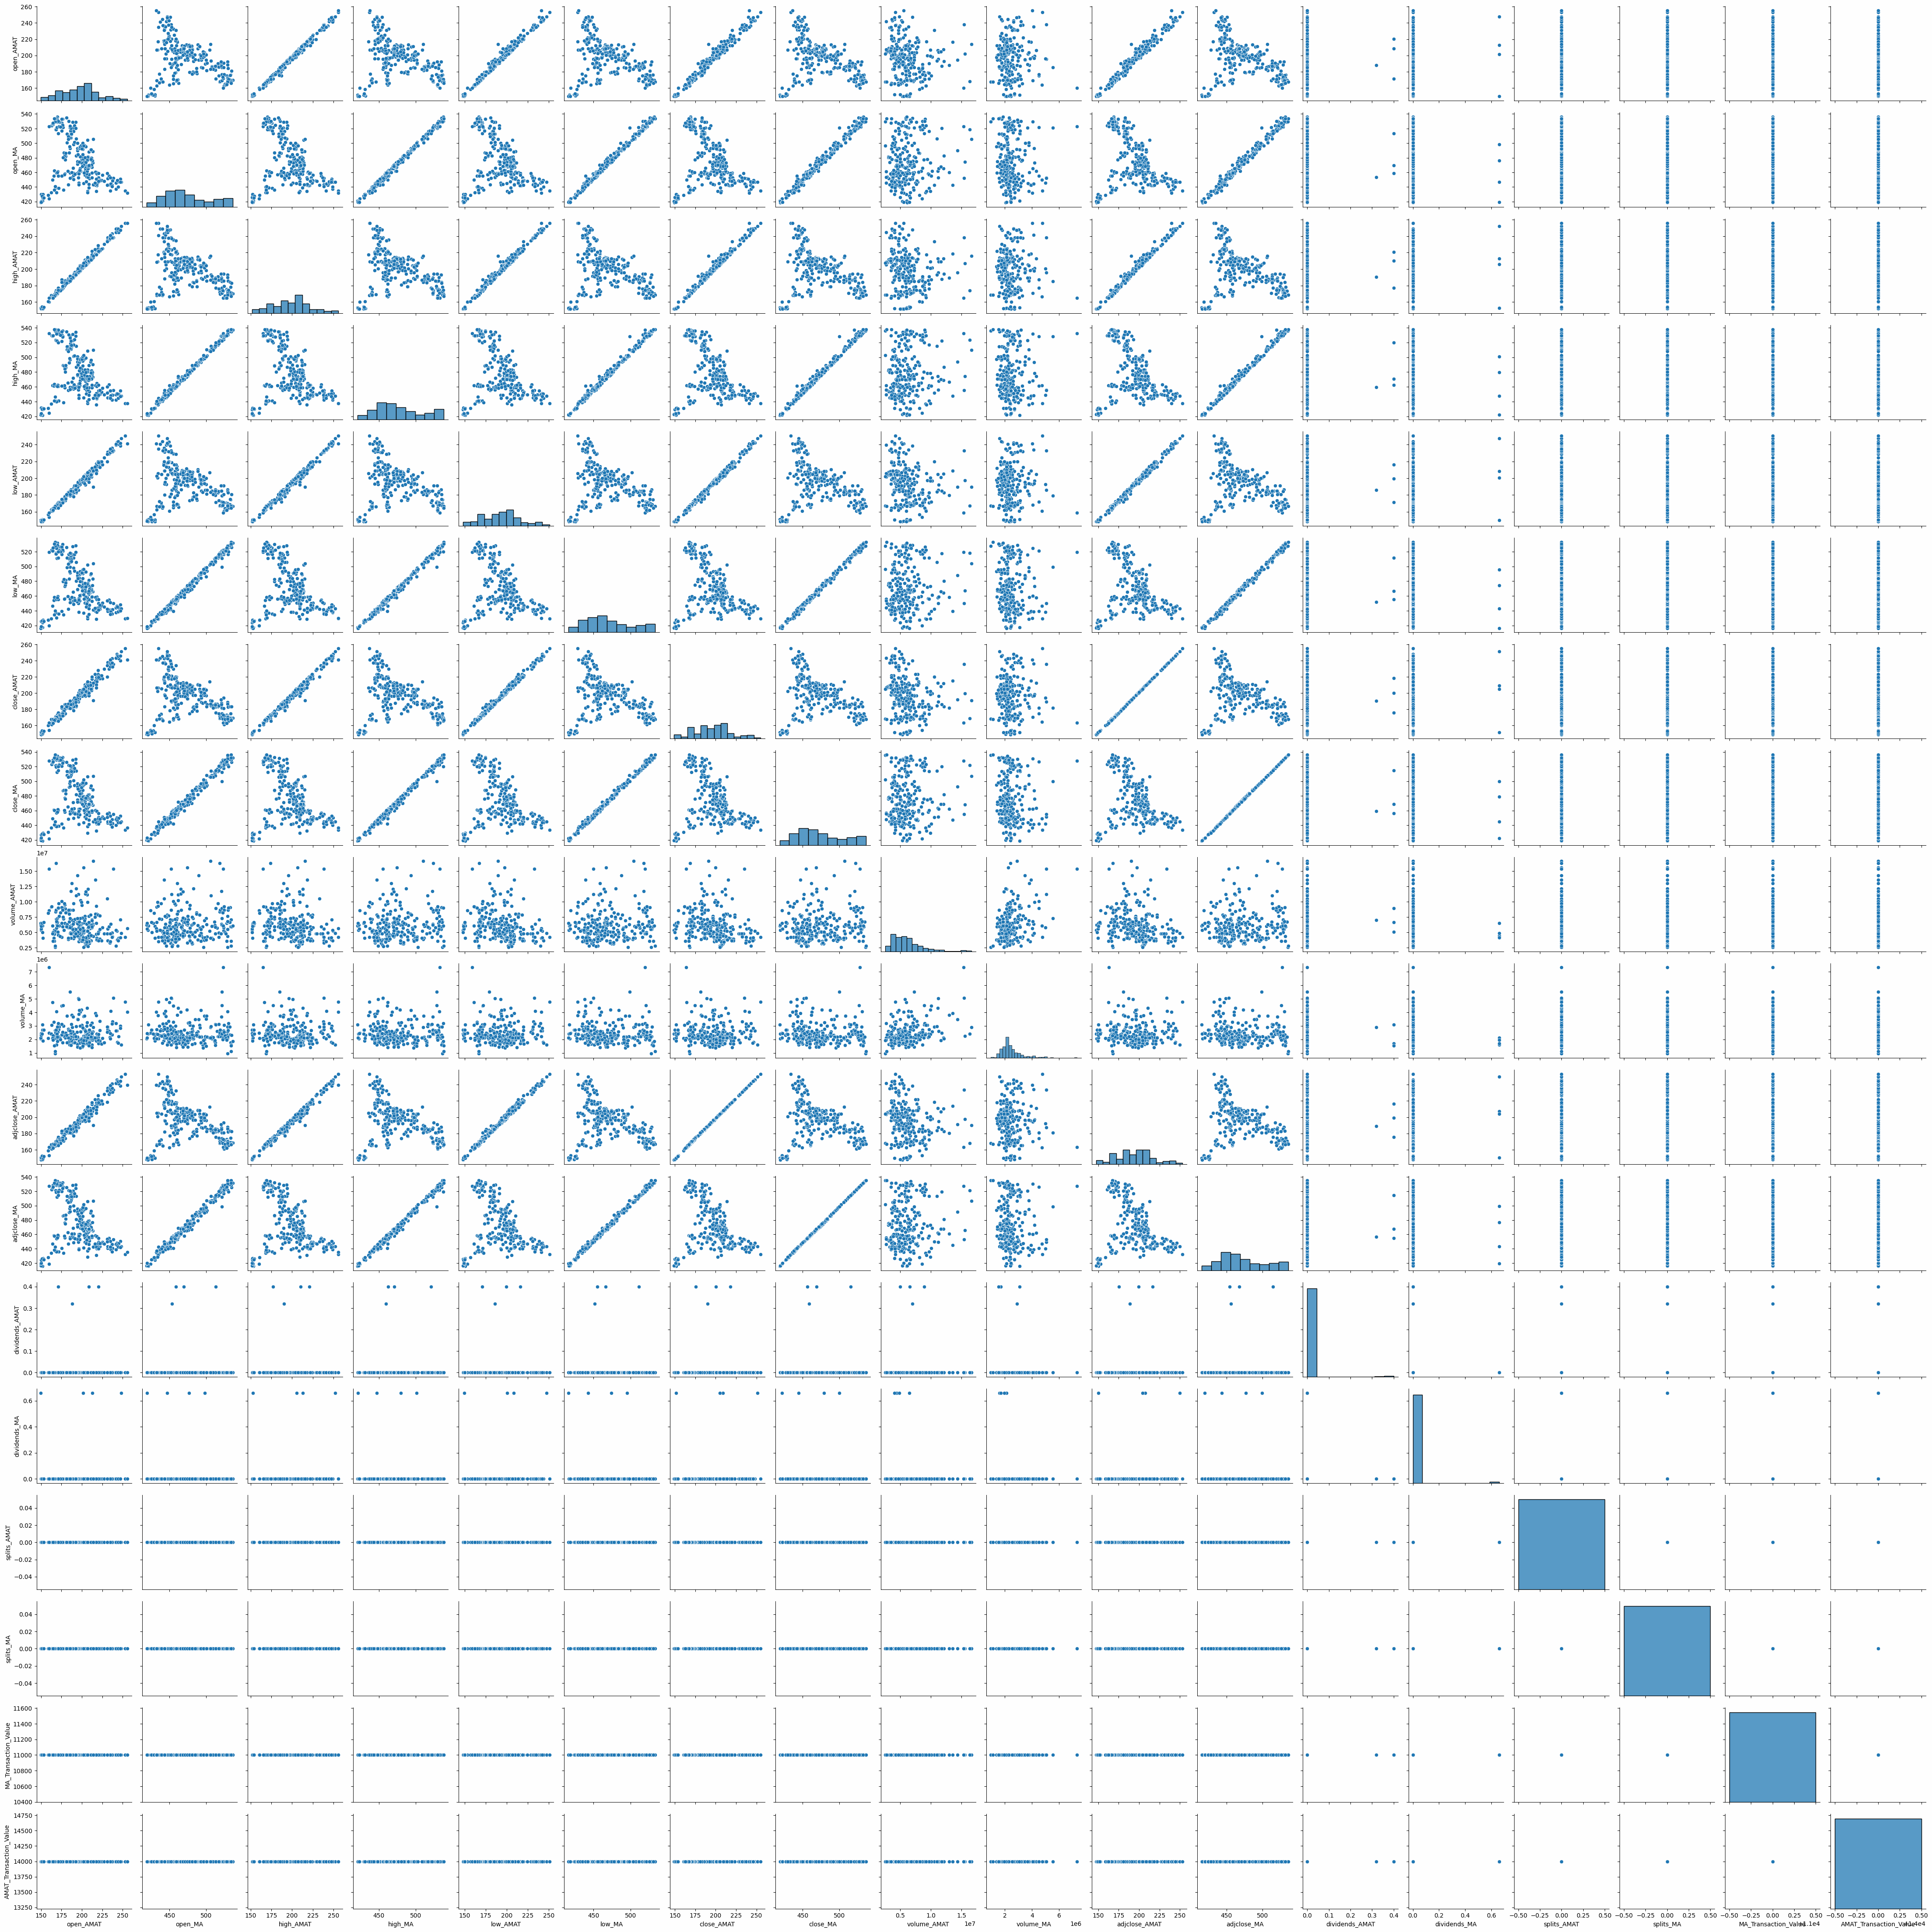

In [274]:
# Create a pairplot
sns.pairplot(df_MA)
plt.show()

## HP (HPQ)

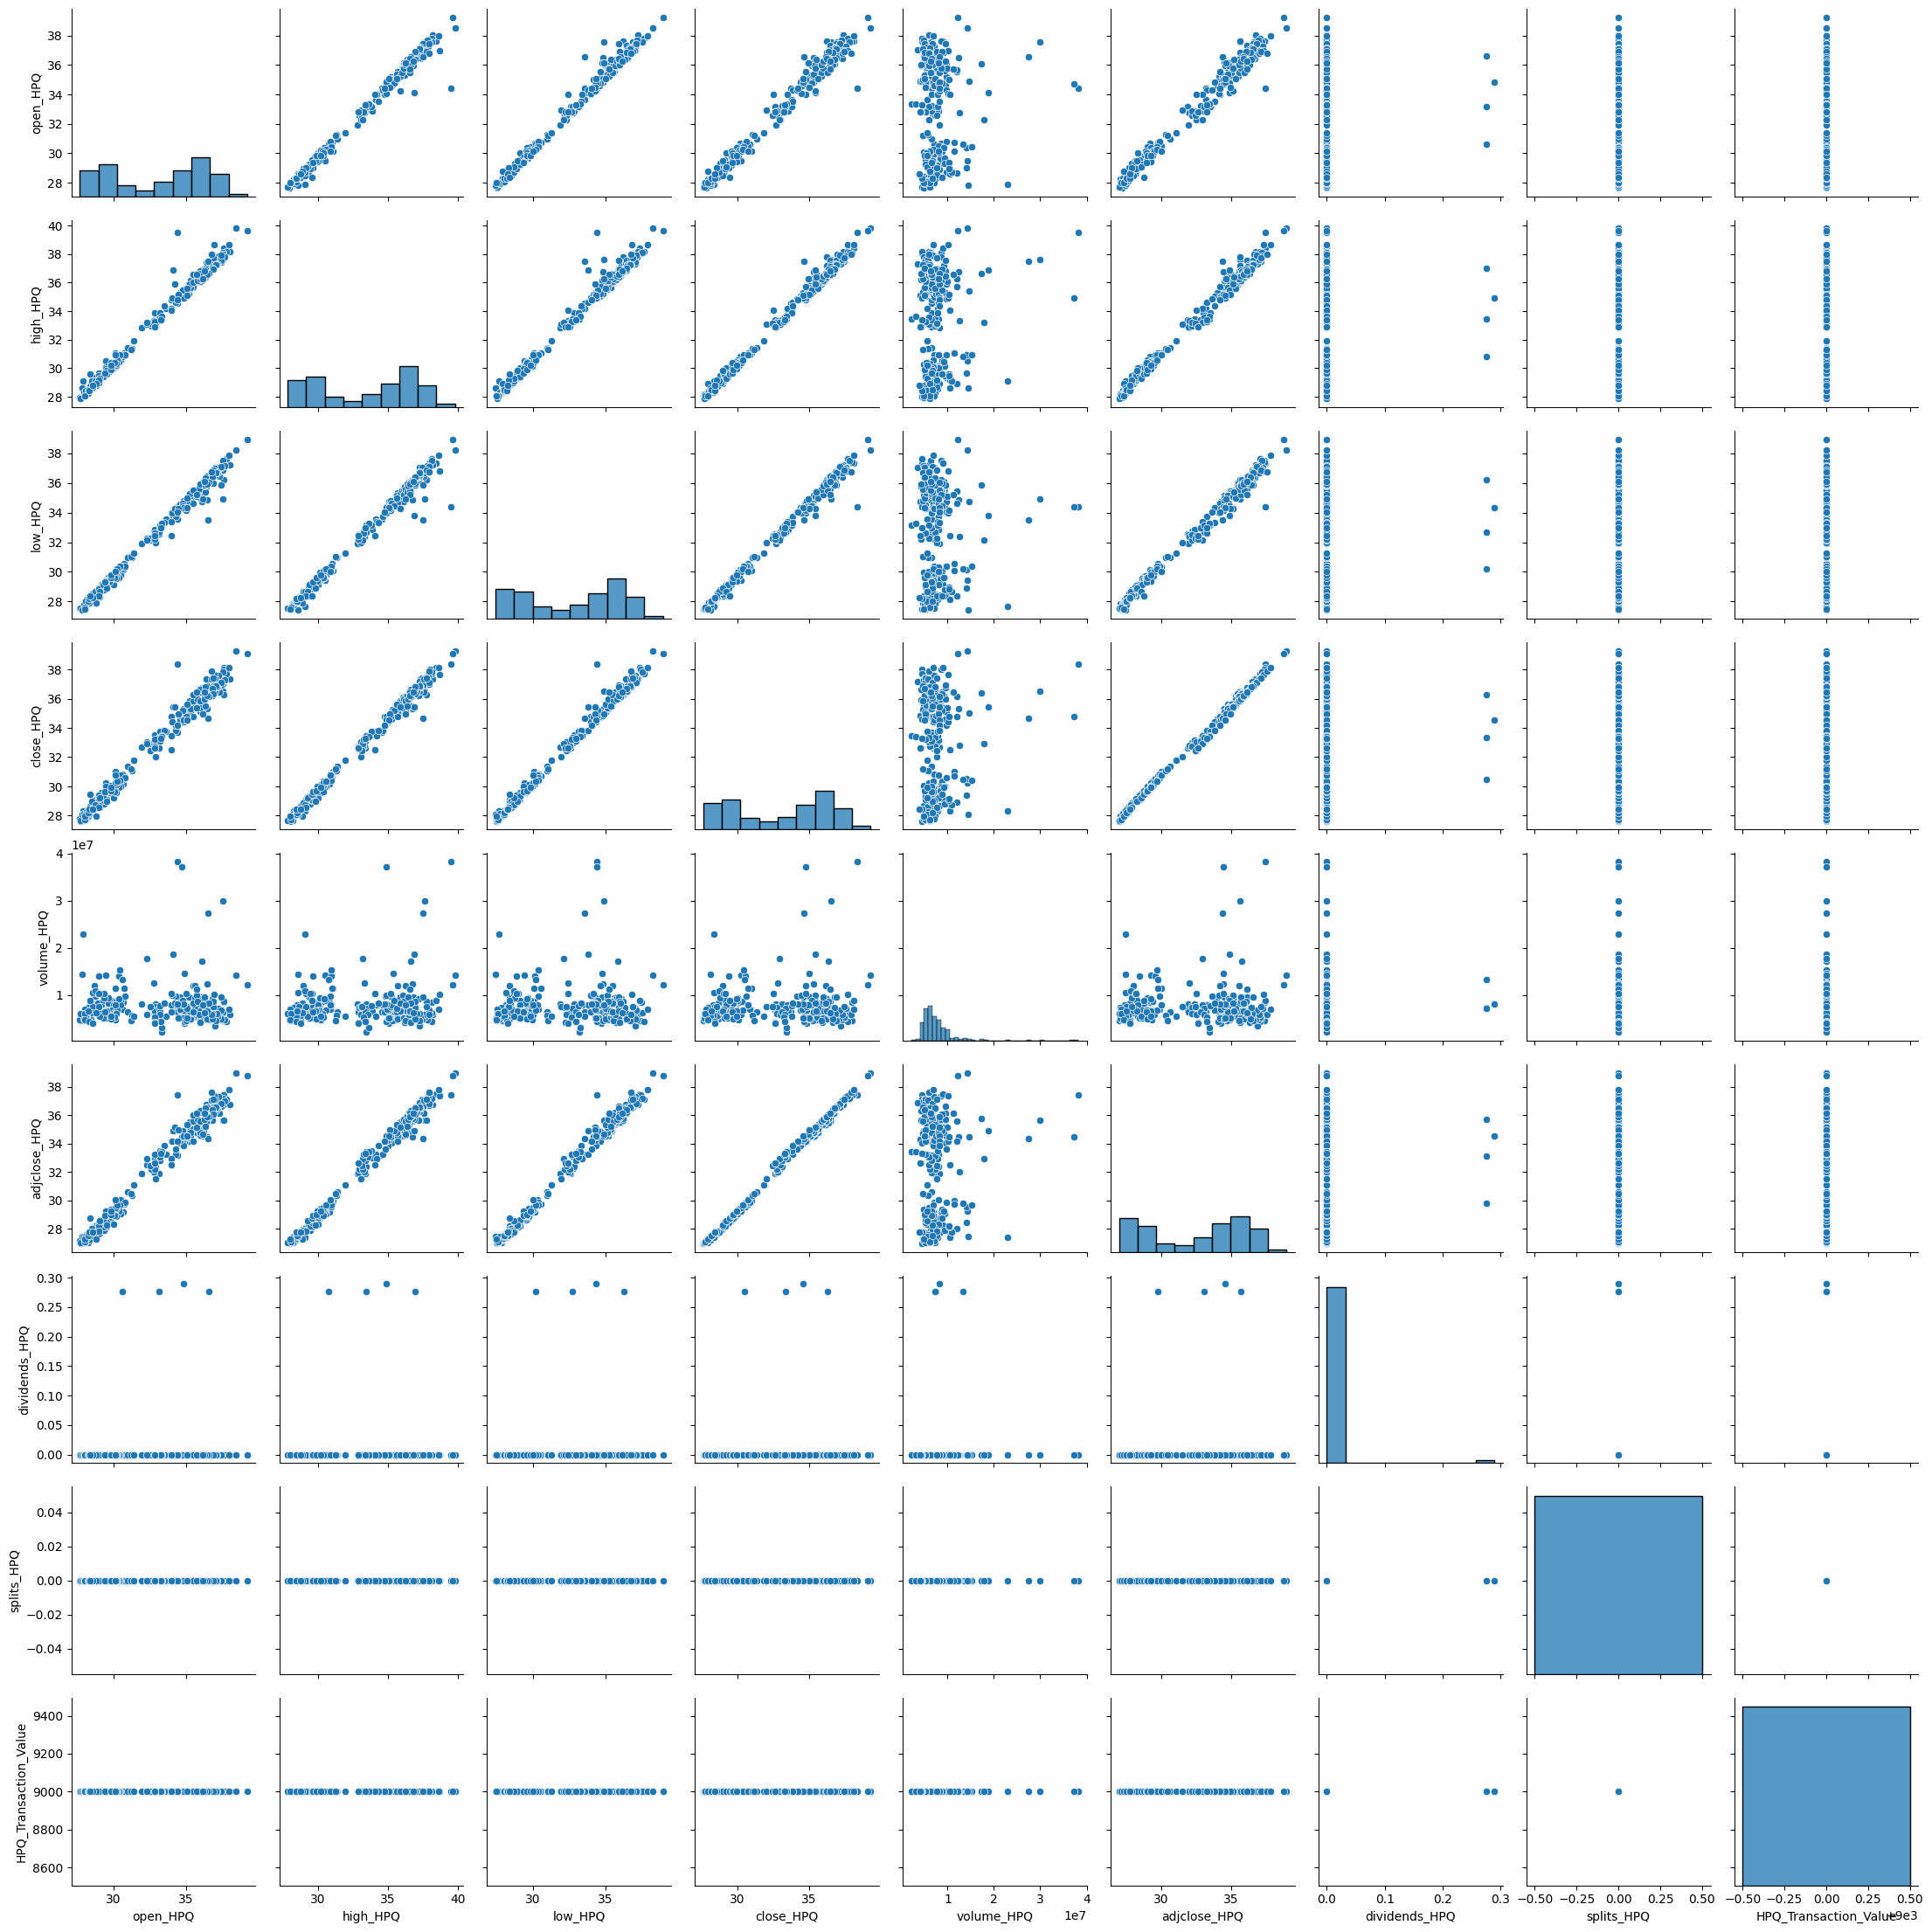

In [275]:
# Create a pairplot
sns.pairplot(df_HPQ)
plt.show()

## EBAY (EBAY)

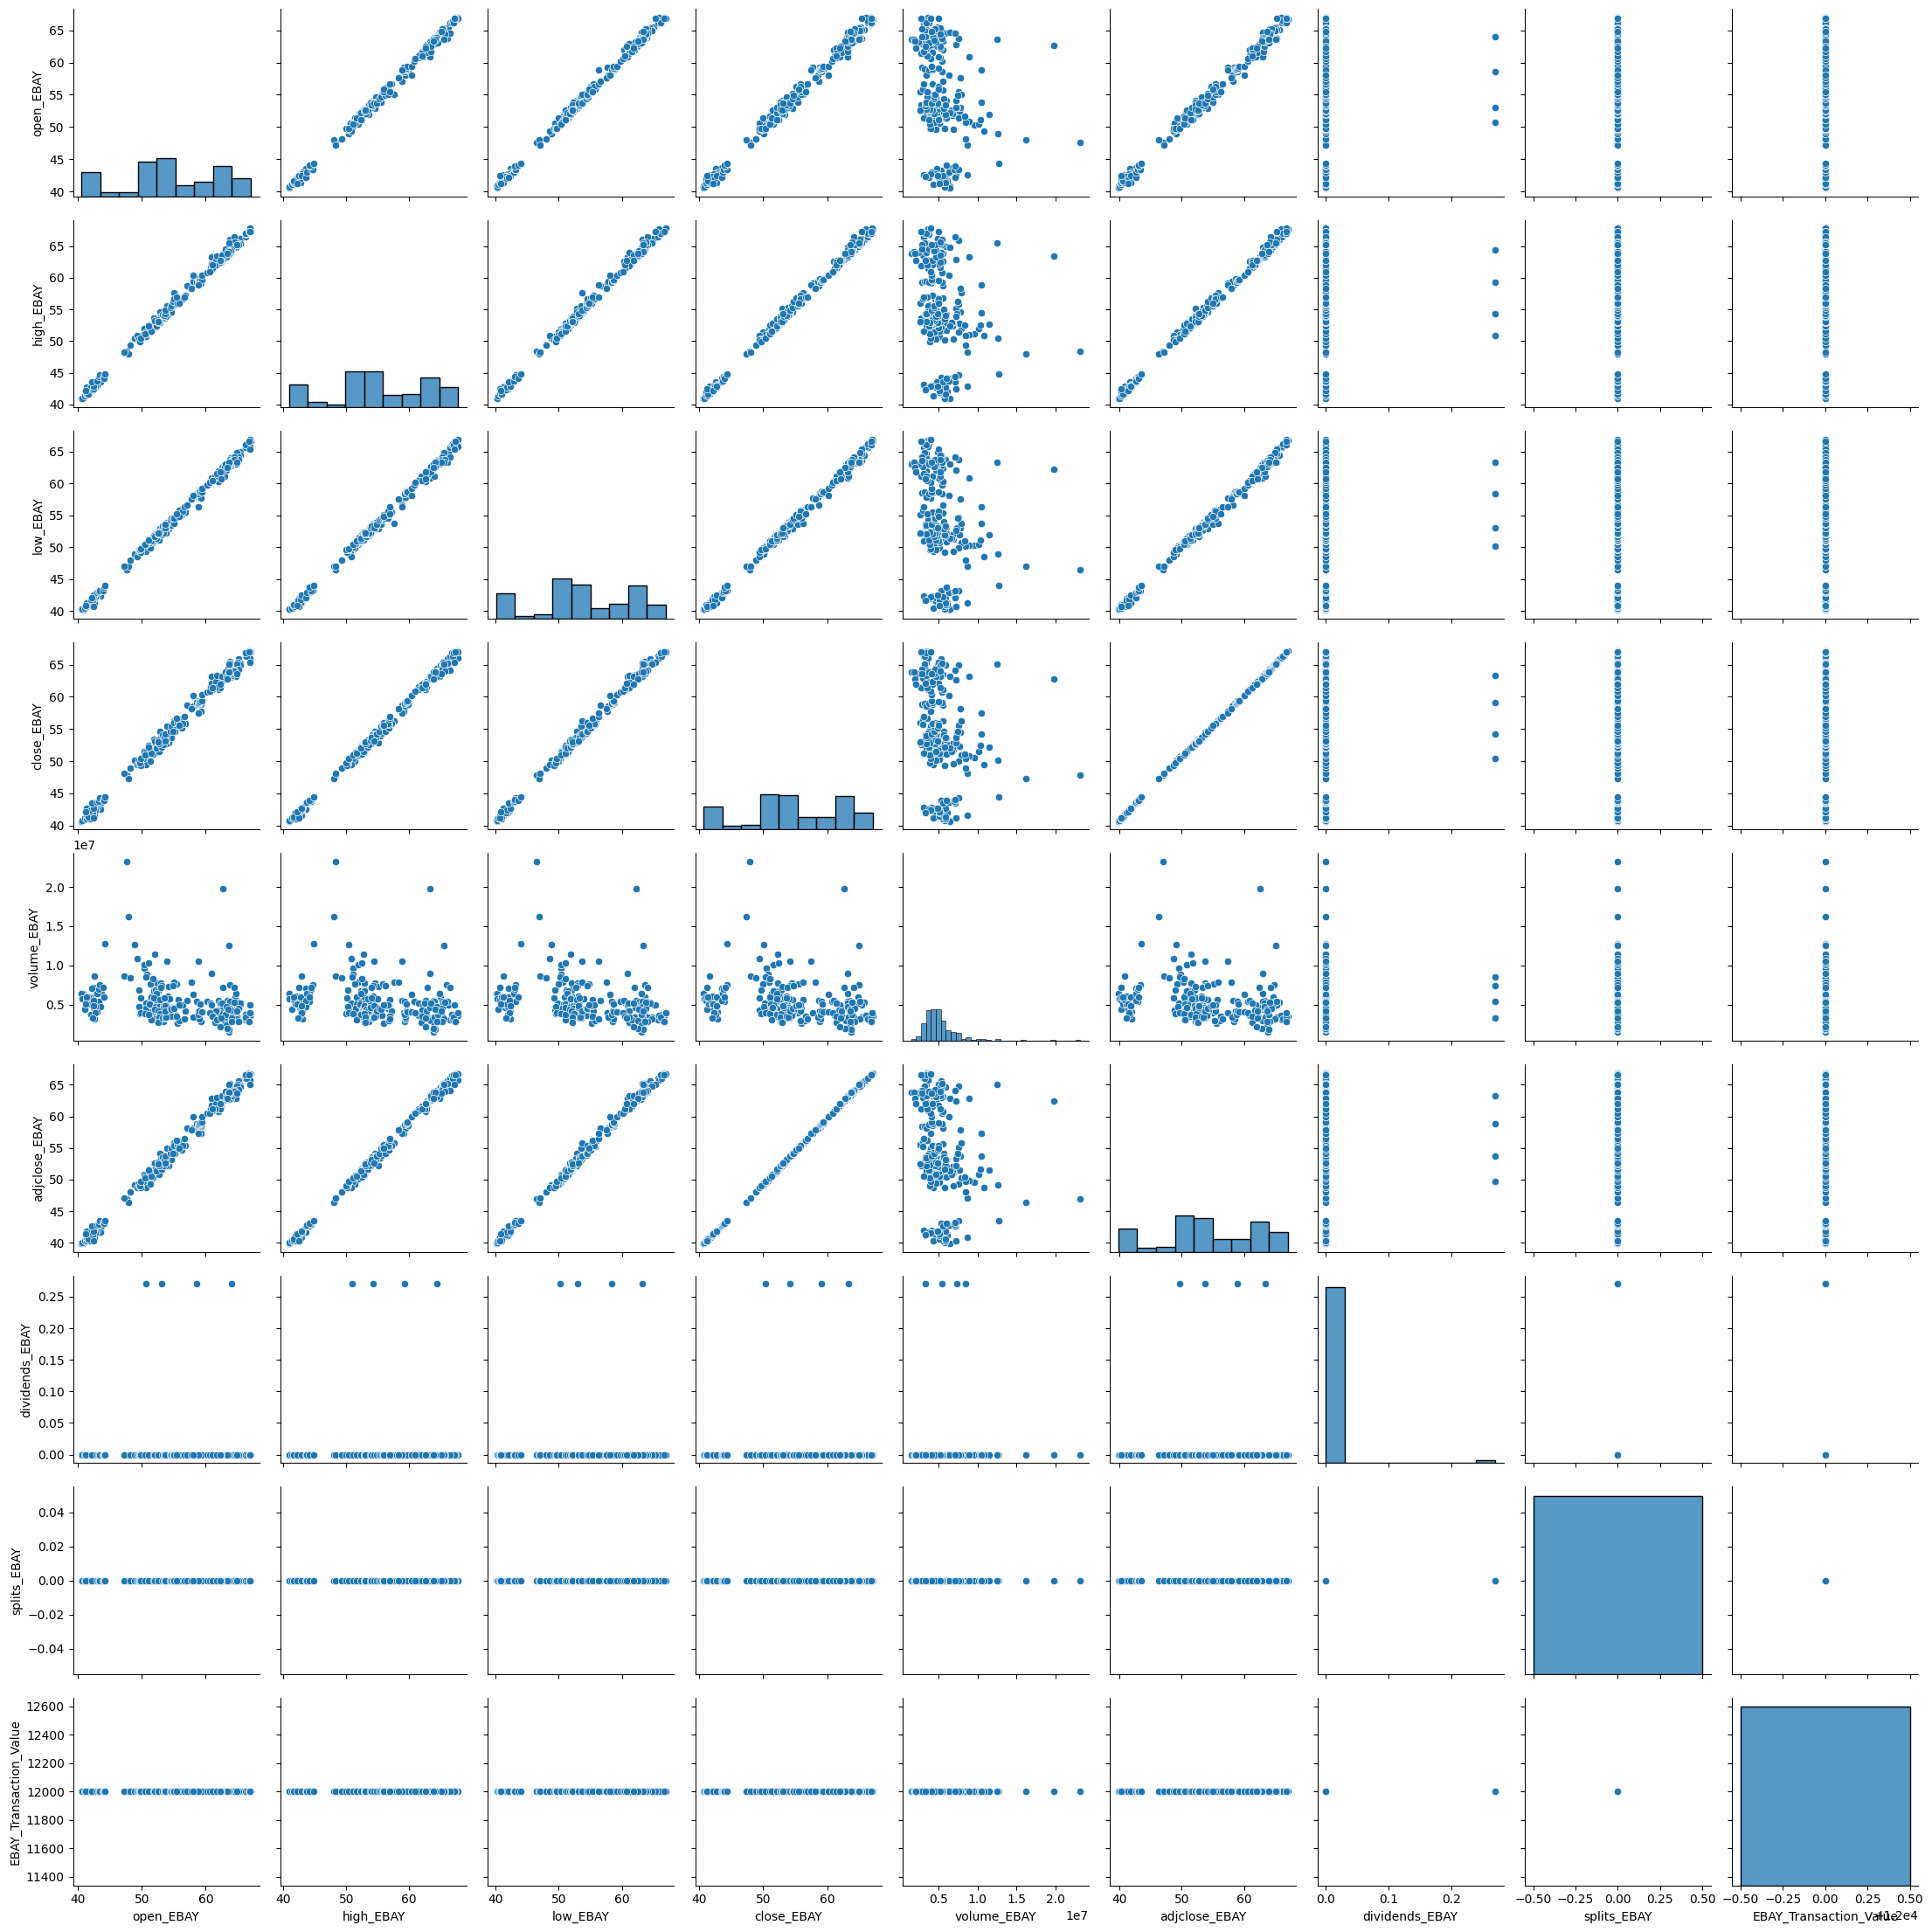

In [276]:
# Create a pairplot
sns.pairplot(df_Ebay)
plt.show()

## CISCO (CSCO)

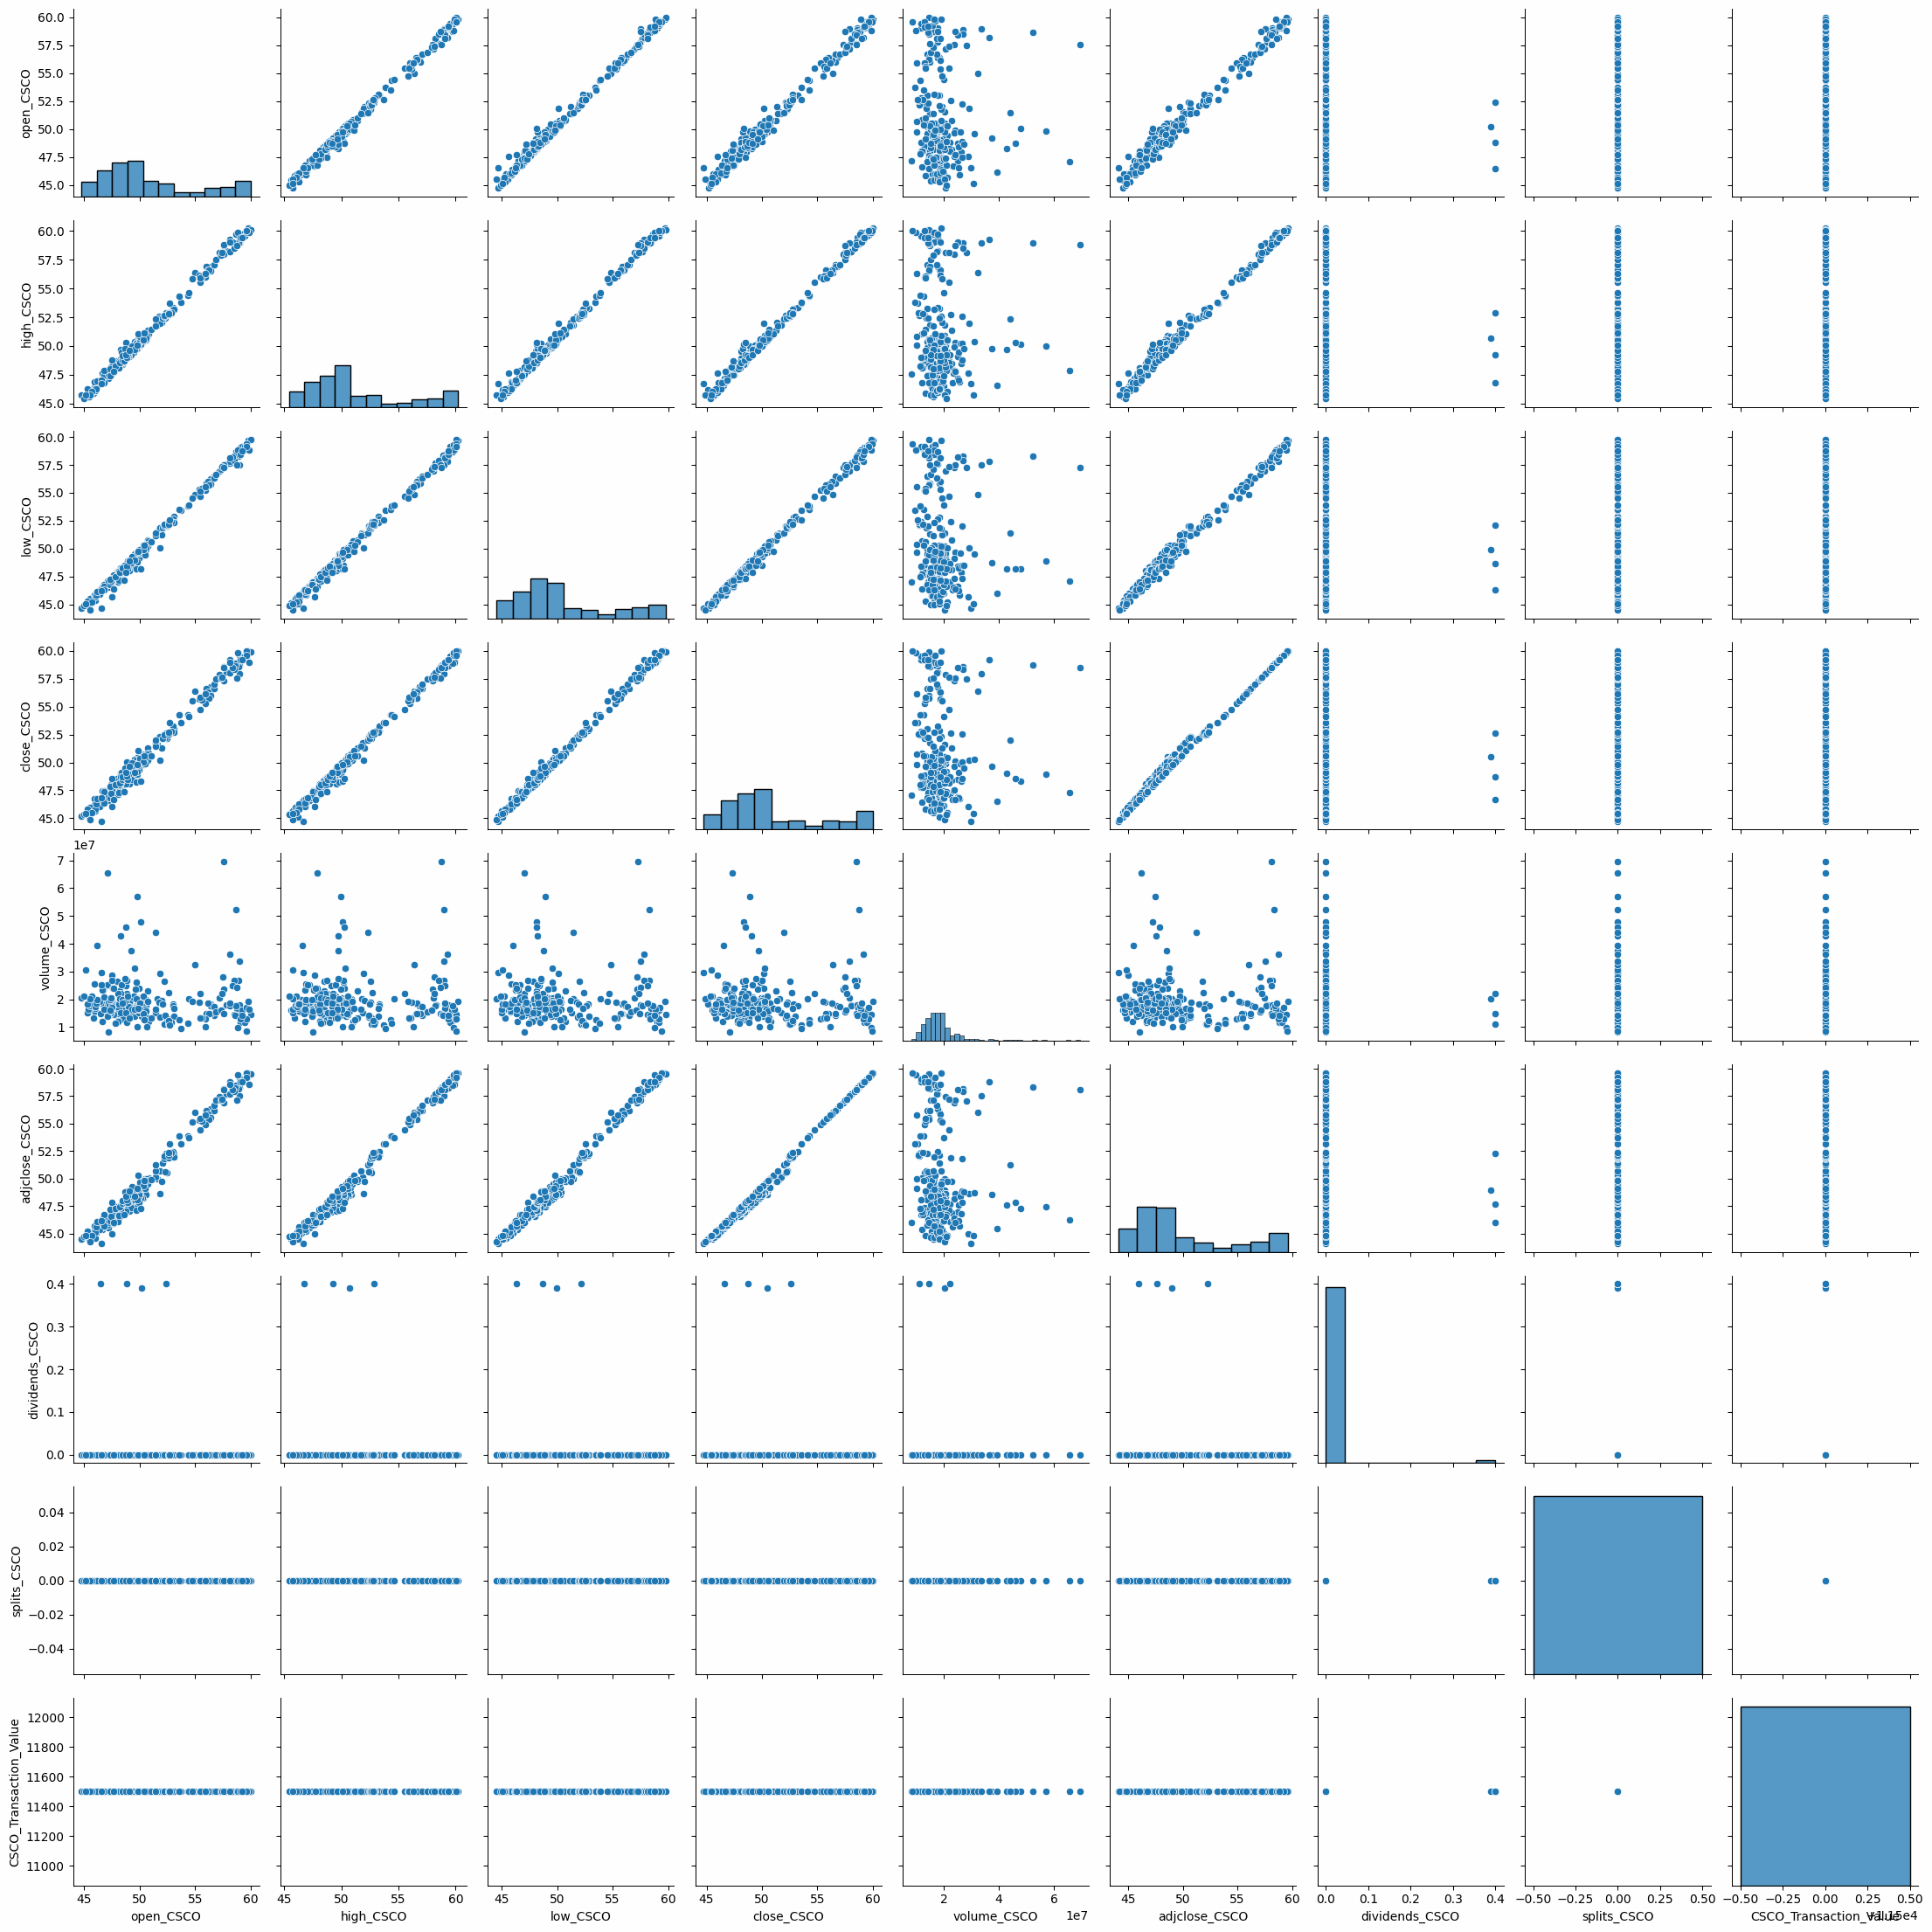

In [277]:
# Create a pairplot
sns.pairplot(df_CSCO)
plt.show()

## APPLIED MATERIALS (AMAT)

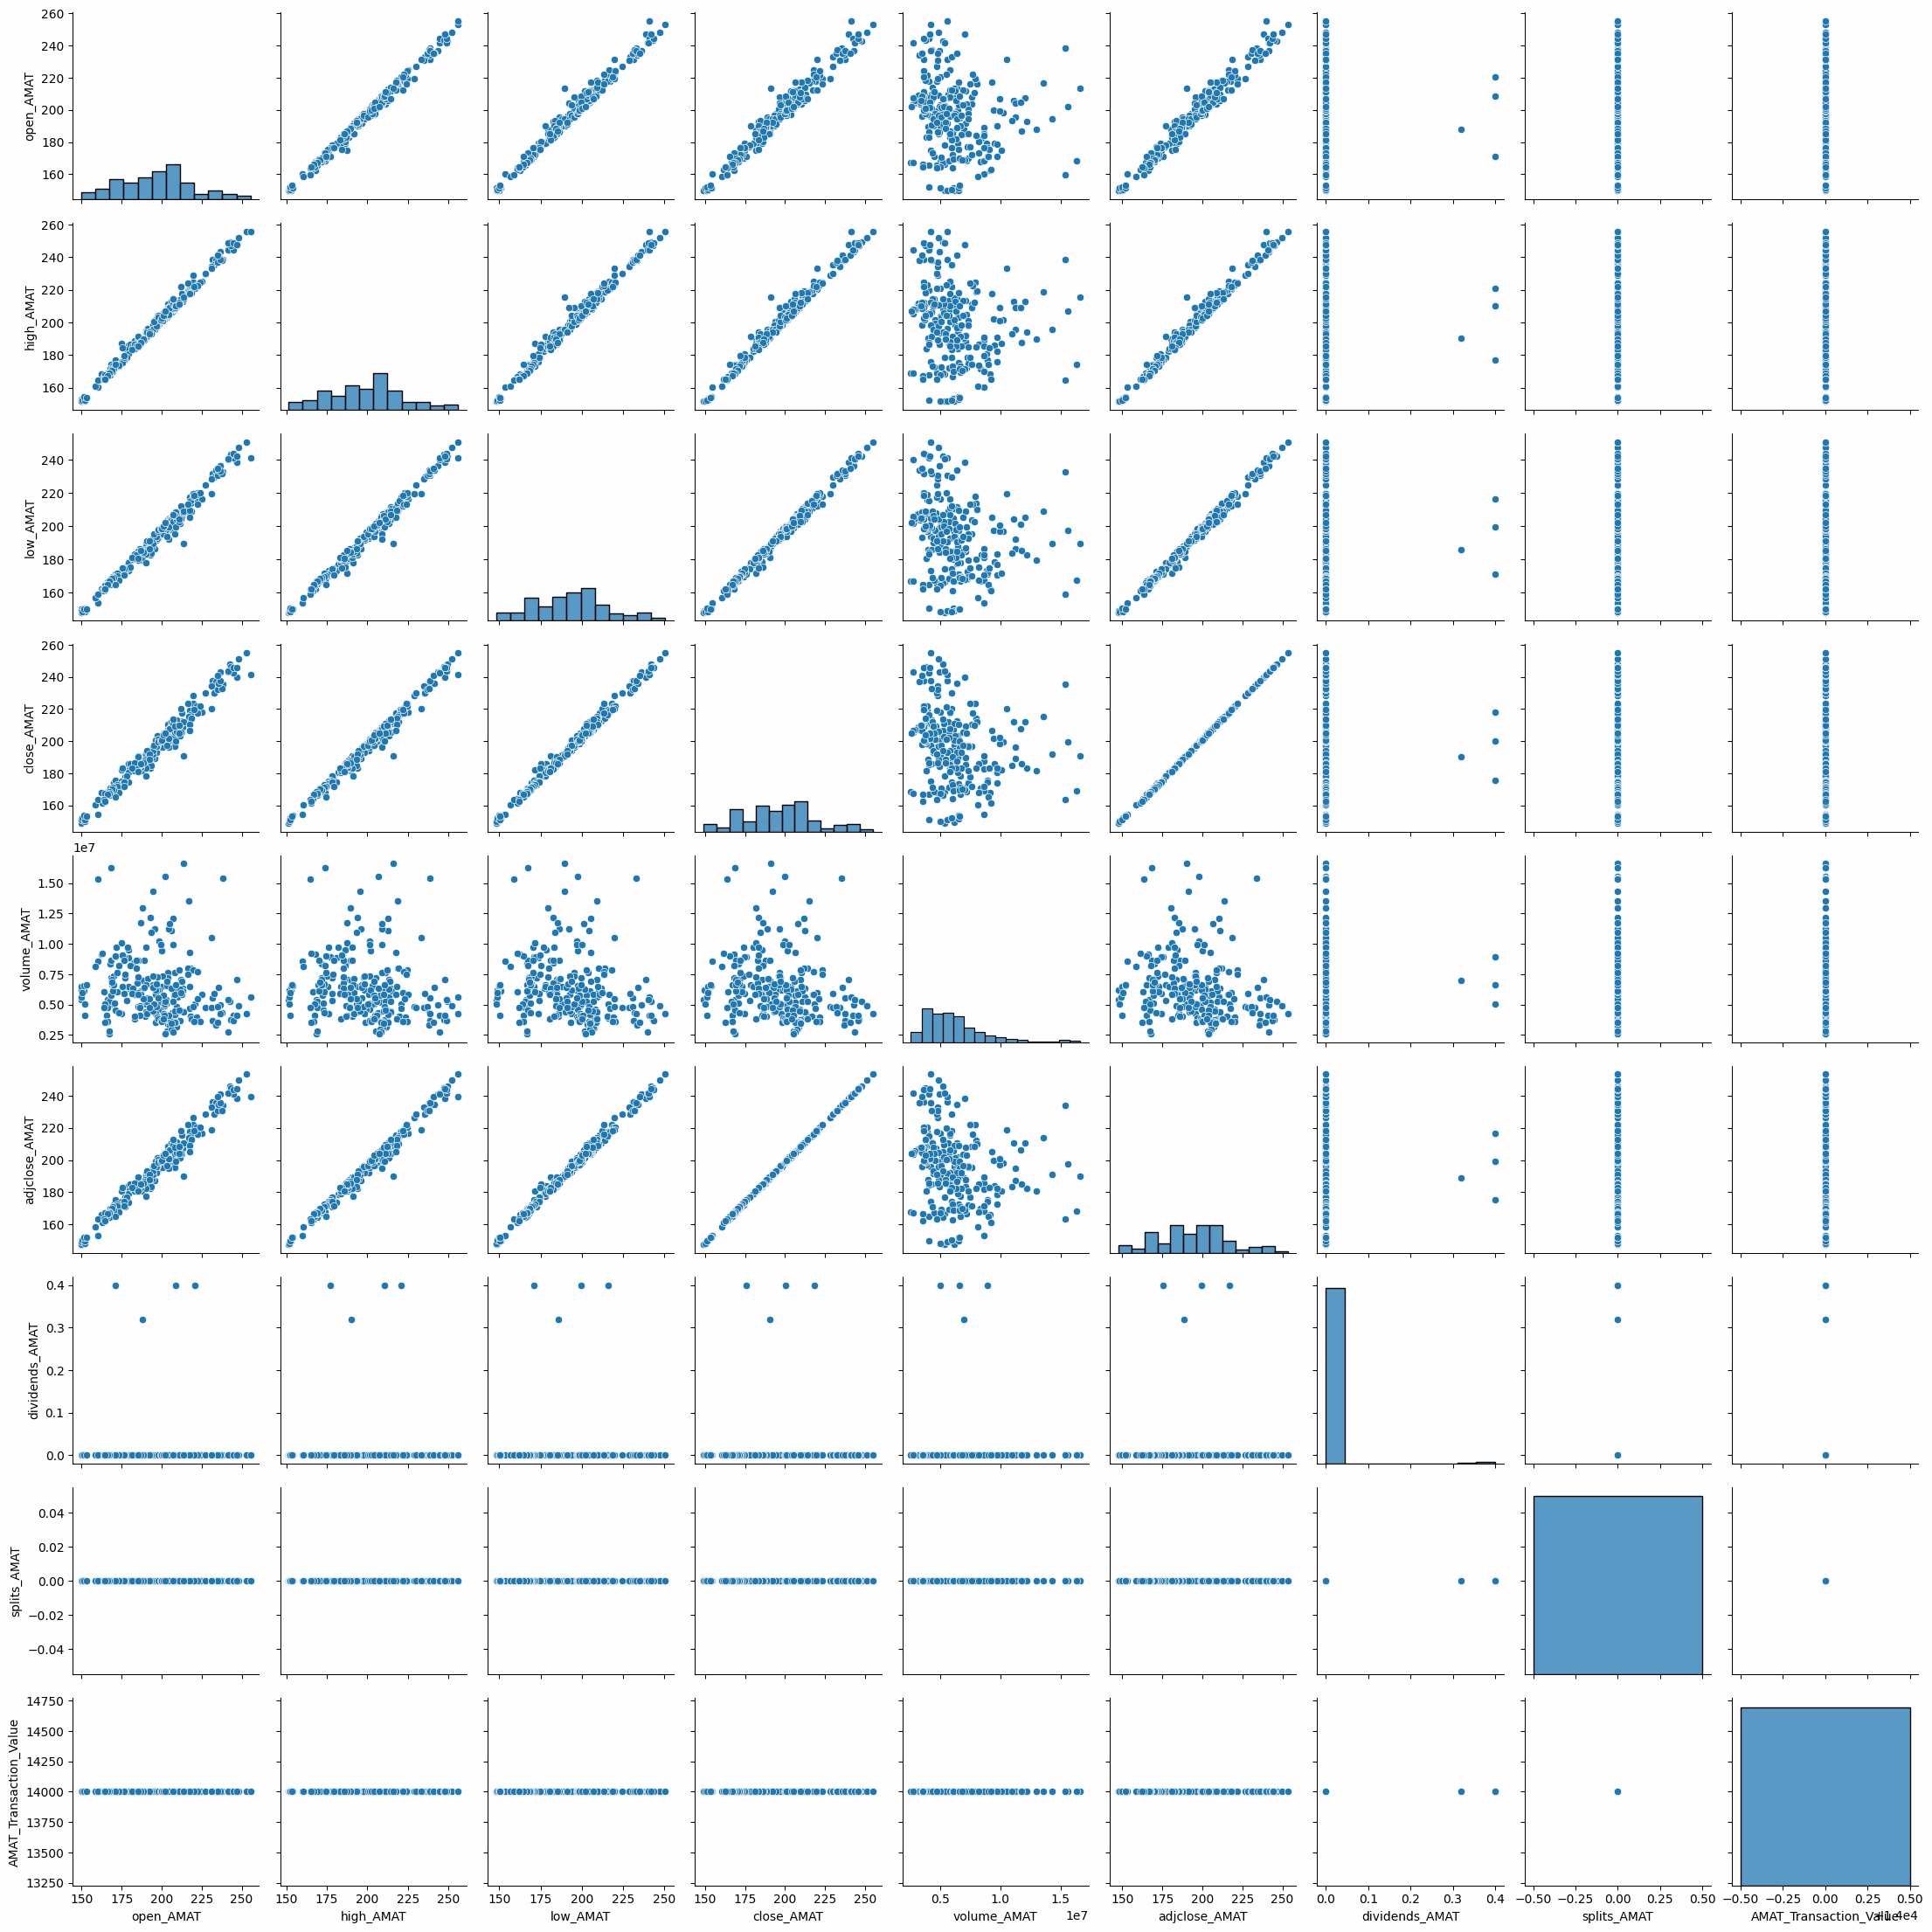

In [278]:
# Create a pairplot
sns.pairplot(df_AMAT)
plt.show()

## COMCAST (CMCSA)

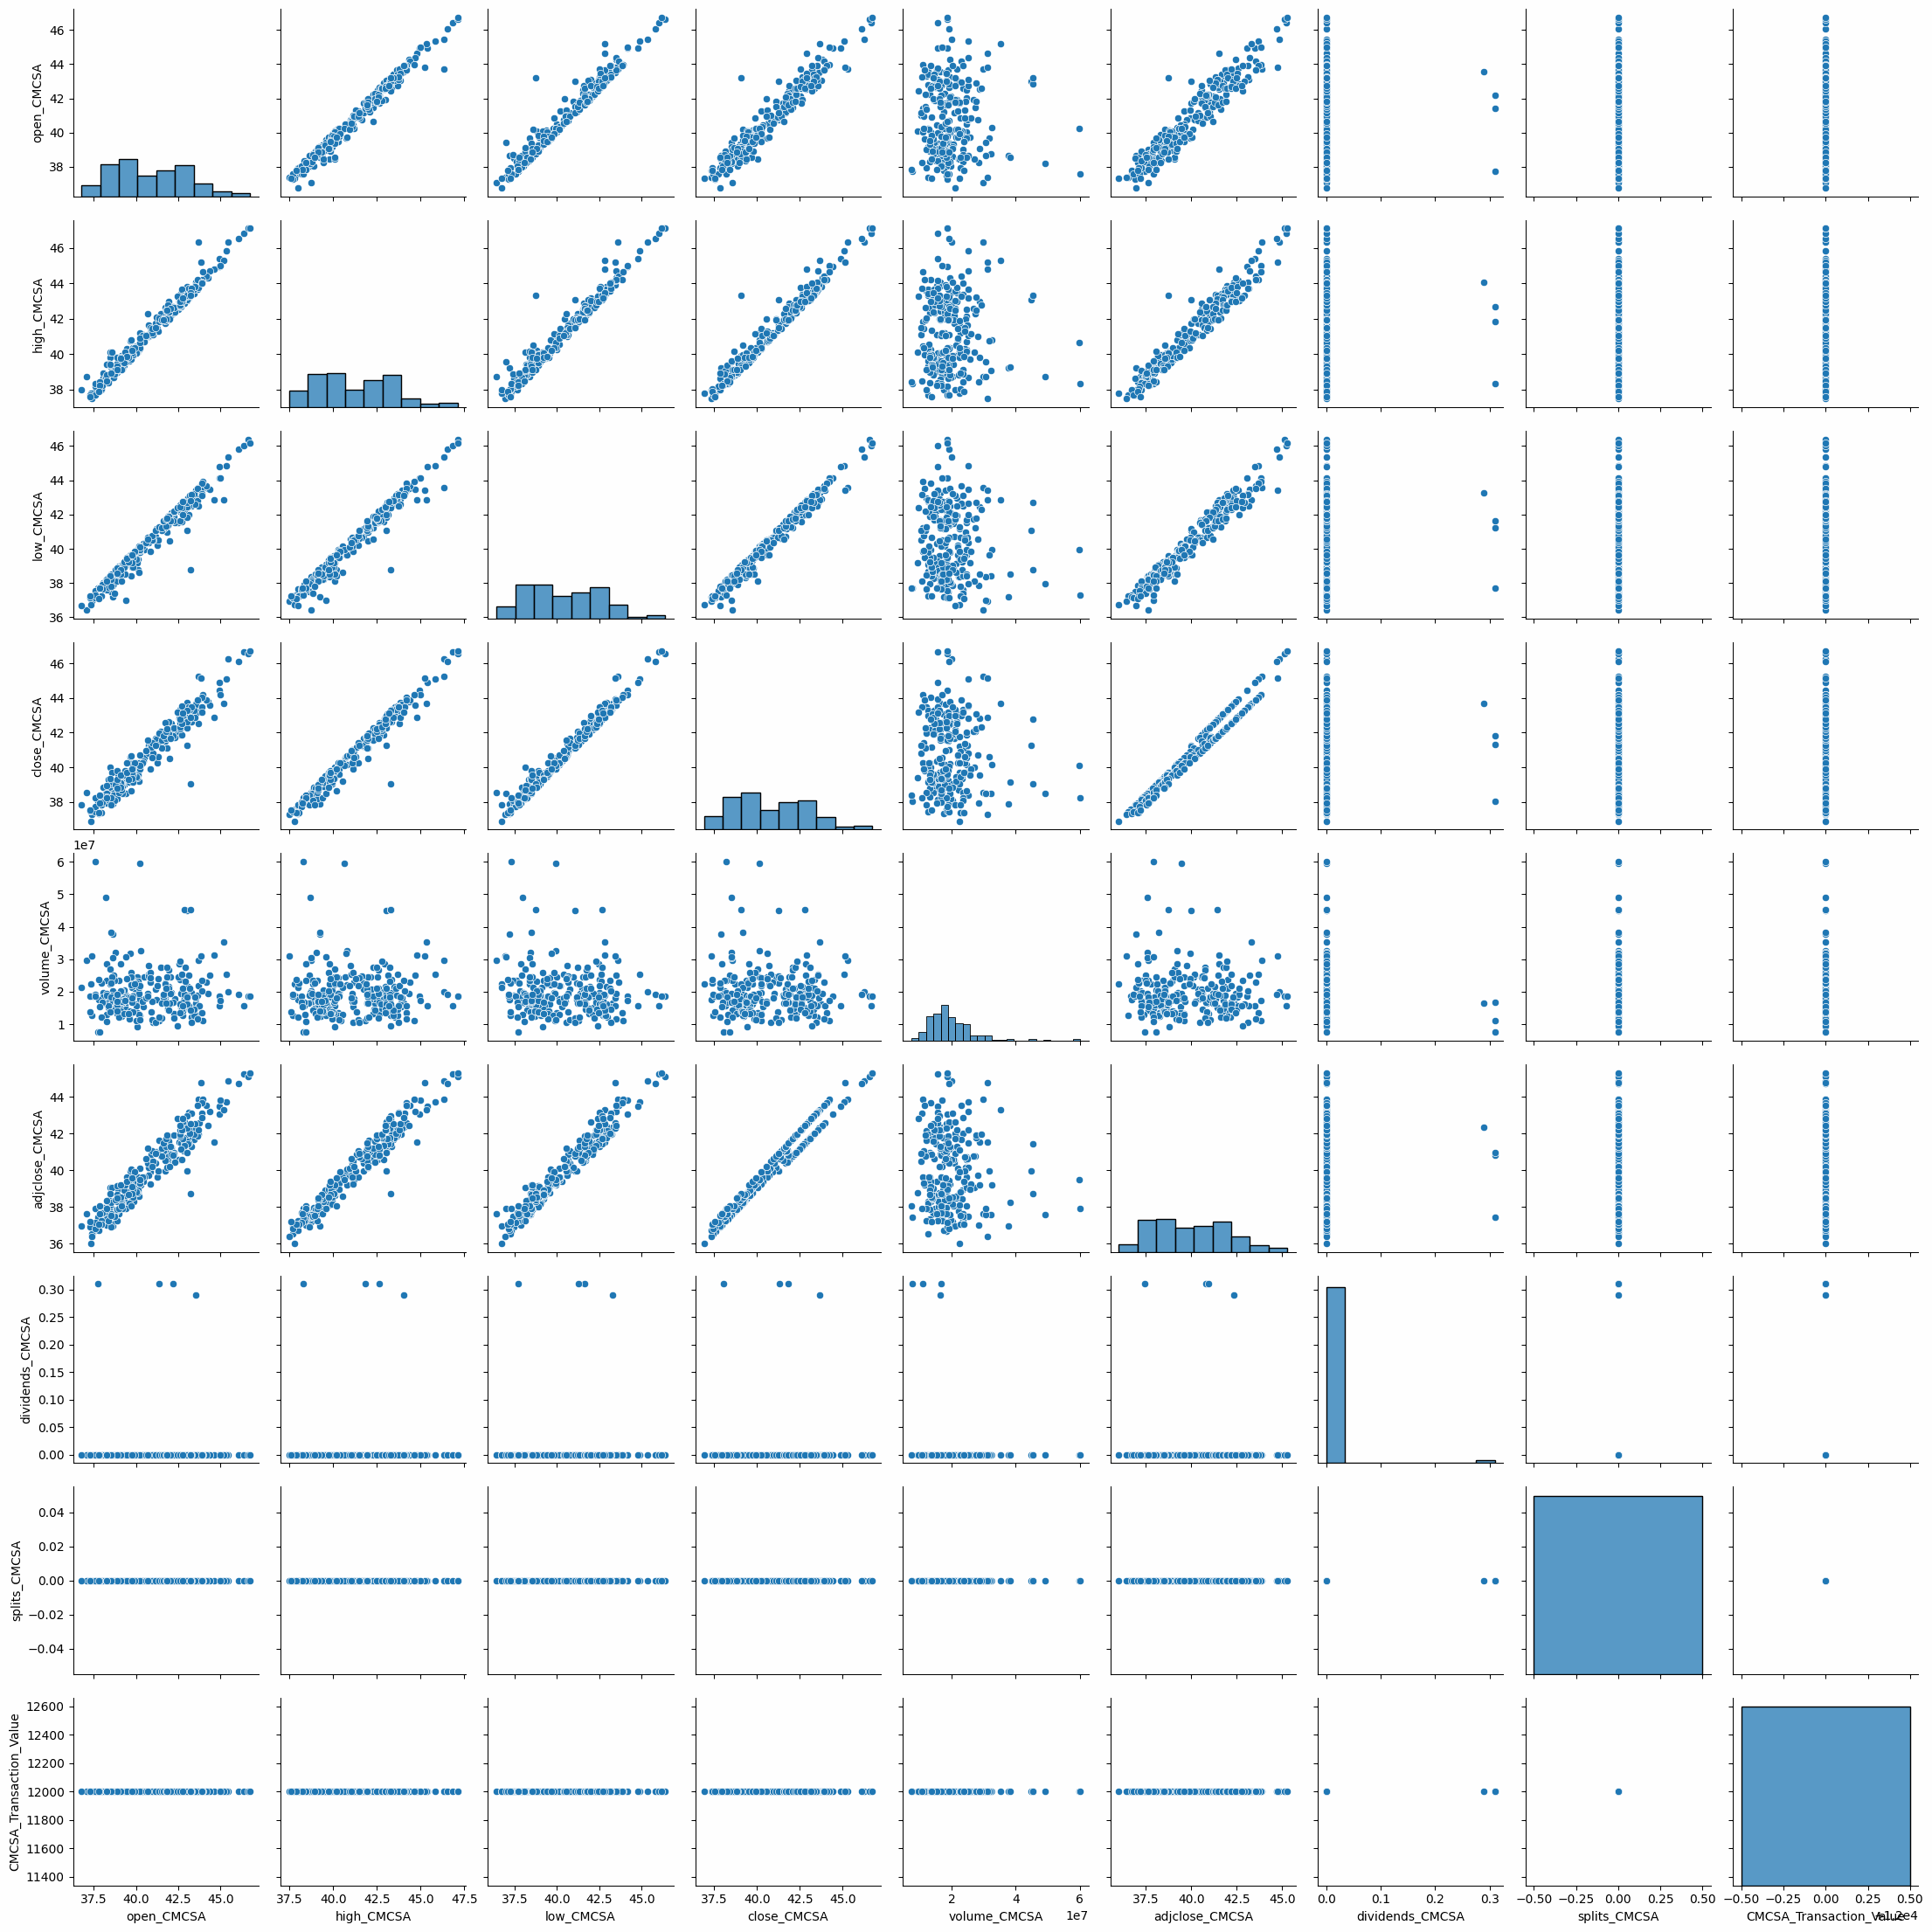

In [279]:
# Create a pairplot
sns.pairplot(df_CMCSA)
plt.show()

## MICROSOFT (MSFT)

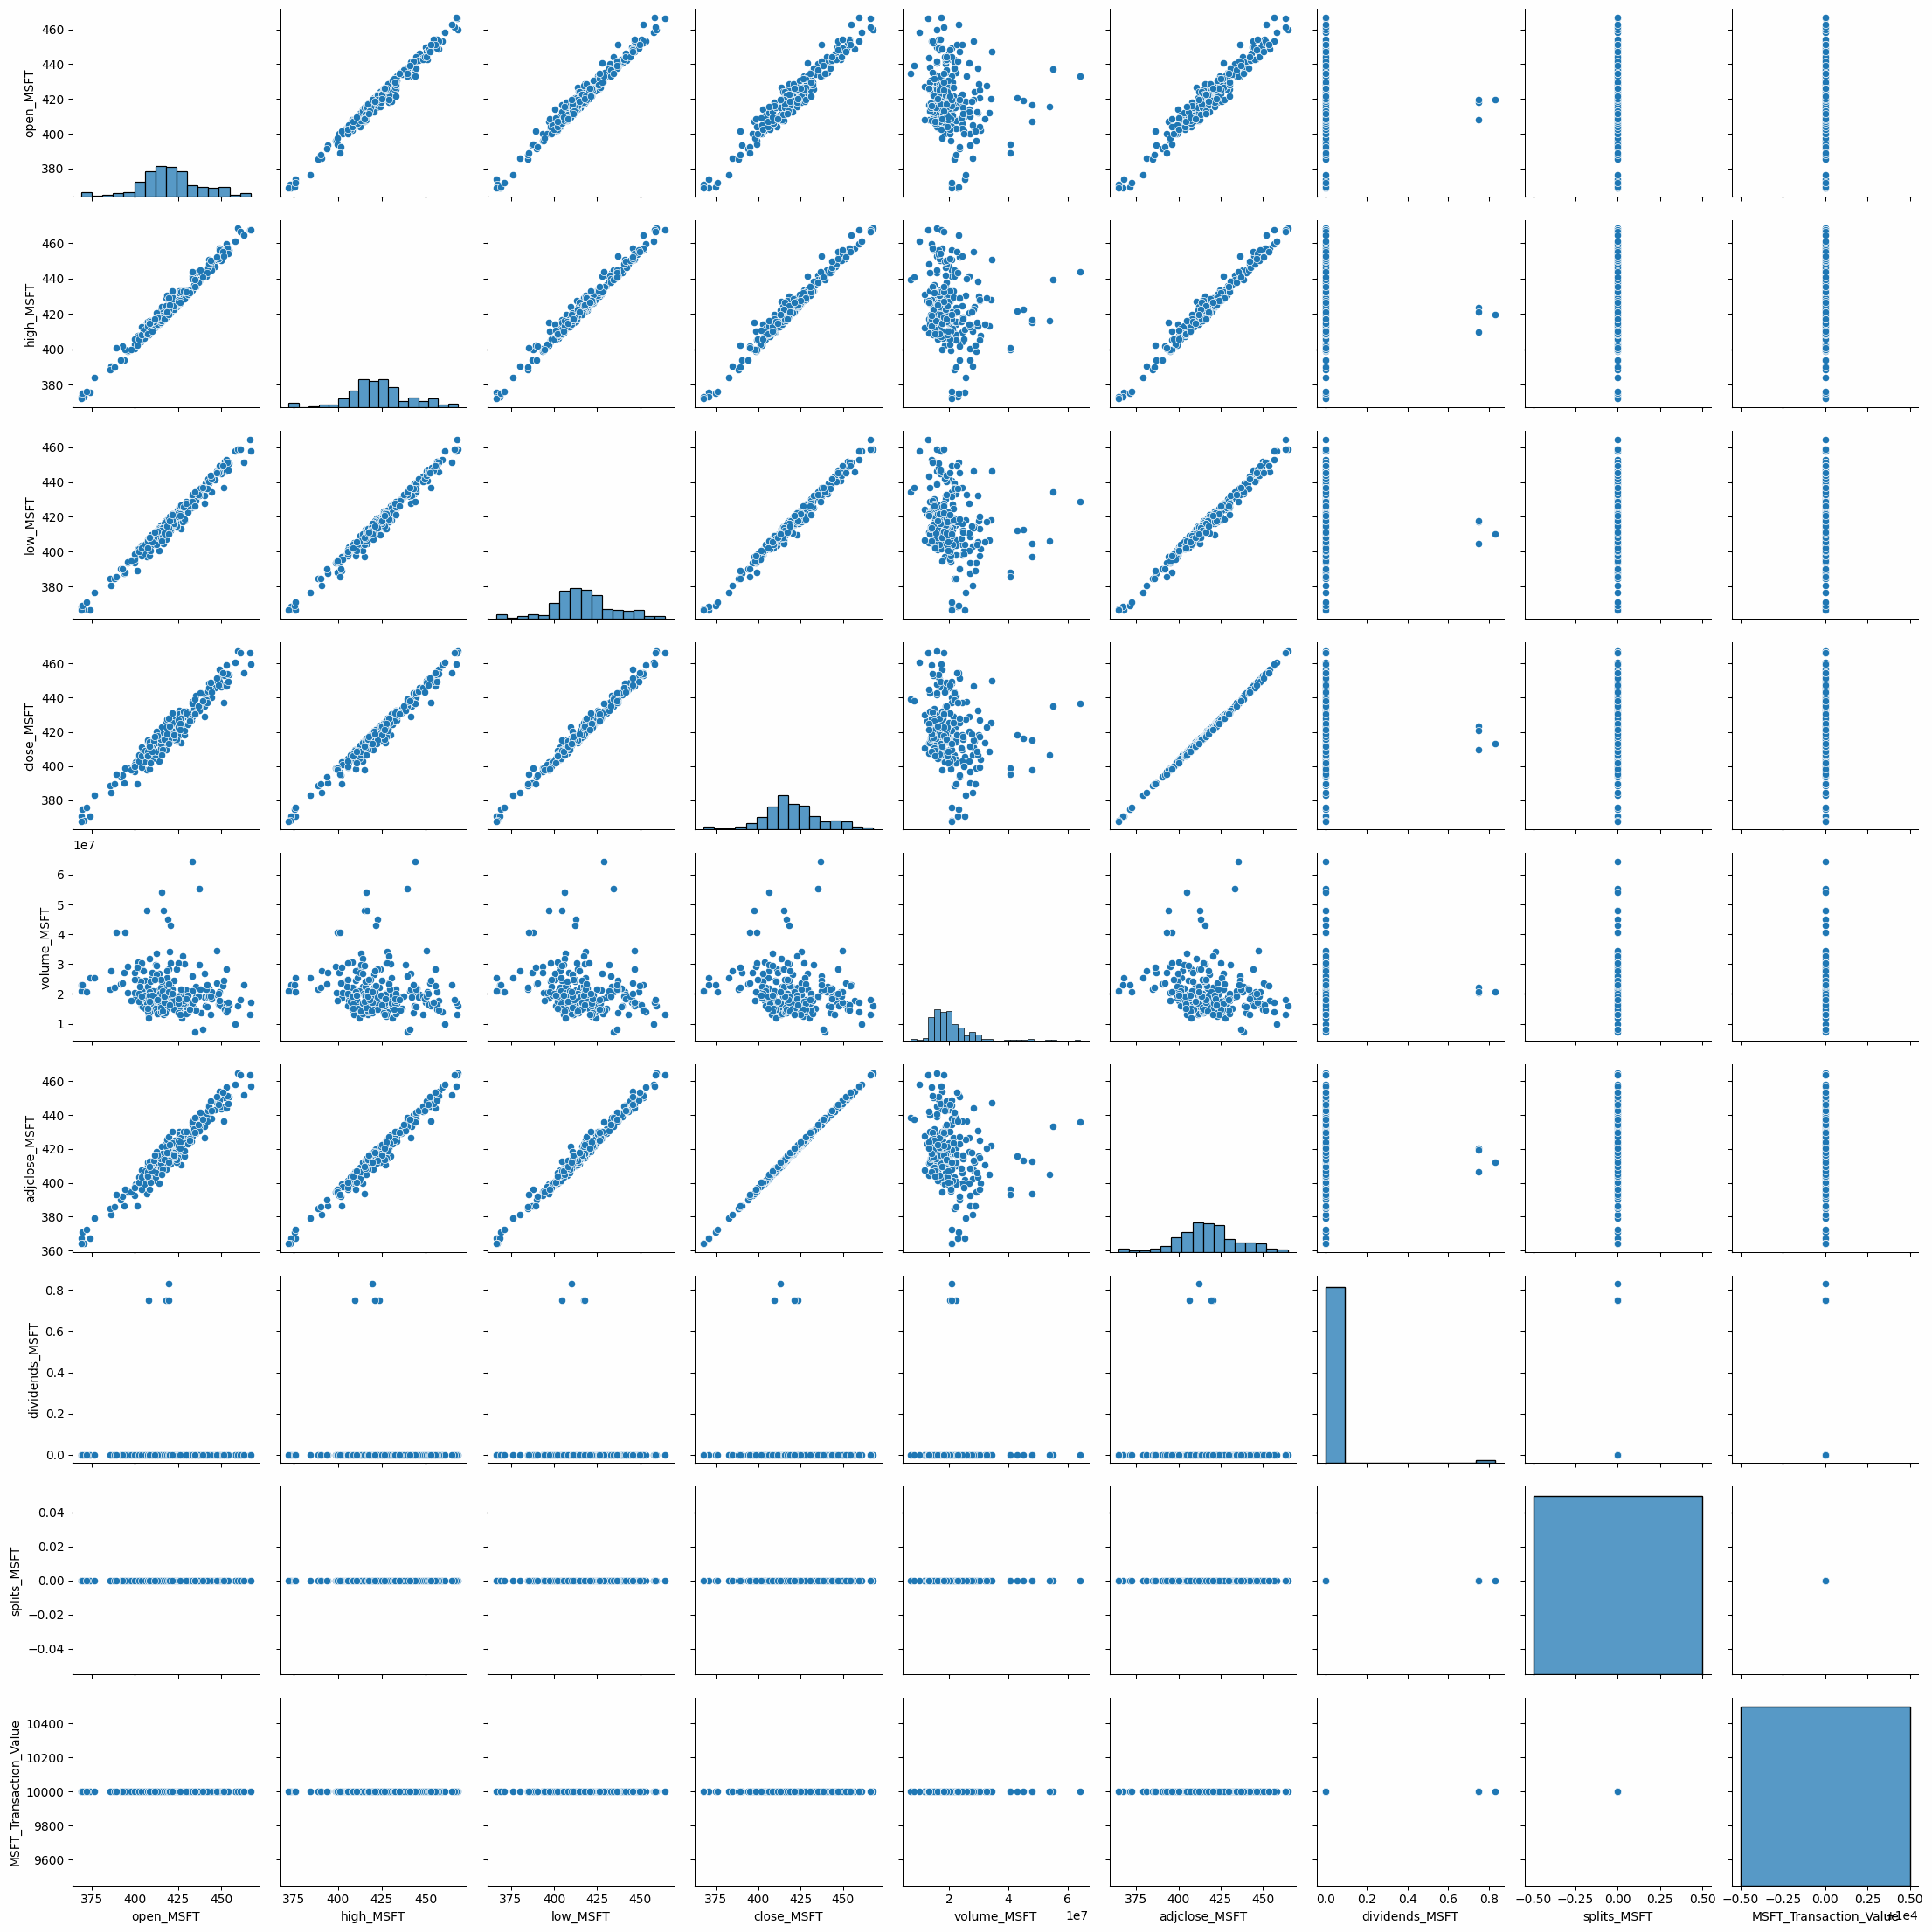

In [280]:
# Create a pairplot
sns.pairplot(df_MSFT)
plt.show()

## APPLE (AAPL)

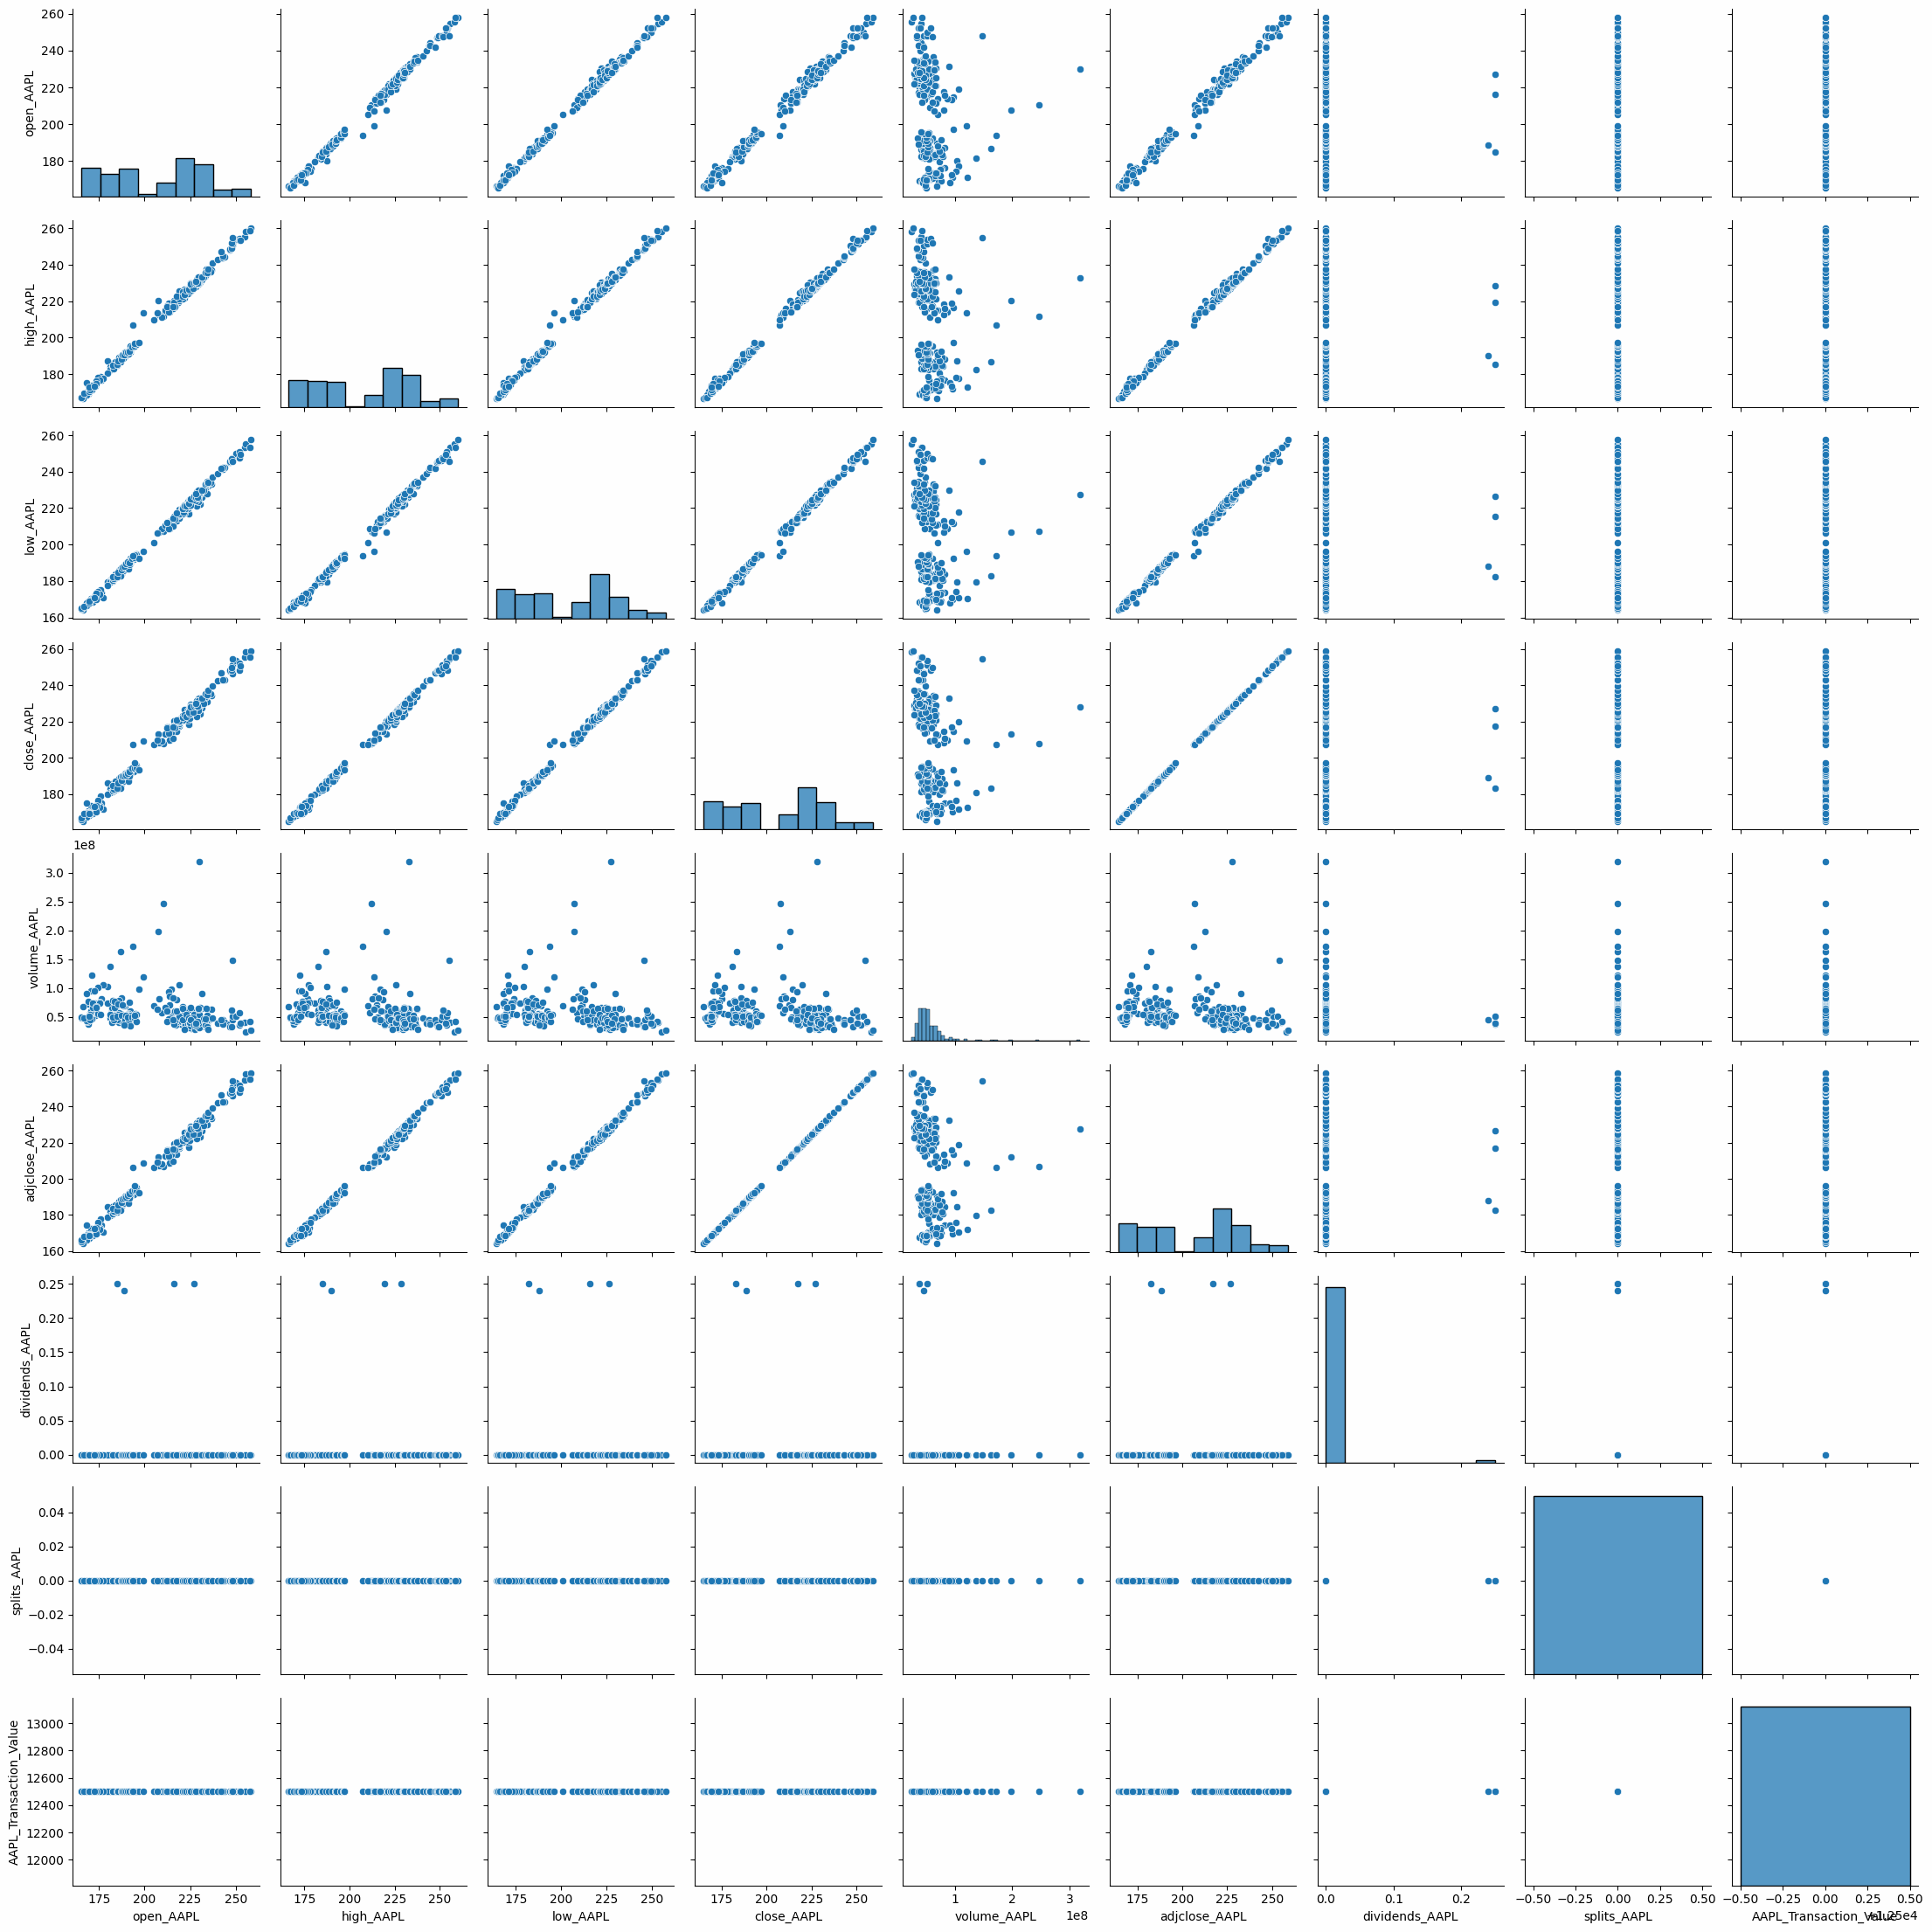

In [281]:
# Create a pairplot
sns.pairplot(df_AAPL)
plt.show()

# MODIFICATION

**Data Normalization and Standardization Explanation**

In this analysis, we are applying feature scaling techniques—Standardization and Normalization—to the numerical variables of each stock. These techniques help bring all features to a similar scale, ensuring that no single variable disproportionately influences analysis or modeling outcomes.

**Standardization (Z-score Scaling)**

We use StandardScaler to transform numerical variables so that they have:

* A mean of 0
* A standard deviation of 1

This transformation helps when working with models that assume normally distributed data, such as linear regression and principal component analysis.

**Normalization (Min-Max Scaling)**

We then apply MinMaxScaler, which scales values to a fixed range, typically [0,1]. This transformation is useful when:

Data has different ranges but needs to be compared directly.
Algorithms like neural networks or distance-based models (e.g., KNN) require bounded inputs.

By performing both standardization and normalization across all stock datasets, we ensure consistency in our data preprocessing, allowing for fair comparisons and accurate statistical analyses across different stock variables.

## SALESFORCE (CRM)

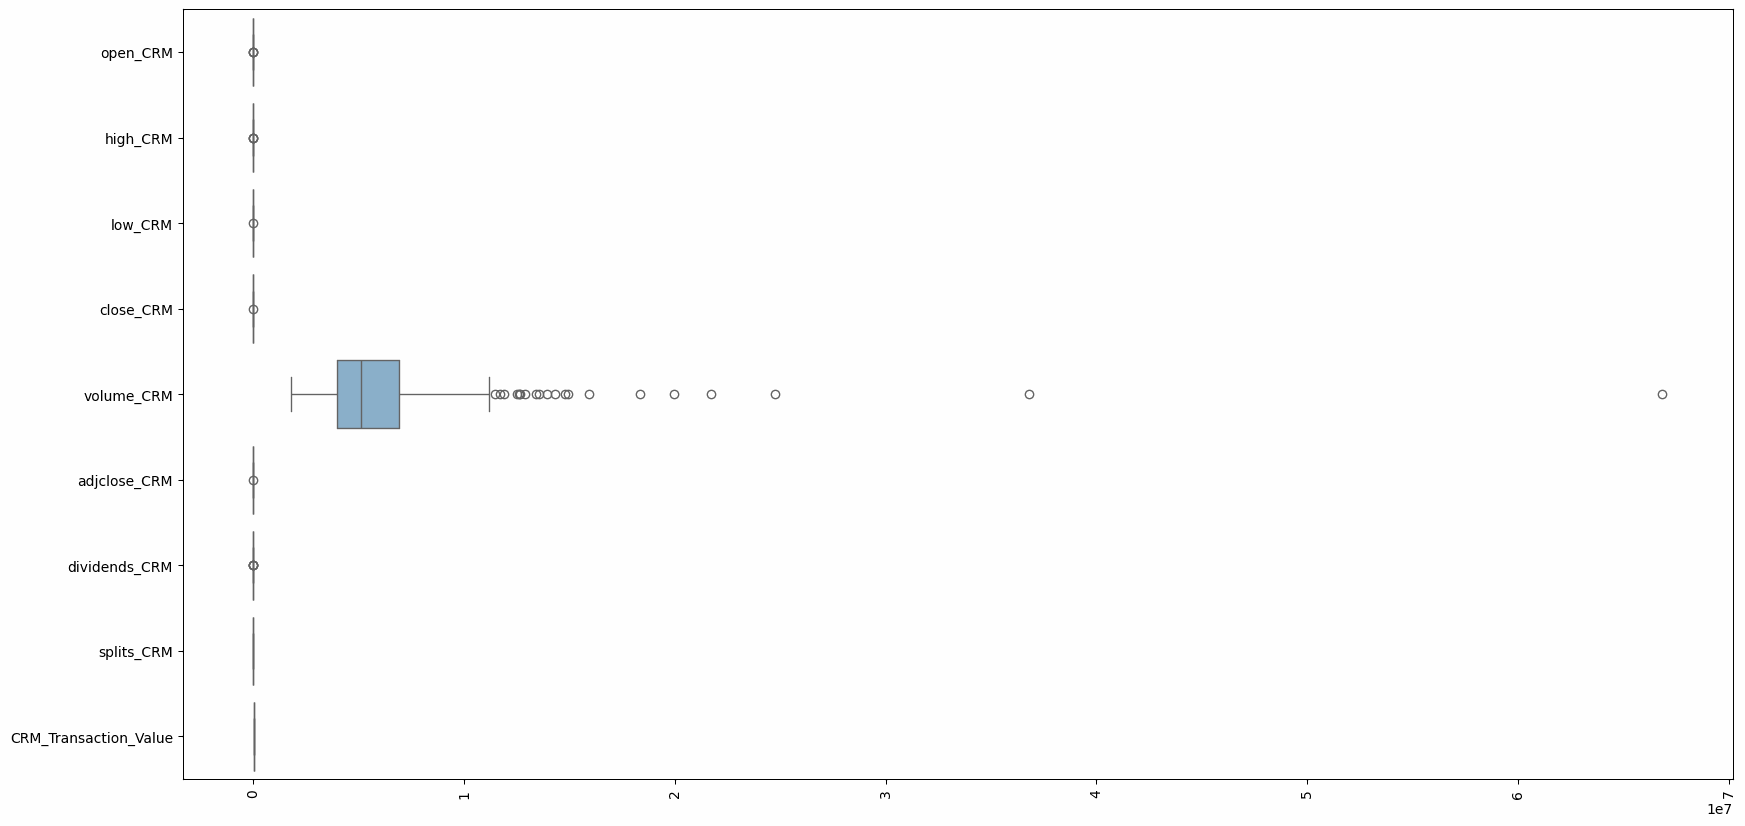

In [282]:
# Create one graph of all boxplots in CRM
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_CRM[num_cols_CRM], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [283]:
# Create StandardScaler and apply to numerical columns
scaler_CRM = StandardScaler()
scaled_values_CRM = scaler_CRM.fit_transform(df_CRM[num_cols_CRM])

# Create new DataFrame and display
df_scaled_CRM = pd.DataFrame(scaled_values_CRM, columns=num_cols_CRM)
display(df_scaled_CRM.head())

,open_CRM,high_CRM,low_CRM,close_CRM,volume_CRM,adjclose_CRM,dividends_CRM,splits_CRM,CRM_Transaction_Value
0,-0.703841,-0.801203,-0.831770,-0.853476,-0.305237,-0.866975,-0.127,0.0,0.0
1,-0.926465,-1.002809,-0.896159,-0.990540,-0.238960,-1.002782,-0.127,0.0,0.0
2,-0.979275,-1.050690,-0.958295,-1.009709,-0.352117,-1.021776,-0.127,0.0,0.0
3,-0.998881,-1.010684,-0.947670,-1.013544,-0.503824,-1.025575,-0.127,0.0,0.0
4,-0.967258,-0.769702,-0.908393,-0.702036,0.045916,-0.716922,-0.127,0.0,0.0


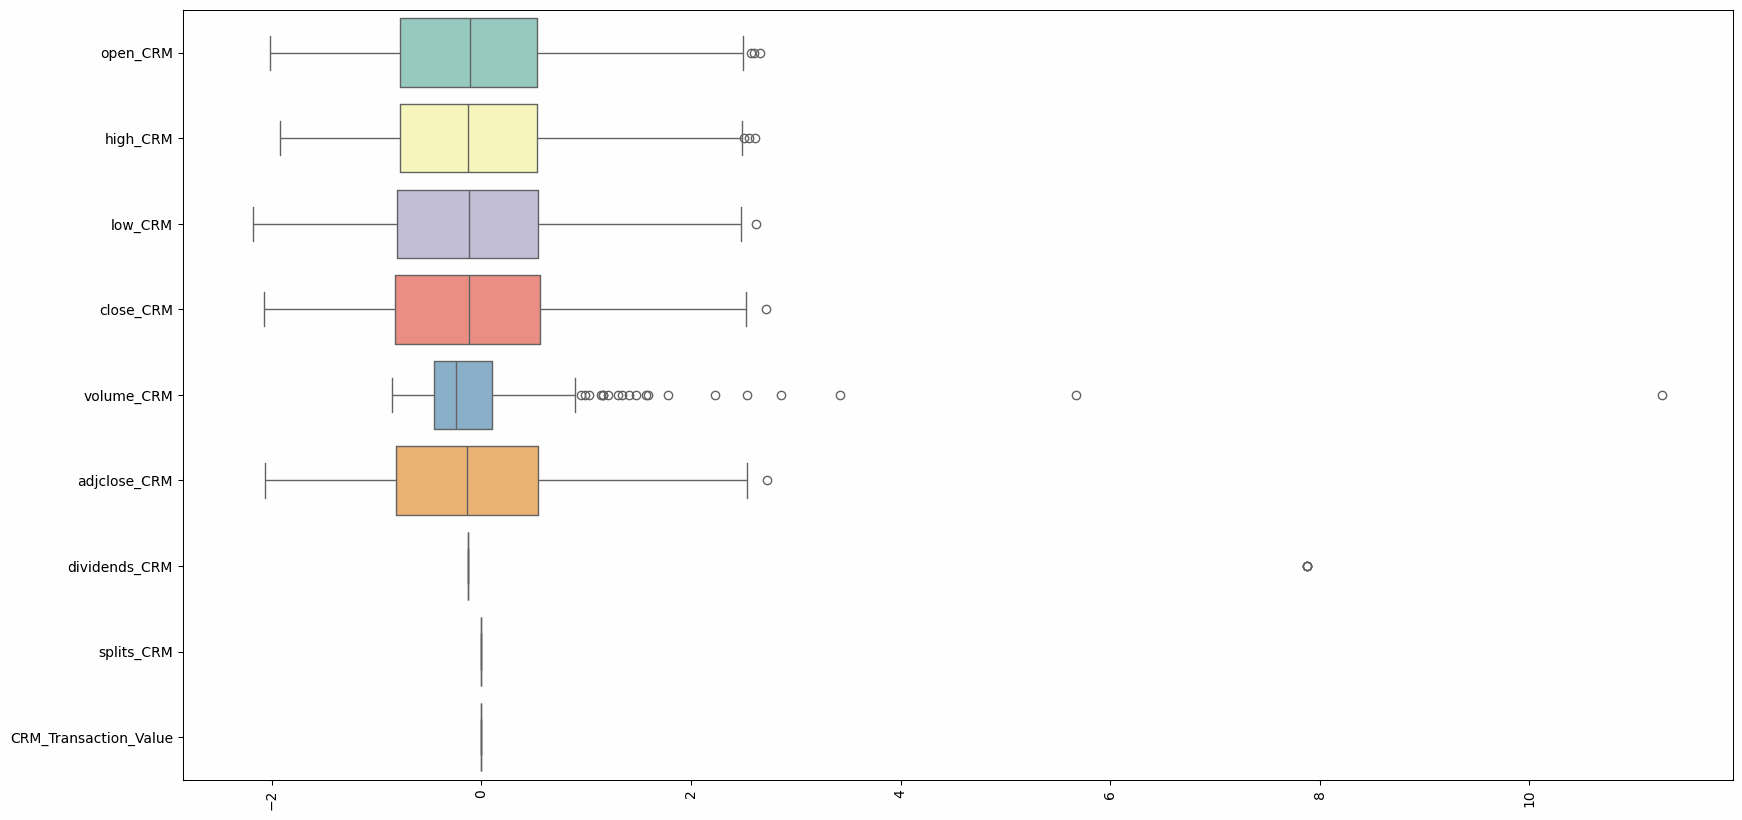

In [284]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_CRM[num_cols_CRM], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [285]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_CRM[num_cols_CRM], df_scaled_CRM))
print("MSE:", mean_squared_error(df_CRM[num_cols_CRM], df_scaled_CRM))
print("RMSE:", np.sqrt(mean_squared_error(df_CRM[num_cols_CRM], df_scaled_CRM)))
print("Residuals:", df_CRM[num_cols_CRM] - df_scaled_CRM)

R2, MSE, RMSE, and Residuals
R2: -84.95530302278053
MSE: 7722526891091.56
RMSE: 2778943.4846883016
Residuals:             open_CRM  high_CRM  low_CRM  close_CRM  volume_CRM  adjclose_CRM  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251       

### NORMALIZING

In [286]:
# Create MinMaxScaler and apply to numerical columns
scaler_CRM = MinMaxScaler()
scaled_values_CRM = scaler_CRM.fit_transform(df_CRM[num_cols_CRM])

# Create new DataFrame and display
df_scaled_CRM = pd.DataFrame(scaled_values_CRM, columns=num_cols_CRM)
display(df_scaled_CRM.head())

,open_CRM,high_CRM,low_CRM,close_CRM,volume_CRM,adjclose_CRM,dividends_CRM,splits_CRM,CRM_Transaction_Value
0,0.280501,0.246473,0.280166,0.254371,0.045048,0.250219,0.0,0.0,0.0
1,0.232837,0.202001,0.266752,0.225744,0.050517,0.221848,0.0,0.0,0.0
2,0.221530,0.191439,0.253806,0.221740,0.041181,0.217880,0.0,0.0,0.0
3,0.217332,0.200264,0.256020,0.220940,0.028664,0.217086,0.0,0.0,0.0
4,0.224103,0.253422,0.264203,0.286000,0.074020,0.281567,0.0,0.0,0.0


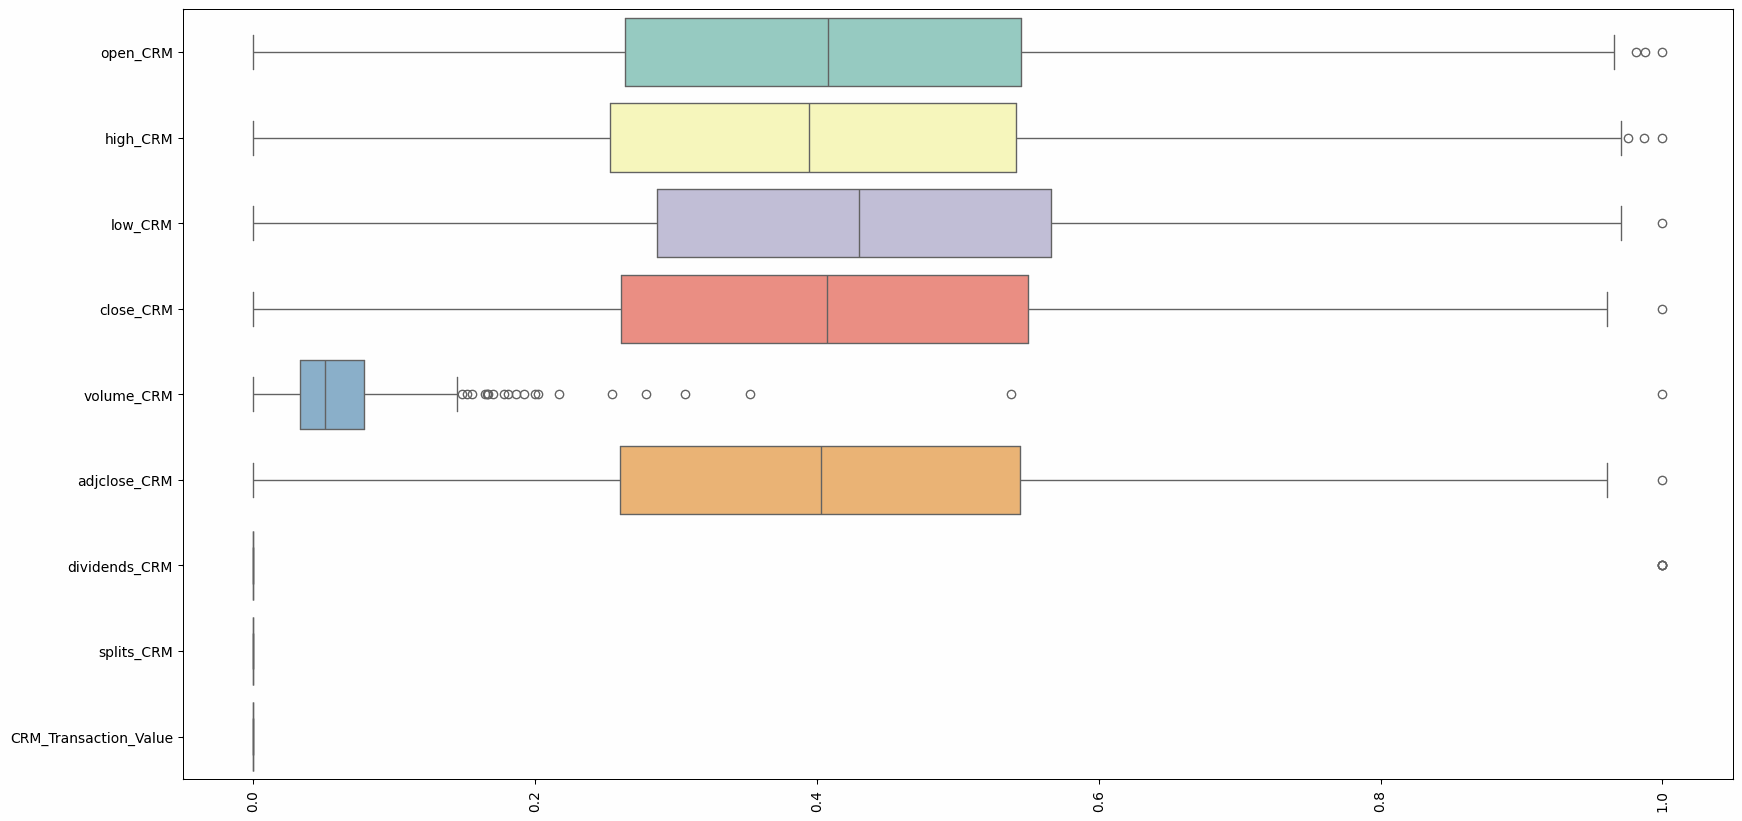

In [287]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_CRM[num_cols_CRM], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [288]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_CRM[num_cols_CRM], df_scaled_CRM))
print("MSE:", mean_squared_error(df_CRM[num_cols_CRM], df_scaled_CRM))
print("RMSE:", np.sqrt(mean_squared_error(df_CRM[num_cols_CRM], df_scaled_CRM)))
print("Residuals:", df_CRM[num_cols_CRM] - df_scaled_CRM)

R2, MSE, RMSE, and Residuals
R2: -44.97508158200386
MSE: 7722527885662.429
RMSE: 2778943.6636359557
Residuals:             open_CRM  high_CRM  low_CRM  close_CRM  volume_CRM  adjclose_CRM  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251      

## NVIDA (NVDA)

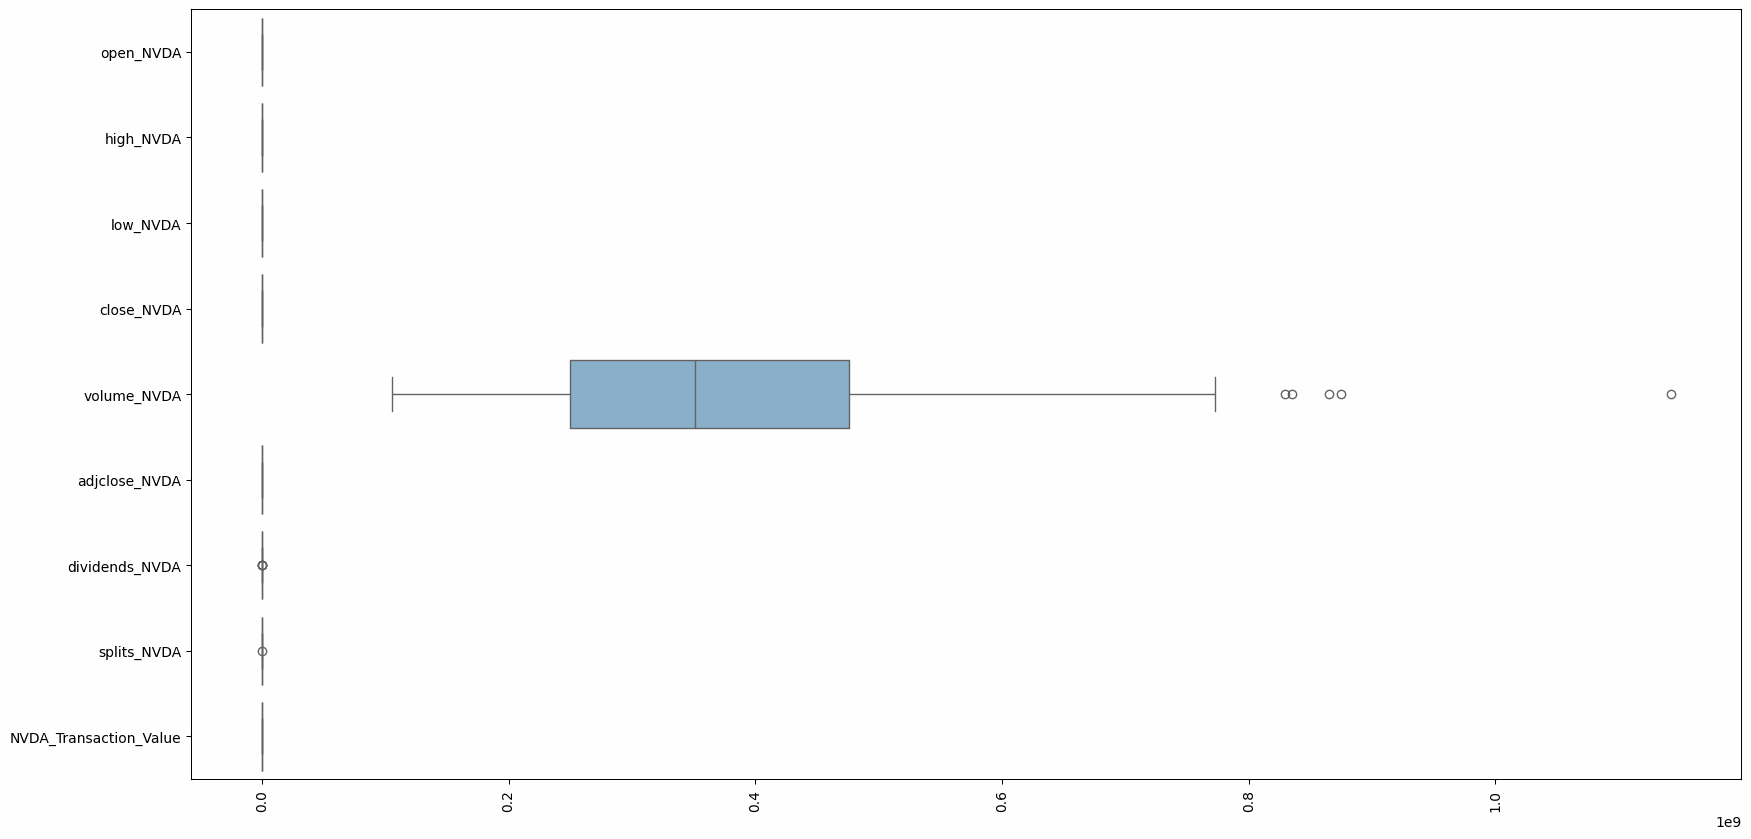

In [289]:
# Create one graph of all boxplots in NVDA
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_NVDA[num_cols_NVDA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZATION

In [290]:
# Create StandardScaler and apply to numerical columns
scaler_NVDA = StandardScaler()
scaled_values_NVDA = scaler_NVDA.fit_transform(df_NVDA[num_cols_NVDA])

# Create new DataFrame and display
df_scaled_NVDA = pd.DataFrame(scaled_values_NVDA, columns=num_cols_NVDA)
display(df_scaled_NVDA.head())

,open_NVDA,high_NVDA,low_NVDA,close_NVDA,volume_NVDA,adjclose_NVDA,dividends_NVDA,splits_NVDA,NVDA_Transaction_Value
0,-2.165083,-2.211493,-2.188149,-2.217436,0.209845,-2.217072,-0.12137,-0.063119,0.0
1,-2.230011,-2.252065,-2.198517,-2.239701,-0.349462,-2.239328,-0.12137,-0.063119,0.0
2,-2.219602,-2.240525,-2.191429,-2.223755,-0.438355,-2.223389,-0.12137,-0.063119,0.0
3,-2.193948,-2.202290,-2.161342,-2.182906,0.233274,-2.182556,-0.12137,-0.063119,0.0
4,-2.155190,-2.102667,-2.117116,-2.065599,1.641297,-2.065297,-0.12137,-0.063119,0.0


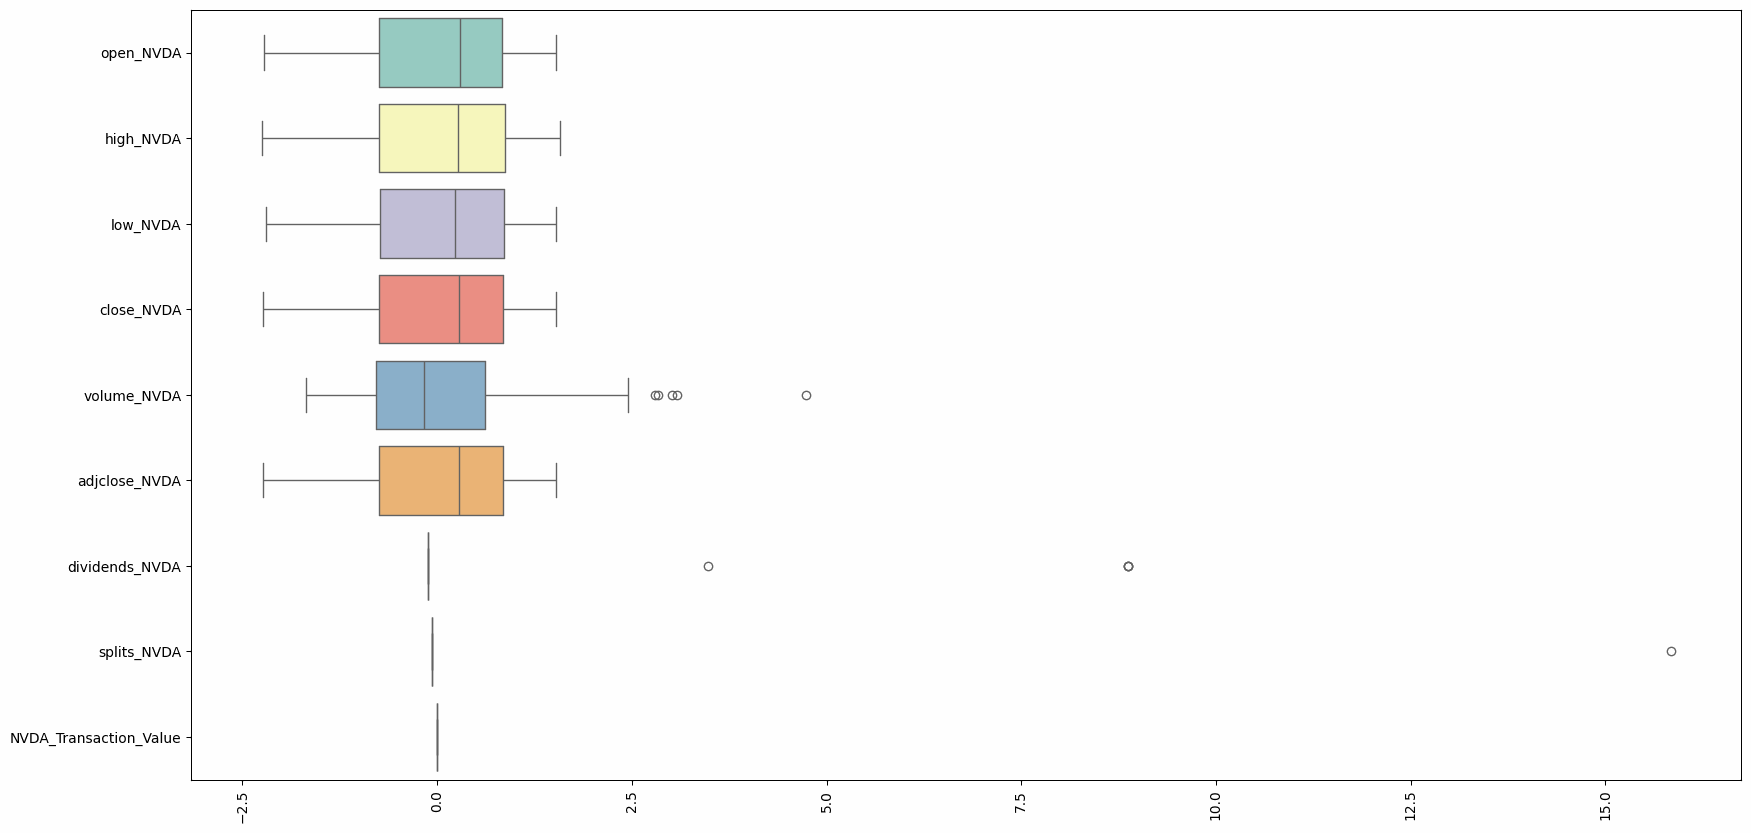

In [291]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_NVDA[num_cols_NVDA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [292]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_NVDA[num_cols_NVDA], df_scaled_NVDA))
print("MSE:", mean_squared_error(df_NVDA[num_cols_NVDA], df_scaled_NVDA))
print("RMSE:", np.sqrt(mean_squared_error(df_NVDA[num_cols_NVDA], df_scaled_NVDA)))
print("Residuals:", df_NVDA[num_cols_NVDA] - df_scaled_NVDA)

R2, MSE, RMSE, and Residuals
R2: -89722.31348322012
MSE: 1.872163051547232e+16
RMSE: 136827009.45161492
Residuals:             open_NVDA  high_NVDA  low_NVDA  close_NVDA  volume_NVDA  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_NVDA  divid

### NORMALIZING

In [293]:
# Create MinMaxScaler and apply to numerical columns
scaler_NVDA = MinMaxScaler()
scaled_values_NVDA = scaler_NVDA.fit_transform(df_NVDA[num_cols_NVDA])

# Create new DataFrame and display
df_scaled_NVDA = pd.DataFrame(scaled_values_NVDA, columns=num_cols_NVDA)
display(df_scaled_NVDA.head())

,open_NVDA,high_NVDA,low_NVDA,close_NVDA,volume_NVDA,adjclose_NVDA,dividends_NVDA,splits_NVDA,NVDA_Transaction_Value
0,0.017268,0.010611,0.002779,0.005912,0.295144,0.005911,0.0,0.0,0.0
1,0.000000,0.000000,0.000000,0.000000,0.208019,0.000000,0.0,0.0,0.0
2,0.002768,0.003018,0.001900,0.004234,0.194172,0.004233,0.0,0.0,0.0
3,0.009591,0.013017,0.009966,0.015082,0.298793,0.015077,0.0,0.0,0.0
4,0.019899,0.039071,0.021821,0.046234,0.518124,0.046219,0.0,0.0,0.0


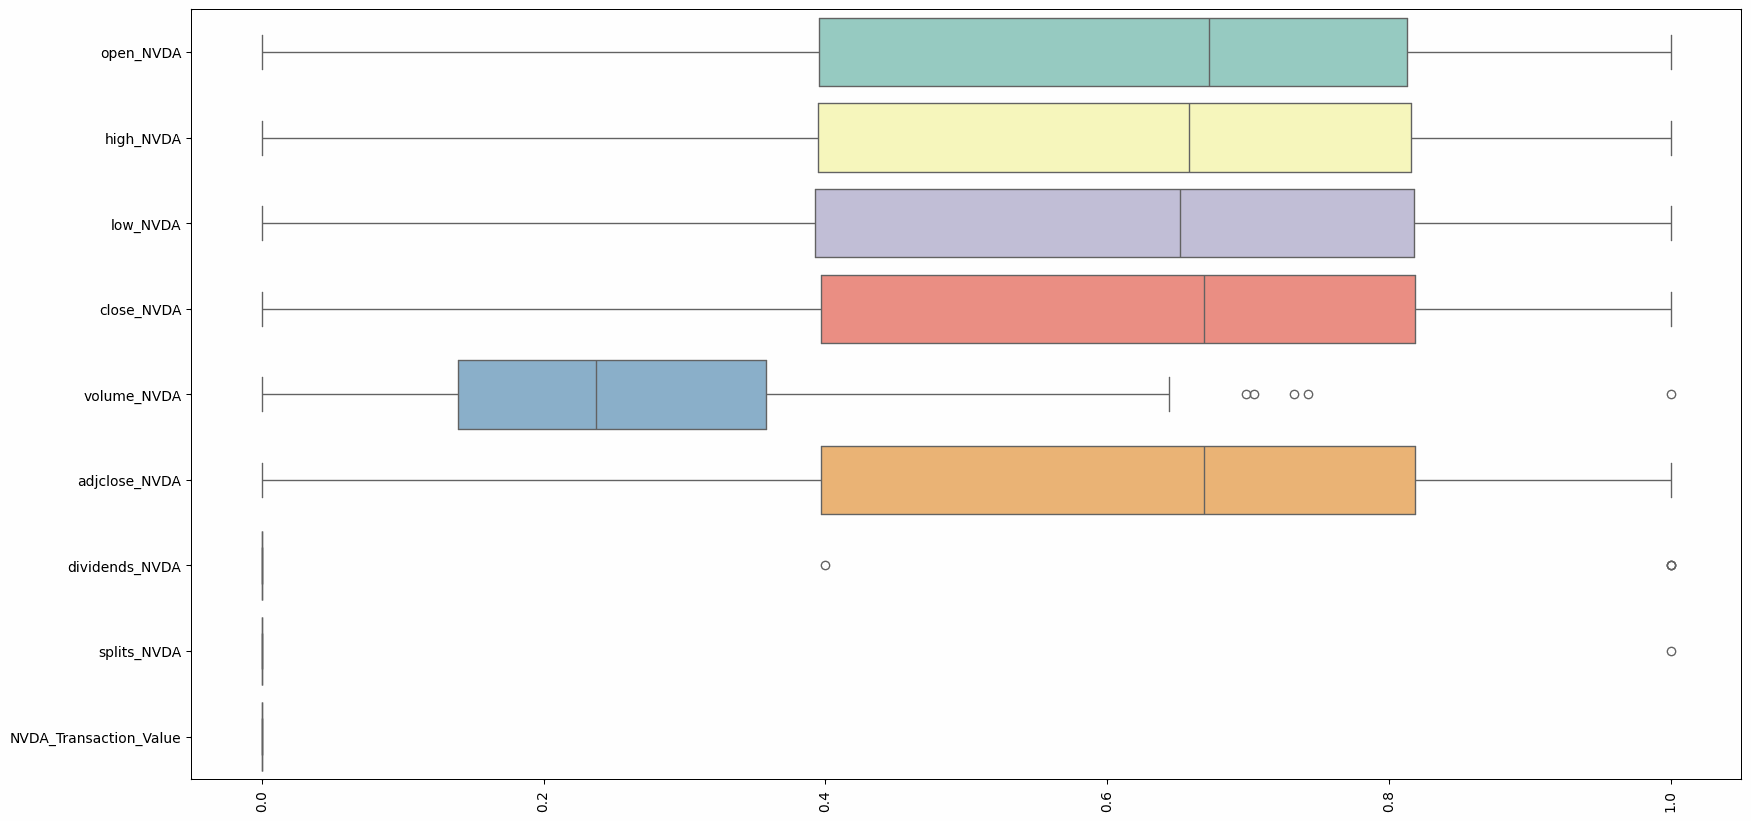

In [294]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_NVDA[num_cols_NVDA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [295]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_NVDA[num_cols_NVDA], df_scaled_NVDA))
print("MSE:", mean_squared_error(df_NVDA[num_cols_NVDA], df_scaled_NVDA))
print("RMSE:", np.sqrt(mean_squared_error(df_NVDA[num_cols_NVDA], df_scaled_NVDA)))
print("Residuals:", df_NVDA[num_cols_NVDA] - df_scaled_NVDA)

R2, MSE, RMSE, and Residuals
R2: -1114.2893247617042
MSE: 1.872163052377217e+16
RMSE: 136827009.48194465
Residuals:             open_NVDA  high_NVDA  low_NVDA  close_NVDA  volume_NVDA  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_NVDA  divi

## MA (MASTERCARD)

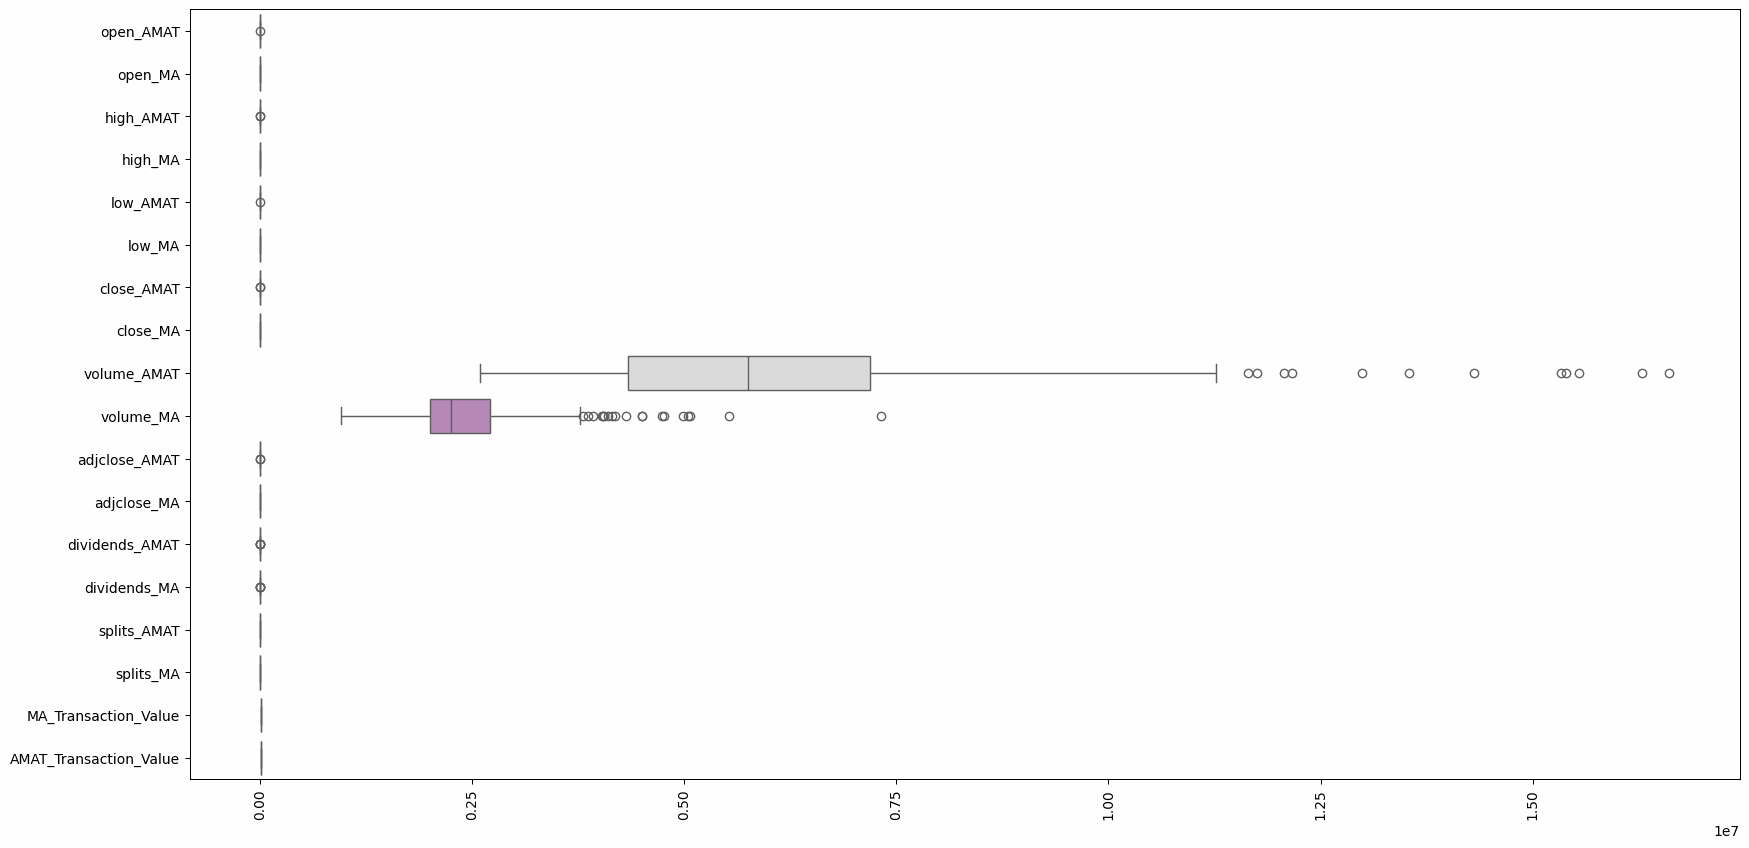

In [296]:
# Create one graph of all boxplots in MA
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_MA[num_cols_MA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [297]:
# Create StandardScaler and apply to numerical columns
scaler_MA = StandardScaler()
scaled_values_MA = scaler_MA.fit_transform(df_MA[num_cols_MA])

# Create new DataFrame and display
df_scaled_MA = pd.DataFrame(scaled_values_MA, columns=num_cols_MA)
display(df_scaled_MA.head())

,open_AMAT,open_MA,high_AMAT,high_MA,low_AMAT,low_MA,close_AMAT,close_MA,volume_AMAT,volume_MA,adjclose_AMAT,adjclose_MA,dividends_AMAT,dividends_MA,splits_AMAT,splits_MA,MA_Transaction_Value,AMAT_Transaction_Value
0,-1.607162,-1.627157,-1.694411,-1.716470,-1.797625,-1.680976,-1.845151,-1.711634,0.931272,-0.005110,-1.872694,-1.730236,-0.126467,-0.127000,0.0,0.0,0.0,0.0
1,-1.971848,-1.721269,-1.996168,-1.811714,-1.919036,-1.748741,-1.973966,-1.813862,-0.043269,0.777729,-2.001317,-1.830236,-0.126467,-0.127000,0.0,0.0,0.0,0.0
2,-2.055871,-1.809194,-2.047041,-1.743358,-2.008071,-1.723083,-2.068371,-1.781097,-0.005954,-0.528369,-2.095582,-1.798185,-0.126467,-0.127000,0.0,0.0,0.0,0.0
3,-2.043554,-1.744390,-2.067912,-1.765711,-2.039548,-1.765519,-2.082047,-1.792564,-0.315823,-0.064506,-2.109237,-1.809402,-0.126467,-0.127000,0.0,0.0,0.0,0.0
4,-2.054551,-1.778583,-2.012691,-1.787741,-1.964453,-1.780650,-1.969113,-1.708685,0.118196,-0.425482,-1.996472,-1.706037,-0.126467,7.874008,0.0,0.0,0.0,0.0


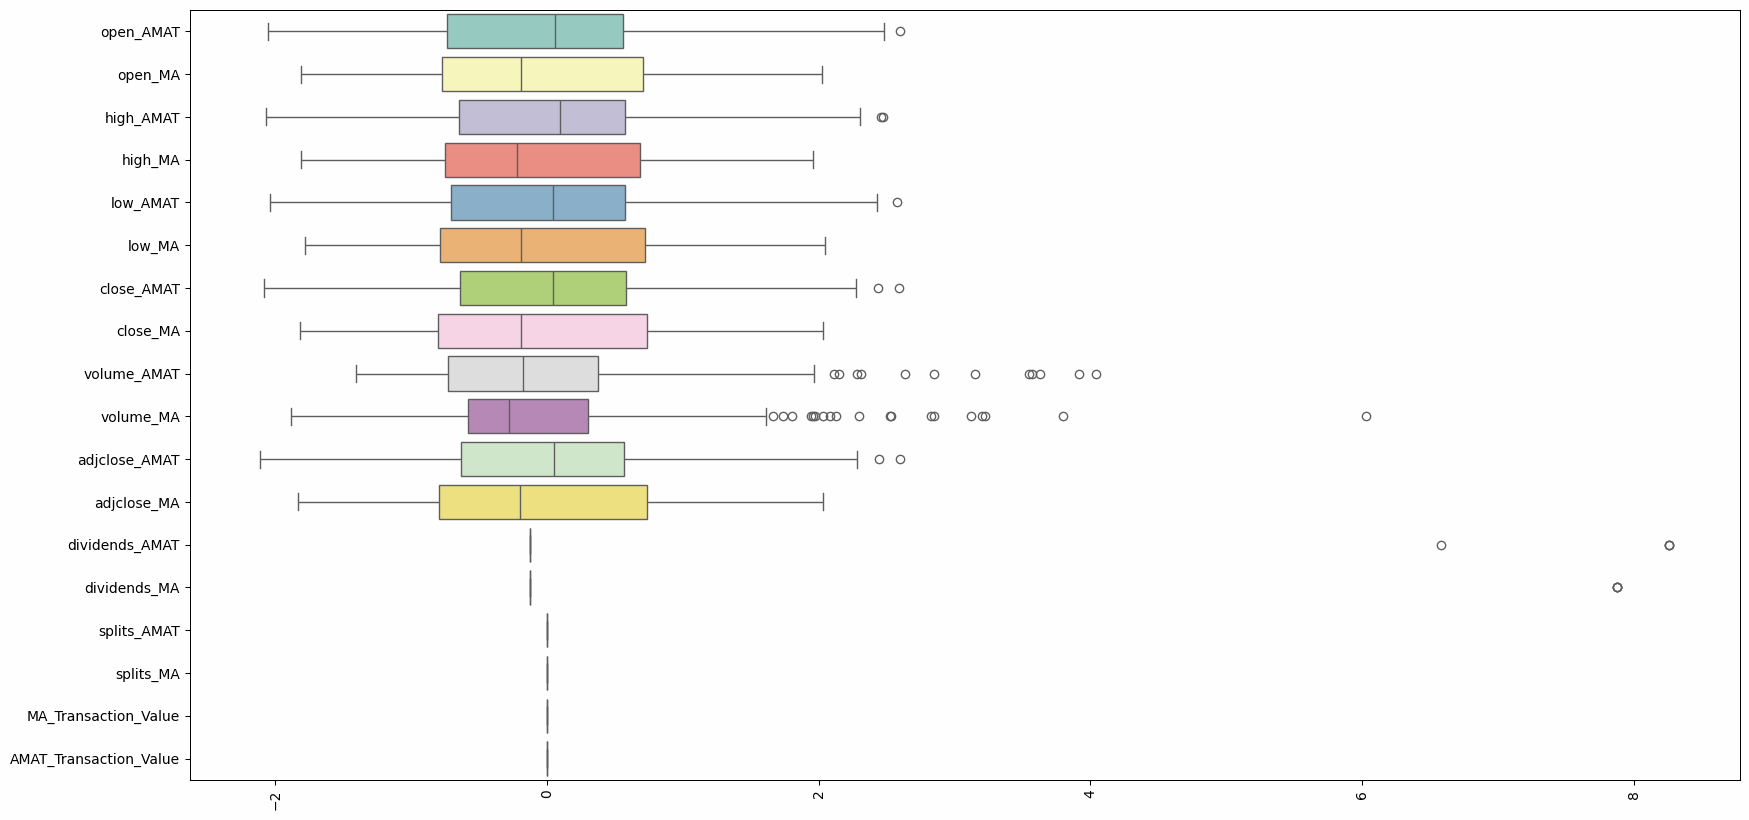

In [298]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_MA[num_cols_MA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [299]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_MA[num_cols_MA], df_scaled_MA))
print("MSE:", mean_squared_error(df_MA[num_cols_MA], df_scaled_MA))
print("RMSE:", np.sqrt(mean_squared_error(df_MA[num_cols_MA], df_scaled_MA)))
print("Residuals:", df_MA[num_cols_MA] - df_scaled_MA)

R2, MSE, RMSE, and Residuals
R2: -116.6328091816873
MSE: 2885474658878.5454
RMSE: 1698668.4958750913
Residuals:             open_AMAT  open_MA  high_AMAT  high_MA  low_AMAT  low_MA  \
2024-01-02        NaN      NaN        NaN      NaN       NaN     NaN   
2024-01-03        NaN      NaN        NaN      NaN       NaN     NaN   
2024-01-04        NaN      NaN        NaN      NaN       NaN     NaN   
2024-01-05        NaN      NaN        NaN      NaN       NaN     NaN   
2024-01-08        NaN      NaN        NaN      NaN       NaN     NaN   
...               ...      ...        ...      ...       ...     ...   
247               NaN      NaN        NaN      NaN       NaN     NaN   
248               NaN      NaN        NaN      NaN       NaN     NaN   
249               NaN      NaN        NaN      NaN       NaN     NaN   
250               NaN      NaN        NaN      NaN       NaN     NaN   
251               NaN      NaN        NaN      NaN       NaN     NaN   

            close_AMAT 

### NORMALIZING

In [300]:
# Create MinMaxScaler and apply to numerical columns
scaler_MA = MinMaxScaler()
scaled_values_MA = scaler_MA.fit_transform(df_MA[num_cols_MA])

# Create new DataFrame and display
df_scaled_MA = pd.DataFrame(scaled_values_MA, columns=num_cols_MA)
display(df_scaled_MA.head())

,open_AMAT,open_MA,high_AMAT,high_MA,low_AMAT,low_MA,close_AMAT,close_MA,volume_AMAT,volume_MA,adjclose_AMAT,adjclose_MA,dividends_AMAT,dividends_MA,splits_AMAT,splits_MA,MA_Transaction_Value,AMAT_Transaction_Value
0,0.096436,0.047457,0.082303,0.025266,0.052431,0.026033,0.050675,0.026581,0.428860,0.237139,0.050249,0.025897,0.0,0.0,0.0,0.0,0.0,0.0
1,0.018058,0.022922,0.015809,0.000000,0.026118,0.008334,0.023120,0.000000,0.249996,0.336163,0.022926,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000000,0.000000,0.004599,0.018134,0.006822,0.015036,0.002925,0.008519,0.256845,0.170950,0.002901,0.008300,0.0,0.0,0.0,0.0,0.0,0.0
3,0.002647,0.016894,0.000000,0.012204,0.000000,0.003952,0.000000,0.005538,0.199973,0.229625,0.000000,0.005395,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000284,0.007980,0.012168,0.006359,0.016275,0.000000,0.024158,0.027347,0.279631,0.183964,0.023955,0.032163,0.0,1.0,0.0,0.0,0.0,0.0


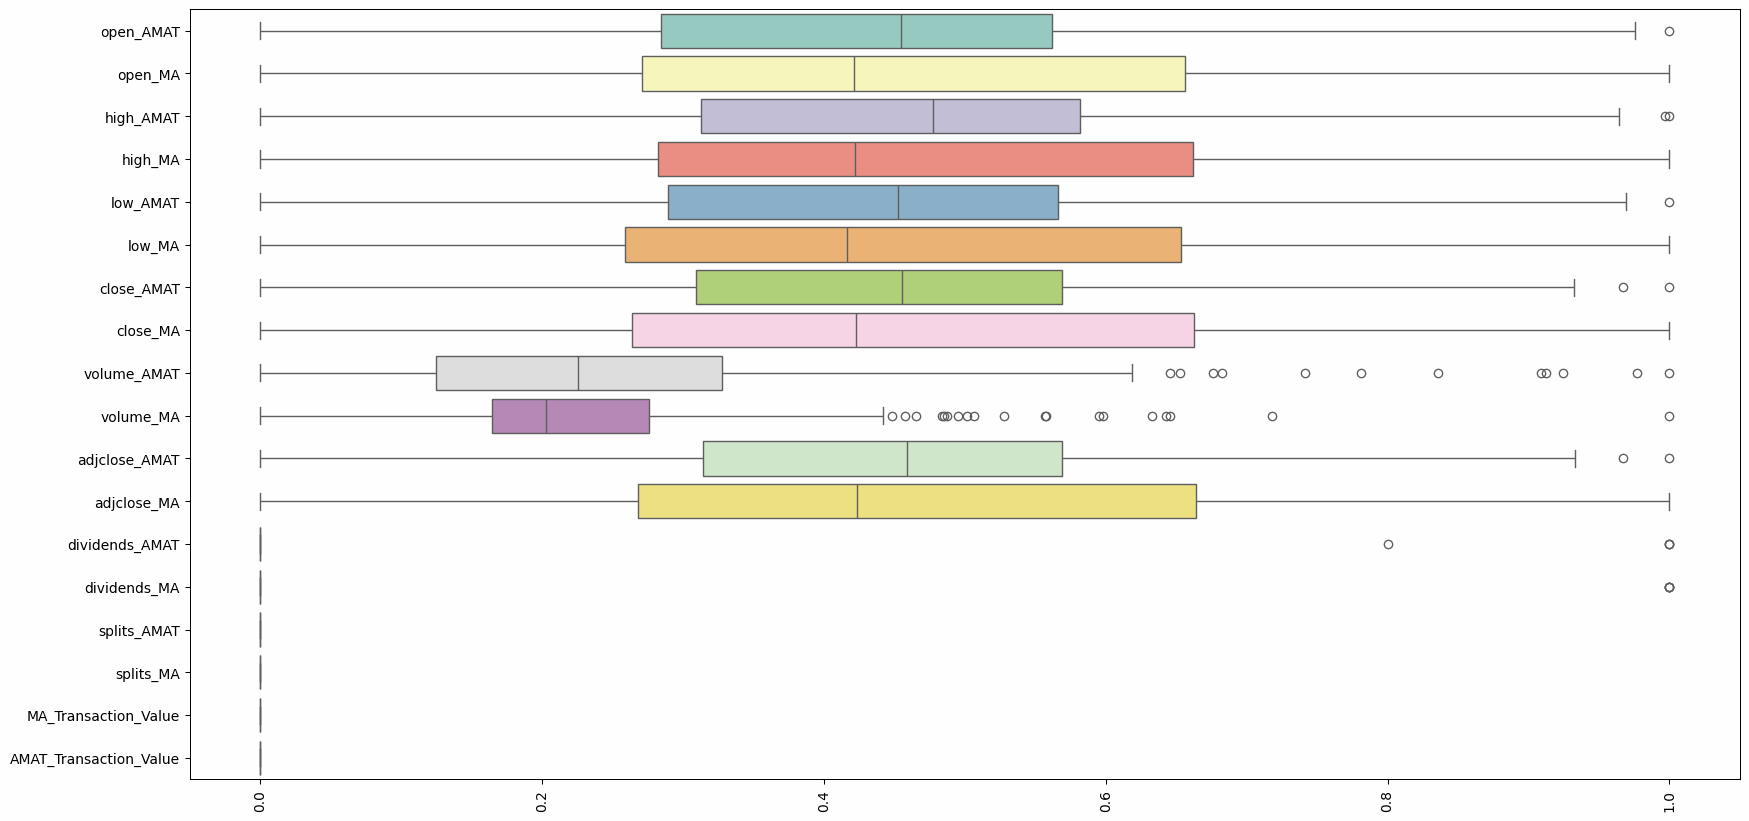

In [301]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_MA[num_cols_MA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

## HP (HPQ)

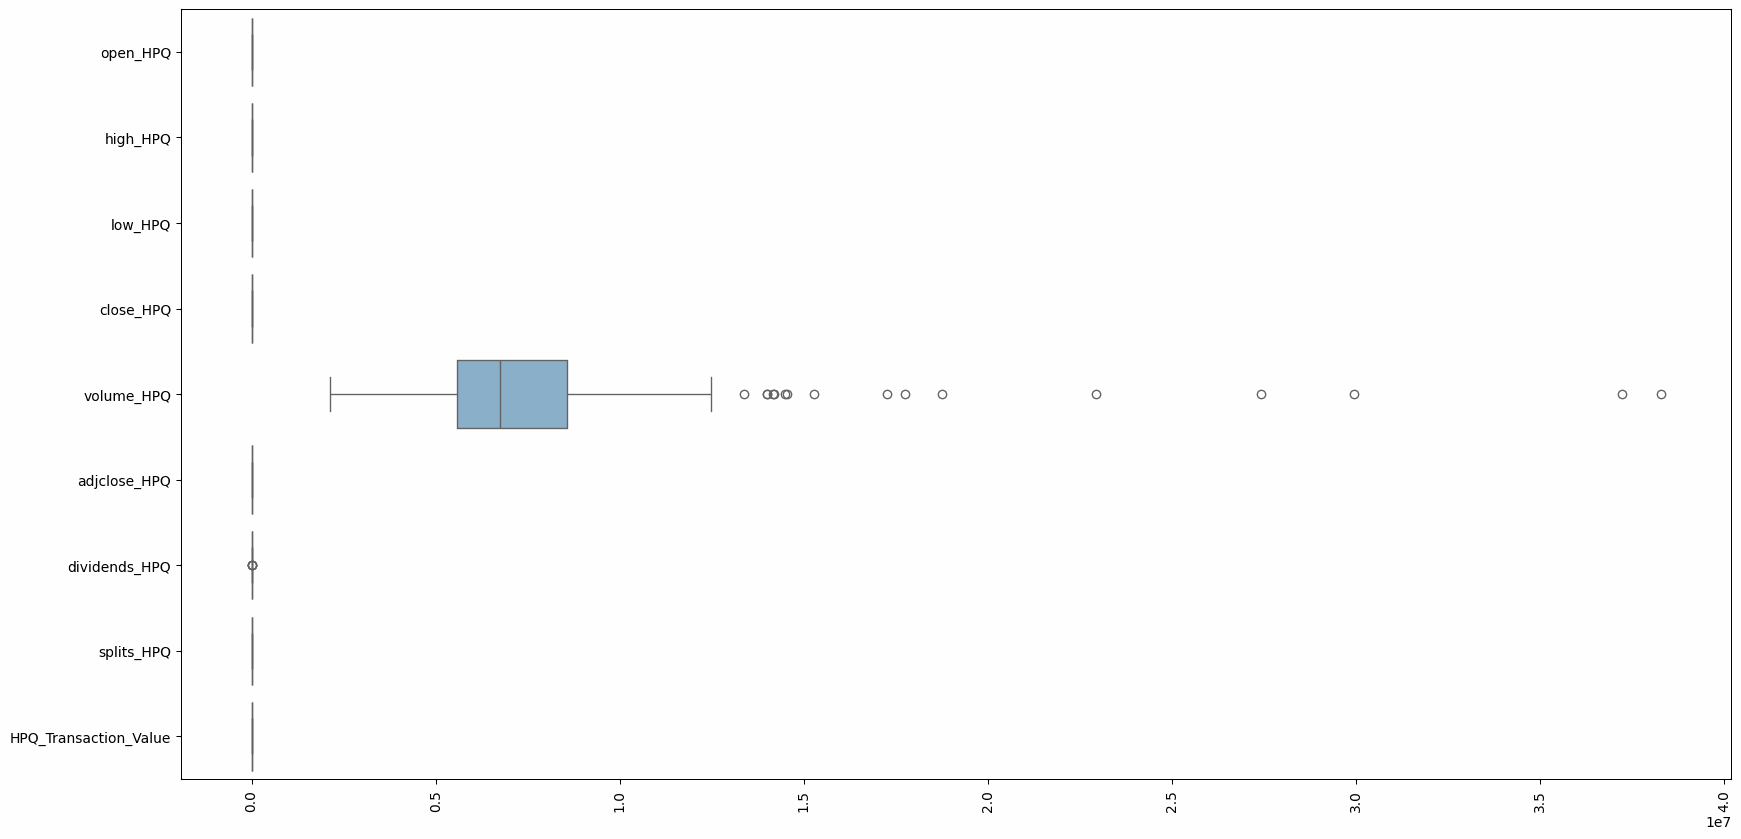

In [302]:
# Create one graph of all boxplots in HPQ
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_HPQ[num_cols_HPQ], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [303]:
# Create StandardScaler and apply to numerical columns
scaler_HPQ = StandardScaler()
scaled_values_HPQ = scaler_HPQ.fit_transform(df_HPQ[num_cols_HPQ])

# Create new DataFrame and display
df_scaled_HPQ = pd.DataFrame(scaled_values_HPQ, columns=num_cols_HPQ)
display(df_scaled_HPQ.head())

,open_HPQ,high_HPQ,low_HPQ,close_HPQ,volume_HPQ,adjclose_HPQ,dividends_HPQ,splits_HPQ,HPQ_Transaction_Value
0,-0.995219,-1.013211,-0.960497,-0.991692,0.229456,-1.053665,-0.126974,0.0,0.0
1,-1.043477,-1.004398,-1.015927,-0.970698,0.054166,-1.034347,-0.126974,0.0,0.0
2,-0.995219,-0.995585,-0.963577,-1.036678,-0.015993,-1.095064,-0.126974,0.0,0.0
3,-1.061573,-0.969147,-0.997450,-0.955703,-0.203926,-1.020547,-0.126974,0.0,0.0
4,-0.898705,-0.713577,-0.831162,-0.640801,0.840335,-0.730759,-0.126974,0.0,0.0


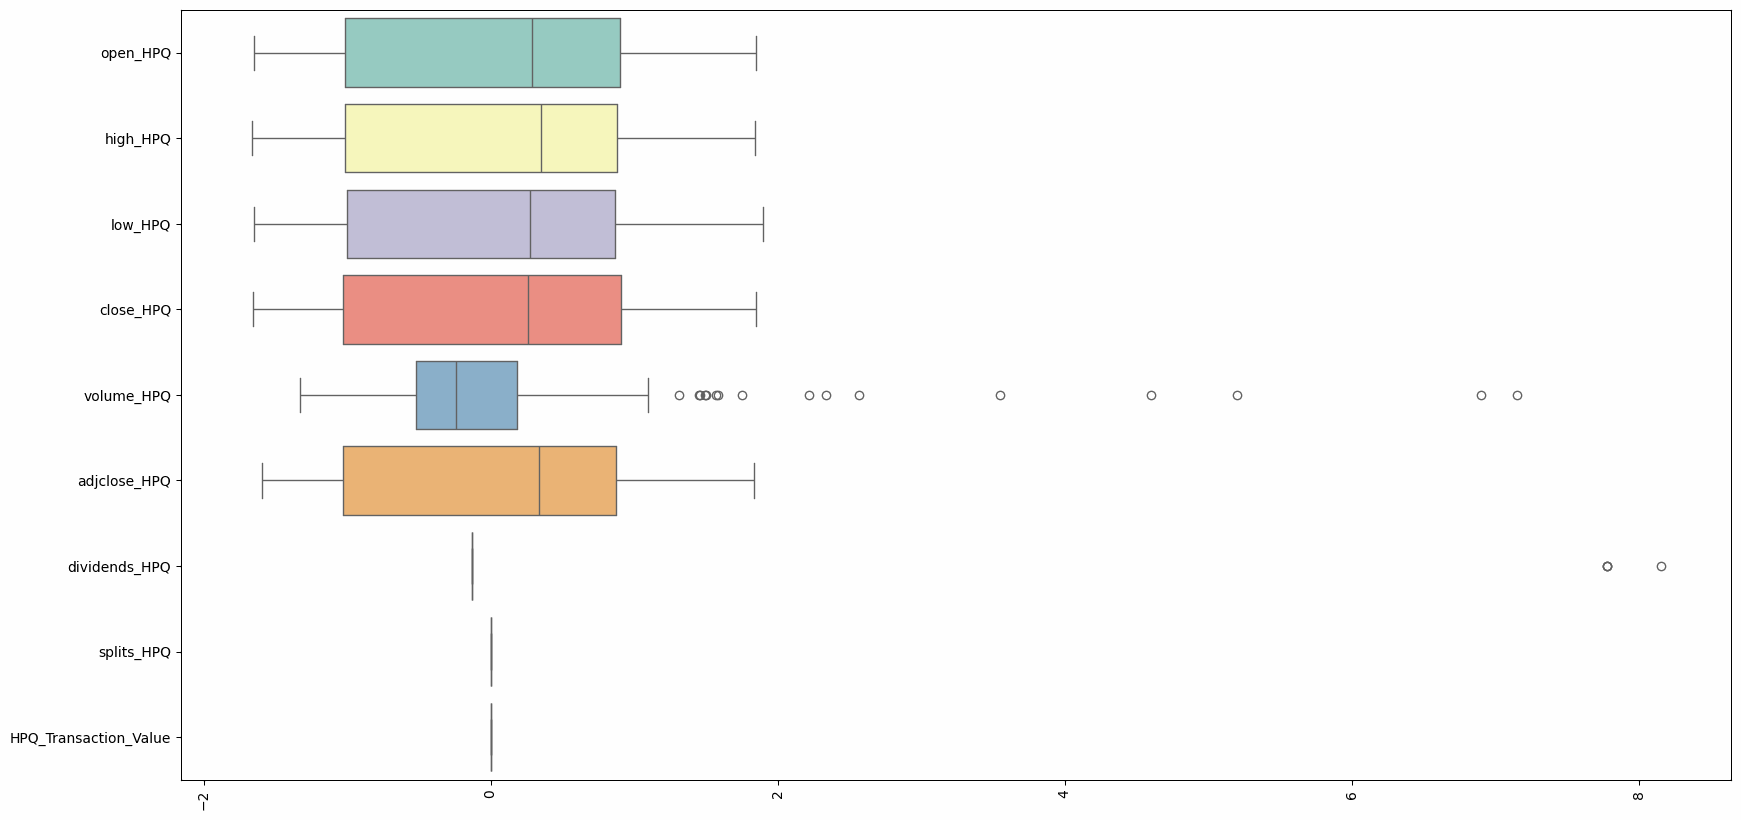

In [304]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_HPQ[num_cols_HPQ], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [305]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_HPQ[num_cols_HPQ], df_scaled_HPQ))
print("MSE:", mean_squared_error(df_HPQ[num_cols_HPQ], df_scaled_HPQ))
print("RMSE:", np.sqrt(mean_squared_error(df_HPQ[num_cols_HPQ], df_scaled_HPQ)))
print("Residuals:", df_HPQ[num_cols_HPQ] - df_scaled_HPQ)

R2, MSE, RMSE, and Residuals
R2: -138.52728927149235
MSE: 8771611413675.353
RMSE: 2961690.6343633113
Residuals:             open_HPQ  high_HPQ  low_HPQ  close_HPQ  volume_HPQ  adjclose_HPQ  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251     

### NORMALIZING

In [306]:
# Create MinMaxSacler and apply to numerical columns
scaler_HPQ = MinMaxScaler()
scaled_values_HPQ = scaler_HPQ.fit_transform(df_HPQ[num_cols_HPQ])

# Create new DataFrame and display
df_scaled_HPQ = pd.DataFrame(scaled_values_HPQ, columns=num_cols_HPQ)
display(df_scaled_HPQ.head())

,open_HPQ,high_HPQ,low_HPQ,close_HPQ,volume_HPQ,adjclose_HPQ,dividends_HPQ,splits_HPQ,HPQ_Transaction_Value
0,0.186368,0.185774,0.193745,0.189212,0.183889,0.157854,0.0,0.0,0.0
1,0.172563,0.188285,0.178106,0.195205,0.163211,0.163489,0.0,0.0,0.0
2,0.186368,0.190795,0.192876,0.176370,0.154935,0.145778,0.0,0.0,0.0
3,0.167386,0.198326,0.183319,0.199486,0.132765,0.167514,0.0,0.0,0.0
4,0.213978,0.271130,0.230235,0.289384,0.255953,0.252047,0.0,0.0,0.0


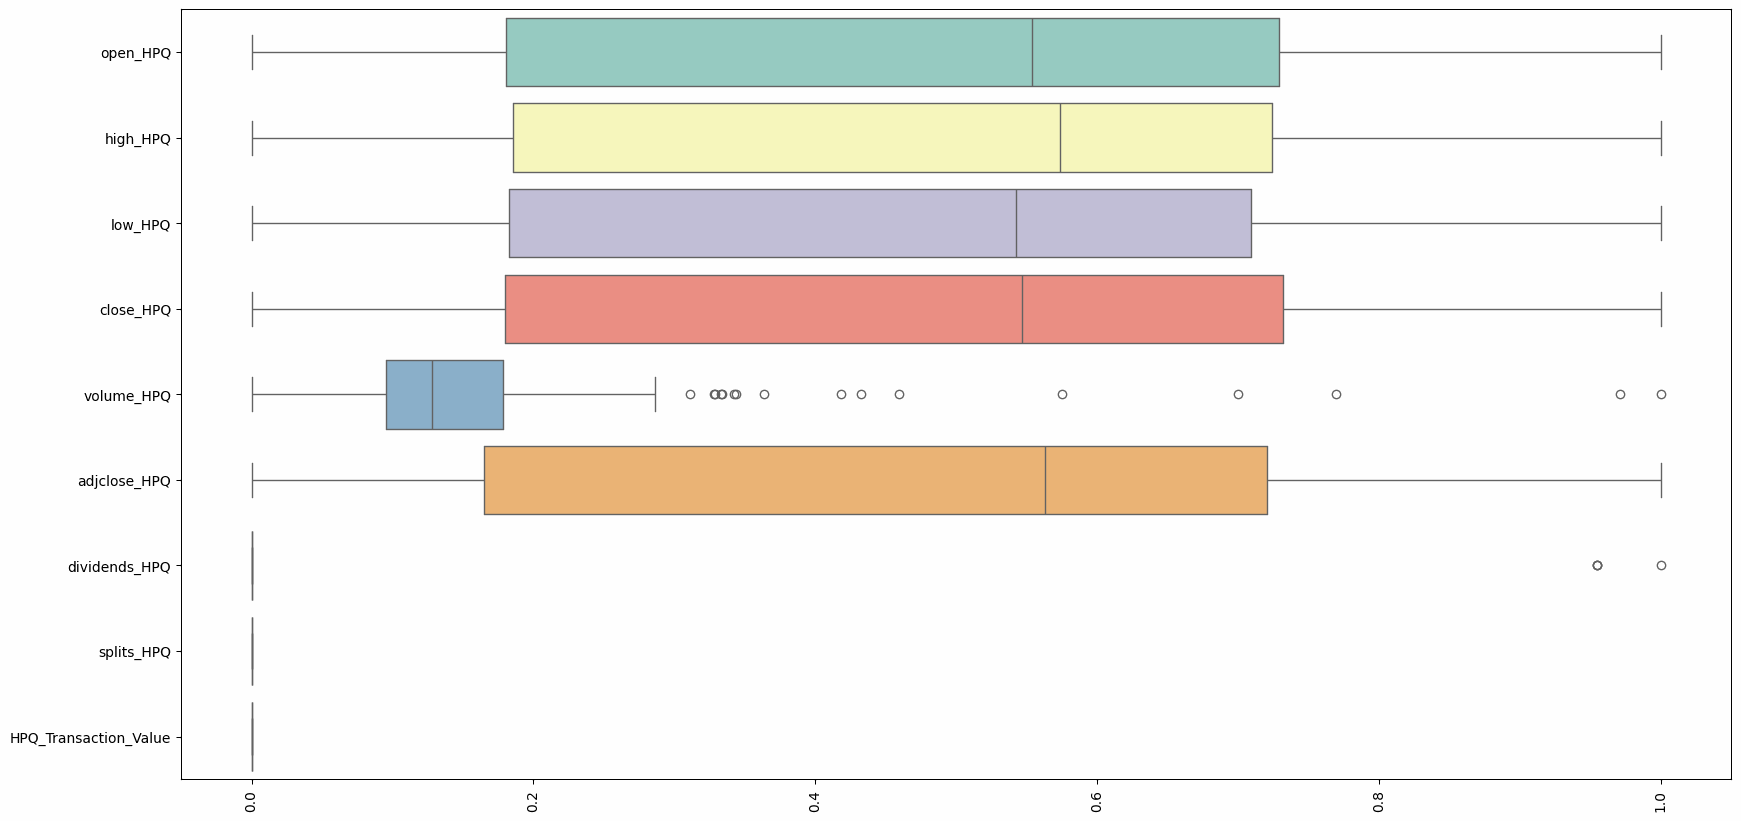

In [307]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_HPQ[num_cols_HPQ], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [308]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_HPQ[num_cols_HPQ], df_scaled_HPQ))
print("MSE:", mean_squared_error(df_HPQ[num_cols_HPQ], df_scaled_HPQ))
print("RMSE:", np.sqrt(mean_squared_error(df_HPQ[num_cols_HPQ], df_scaled_HPQ)))
print("Residuals:", df_HPQ[num_cols_HPQ] - df_scaled_HPQ)

R2, MSE, RMSE, and Residuals
R2: -52.961079796383075
MSE: 8771611977614.214
RMSE: 2961690.729568875
Residuals:             open_HPQ  high_HPQ  low_HPQ  close_HPQ  volume_HPQ  adjclose_HPQ  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251      

## EBAY (EBAY)

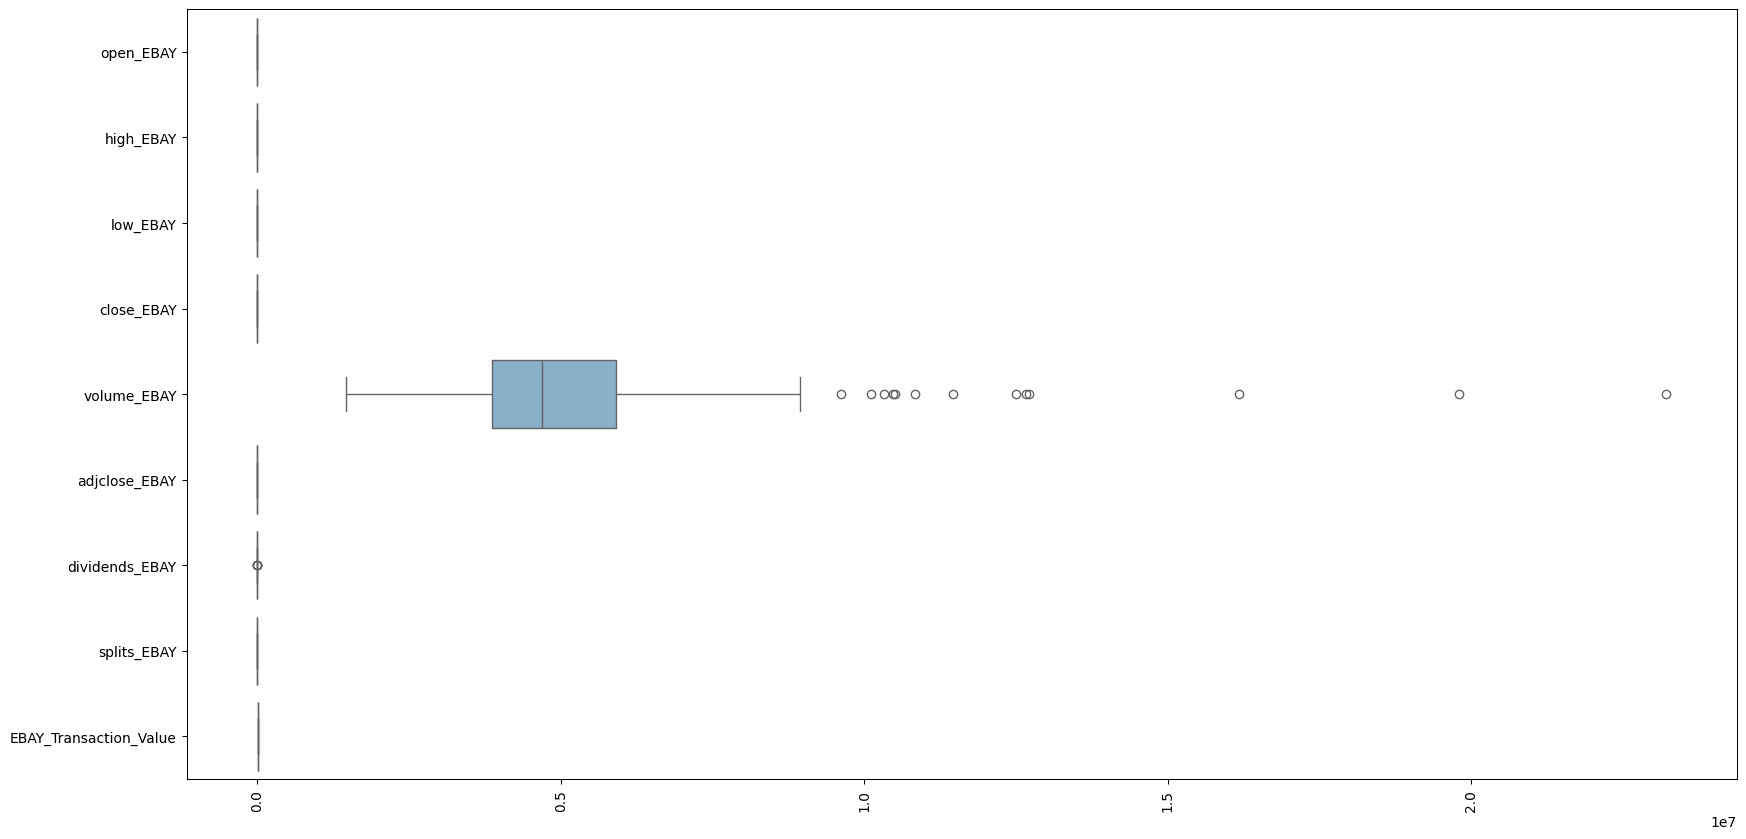

In [309]:
# Create one graph of all boxplots in EBAY
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_Ebay[num_cols_EBAY], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [310]:
# Create StandardScaler and apply to numerical columns
scaler_EBAY = StandardScaler()
scaled_values_EBAY = scaler_EBAY.fit_transform(df_Ebay[num_cols_EBAY])

# Create new DataFrame and display
df_scaled_EBAY = pd.DataFrame(scaled_values_EBAY, columns=num_cols_EBAY)
display(df_scaled_EBAY.head())

,open_EBAY,high_EBAY,low_EBAY,close_EBAY,volume_EBAY,adjclose_EBAY,dividends_EBAY,splits_EBAY,EBAY_Transaction_Value
0,-1.560398,-1.499484,-1.506573,-1.485434,0.043456,-1.484938,-0.127,0.0,0.0
1,-1.510014,-1.514286,-1.539458,-1.528992,0.441120,-1.526382,-0.127,0.0,0.0
2,-1.523631,-1.581570,-1.614820,-1.667836,-0.194146,-1.658486,-0.127,0.0,0.0
3,-1.659804,-1.650199,-1.617561,-1.632444,-0.852978,-1.624812,-0.127,0.0,0.0
4,-1.598526,-1.663656,-1.614820,-1.625638,-0.463237,-1.618337,-0.127,0.0,0.0


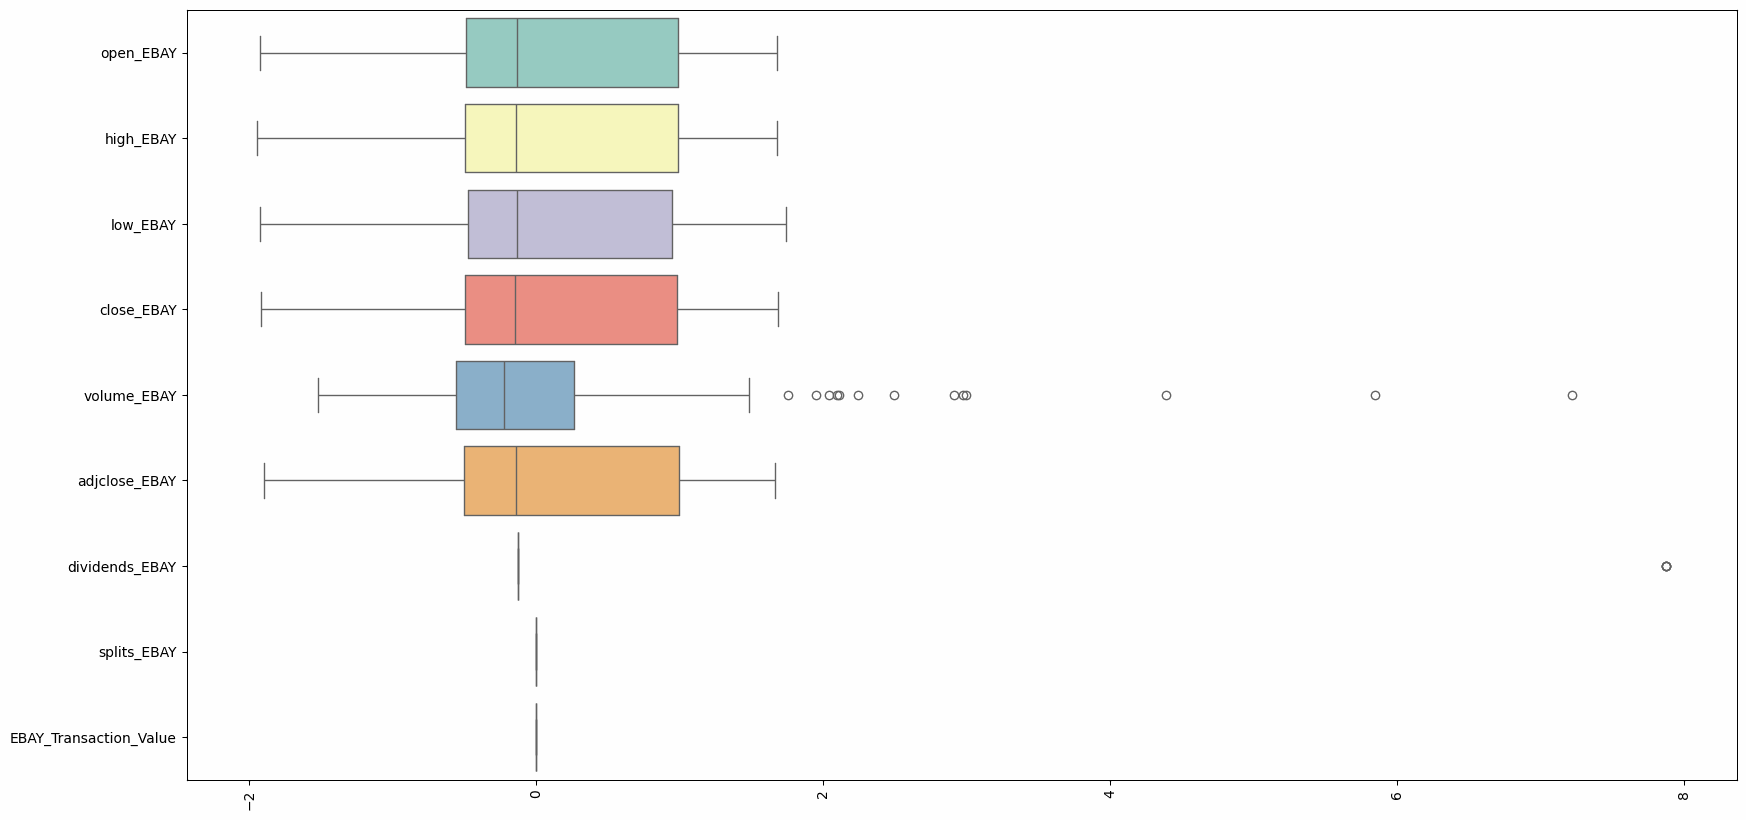

In [311]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_EBAY[num_cols_EBAY], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [312]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_Ebay[num_cols_EBAY], df_scaled_EBAY))
print("MSE:", mean_squared_error(df_Ebay[num_cols_EBAY], df_scaled_EBAY))
print("RMSE:", np.sqrt(mean_squared_error(df_Ebay[num_cols_EBAY], df_scaled_EBAY)))
print("Residuals:", df_Ebay[num_cols_EBAY] - df_scaled_EBAY)

R2, MSE, RMSE, and Residuals
R2: -121.57763611528247
MSE: 3762626430825.1484
RMSE: 1939749.063880467
Residuals:             open_EBAY  high_EBAY  low_EBAY  close_EBAY  volume_EBAY  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_EBAY  dividend

### NORMALIZING

In [313]:
# Create MinMaxScaler and apply to numerical columns
scaler_EBAY = MinMaxScaler()
scaled_values_EBAY = scaler_EBAY.fit_transform(df_Ebay[num_cols_EBAY])

# Create new DataFrame and display
df_scaled_EBAY = pd.DataFrame(scaled_values_EBAY, columns=num_cols_EBAY)
display(df_scaled_EBAY.head())

,open_EBAY,high_EBAY,low_EBAY,close_EBAY,volume_EBAY,adjclose_EBAY,dividends_EBAY,splits_EBAY,EBAY_Transaction_Value
0,0.101586,0.123328,0.113730,0.120755,0.179306,0.116293,0.0,0.0,0.0
1,0.115559,0.119242,0.104751,0.108679,0.224798,0.104664,0.0,0.0,0.0
2,0.111782,0.100669,0.084175,0.070189,0.152126,0.067595,0.0,0.0,0.0
3,0.074018,0.081724,0.083427,0.080000,0.076757,0.077044,0.0,0.0,0.0
4,0.091012,0.078009,0.084175,0.081887,0.121342,0.078861,0.0,0.0,0.0


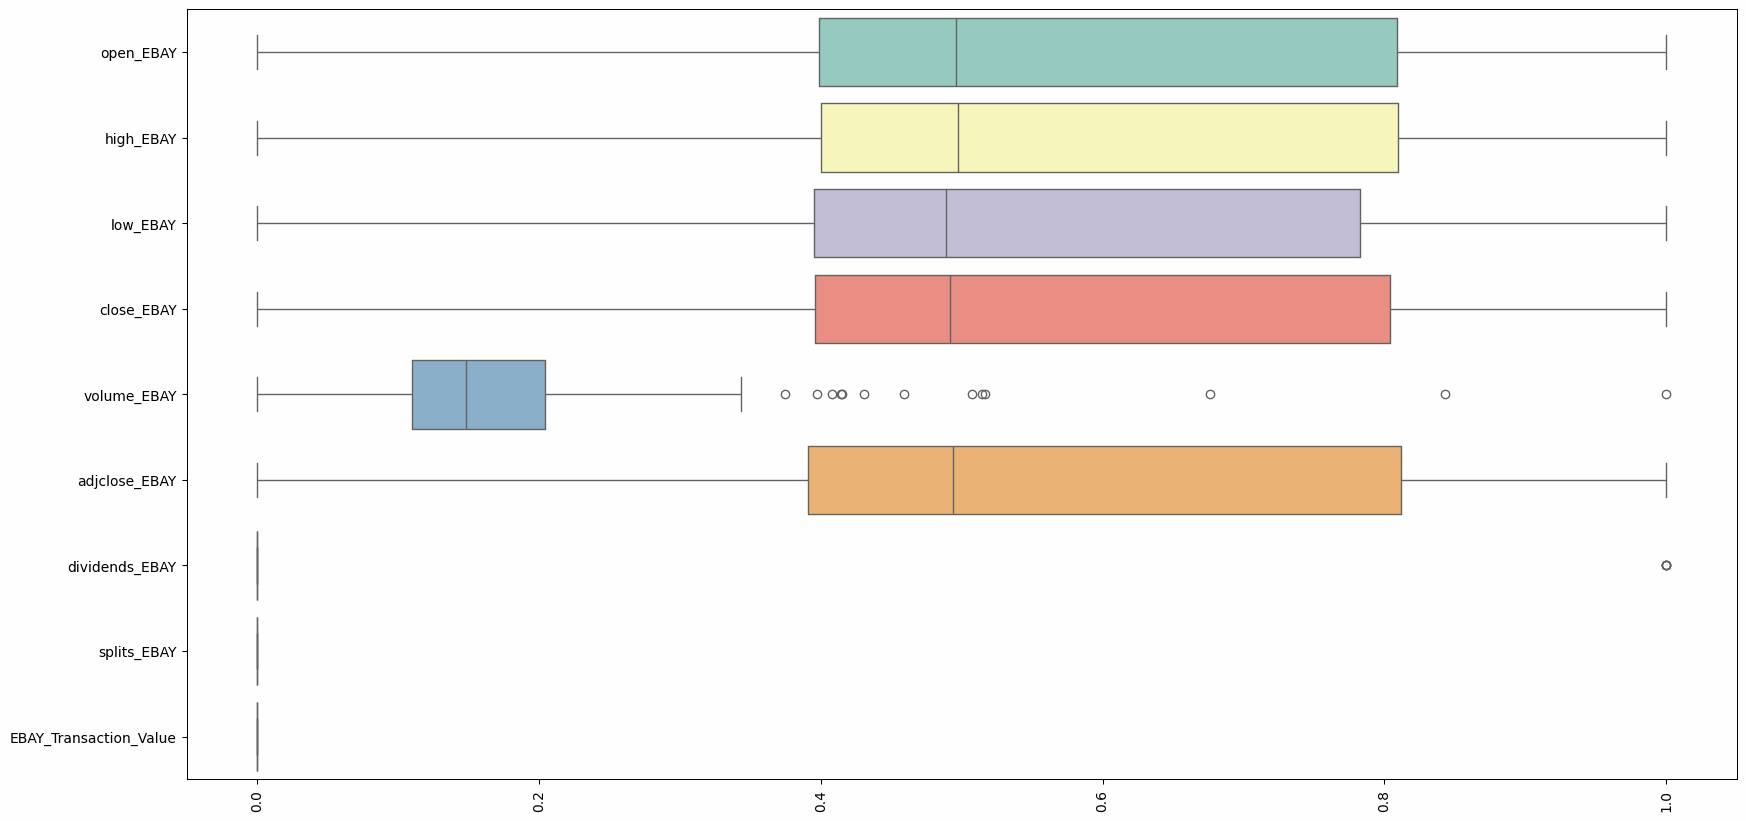

In [314]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_EBAY[num_cols_EBAY], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [315]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_Ebay[num_cols_EBAY], df_scaled_EBAY))
print("MSE:", mean_squared_error(df_Ebay[num_cols_EBAY], df_scaled_EBAY))
print("RMSE:", np.sqrt(mean_squared_error(df_Ebay[num_cols_EBAY], df_scaled_EBAY)))
print("Residuals:", df_Ebay[num_cols_EBAY] - df_scaled_EBAY)

R2, MSE, RMSE, and Residuals
R2: -30.815638445170674
MSE: 3762626716320.6655
RMSE: 1939749.1374713033
Residuals:             open_EBAY  high_EBAY  low_EBAY  close_EBAY  volume_EBAY  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_EBAY  dividen

## CISCO (CSCO)

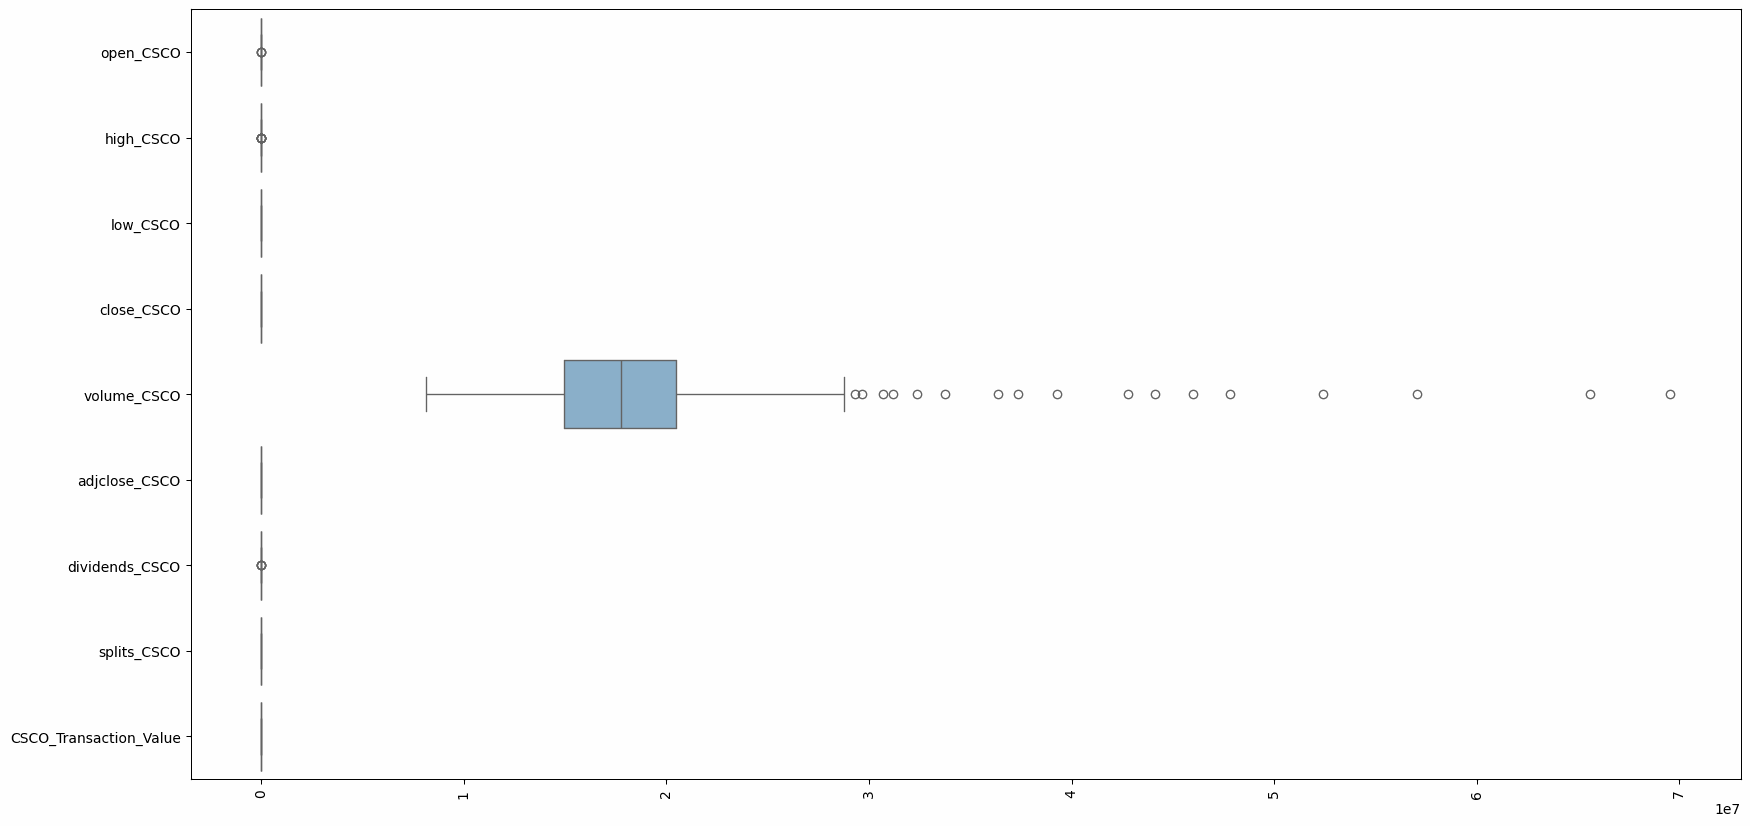

In [316]:
# Create one graph of all boxplots in CSCO
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_CSCO[num_cols_CSCO], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [317]:
# Create StandardScaler and apply to numerical columns
scaler_CSCO = StandardScaler()
scaled_values_CSCO = scaler_CSCO.fit_transform(df_CSCO[num_cols_CSCO])

# Create new DataFrame and display
df_scaled_CSCO = pd.DataFrame(scaled_values_CSCO, columns=num_cols_CSCO)
display(df_scaled_CSCO.head())

,open_CSCO,high_CSCO,low_CSCO,close_CSCO,volume_CSCO,adjclose_CSCO,dividends_CSCO,splits_CSCO,CSCO_Transaction_Value
0,-0.069925,-0.075408,-0.040828,-0.070431,0.128117,-0.292620,-0.126992,0.0,0.0
1,-0.147691,-0.118904,-0.116088,-0.070431,0.135697,-0.207042,7.722580,0.0,0.0
2,-0.082076,-0.159984,-0.103949,-0.173537,-0.133925,-0.301397,-0.126992,0.0,0.0
3,-0.145260,-0.193814,-0.133082,-0.171139,-0.649062,-0.299203,-0.126992,0.0,0.0
4,-0.249757,-0.162400,-0.176782,-0.082420,-0.141853,-0.218014,-0.126992,0.0,0.0


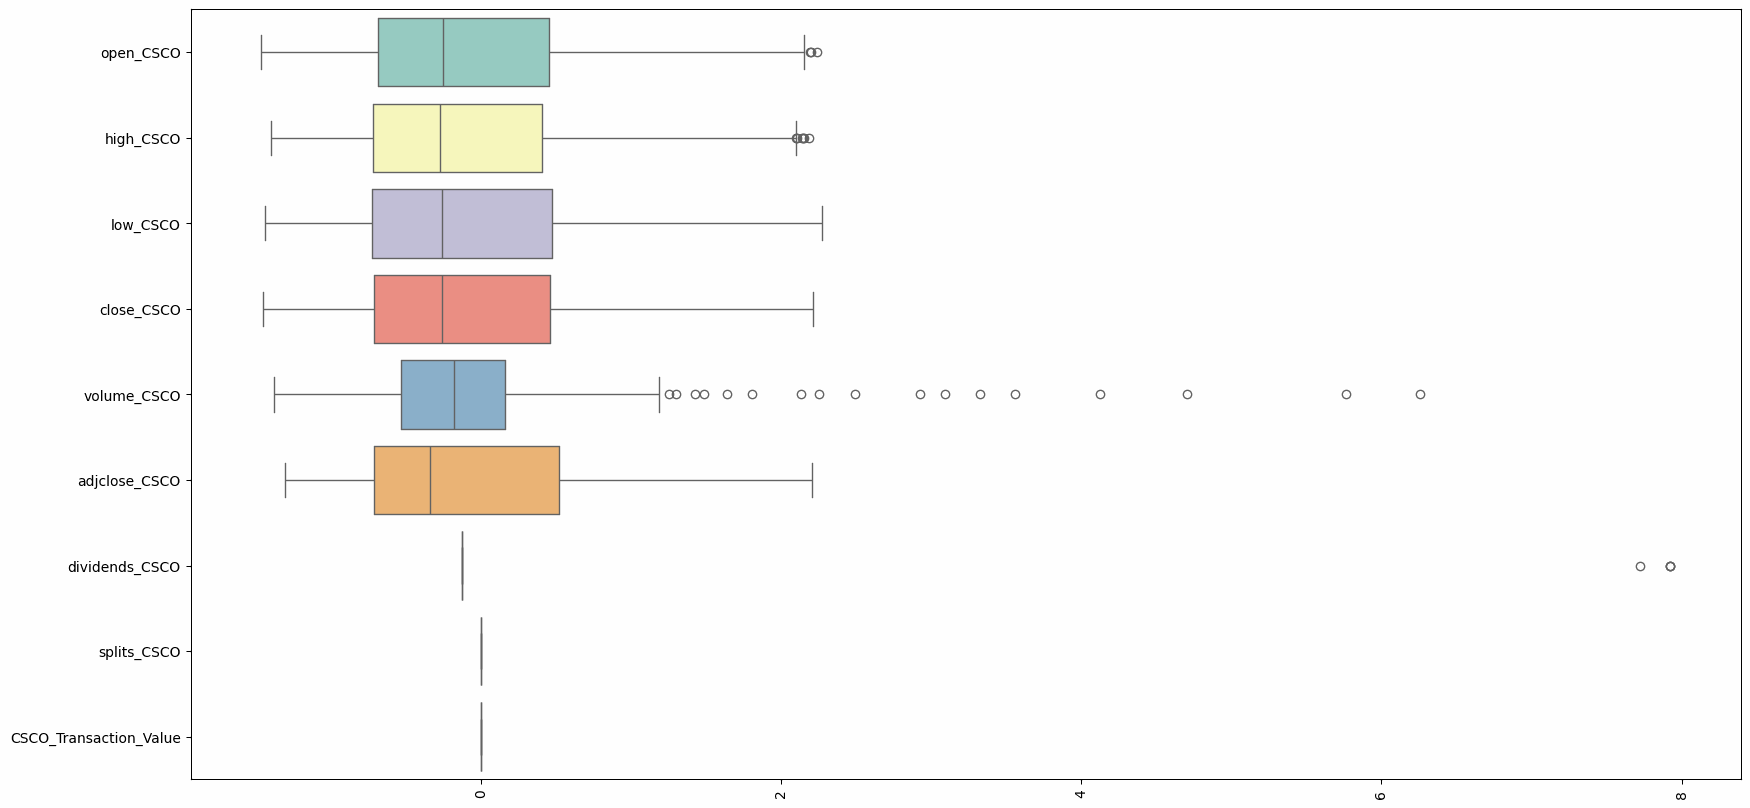

In [318]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_CSCO[num_cols_CSCO], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [319]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_CSCO[num_cols_CSCO], df_scaled_CSCO))
print("MSE:", mean_squared_error(df_CSCO[num_cols_CSCO], df_scaled_CSCO))
print("RMSE:", np.sqrt(mean_squared_error(df_CSCO[num_cols_CSCO], df_scaled_CSCO)))
print("Residuals:", df_CSCO[num_cols_CSCO] - df_scaled_CSCO)

R2, MSE, RMSE, and Residuals
R2: -122.03645312666066
MSE: 48206614171593.66
RMSE: 6943098.312107762
Residuals:             open_CSCO  high_CSCO  low_CSCO  close_CSCO  volume_CSCO  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_CSCO  dividends

### NORMALIZING

In [320]:
# Create MinMaxScaler and apply to numerical columns
scaler_CSCO = MinMaxScaler()
scaled_values_CSCO = scaler_CSCO.fit_transform(df_CSCO[num_cols_CSCO])

# Create new DataFrame and display
df_scaled_CSCO = pd.DataFrame(scaled_values_CSCO, columns=num_cols_CSCO)
display(df_scaled_CSCO.head())

,open_CSCO,high_CSCO,low_CSCO,close_CSCO,volume_CSCO,adjclose_CSCO,dividends_CSCO,splits_CSCO,CSCO_Transaction_Value
0,0.376394,0.368598,0.376555,0.377618,0.197385,0.289195,0.000,0.0,0.0
1,0.355410,0.356469,0.356254,0.377618,0.198378,0.313565,0.975,0.0,0.0
2,0.373115,0.345013,0.359529,0.349476,0.163054,0.286696,0.000,0.0,0.0
3,0.356066,0.335579,0.351670,0.350131,0.095565,0.287320,0.000,0.0,0.0
4,0.327869,0.344340,0.339882,0.374345,0.162015,0.310440,0.000,0.0,0.0


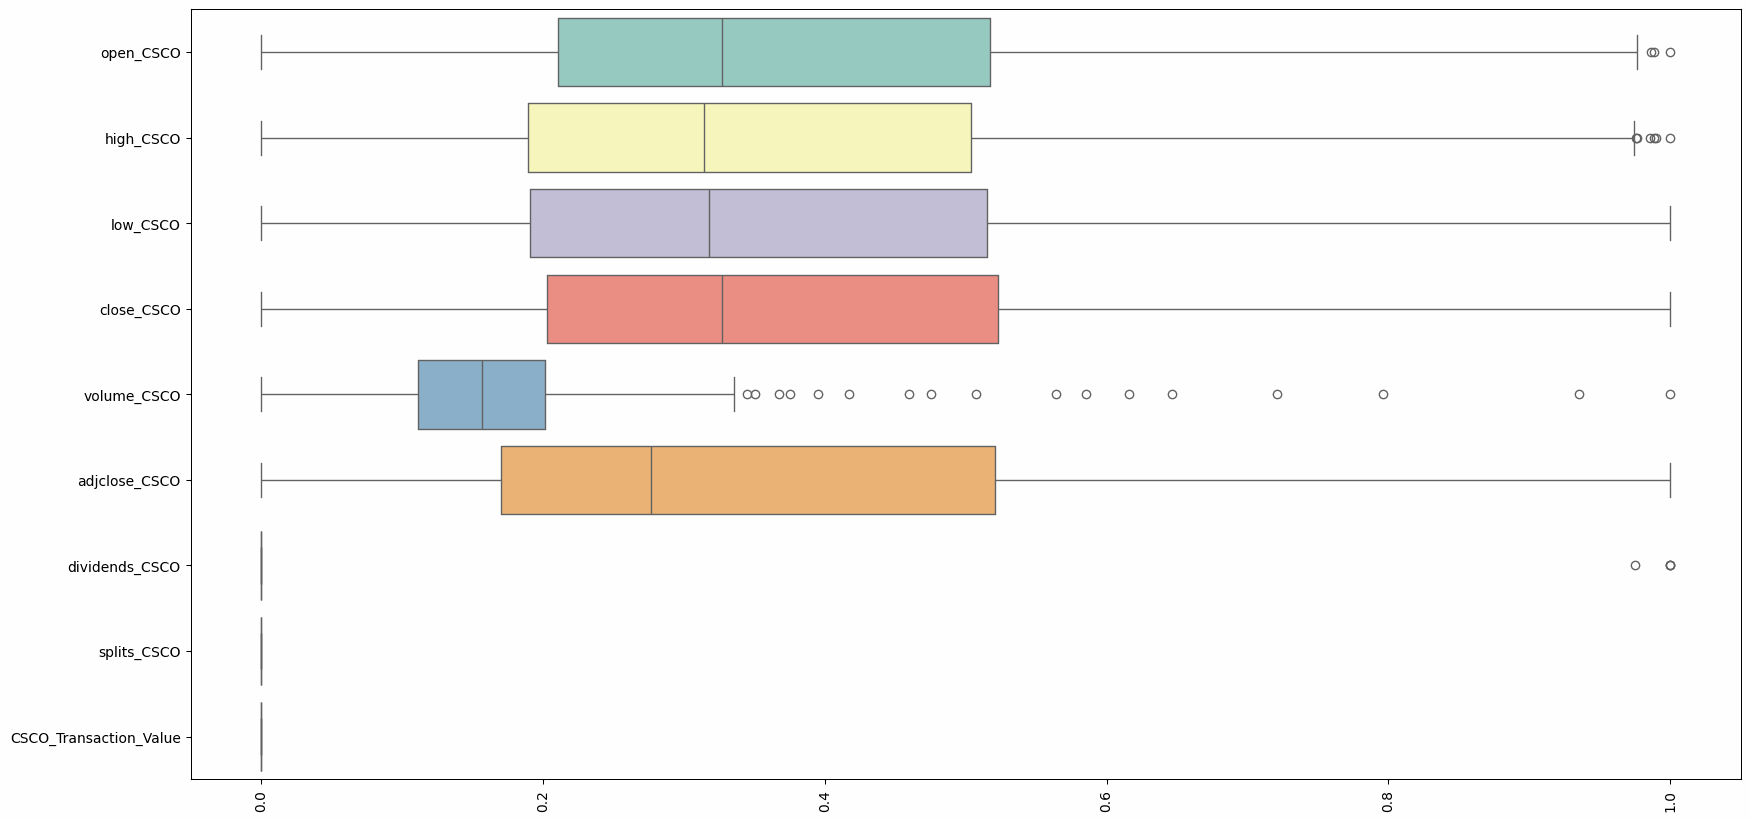

In [321]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_CSCO[num_cols_CSCO], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [322]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_CSCO[num_cols_CSCO], df_scaled_CSCO))
print("MSE:", mean_squared_error(df_CSCO[num_cols_CSCO], df_scaled_CSCO))
print("RMSE:", np.sqrt(mean_squared_error(df_CSCO[num_cols_CSCO], df_scaled_CSCO)))
print("Residuals:", df_CSCO[num_cols_CSCO] - df_scaled_CSCO)

R2, MSE, RMSE, and Residuals
R2: -80.55967759895219
MSE: 48206614954593.914
RMSE: 6943098.368494711
Residuals:             open_CSCO  high_CSCO  low_CSCO  close_CSCO  volume_CSCO  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_CSCO  dividends

## APPLIED MATERIALS (AMAT)

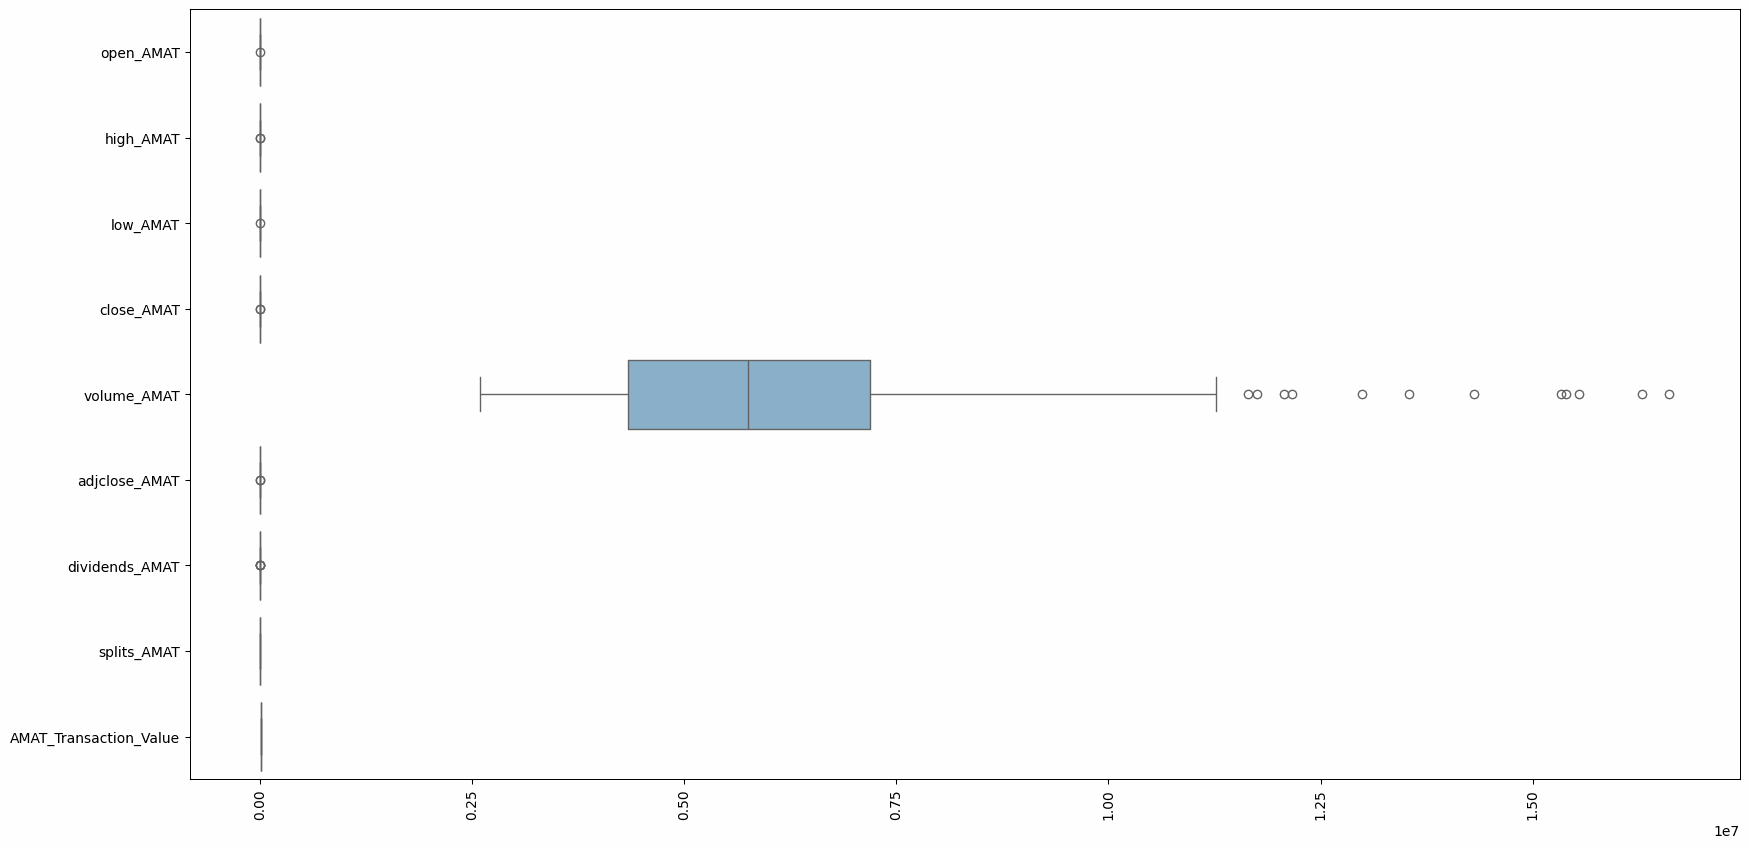

In [323]:
# Create one graph of all boxplots in AMAT
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_AMAT[num_cols_AMAT], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [324]:
# Create StandardScaler and apply to numerical columns
scaler_AMAT = StandardScaler()
scaled_values_AMAT = scaler_AMAT.fit_transform(df_AMAT[num_cols_AMAT])

# Create new DataFrame and display
df_scaled_AMAT = pd.DataFrame(scaled_values_AMAT, columns=num_cols_AMAT)
display(df_scaled_AMAT.head())

,open_AMAT,high_AMAT,low_AMAT,close_AMAT,volume_AMAT,adjclose_AMAT,dividends_AMAT,splits_AMAT,AMAT_Transaction_Value
0,-1.607162,-1.694411,-1.797625,-1.845151,0.931272,-1.872694,-0.126467,0.0,0.0
1,-1.971848,-1.996168,-1.919036,-1.973966,-0.043269,-2.001317,-0.126467,0.0,0.0
2,-2.055871,-2.047041,-2.008071,-2.068371,-0.005954,-2.095582,-0.126467,0.0,0.0
3,-2.043554,-2.067912,-2.039548,-2.082047,-0.315823,-2.109237,-0.126467,0.0,0.0
4,-2.054551,-2.012691,-1.964453,-1.969113,0.118196,-1.996472,-0.126467,0.0,0.0


In [325]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_AMAT[num_cols_AMAT], df_scaled_AMAT))
print("MSE:", mean_squared_error(df_AMAT[num_cols_AMAT], df_scaled_AMAT))
print("RMSE:", np.sqrt(mean_squared_error(df_AMAT[num_cols_AMAT], df_scaled_AMAT)))
print("Residuals:", df_AMAT[num_cols_AMAT] - df_scaled_AMAT)

R2, MSE, RMSE, and Residuals
R2: -86.39228583734285
MSE: 5022297915696.855
RMSE: 2241048.396553911
Residuals:             open_AMAT  high_AMAT  low_AMAT  close_AMAT  volume_AMAT  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AMAT  dividends_

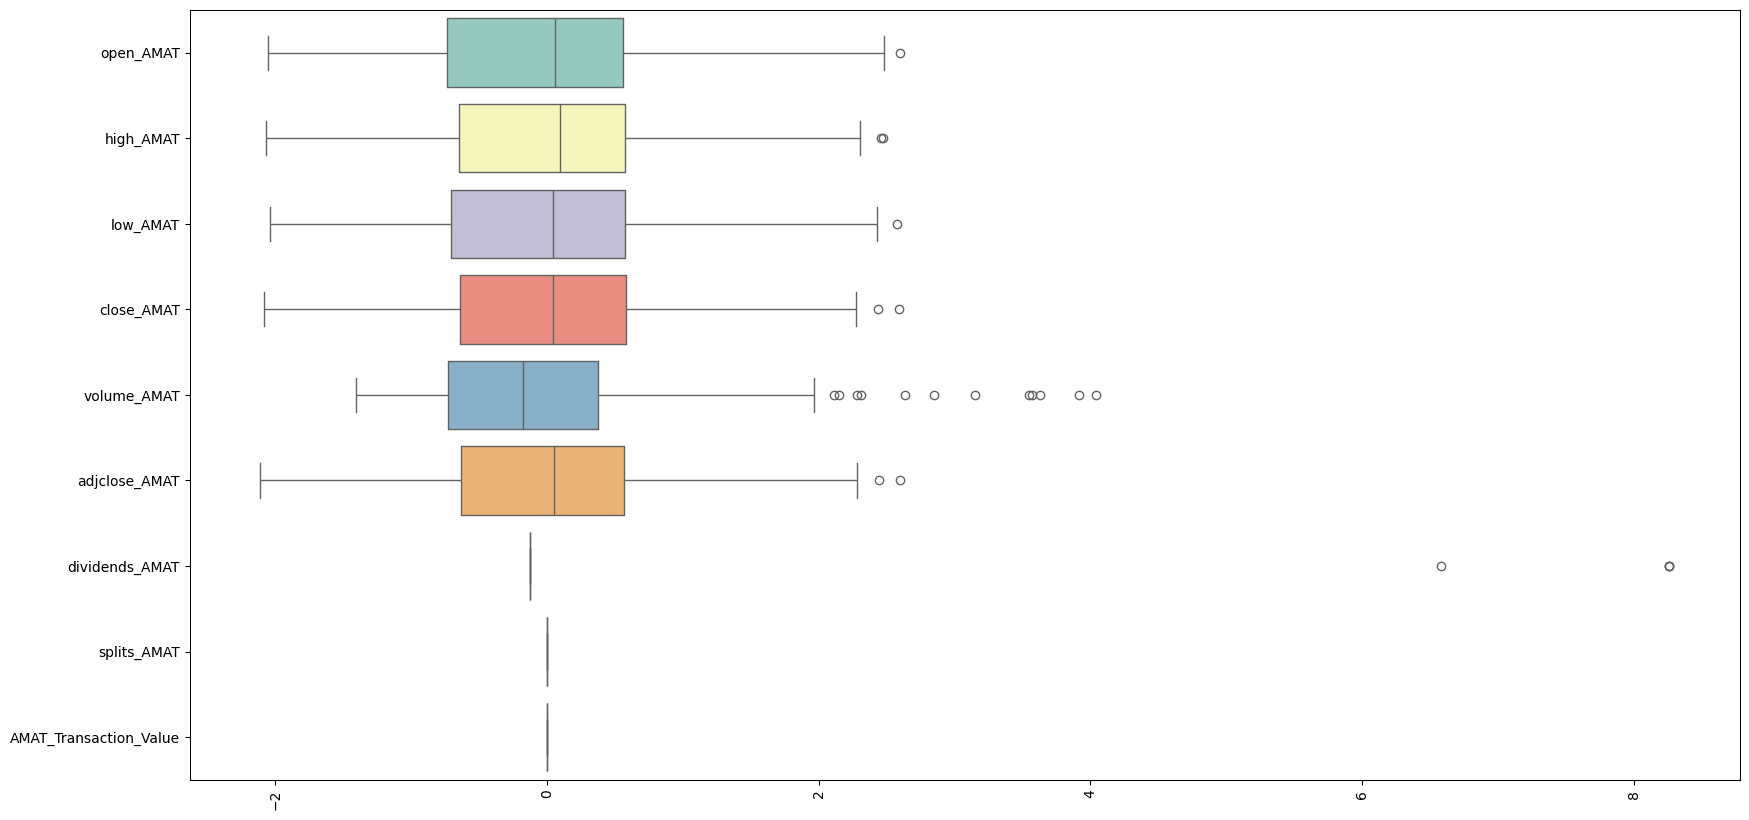

In [326]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_AMAT[num_cols_AMAT], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [327]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_AMAT[num_cols_AMAT], df_scaled_AMAT))
print("MSE:", mean_squared_error(df_AMAT[num_cols_AMAT], df_scaled_AMAT))
print("RMSE:", np.sqrt(mean_squared_error(df_AMAT[num_cols_AMAT], df_scaled_AMAT)))
print("Residuals:", df_AMAT[num_cols_AMAT] - df_scaled_AMAT)

R2, MSE, RMSE, and Residuals
R2: -86.39228583734285
MSE: 5022297915696.855
RMSE: 2241048.396553911
Residuals:             open_AMAT  high_AMAT  low_AMAT  close_AMAT  volume_AMAT  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AMAT  dividends_

### NORMALIZING

In [328]:
# Create MinMaxScaler and apply to numerical columns
scaler_AMAT = MinMaxScaler()
scaled_values_AMAT = scaler_AMAT.fit_transform(df_AMAT[num_cols_AMAT])

# Create new DataFrame and display
df_scaled_AMAT = pd.DataFrame(scaled_values_AMAT, columns=num_cols_AMAT)
display(df_scaled_AMAT.head())

,open_AMAT,high_AMAT,low_AMAT,close_AMAT,volume_AMAT,adjclose_AMAT,dividends_AMAT,splits_AMAT,AMAT_Transaction_Value
0,0.096436,0.082303,0.052431,0.050675,0.428860,0.050249,0.0,0.0,0.0
1,0.018058,0.015809,0.026118,0.023120,0.249996,0.022926,0.0,0.0,0.0
2,0.000000,0.004599,0.006822,0.002925,0.256845,0.002901,0.0,0.0,0.0
3,0.002647,0.000000,0.000000,0.000000,0.199973,0.000000,0.0,0.0,0.0
4,0.000284,0.012168,0.016275,0.024158,0.279631,0.023955,0.0,0.0,0.0


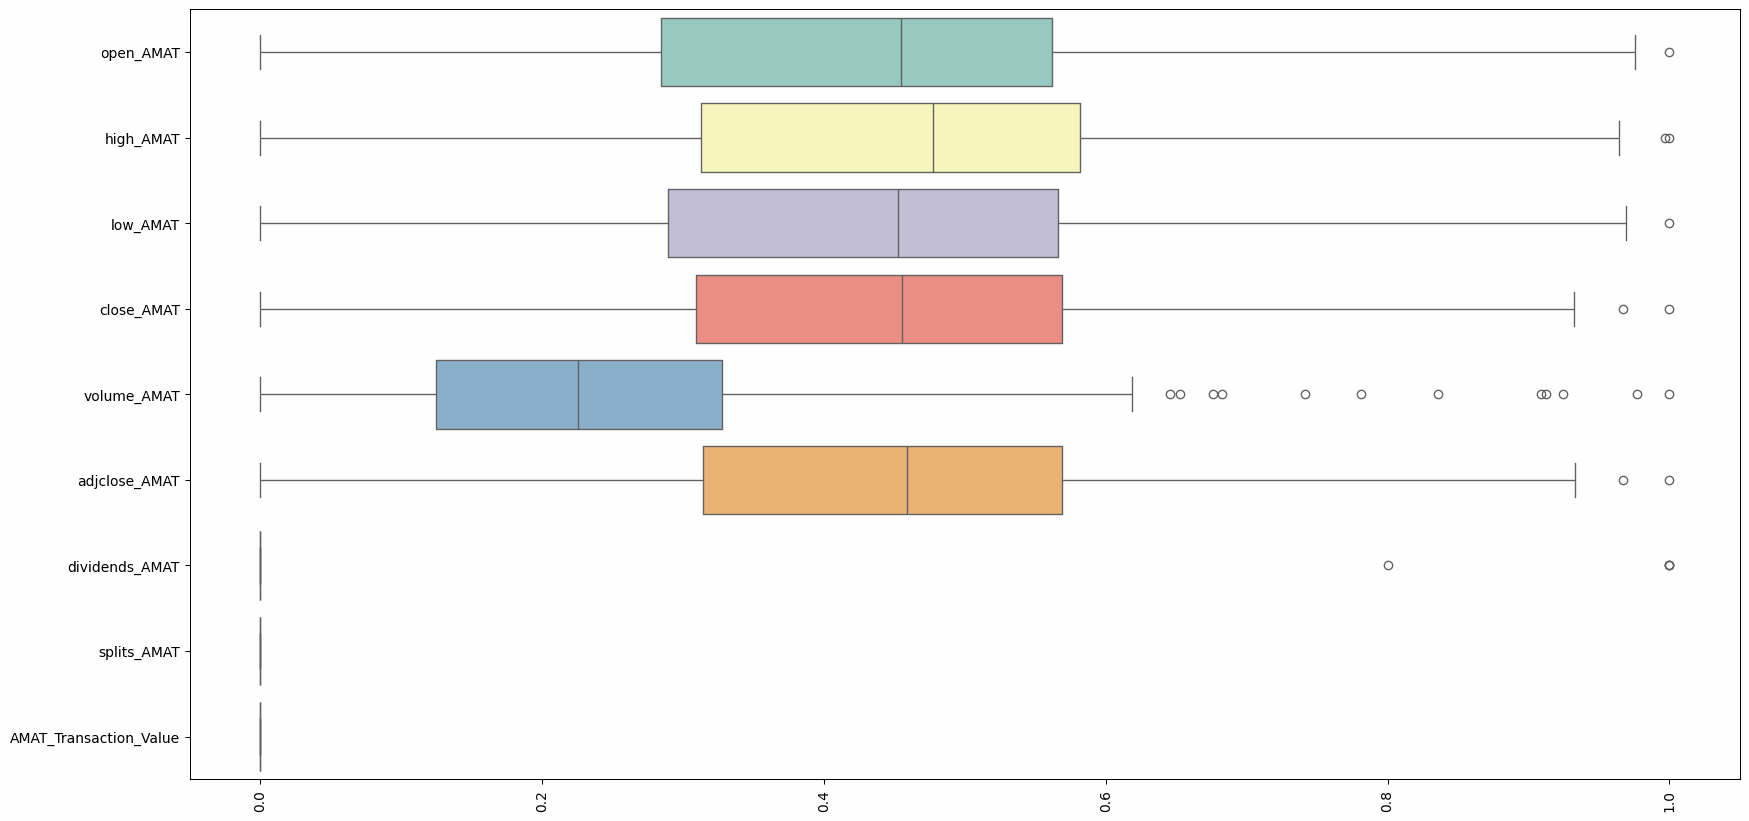

In [329]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_AMAT[num_cols_AMAT], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [330]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_AMAT[num_cols_AMAT], df_scaled_AMAT))
print("MSE:", mean_squared_error(df_AMAT[num_cols_AMAT], df_scaled_AMAT))
print("RMSE:", np.sqrt(mean_squared_error(df_AMAT[num_cols_AMAT], df_scaled_AMAT)))
print("Residuals:", df_AMAT[num_cols_AMAT] - df_scaled_AMAT)

R2, MSE, RMSE, and Residuals
R2: -42.194479050346594
MSE: 5022298026364.436
RMSE: 2241048.4212449393
Residuals:             open_AMAT  high_AMAT  low_AMAT  close_AMAT  volume_AMAT  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AMAT  dividend

## COMCAST (CMCSA)

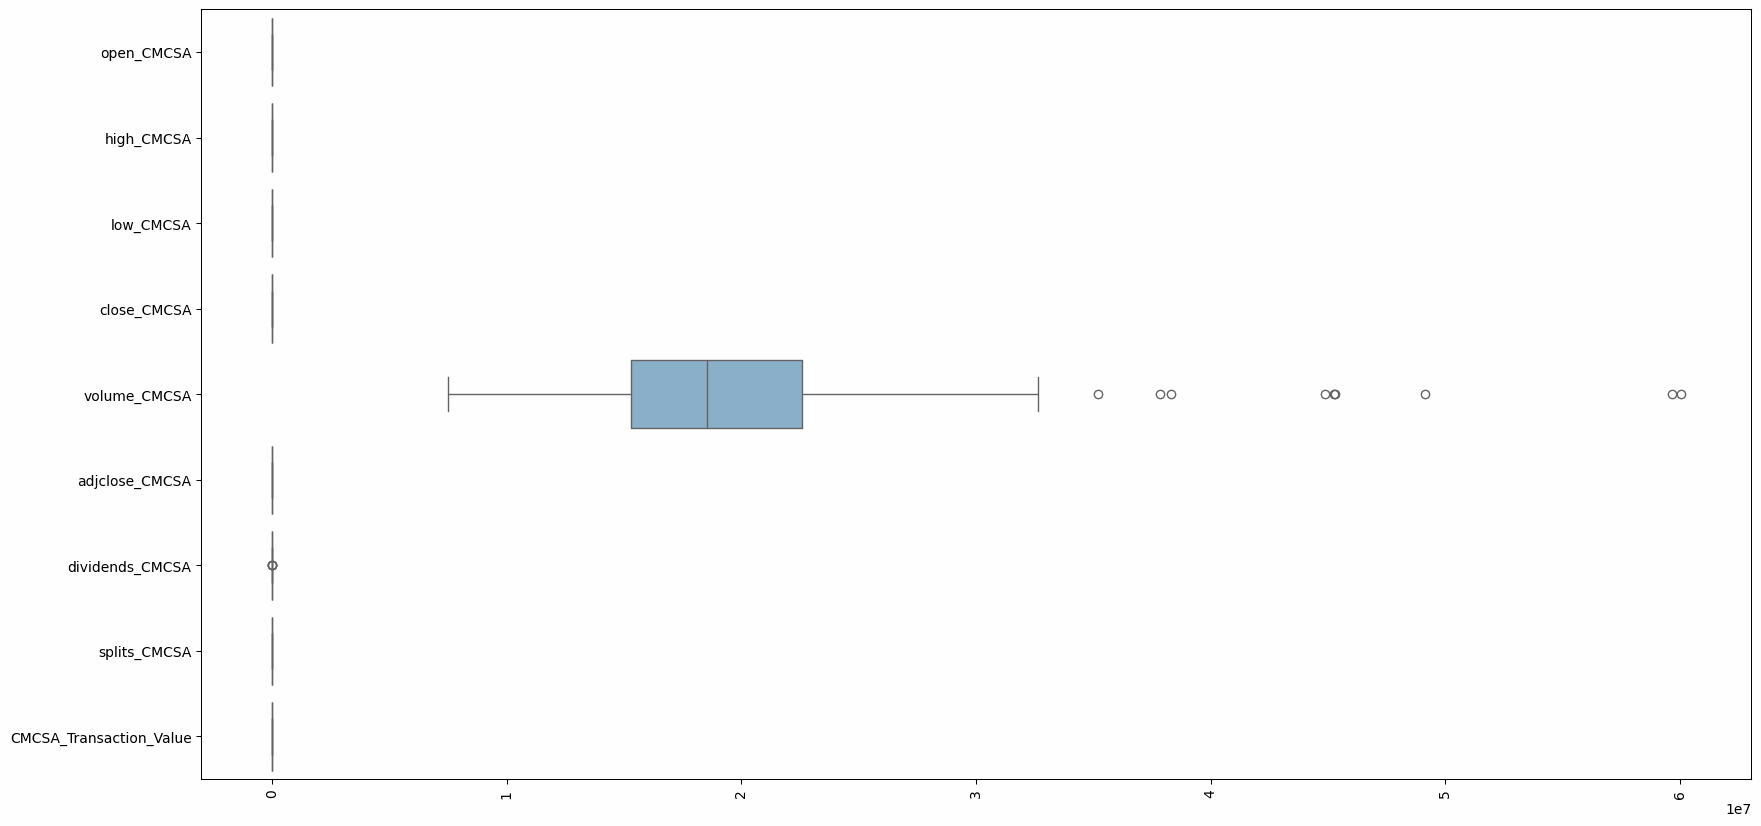

In [331]:
# Create one graph of all boxplots in CMCSA
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_CMCSA[num_cols_CMCSA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [332]:
# Create StandardScaler and apply to numerical columns
scaler_CMCSA = StandardScaler()
scaled_values_CMCSA = scaler_CMCSA.fit_transform(df_CMCSA[num_cols_CMCSA])

# Create new DataFrame and display
df_scaled_CMCSA = pd.DataFrame(scaled_values_CMCSA, columns=num_cols_CMCSA)
display(df_scaled_CMCSA.head())

,open_CMCSA,high_CMCSA,low_CMCSA,close_CMCSA,volume_CMCSA,adjclose_CMCSA,dividends_CMCSA,splits_CMCSA,CMCSA_Transaction_Value
0,1.265960,1.307983,1.339131,1.349223,-0.435793,1.142731,7.477453,0.0,0.0
1,1.321618,1.233679,1.320380,1.180339,-0.582223,0.971821,-0.126948,0.0,0.0
2,1.131451,0.987543,0.978151,0.861332,-0.014854,0.648982,-0.126948,0.0,0.0
3,0.904177,0.968968,1.090664,1.053674,-0.964103,0.843633,-0.126948,0.0,0.0
4,1.024772,1.205814,1.184425,1.377371,-0.489089,1.171219,-0.126948,0.0,0.0


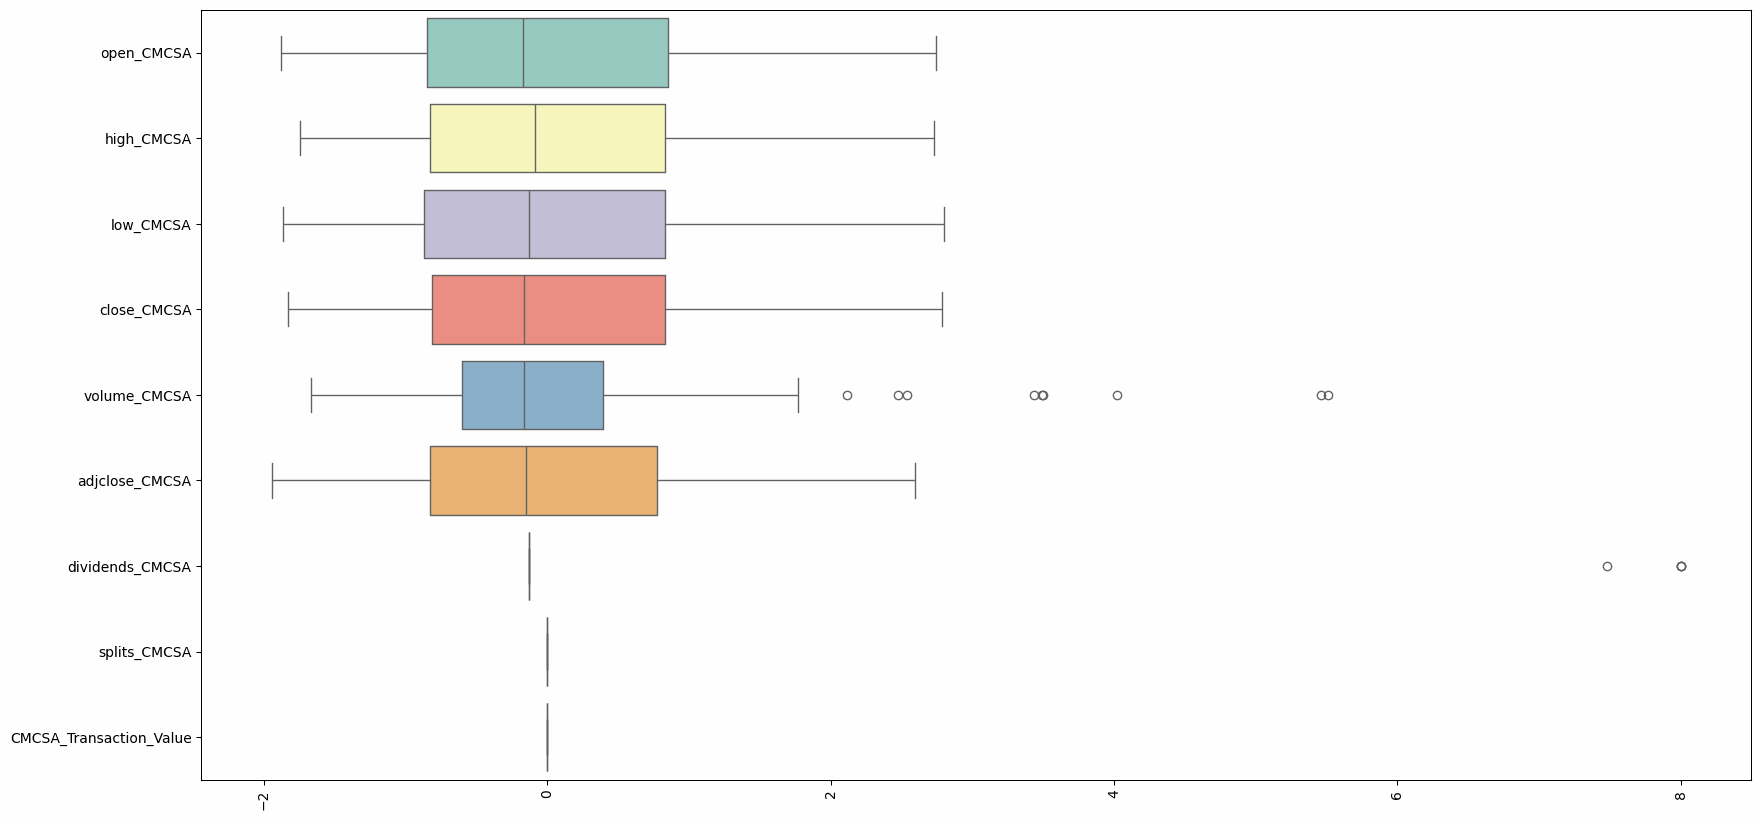

In [333]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_CMCSA[num_cols_CMCSA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [334]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_CMCSA[num_cols_CMCSA], df_scaled_CMCSA))
print("MSE:", mean_squared_error(df_CMCSA[num_cols_CMCSA], df_scaled_CMCSA))
print("RMSE:", np.sqrt(mean_squared_error(df_CMCSA[num_cols_CMCSA], df_scaled_CMCSA)))
print("Residuals:", df_CMCSA[num_cols_CMCSA] - df_scaled_CMCSA)

R2, MSE, RMSE, and Residuals
R2: -274.6414816157329
MSE: 49092955867128.97
RMSE: 7006636.55880116
Residuals:             open_CMCSA  high_CMCSA  low_CMCSA  close_CMCSA  volume_CMCSA  \
2024-01-02         NaN         NaN        NaN          NaN           NaN   
2024-01-03         NaN         NaN        NaN          NaN           NaN   
2024-01-04         NaN         NaN        NaN          NaN           NaN   
2024-01-05         NaN         NaN        NaN          NaN           NaN   
2024-01-08         NaN         NaN        NaN          NaN           NaN   
...                ...         ...        ...          ...           ...   
247                NaN         NaN        NaN          NaN           NaN   
248                NaN         NaN        NaN          NaN           NaN   
249                NaN         NaN        NaN          NaN           NaN   
250                NaN         NaN        NaN          NaN           NaN   
251                NaN         NaN        NaN          

### NORMALIZING

In [335]:
# Create MinMaxScaler and apply to numerical columns
scaler_CMCSA = MinMaxScaler()
scaled_values_CMCSA = scaler_CMCSA.fit_transform(df_CMCSA[num_cols_CMCSA])

# Create new DataFrame and display
df_scaled_CMCSA = pd.DataFrame(scaled_values_CMCSA, columns=num_cols_CMCSA)
display(df_scaled_CMCSA.head())

,open_CMCSA,high_CMCSA,low_CMCSA,close_CMCSA,volume_CMCSA,adjclose_CMCSA,dividends_CMCSA,splits_CMCSA,CMCSA_Transaction_Value
0,0.680723,0.681535,0.686432,0.688708,0.171682,0.679830,0.935484,0.0,0.0
1,0.692771,0.664938,0.682412,0.652086,0.151286,0.642164,0.000000,0.0,0.0
2,0.651606,0.609958,0.609045,0.582910,0.230318,0.571015,0.000000,0.0,0.0
3,0.602409,0.605809,0.633166,0.624619,0.098091,0.613913,0.000000,0.0,0.0
4,0.628514,0.658714,0.653266,0.694812,0.164259,0.686108,0.000000,0.0,0.0


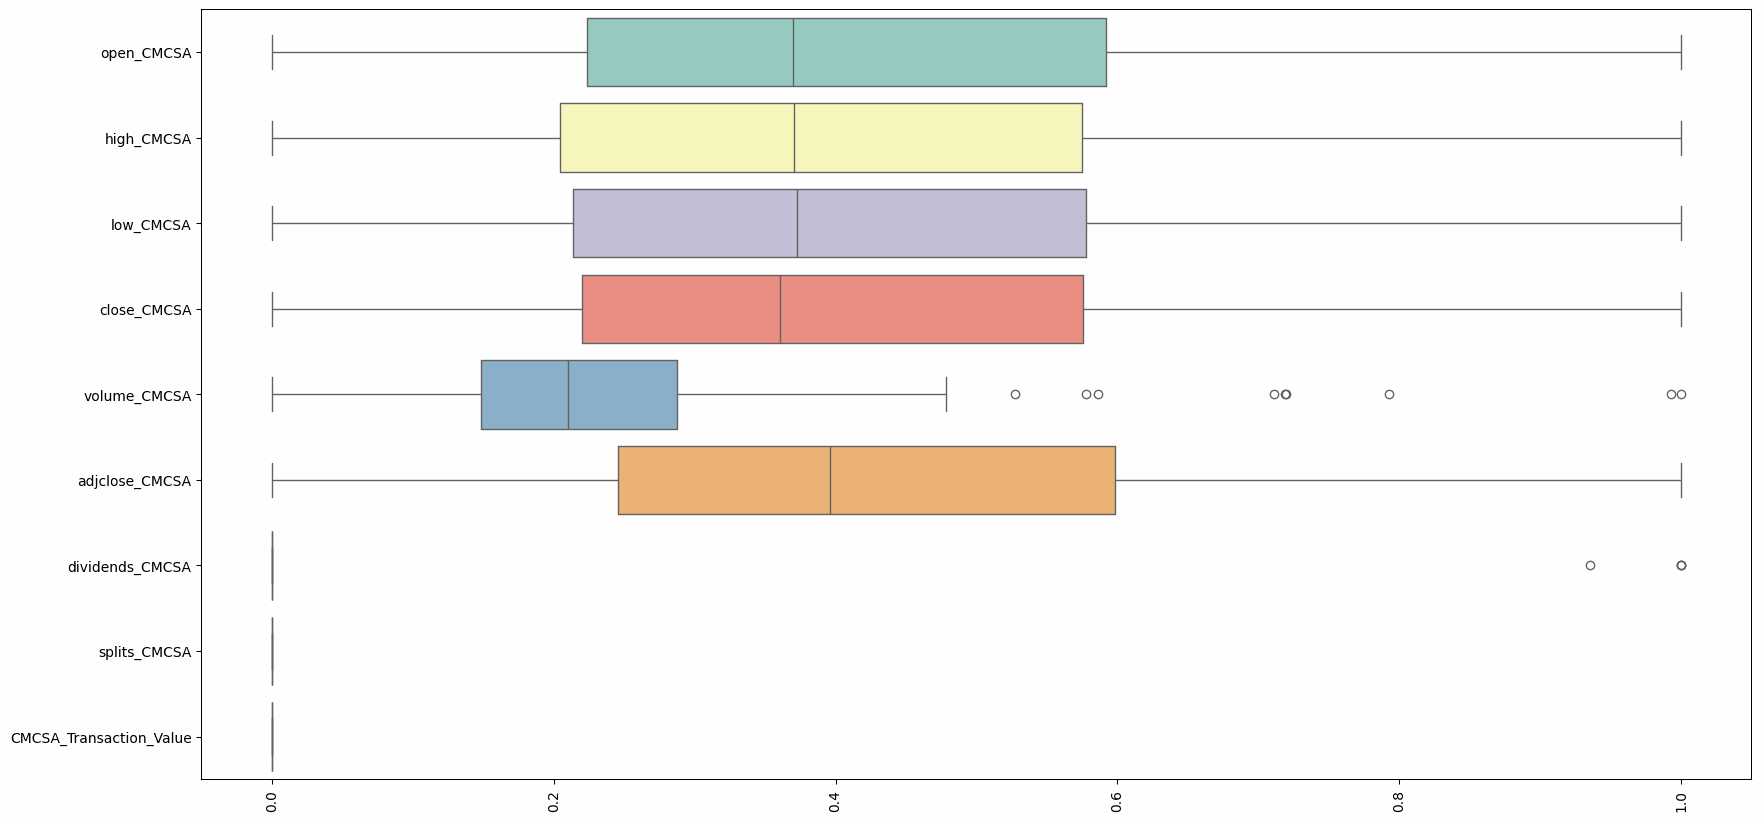

In [336]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_CMCSA[num_cols_CMCSA], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [337]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_CMCSA[num_cols_CMCSA], df_scaled_CMCSA))
print("MSE:", mean_squared_error(df_CMCSA[num_cols_CMCSA], df_scaled_CMCSA))
print("RMSE:", np.sqrt(mean_squared_error(df_CMCSA[num_cols_CMCSA], df_scaled_CMCSA)))
print("Residuals:", df_CMCSA[num_cols_CMCSA] - df_scaled_CMCSA)

R2, MSE, RMSE, and Residuals
R2: -200.77307394247862
MSE: 49092956249549.14
RMSE: 7006636.586091014
Residuals:             open_CMCSA  high_CMCSA  low_CMCSA  close_CMCSA  volume_CMCSA  \
2024-01-02         NaN         NaN        NaN          NaN           NaN   
2024-01-03         NaN         NaN        NaN          NaN           NaN   
2024-01-04         NaN         NaN        NaN          NaN           NaN   
2024-01-05         NaN         NaN        NaN          NaN           NaN   
2024-01-08         NaN         NaN        NaN          NaN           NaN   
...                ...         ...        ...          ...           ...   
247                NaN         NaN        NaN          NaN           NaN   
248                NaN         NaN        NaN          NaN           NaN   
249                NaN         NaN        NaN          NaN           NaN   
250                NaN         NaN        NaN          NaN           NaN   
251                NaN         NaN        NaN        

## MICROSOFT (MSFT)

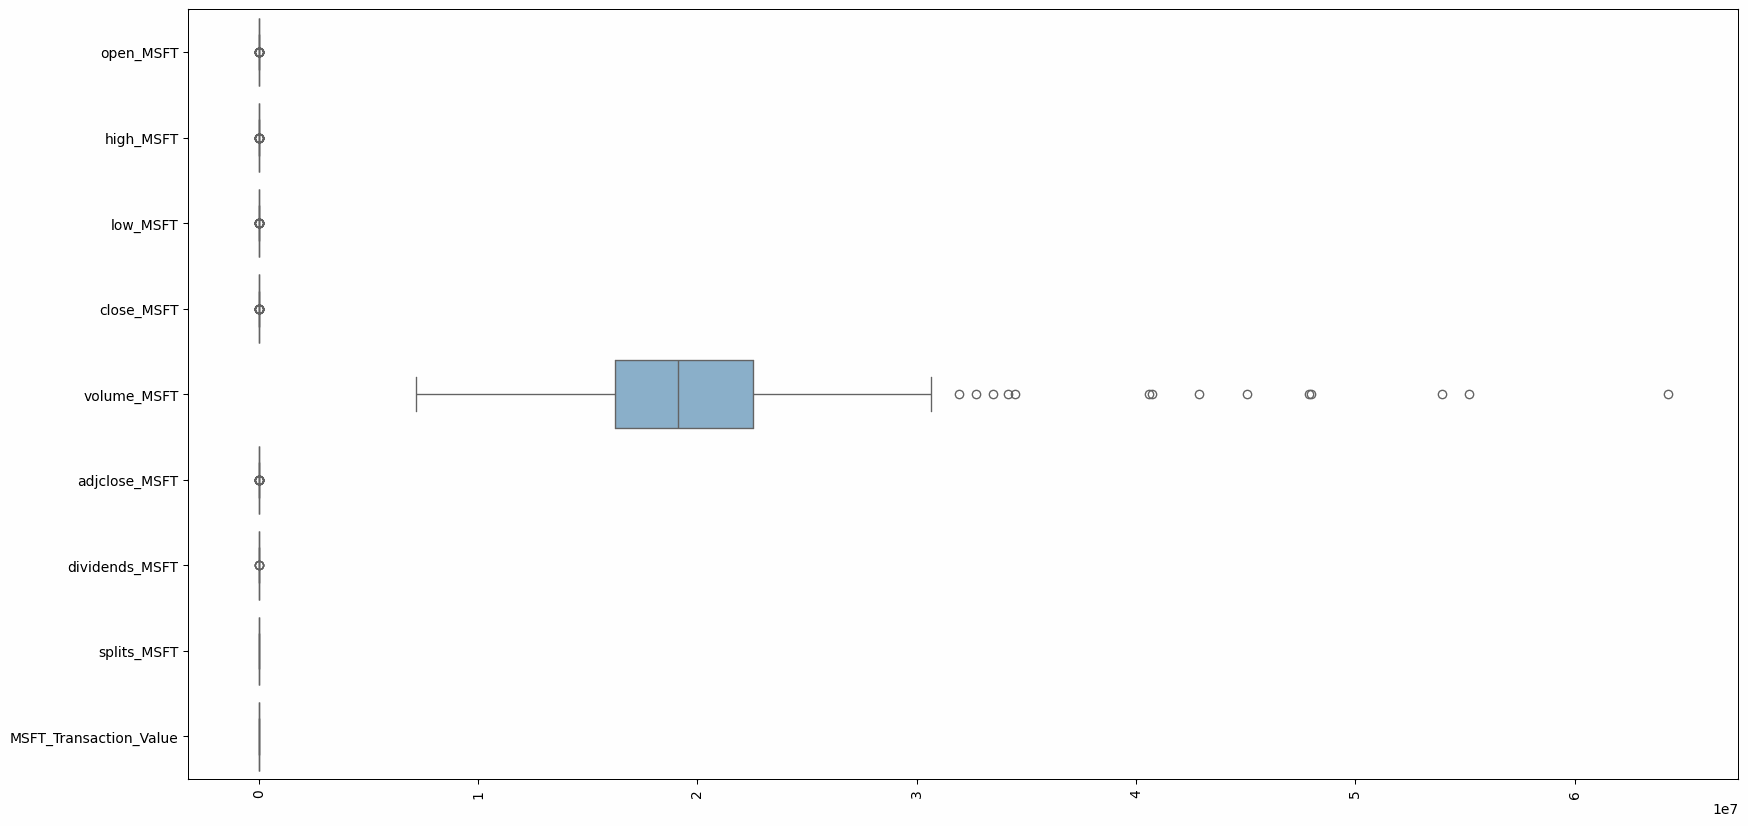

In [338]:
# Create one graph of all boxplots in MSFT
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_MSFT[num_cols_MSFT], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [339]:
# Create StandardScaler and apply to numerical columns
scaler_MSFT = StandardScaler()
scaled_values_MSFT = scaler_MSFT.fit_transform(df_MSFT[num_cols_MSFT])

# Create new DataFrame and display
df_scaled_MSFT = pd.DataFrame(scaled_values_MSFT, columns=num_cols_MSFT)
display(df_scaled_MSFT.head())

,open_MSFT,high_MSFT,low_MSFT,close_MSFT,volume_MSFT,adjclose_MSFT,dividends_MSFT,splits_MSFT,MSFT_Transaction_Value
0,-2.637012,-2.708858,-2.834004,-2.791021,0.633442,-2.793031,-0.12687,0.0,0.0
1,-2.911910,-2.858678,-2.735223,-2.806262,0.338459,-2.807815,-0.12687,0.0,0.0
2,-2.817821,-2.867758,-2.811295,-2.956419,0.042540,-2.953472,-0.12687,0.0,0.0
3,-2.914178,-2.926779,-2.849331,-2.967145,0.054135,-2.963875,-0.12687,0.0,0.0
4,-2.895474,-2.748582,-2.706838,-2.575381,0.345308,-2.583855,-0.12687,0.0,0.0


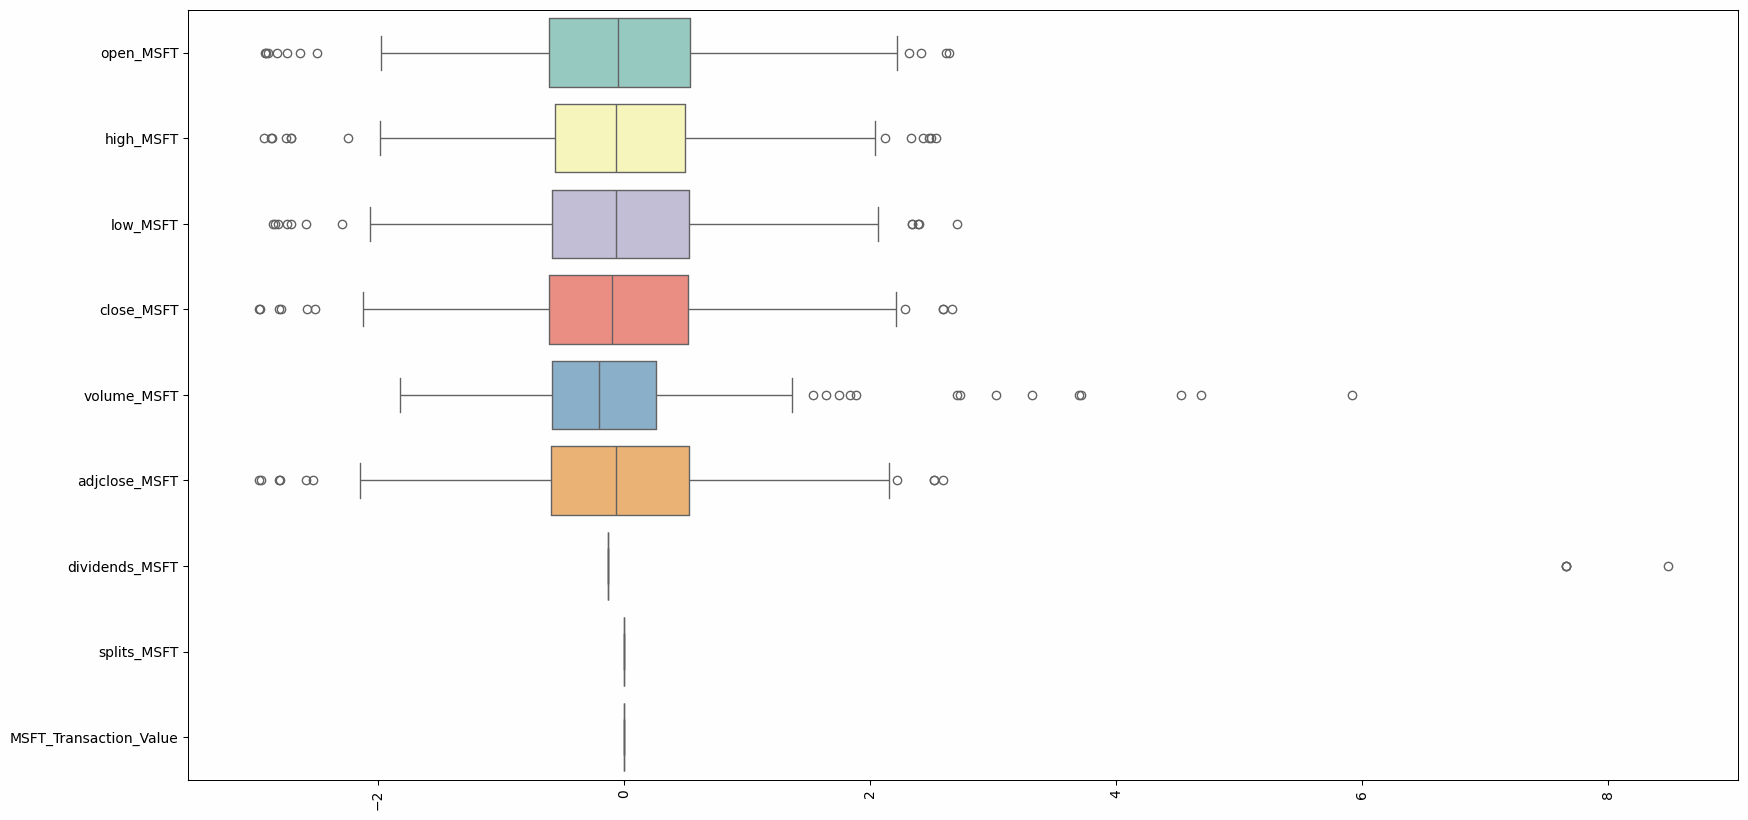

In [340]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_MSFT[num_cols_MSFT], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [341]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_MSFT[num_cols_MSFT], df_scaled_MSFT))
print("MSE:", mean_squared_error(df_MSFT[num_cols_MSFT], df_scaled_MSFT))
print("RMSE:", np.sqrt(mean_squared_error(df_MSFT[num_cols_MSFT], df_scaled_MSFT)))
print("Residuals:", df_MSFT[num_cols_MSFT] - df_scaled_MSFT)

R2, MSE, RMSE, and Residuals
R2: -321.6878805893646
MSE: 53136583107448.61
RMSE: 7289484.419864591
Residuals:             open_MSFT  high_MSFT  low_MSFT  close_MSFT  volume_MSFT  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_MSFT  dividends_

### NORMALIZING

In [342]:
# Create MinMaxScaler and apply to numerical columns
scaler_MSFT = MinMaxScaler()
scaled_values_MSFT = scaler_MSFT.fit_transform(df_MSFT[num_cols_MSFT])

# Create new DataFrame and display
df_scaled_MSFT = pd.DataFrame(scaled_values_MSFT, columns=num_cols_MSFT)
display(df_scaled_MSFT.head())

,open_MSFT,high_MSFT,low_MSFT,close_MSFT,volume_MSFT,adjclose_MSFT,dividends_MSFT,splits_MSFT,MSFT_Transaction_Value
0,0.049883,0.039879,0.002756,0.031259,0.316889,0.030733,0.0,0.0,0.0
1,0.000408,0.012462,0.020519,0.028554,0.278795,0.028073,0.0,0.0,0.0
2,0.017342,0.010801,0.006840,0.001904,0.240581,0.001871,0.0,0.0,0.0
3,0.000000,0.000000,0.000000,0.000000,0.242079,0.000000,0.0,0.0,0.0
4,0.003366,0.032610,0.025623,0.069532,0.279680,0.068361,0.0,0.0,0.0


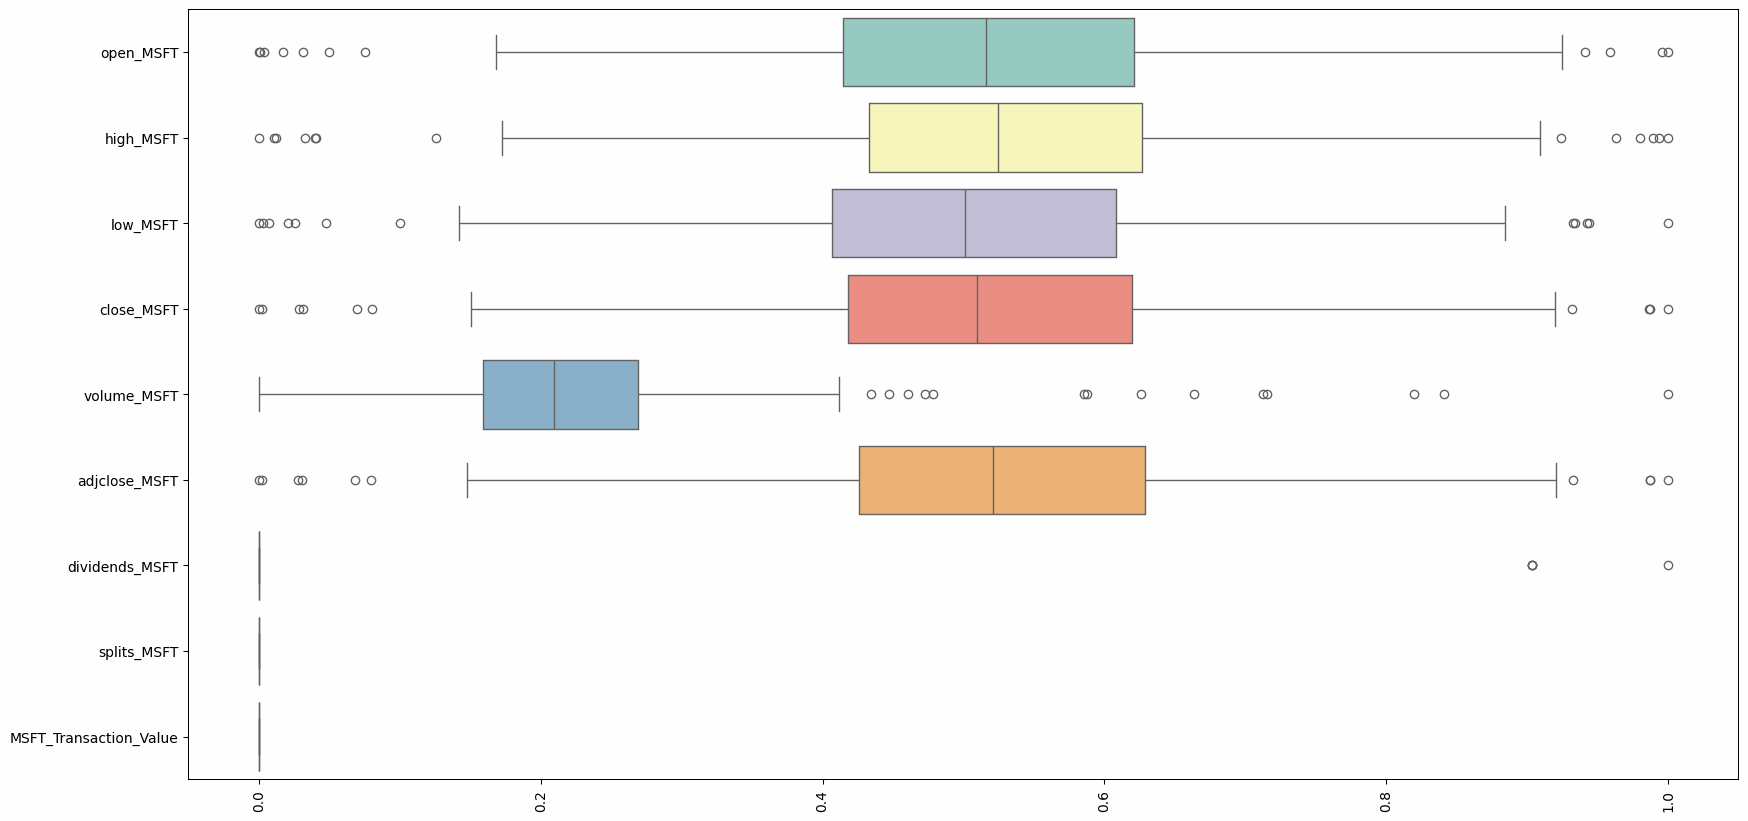

In [343]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_MSFT[num_cols_MSFT], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [344]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_MSFT[num_cols_MSFT], df_scaled_MSFT))
print("MSE:", mean_squared_error(df_MSFT[num_cols_MSFT], df_scaled_MSFT))
print("RMSE:", np.sqrt(mean_squared_error(df_MSFT[num_cols_MSFT], df_scaled_MSFT)))
print("Residuals:", df_MSFT[num_cols_MSFT] - df_scaled_MSFT)

R2, MSE, RMSE, and Residuals
R2: -311.18367256072514
MSE: 53136583458658.59
RMSE: 7289484.44395477
Residuals:             open_MSFT  high_MSFT  low_MSFT  close_MSFT  volume_MSFT  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_MSFT  dividends_

## APPLE (AAPL)

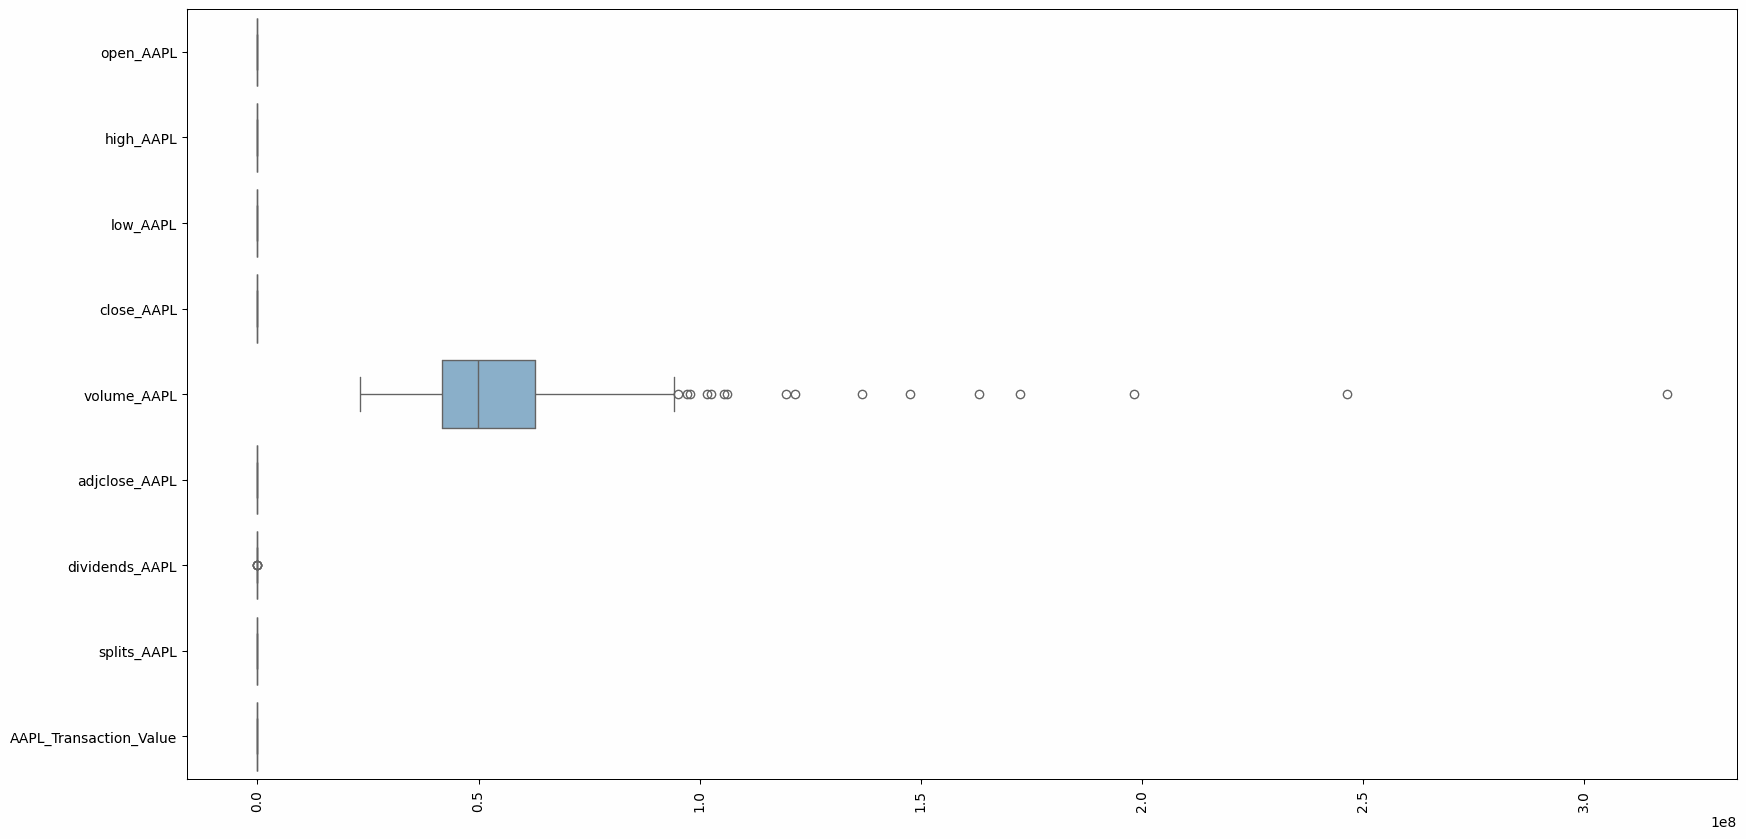

In [345]:
# Create one graph of all boxplots in AAPL
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_AAPL[num_cols_AAPL], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

### STANDARDIZING

In [346]:
# Create StandardScaler and apply to numerical columns
scaler_AAPL = StandardScaler()
scaled_values_AAPL = scaler_AAPL.fit_transform(df_AAPL[num_cols_AAPL])

# Create new DataFrame and display
df_scaled_AAPL = pd.DataFrame(scaled_values_AAPL, columns=num_cols_AAPL)
display(df_scaled_AAPL.head())

,open_AAPL,high_AAPL,low_AAPL,close_AAPL,volume_AAPL,adjclose_AAPL,dividends_AAPL,splits_AAPL,AAPL_Transaction_Value
0,-0.783238,-0.801811,-0.850244,-0.847306,0.824181,-0.858588,-0.12698,0.0,0.0
1,-0.899127,-0.902085,-0.868584,-0.901918,0.041832,-0.912485,-0.12698,0.0,0.0
2,-0.981002,-1.011368,-0.970247,-0.993854,0.482792,-1.003217,-0.12698,0.0,0.0
3,-0.987330,-1.024294,-0.998554,-1.022535,0.168208,-1.031523,-0.12698,0.0,0.0
4,-0.983375,-0.913052,-0.945529,-0.850449,0.065555,-0.861690,-0.12698,0.0,0.0


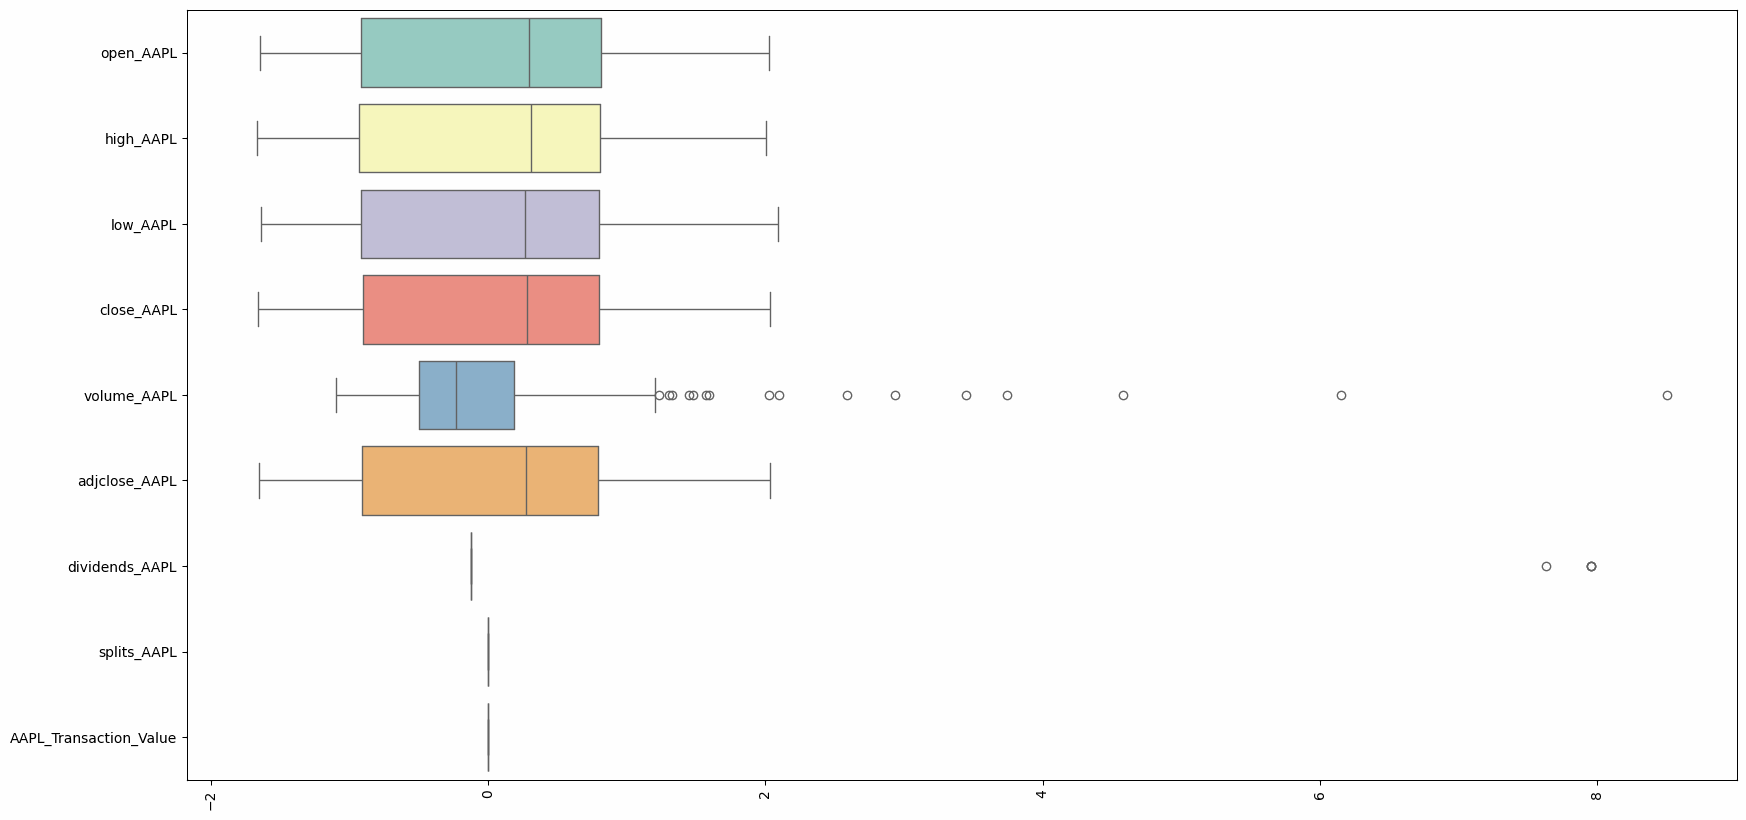

In [347]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_AAPL[num_cols_AAPL], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [348]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_AAPL[num_cols_AAPL], df_scaled_AAPL))
print("MSE:", mean_squared_error(df_AAPL[num_cols_AAPL], df_scaled_AAPL))
print("RMSE:", np.sqrt(mean_squared_error(df_AAPL[num_cols_AAPL], df_scaled_AAPL)))
print("Residuals:", df_AAPL[num_cols_AAPL] - df_scaled_AAPL)

R2, MSE, RMSE, and Residuals
R2: -146.02761920376827
MSE: 467824568498234.0
RMSE: 21629252.6107176
Residuals:             open_AAPL  high_AAPL  low_AAPL  close_AAPL  volume_AAPL  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AAPL  dividends_

### NORMALIZING

In [349]:
# Create MinMaxScaler and apply to numerical columns
scaler_AAPL = MinMaxScaler()
scaled_values_AAPL = scaler_AAPL.fit_transform(df_AAPL[num_cols_AAPL])

# Create new DataFrame and display
df_scaled_AAPL = pd.DataFrame(scaled_values_AAPL, columns=num_cols_AAPL)
display(df_scaled_AAPL.head())

,open_AAPL,high_AAPL,low_AAPL,close_AAPL,volume_AAPL,adjclose_AAPL,dividends_AAPL,splits_AAPL,AAPL_Transaction_Value
0,0.234812,0.235219,0.211758,0.219528,0.200558,0.214870,0.0,0.0,0.0
1,0.203253,0.207898,0.206841,0.204744,0.119074,0.200250,0.0,0.0,0.0
2,0.180956,0.178122,0.179583,0.179855,0.165001,0.175639,0.0,0.0,0.0
3,0.179233,0.174600,0.171994,0.172091,0.132236,0.167961,0.0,0.0,0.0
4,0.180310,0.204909,0.186211,0.218677,0.121545,0.214028,0.0,0.0,0.0


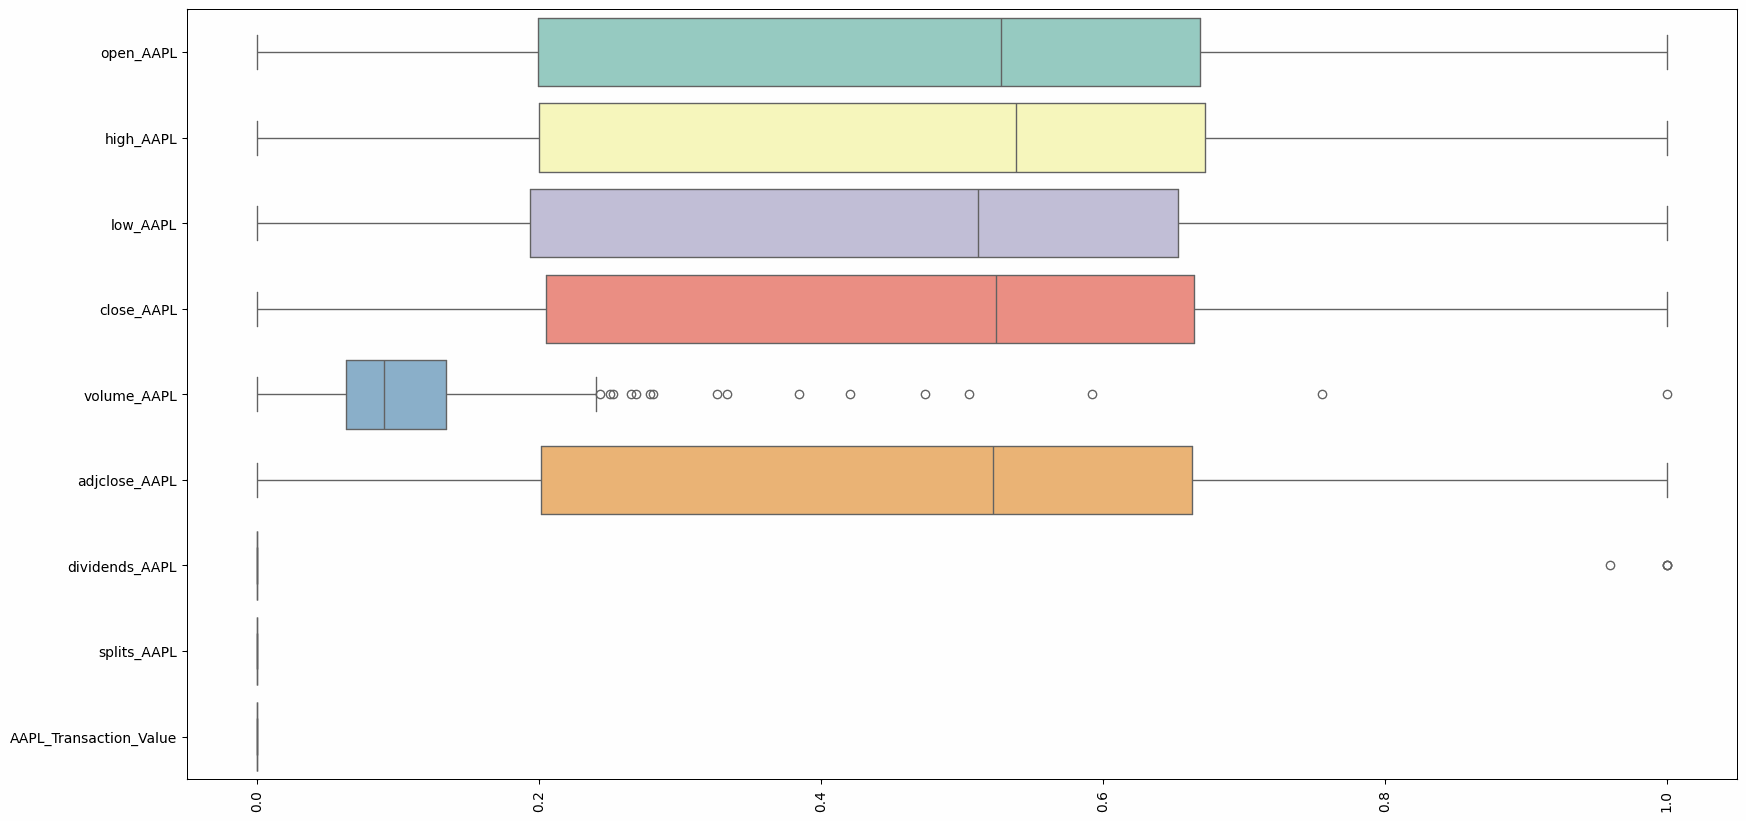

In [350]:
# Create a graph of all boxplots in df_scaled
plt.figure(figsize=(20, 10))
sns.boxplot(data=df_scaled_AAPL[num_cols_AAPL], orient='h', palette='Set3')
plt.xticks(rotation=90)
plt.show()

In [351]:
# Print R2, MSE, RMSE, and Residuals
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_AAPL[num_cols_AAPL], df_scaled_AAPL))
print("MSE:", mean_squared_error(df_AAPL[num_cols_AAPL], df_scaled_AAPL))
print("RMSE:", np.sqrt(mean_squared_error(df_AAPL[num_cols_AAPL], df_scaled_AAPL)))
print("Residuals:", df_AAPL[num_cols_AAPL] - df_scaled_AAPL)

R2, MSE, RMSE, and Residuals
R2: -37.90415544728684
MSE: 467824573167763.8
RMSE: 21629252.718662377
Residuals:             open_AAPL  high_AAPL  low_AAPL  close_AAPL  volume_AAPL  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AAPL  dividends

# COMBINED DF ANALYSIS


As part of our exploratory data analysis (EDA), we extended our initial individual stock analysis by combining all stocks into a single aggregated dataset. This approach allows us to analyze cross-stock relationships, market trends, and dependencies across different financial metrics.

1. Combined Exploratory Data Analysis (EDA)

We merged the datasets for all selected stocks (CRM, NVDA, MA, HPQ, EBAY, CSCO, AMAT, MSFT, AAPL, CMCSA) into a single consolidated DataFrame. This allowed us to:

- Examine the distribution of stock prices, trading volumes, and other key financial indicators across multiple companies.
- Identify outliers, missing values, and patterns that persist across the dataset.
- Compare individual stock performance against broader market trends.
- This combined EDA provided a holistic view of how different stocks behave within the same timeframe, enabling more insightful comparisons beyond single-stock analysis.

2. Bivariate Analysis

After the initial EDA, we performed a bivariate analysis to explore relationships between two variables at a time. This allowed us to:

- Identify correlations between adjusted closing prices, trading volume, and other financial metrics.
- Understand potential causal relationships (e.g., whether an increase in trading volume is associated with significant stock price fluctuations).
- Visualize key stock price movements over time in relation to fundamental market activities.
- We used scatter plots, correlation heatmaps, and pair plots to capture and illustrate these relationships, ensuring a clear visual representation of how different financial variables interact.

By integrating both multivariate (all stocks together) and bivariate (two-variable) analysis, we created a comprehensive framework to assess market behavior, detect trends, and make more informed observations about stock movements within the dataset.

## EDA

In [352]:
from IPython.display import display

# Display head of df
print(f"Head of df")
display(boozman_combined.head())

# Display shape of df
print(f"Shape of df")
display(boozman_combined.shape)

# Display info of df
print(f"Info of df")
display(boozman_combined.info())

# Display describe of df
print(f"Describe  of df")
display(boozman_combined.describe())

# Display missing values of df
print(f"Missing values of df")
display(boozman_combined.isnull().sum())

# Display dtypes of df
print(f"Dtypes of df")
display(boozman_combined.dtypes)

Head of df


,open_AAPL,open_AMAT,open_CMCSA,open_CRM,open_CSCO,open_EBAY,open_HPQ,open_MA,open_MSFT,open_NVDA,...,CRM_Transaction_Value,NVDA_Transaction_Value,MA_Transaction_Value,HPQ_Transaction_Value,EBAY_Transaction_Value,CSCO_Transaction_Value,AMAT_Transaction_Value,MSFT_Transaction_Value,AAPL_Transaction_Value,CMCSA_Transaction_Value
date,,,,,,,,,,,,,,,,,,,,,
2024-01-02,187.149994,160.000000,43.560001,260.540009,50.490002,43.259998,29.820000,424.089996,373.859985,49.243999,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-01-03,184.220001,151.710007,43.680000,253.500000,50.169998,43.630001,29.660000,421.200012,369.010010,47.485001,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-01-04,182.149994,149.800003,43.270000,251.830002,50.439999,43.529999,29.820000,418.500000,370.670013,47.766998,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-01-05,181.990005,150.080002,42.779999,251.210007,50.180000,42.529999,29.600000,420.489990,368.970001,48.462002,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000
2024-01-08,182.089996,149.830002,43.040001,252.210007,49.750000,42.980000,30.139999,419.440002,369.299988,49.512001,...,10000,12000,11000,9000,12000,11500,14000,10000,12500,12000


Shape of df


(252, 90)

Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 90 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   open_AAPL                252 non-null    float64
 1   open_AMAT                252 non-null    float64
 2   open_CMCSA               252 non-null    float64
 3   open_CRM                 252 non-null    float64
 4   open_CSCO                252 non-null    float64
 5   open_EBAY                252 non-null    float64
 6   open_HPQ                 252 non-null    float64
 7   open_MA                  252 non-null    float64
 8   open_MSFT                252 non-null    float64
 9   open_NVDA                252 non-null    float64
 10  high_AAPL                252 non-null    float64
 11  high_AMAT                252 non-null    float64
 12  high_CMCSA               252 non-null    float64
 13  high_CRM                 252 non-null    float64
 14  high

None

... (2 outputs left out)

Missing values of df


,0
open_AAPL,0
open_AMAT,0
open_CMCSA,0
open_CRM,0
open_CSCO,0
...,...
CSCO_Transaction_Value,0
AMAT_Transaction_Value,0
MSFT_Transaction_Value,0
AAPL_Transaction_Value,0


Dtypes of df


,0
open_AAPL,float64
open_AMAT,float64
open_CMCSA,float64
open_CRM,float64
open_CSCO,float64
...,...
CSCO_Transaction_Value,int64
AMAT_Transaction_Value,int64
MSFT_Transaction_Value,int64
AAPL_Transaction_Value,int64


## CORRELATION MATRIX

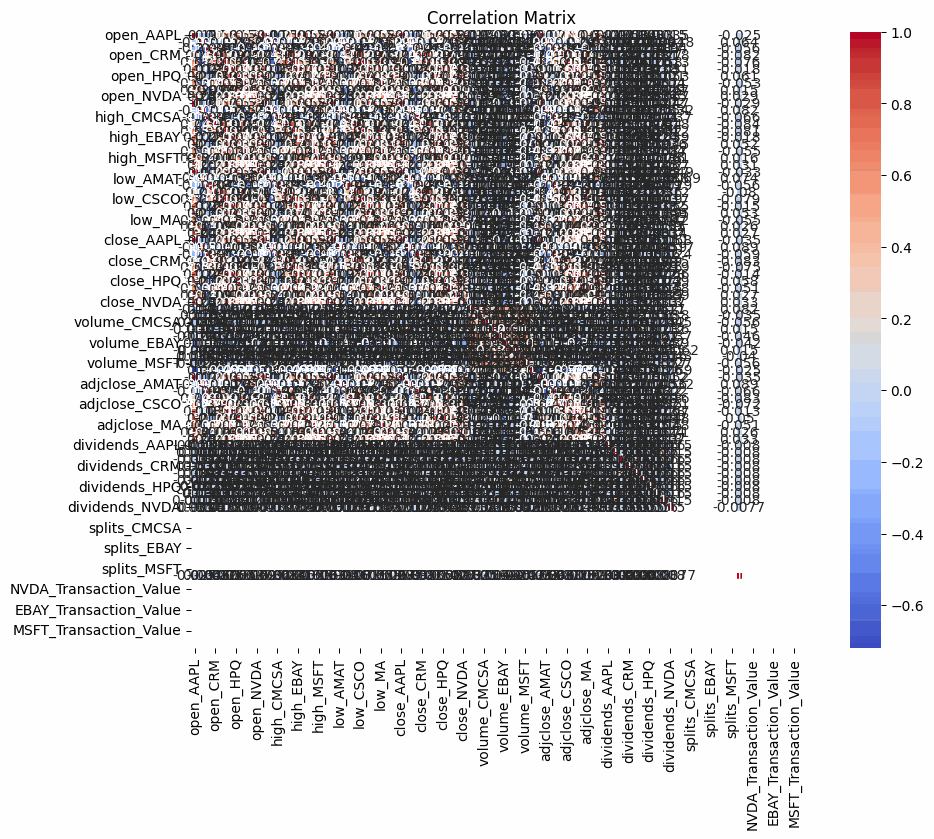

In [353]:
# Create correlation matrix
correlation_matrix = boozman_combined.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

In [354]:
# Find Tope 10 and Bottom 10 Correlation
correlation_matrix = boozman_combined.corr()

# Top 10 correaltions
top_correlations = correlation_matrix.unstack().sort_values(ascending=False)
top_correlations = top_correlations[top_correlations != 1]
top_10_correlations = top_correlations.head(10)
print("Top 10 Correlations:")
print(top_10_correlations)

# Bottom 10 correlations
bottom_correlations = correlation_matrix.unstack().sort_values(ascending=True)
bottom_correlations = bottom_correlations[bottom_correlations != 1]
bottom_10_correlations = bottom_correlations.head(10)
print("\nBottom 10 Correlations:")
print(bottom_10_correlations)

Top 10 Correlations:
close_NVDA     adjclose_NVDA    1.000000
adjclose_NVDA  close_NVDA       1.000000
adjclose_AAPL  close_AAPL       0.999980
close_AAPL     adjclose_AAPL    0.999980
close_CRM      adjclose_CRM     0.999889
adjclose_CRM   close_CRM        0.999889
close_EBAY     adjclose_EBAY    0.999872
adjclose_EBAY  close_EBAY       0.999872
adjclose_MA    close_MA         0.999852
close_MA       adjclose_MA      0.999852
dtype: float64

Bottom 10 Correlations:
adjclose_AAPL  volume_NVDA     -0.718241
volume_NVDA    adjclose_AAPL   -0.718241
               close_AAPL      -0.717838
close_AAPL     volume_NVDA     -0.717838
volume_NVDA    low_AAPL        -0.717297
low_AAPL       volume_NVDA     -0.717297
volume_NVDA    high_AAPL       -0.709278
high_AAPL      volume_NVDA     -0.709278
open_AAPL      volume_NVDA     -0.708666
volume_NVDA    open_AAPL       -0.708666
dtype: float64


# TIME SERIES

In [355]:
# From boozman_combined, create a new df with Adjclsoe variables
df_adjclose = boozman_combined[['adjclose_CRM', 'adjclose_NVDA',
                                'adjclose_MA', 'adjclose_HPQ',
                                'adjclose_EBAY', 'adjclose_CSCO', 'adjclose_AMAT',
                                'adjclose_CMCSA', 'adjclose_MSFT', 'adjclose_AAPL']]

# Reman columns using .rename()
df_adjclose = df_adjclose.rename(
    columns={
        'adjclose_CRM': 'CRM',
        'adjclose_NVDA': 'NVDA',
        'adjclose_MA': 'MA',
        'adjclose_HPQ': 'HPQ',
        'adjclose_EBAY': 'EBAY',
        'adjclose_CSCO': 'CSCO',
        'adjclose_AMAT': 'AMAT',
        'adjclose_CMCSA': 'CMCSA',
        'adjclose_MSFT': 'MSFT',
        'adjclose_AAPL': 'AAPL'
    }
)

df_adjclose.head()

,CRM,NVDA,MA,HPQ,EBAY,CSCO,AMAT,CMCSA,MSFT,AAPL
date,,,,,,,,,,
2024-01-02,254.707352,48.154346,418.846344,28.855959,43.034420,48.586620,152.821915,42.322155,367.380615,184.532089
2024-01-03,250.441177,47.555519,415.748779,28.923672,42.720520,48.964691,149.931198,41.973274,367.113159,183.150391
2024-01-04,249.844513,47.984398,416.741577,28.710857,41.719944,48.547848,147.812653,41.314259,364.478180,180.824371
2024-01-05,249.725174,49.083080,416.394135,28.972040,41.974995,48.557541,147.505768,41.711601,364.289978,180.098694
2024-01-08,259.421021,52.238190,419.595917,29.987757,42.024040,48.916218,150.040085,42.380306,371.164673,184.452560


## EDA

In [356]:
from IPython.display import display
# Display head of df
print(f"Head of df")
display(df_adjclose.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_adjclose.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_adjclose.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_adjclose.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_adjclose.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_adjclose.dtypes)

Head of df


,CRM,NVDA,MA,HPQ,EBAY,CSCO,AMAT,CMCSA,MSFT,AAPL
date,,,,,,,,,,
2024-01-02,254.707352,48.154346,418.846344,28.855959,43.034420,48.586620,152.821915,42.322155,367.380615,184.532089
2024-01-03,250.441177,47.555519,415.748779,28.923672,42.720520,48.964691,149.931198,41.973274,367.113159,183.150391
2024-01-04,249.844513,47.984398,416.741577,28.710857,41.719944,48.547848,147.812653,41.314259,364.478180,180.824371
2024-01-05,249.725174,49.083080,416.394135,28.972040,41.974995,48.557541,147.505768,41.711601,364.289978,180.098694
2024-01-08,259.421021,52.238190,419.595917,29.987757,42.024040,48.916218,150.040085,42.380306,371.164673,184.452560


	
Shape of df


(252, 10)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CRM     252 non-null    float64
 1   NVDA    252 non-null    float64
 2   MA      252 non-null    float64
 3   HPQ     252 non-null    float64
 4   EBAY    252 non-null    float64
 5   CSCO    252 non-null    float64
 6   AMAT    252 non-null    float64
 7   CMCSA   252 non-null    float64
 8   MSFT    252 non-null    float64
 9   AAPL    252 non-null    float64
dtypes: float64(10)
memory usage: 29.8+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
CRM,0
NVDA,0
MA,0
HPQ,0
EBAY,0
CSCO,0
AMAT,0
CMCSA,0
MSFT,0
AAPL,0


	
Dtypes of df


,0
CRM,float64
NVDA,float64
MA,float64
HPQ,float64
EBAY,float64
CSCO,float64
AMAT,float64
CMCSA,float64
MSFT,float64
AAPL,float64


## HISTOGRAMS

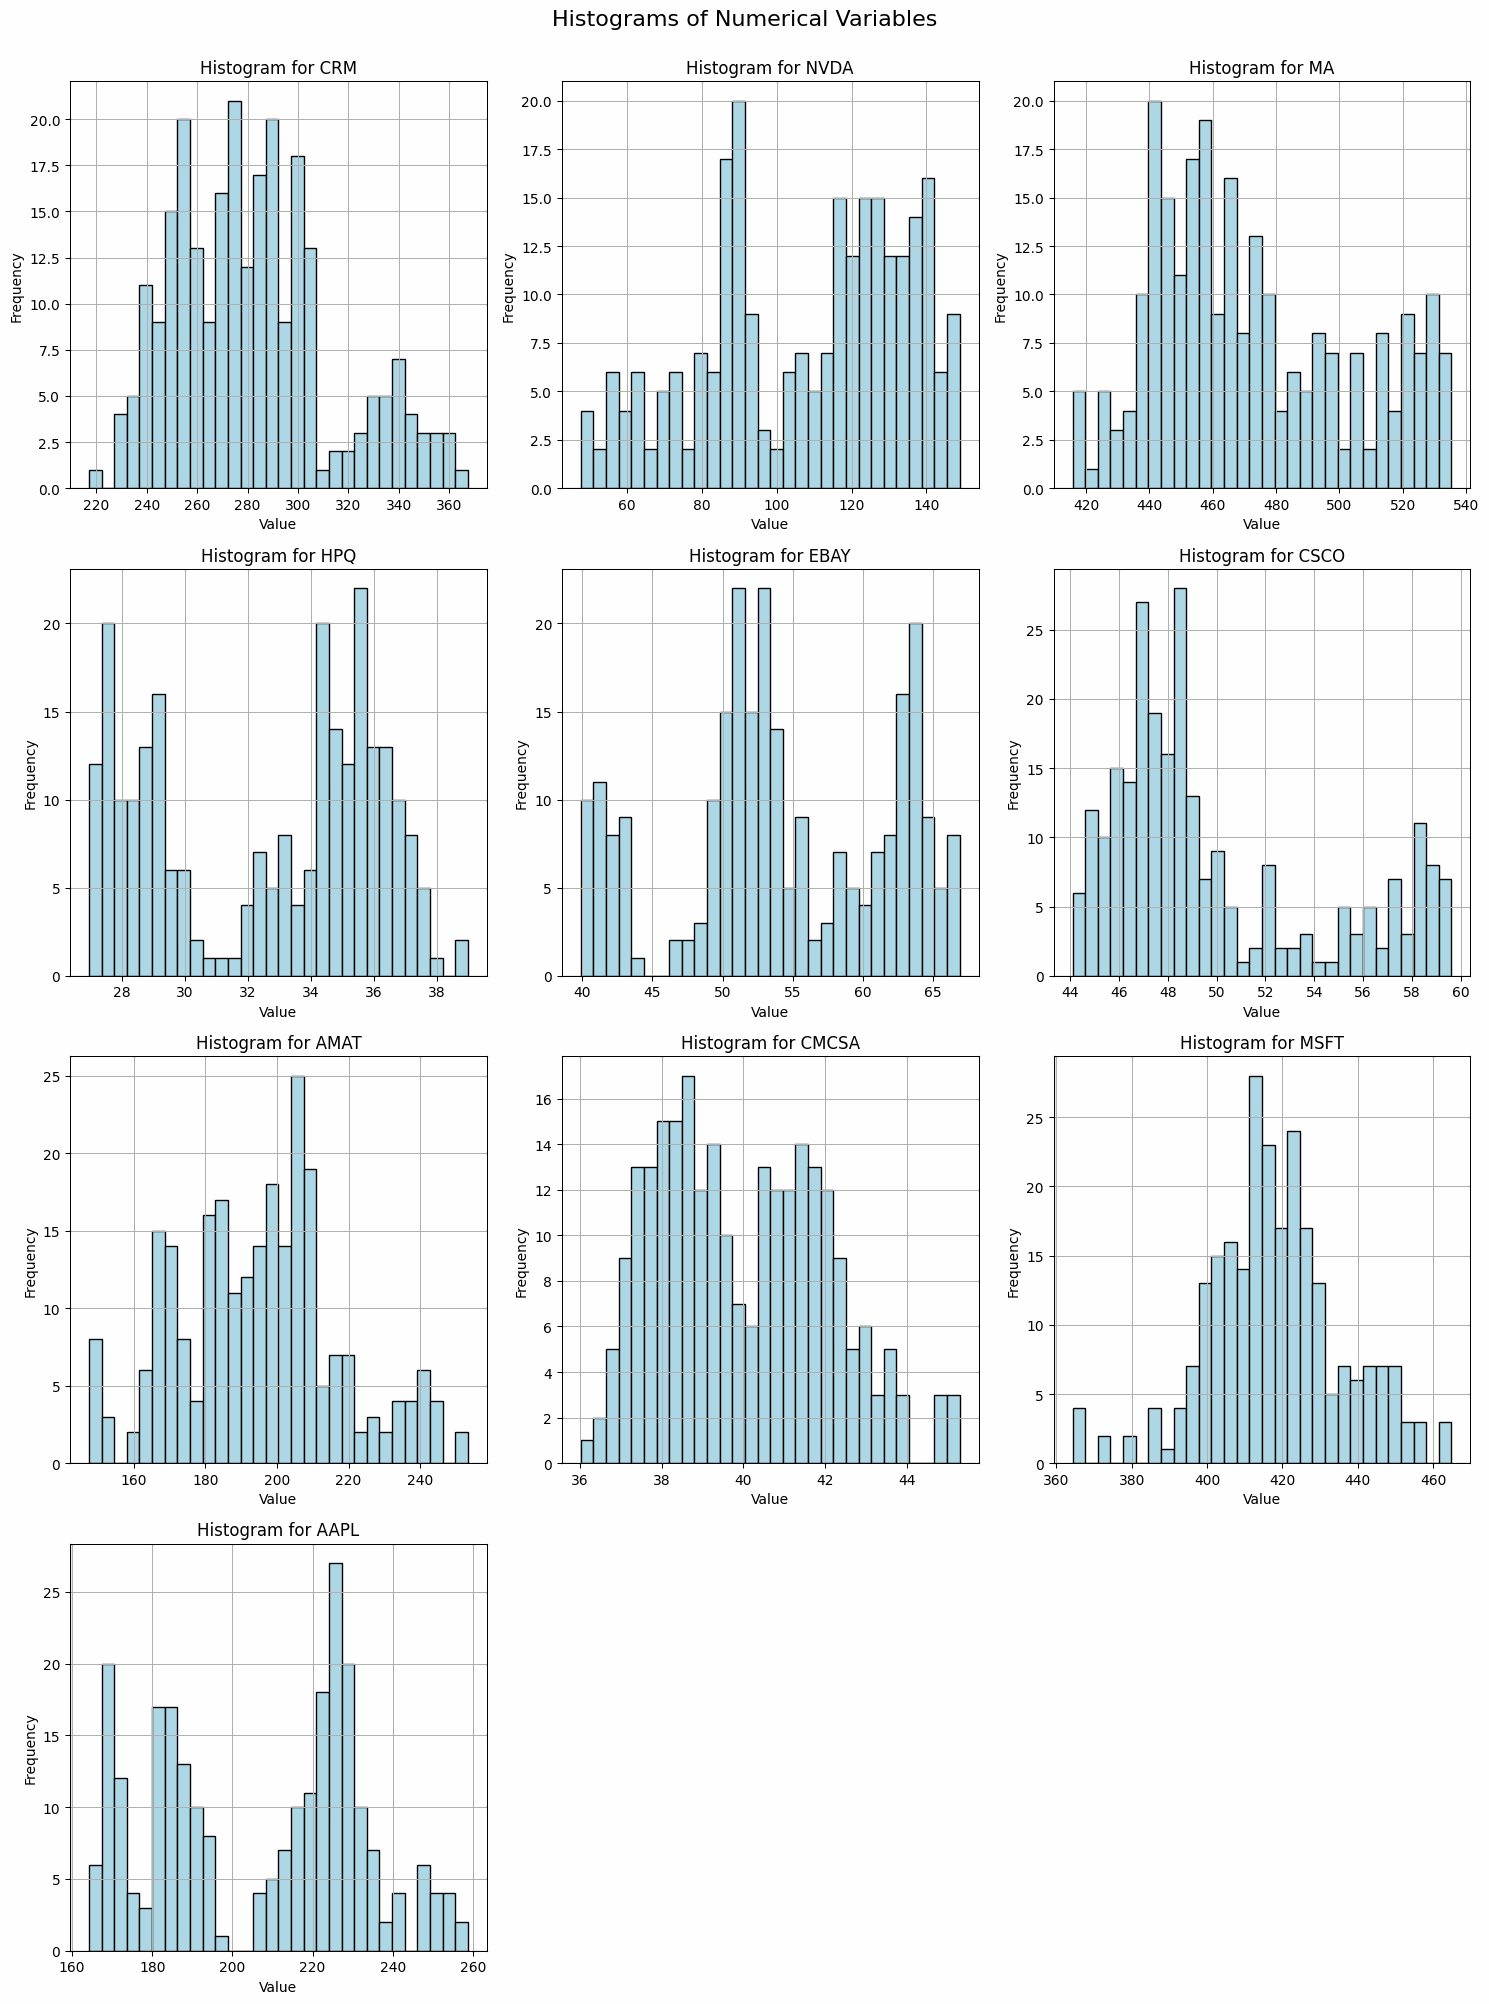

In [357]:
# Create histograms of df_adjclose
num_cols_adjclose = df_adjclose.select_dtypes(include=['float64', 'int64']).columns

plot_histograms(df_adjclose, num_cols_adjclose)

**Stock Price Distributions**

Stocks like MA and MSFT show higher closing price distributions, suggesting strong market confidence and higher valuations. In contrast, HPQ and CMCSA exhibit lower price distributions, indicating that they trade at lower valuations. The spread of closing prices across different stocks reflects differences in investor demand, market positioning, and overall stock performance.

**Volatility and Price Stability**

Stocks with wider price distributions, such as NVDA and CRM, indicate higher volatility, with significant price fluctuations over time. Conversely, CSCO and CMCSA have more compact distributions, reflecting relatively stable pricing. This distinction helps in assessing risk levels, with higher volatility stocks potentially offering greater returns but also carrying increased risk.

**Market Trends and Portfolio Diversification**

Stocks with overlapping closing price distributions suggest correlated behavior, meaning they may react similarly to market events. In contrast, stocks with distinct distributions move independently, providing opportunities for portfolio diversification. Understanding these relationships allows for better risk management and strategic investment decisions.

**Investment Implications**

The closing price analysis highlights key valuation trends, helping investors assess stock performance and risk exposure. Stocks with higher valuations may reflect strong growth potential but could also be more susceptible to market corrections. Meanwhile, lower-valued stocks may present buying opportunities if underlying fundamentals support long-term growth. Identifying stable and volatile stocks aids in constructing balanced portfolios that align with different risk appetites.

## BOXPLOTS

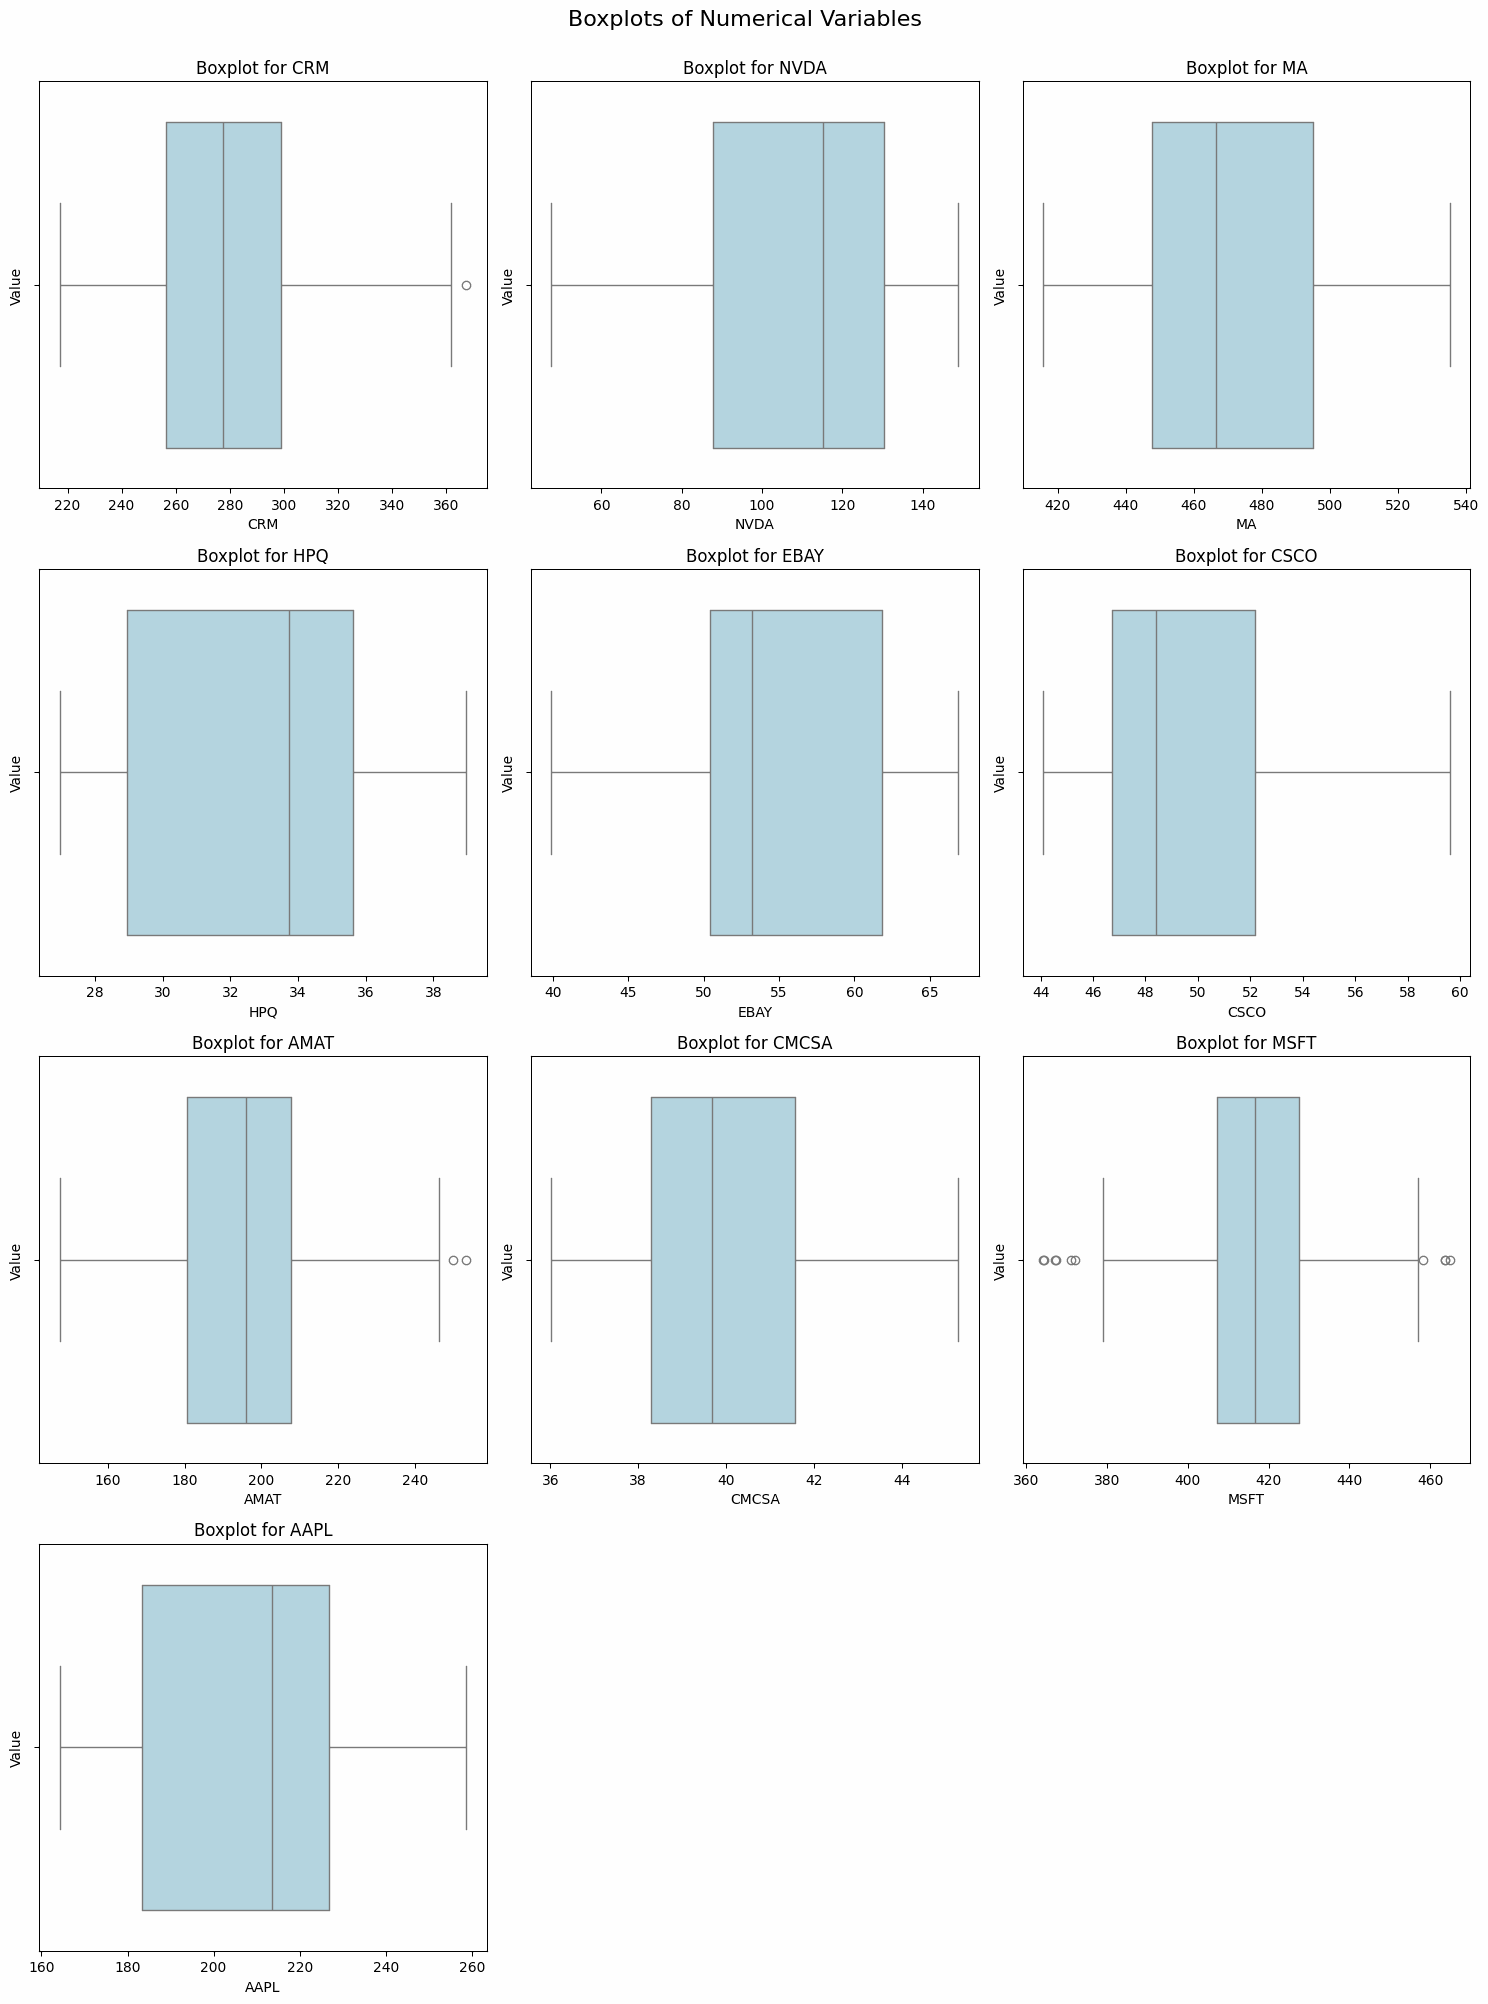

In [358]:
# Create histograms of df_adjclose
num_cols_adjclose = df_adjclose.select_dtypes(include=['float64', 'int64']).columns

plot_boxplots(df_adjclose, num_cols_adjclose)

**Stock Price Distributions and Volatility**

Stocks such as MA and MSFT exhibit higher median closing prices, indicating their relatively stronger market valuations. In contrast, HPQ and CMCSA have lower median prices, suggesting they trade at lower valuations compared to the rest of the dataset. The interquartile range (IQR) for stocks like NVDA and CRM appears wider, reflecting greater price variability, while stocks like CSCO and CMCSA have a more compressed range, suggesting lower volatility.

**Presence of Outliers**

Outliers are visible in stocks like AMAT and MSFT, indicating occasional sharp price deviations from typical trading ranges. These anomalies could be the result of market events, earnings reports, or external economic factors that led to sudden price fluctuations. The absence of significant outliers in stocks like EBAY and HPQ suggests that their price movements have been relatively stable within expected market trends.

**Investment Implications**

The boxplot analysis suggests that stocks with higher medians and larger IQRs may be suitable for investors seeking growth opportunities but willing to accept increased volatility. Conversely, stocks with narrower price distributions may appeal to risk-averse investors looking for stability. Identifying stocks with frequent outliers can provide insights into price sensitivity, helping investors assess potential risks and opportunities associated with market fluctuations.

## CORREALTION MATRIX

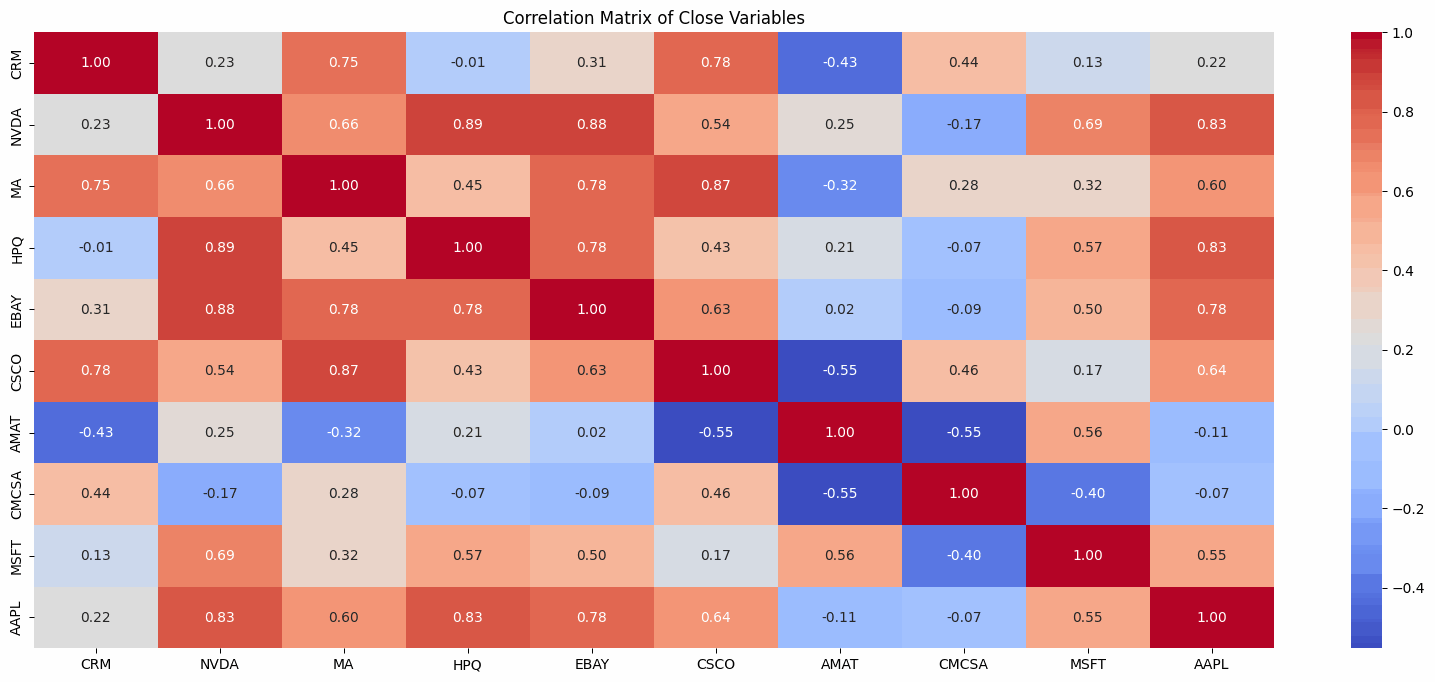

In [359]:
# Create correlation matrix
plt.figure(figsize=(20, 8))
sns.heatmap(df_adjclose.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Close Variables')
plt.show()

**Correlation Analysis of Closing Prices**

**Overview**

The correlation matrix provides insights into the relationships between the closing prices of multiple stocks. A strong positive correlation indicates that stocks tend to move together, while a weak or negative correlation suggests independent or inverse price movements. However, correlation does not imply causation—just because two stocks move similarly does not mean one causes the movement of the other. External factors such as market trends, macroeconomic conditions, and sector performance can influence multiple stocks simultaneously.

**High Correlation Pairs**

Several stocks exhibit strong positive correlations, suggesting they experience similar price trends. HPQ and NVDA (0.89), NVDA and AAPL (0.83), EBAY and HPQ (0.78), and MA and CSCO (0.87) demonstrate high correlations, indicating that their price movements are closely related. This suggests that these stocks may be influenced by similar market factors, such as industry trends or macroeconomic conditions. However, this does not mean that a rise in NVDA directly causes a rise in HPQ; rather, both may be responding to broader industry dynamics.

**Moderate Correlation Relationships**

Moderate correlations are observed in stocks such as CRM and MA (0.75) and EBAY and CSCO (0.63), indicating a partial relationship where price movements are somewhat aligned but not entirely dependent on each other. These stocks might share exposure to broader market movements but are also affected by sector-specific events.

**Weak and Negative Correlations**

Certain stocks show weak or negative correlations, implying independent or diverging price trends. AMAT has weak or negative correlations with multiple stocks, including CRM (-0.43), CSCO (-0.55), and MSFT (-0.40), indicating that its price movements are largely independent of these companies. Similarly, CMCSA and AMAT (-0.55) exhibit a negative correlation, suggesting that their price trends often move in opposite directions. This highlights that stocks within different industries may not react similarly to market changes.

**Market Implications**

High correlation stocks tend to move in the same direction, making them less effective for diversification within a portfolio. Investors looking for diversification should consider stocks with weak or negative correlations, such as AMAT and CMCSA, as their movements are less synchronized with the broader market trends. However, it is important to emphasize that correlation is not causation—just because two stocks have similar movements does not mean one directly influences the other. Understanding these relationships helps in making strategic investment decisions based on market movements, industry trends, and risk exposure.

In [360]:
# Find Top 10 and Bottom 10 Correlation
correlation_matrix = df_adjclose.corr()

# Top 10 correlations
top_correlations = correlation_matrix.unstack().sort_values(ascending=False)
top_correlations = top_correlations[top_correlations != 1]  # Exclude self-correlations
top_10_correlations = top_correlations.head(10)
print("Top 10 Correlations:")
display(top_10_correlations)

# Bottom 10 correlations
bottom_correlations = correlation_matrix.unstack().sort_values(ascending=True)
bottom_10_correlations = bottom_correlations.head(10)
print("\nBottom 10 Correlations:")
display(bottom_10_correlations)

Top 10 Correlations:


,,0
NVDA,HPQ,0.890039
HPQ,NVDA,0.890039
NVDA,EBAY,0.879218
EBAY,NVDA,0.879218
MA,CSCO,0.873326
CSCO,MA,0.873326
AAPL,HPQ,0.830369
HPQ,AAPL,0.830369
AAPL,NVDA,0.825049
NVDA,AAPL,0.825049



Bottom 10 Correlations:


CMCSA  AMAT    -0.552275
AMAT   CMCSA   -0.552275
CSCO   AMAT    -0.548027
AMAT   CSCO    -0.548027
       CRM     -0.433573
CRM    AMAT    -0.433573
CMCSA  MSFT    -0.397850
MSFT   CMCSA   -0.397850
MA     AMAT    -0.316405
AMAT   MA      -0.316405
dtype: float64

## PAIRPLOTS

We then created pair plots of all closing variables to visualise all adjusted close prices together for multivariable analysis.

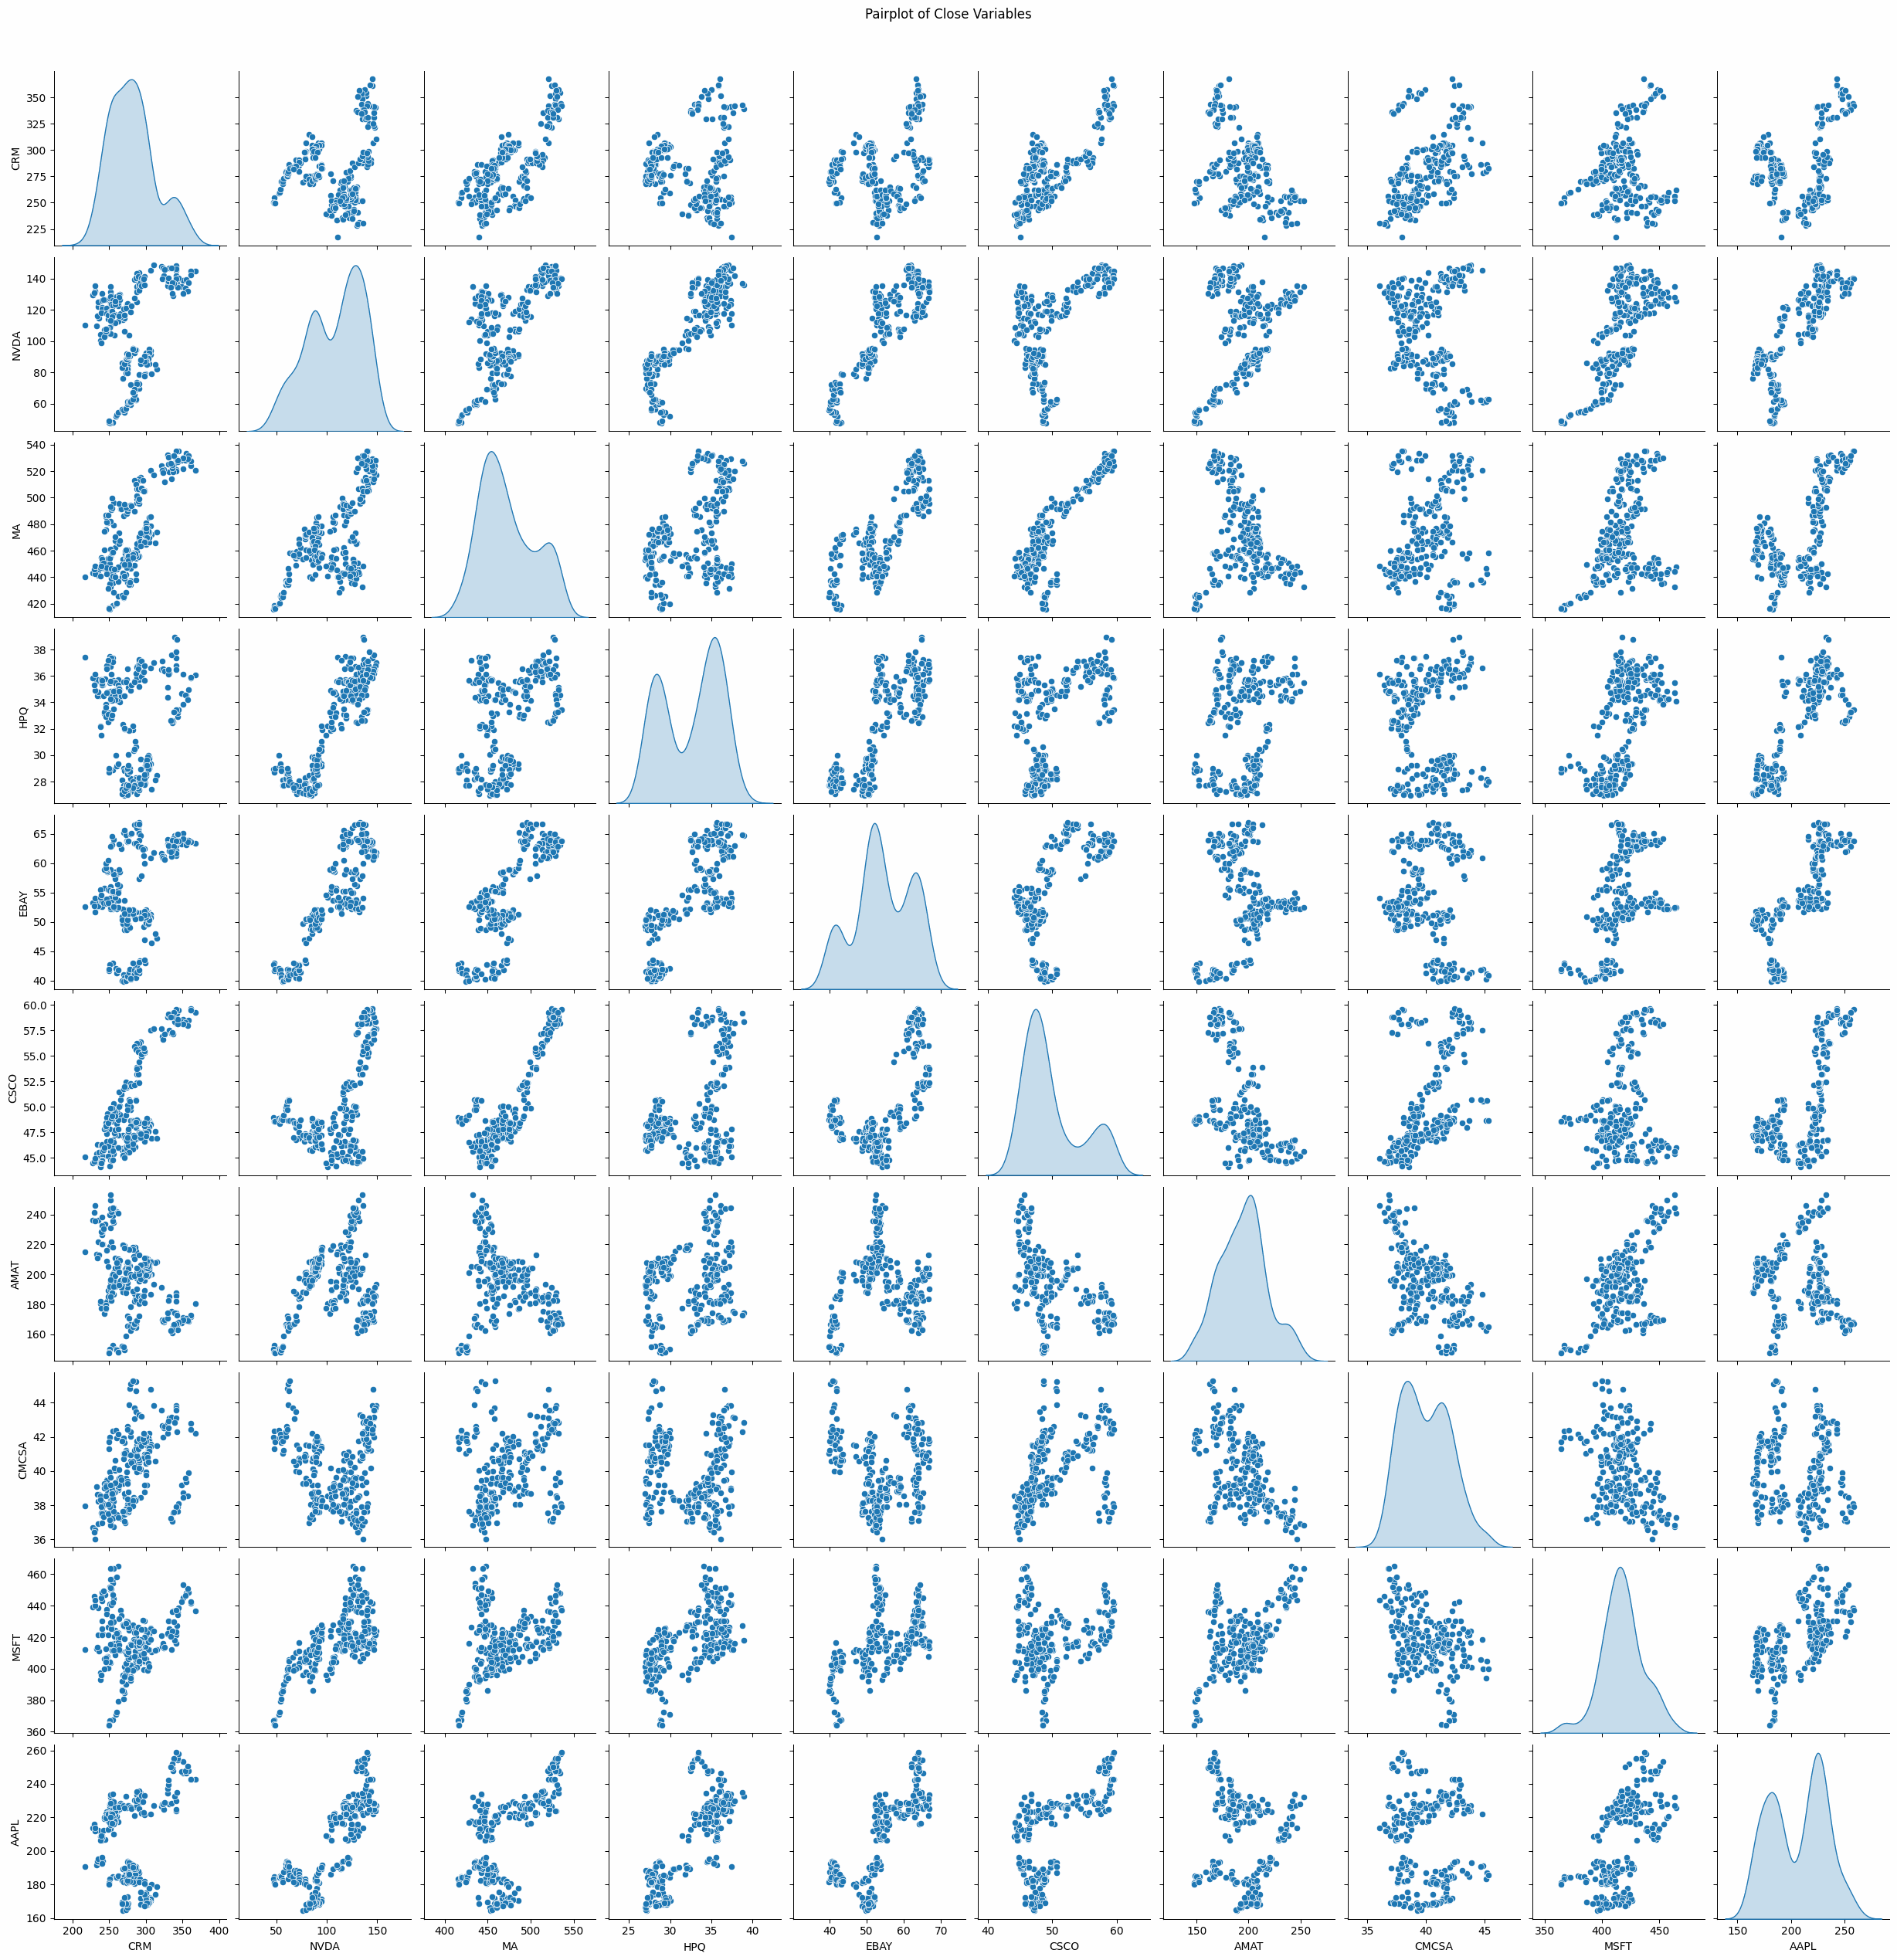

In [361]:
# Create a pairplot
sns.pairplot(df_adjclose, diag_kind='kde')
plt.suptitle('Pairplot of Close Variables', y=1.02)
plt.show()

## LINE GRAPHS

## INDIVIDUAL STOCKS

### SALESFORCE (CRM)

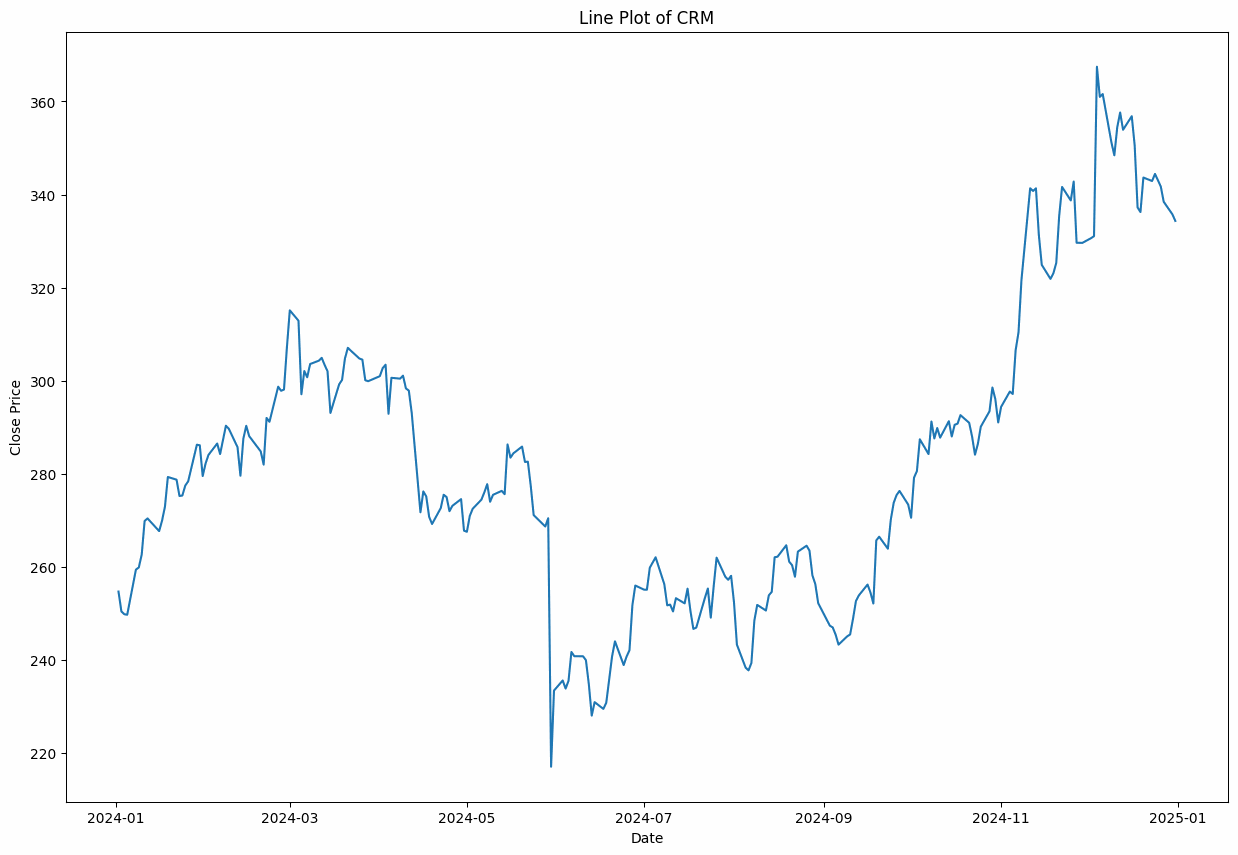

In [362]:
# Create a line plot of CRM
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_CRM, x=df_CRM.index, y=df_CRM['adjclose_CRM'])
plt.title("Line Plot of CRM")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

Salesforce's stock price exhibits a general upward trend but with notable fluctuations. The stock experienced a steady rise in the first quarter of 2024, reaching a peak above 300. However, a sharp drop in mid-2024 indicates a period of market correction or external events affecting the stock. Following this decline, CRM shows volatility but maintains a recovery trajectory in the latter half of 2024, culminating in a significant upward movement toward the end of the year.

**Key Observations**

- Early Growth Phase (Q1 2024 – Q2 2024)

The stock price shows a consistent uptrend, suggesting strong investor confidence or positive earnings reports.
Peaks in March and April indicate strong buying momentum.

- Mid-Year Decline (Q2 2024 – Q3 2024)

A steep drop in price suggests a major market event, earnings miss, or external macroeconomic factors.
The price stabilizes around July but remains volatile.

- Recovery and Breakout (Q3 2024 – Q4 2024)

CRM demonstrates a steady climb with increasing momentum.
The sharp surge in November suggests a positive catalyst, such as earnings, acquisitions, or favorable market sentiment.

**Investment Insights**

Short-term traders could have capitalized on the volatility, especially during the mid-year correction and subsequent recovery.

Long-term investors benefited from the overall uptrend, reinforcing the importance of holding through temporary declines.

The final surge suggests potential bullish momentum going into 2025, but investors should consider external factors and earnings performance before making decisions.


### NVIDA (NVDA)

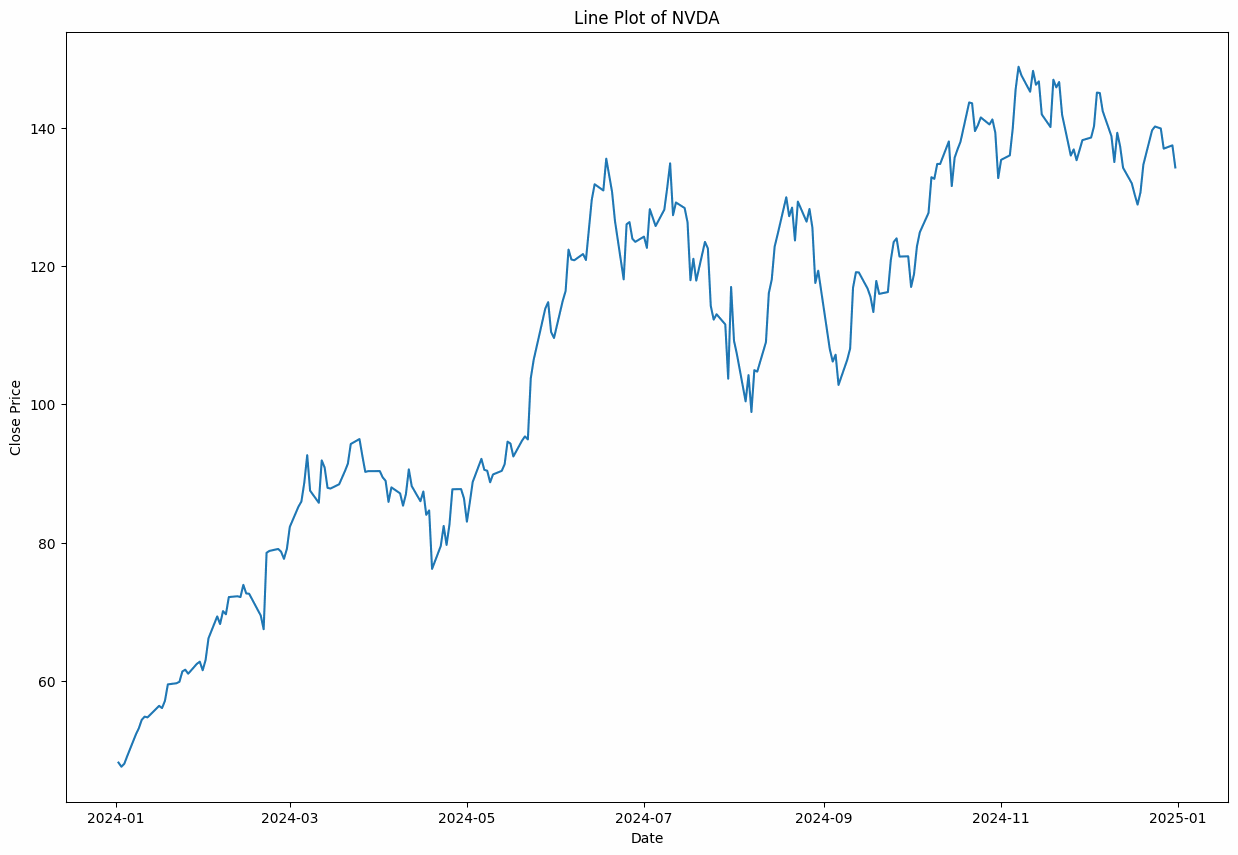

In [363]:
# Create a line plot of NVDA
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_NVDA, x=df_NVDA.index, y=df_NVDA['adjclose_NVDA'])
plt.title("Line Plot of NVDA")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

NVIDIA's stock price exhibits a strong overall uptrend throughout the year, reflecting growing investor confidence and potential market demand. The price shows consistent growth in the first half of the year, with intermittent pullbacks, followed by increased volatility in the latter half.

**Key Observations**

* Strong Uptrend (Q1 2024 – Q2 2024)

NVDA's price surged from below 50 to over 100 within six months, indicating strong demand and bullish sentiment.
The trend suggests either strong earnings reports, positive industry trends, or increased institutional investment.

* Increased Volatility (Q3 2024 – Q4 2024)

Despite continued growth, price fluctuations became more pronounced in the second half of the year.
Short-term dips suggest profit-taking or market reactions to external news, but the overall trajectory remains positive.

* Late-Year Consolidation and Stability

The stock price reaches its peak above 140 but fluctuates within a narrower range toward the end of 2024.
This suggests a potential leveling-off period, where investors may be waiting for further catalysts before driving prices higher.

**Investment Insights**

Momentum traders could have capitalized on NVDA's strong upward trend, especially in the first half of 2024.

Long-term investors benefited from NVIDIA’s sustained growth despite volatility, reinforcing confidence in its long-term potential.

Market volatility in the latter half suggests the stock is sensitive to external factors, requiring investors to monitor earnings reports and industry trends.

### MA (MASTERCARD)

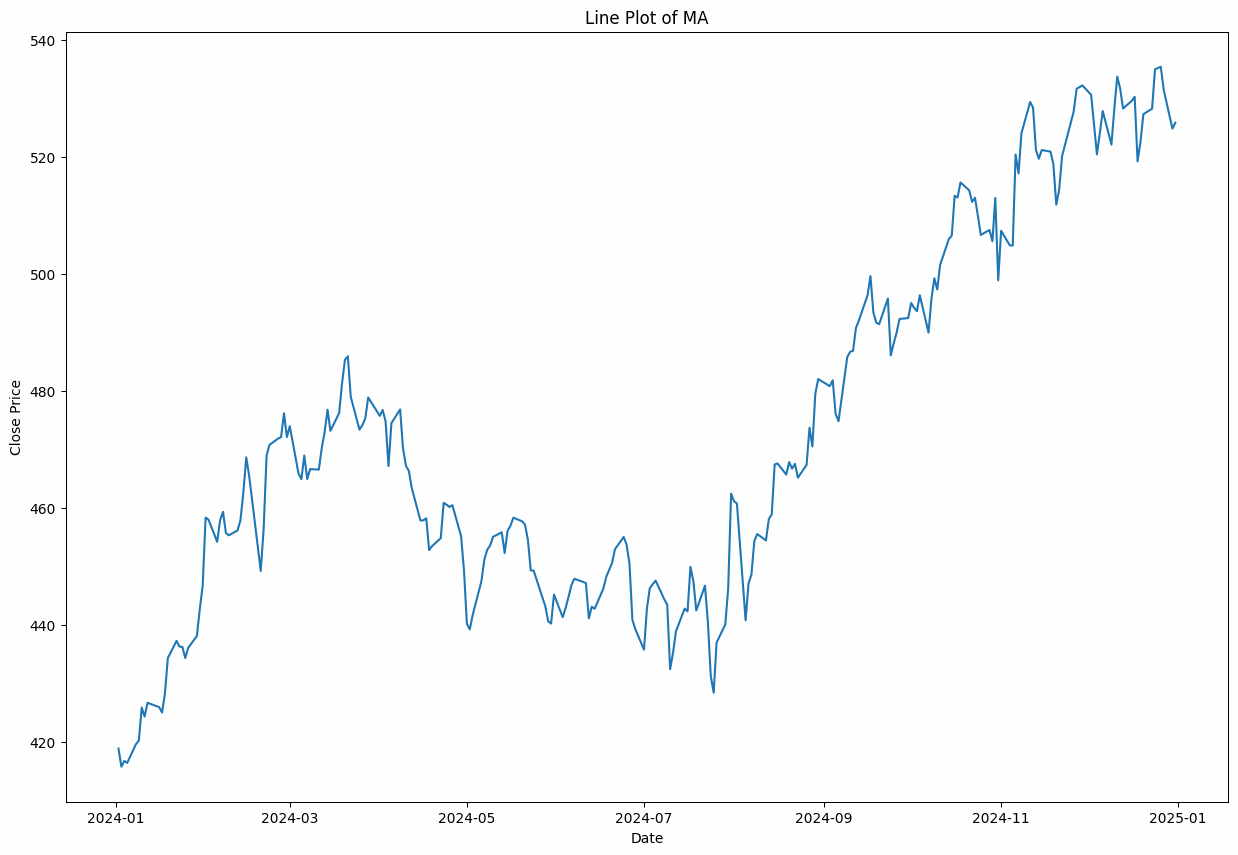

In [364]:
# Create a line plot of MA
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_MA, x=df_MA.index, y=df_MA['adjclose_MA'])
plt.title("Line Plot of MA")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

Mastercard’s stock price follows an overall upward trajectory, demonstrating a period of moderate volatility before achieving consistent growth. The initial months show price fluctuations, but the latter part of the year exhibits a strong bullish trend.

**Key Observations**

- Initial Growth with Volatility (Q1 2024 – Q2 2024)

The stock price starts around 415 and rises above 480, showing investor confidence.

Fluctuations suggest a mix of short-term corrections and profit-taking before stabilizing.

- Mid-Year Pullback and Consolidation (Q2 2024 – Q3 2024)

The stock experiences a notable decline, testing support levels near 440.

This phase indicates market adjustments, possibly linked to broader economic factors or earnings performance.

- Strong Recovery and Uptrend (Q3 2024 – Q4 2024)

From mid-2024 onward, the stock enters a strong growth phase, reaching its highest levels near 540 by year-end.

The consistent uptrend suggests increased investor confidence and possible strong earnings or industry growth.

**Investment Insights**

Momentum investors could have leveraged the late-year rally for short-term gains.

Long-term investors benefited from Mastercard’s sustained growth, reinforcing its position as a stable investment.

Market corrections in mid-2024 highlight the importance of monitoring macroeconomic trends and company fundamentals.


### HP (HPQ)

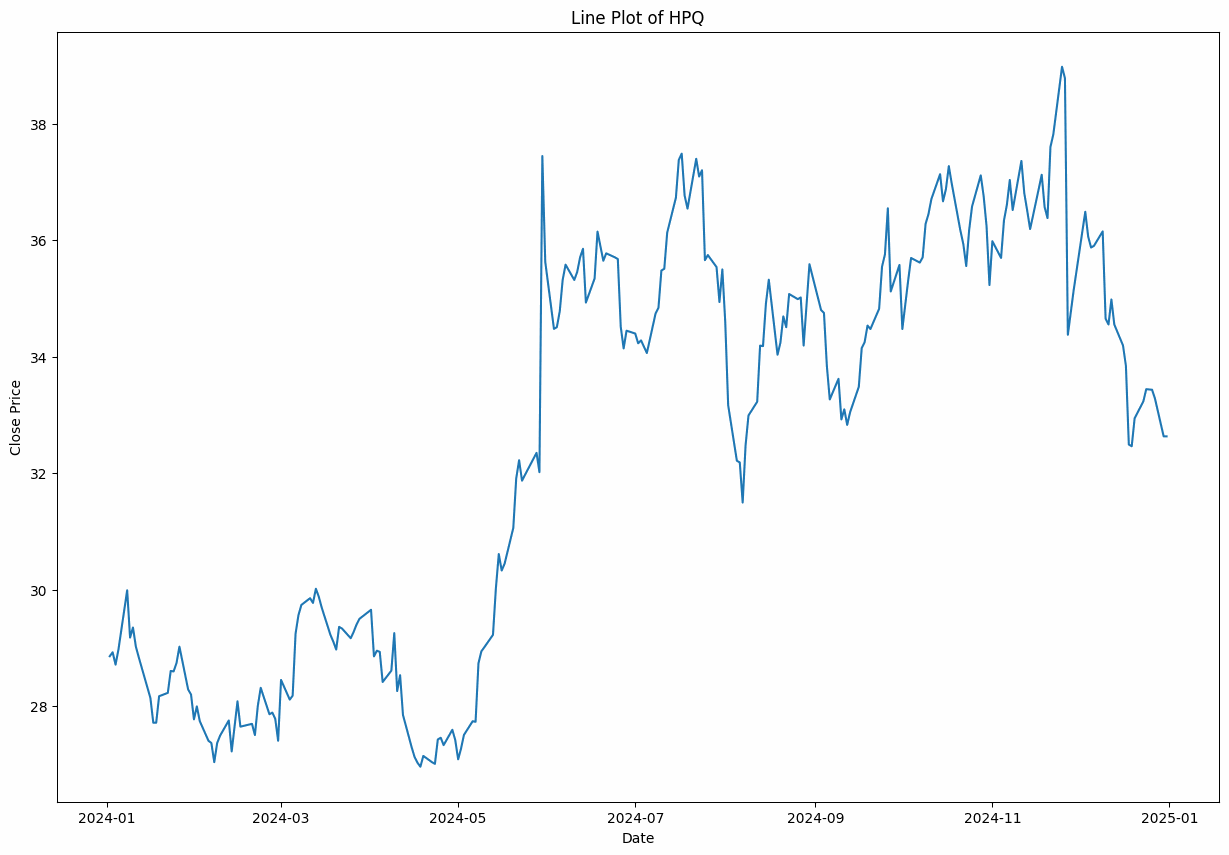

In [365]:
# Create a line plot of HPQ
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_HPQ, x=df_HPQ.index, y=df_HPQ['adjclose_HPQ'])
plt.title("Line Plot of HPQ")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

HPQ’s stock price shows an initial period of fluctuation, followed by a strong mid-year rally and increased volatility towards the end of the year.

**Key Observations**

- Early Year Fluctuations (Q1 2024 – Q2 2024)

The stock price initially struggles to maintain momentum, fluctuating between 27 and 30.

A brief dip in Q2 suggests market uncertainty, possibly due to external economic conditions.

- Strong Mid-Year Rally (Q2 2024 – Q3 2024)

A significant breakout occurs in mid-2024, with the stock rapidly rising above 32.

The steep price jump indicates strong investor sentiment, potentially linked to earnings reports, business expansion, or industry trends.

- Volatile Performance (Q3 2024 – Q4 2024)

After reaching a peak above 38, the stock exhibits increased volatility.

Sharp fluctuations suggest market corrections, profit-taking, or external macroeconomic influences.

Despite fluctuations, the stock maintains levels higher than its early-year performance, indicating underlying strength.

**Investment Insights**

Short-term traders could capitalize on HPQ’s mid-year breakout and subsequent volatility for profit-taking opportunities.

Long-term investors may observe that despite fluctuations, the stock maintains an upward trajectory, reinforcing its potential as a stable investment.

Market volatility in later months suggests external influences, such as earnings performance or macroeconomic conditions, affecting investor sentiment.

### EBAY (EBAY)

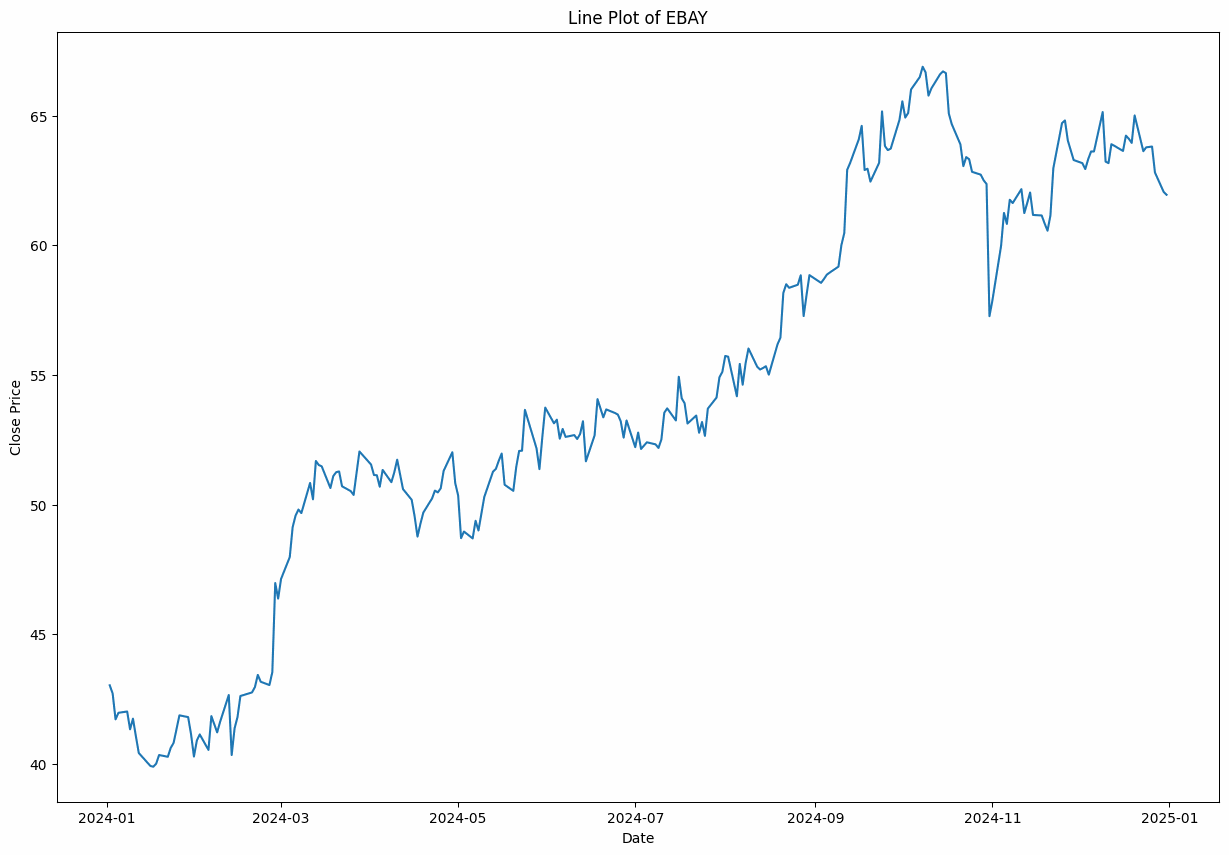

In [366]:
# Create a line plot of EBAY
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_Ebay, x=df_Ebay.index, y=df_Ebay['adjclose_EBAY'])
plt.title("Line Plot of EBAY")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

eBay’s stock price exhibits a clear upward trajectory over the year, indicating sustained growth with intermittent fluctuations.

**Key Observations**

- Early Year Stability and Growth (Q1 2024 – Q2 2024)

The stock initially trades around the $40-$42 range before beginning a steady upward trend.

By March 2024, the price experiences a notable breakout, moving above $45, likely influenced by positive earnings or external economic conditions.

- Consistent Appreciation with Minor Corrections (Q2 2024 – Q3 2024)

The stock shows steady growth, surpassing the $50 mark and maintaining a stable upward trend.

Minor pullbacks suggest periodic profit-taking, but the overall trend remains positive.

- Strong Bullish Momentum (Q3 2024 – Q4 2024)

The latter half of the year sees the stock reaching new highs above $60.

The price increase is characterized by strong momentum, possibly due to positive business performance, sector growth, or investor confidence.

Short-term volatility emerges, with occasional dips, but the stock consistently recovers.

**Investment Insights**

Long-term investors could see eBay as a promising growth stock, given its consistent upward trajectory.
Short-term traders may benefit from periodic fluctuations, using pullbacks as entry points for short-term gains.
Market stability plays a key role in eBay’s performance, as the stock exhibits controlled growth rather than extreme volatility.

### CISCO (CSCO)

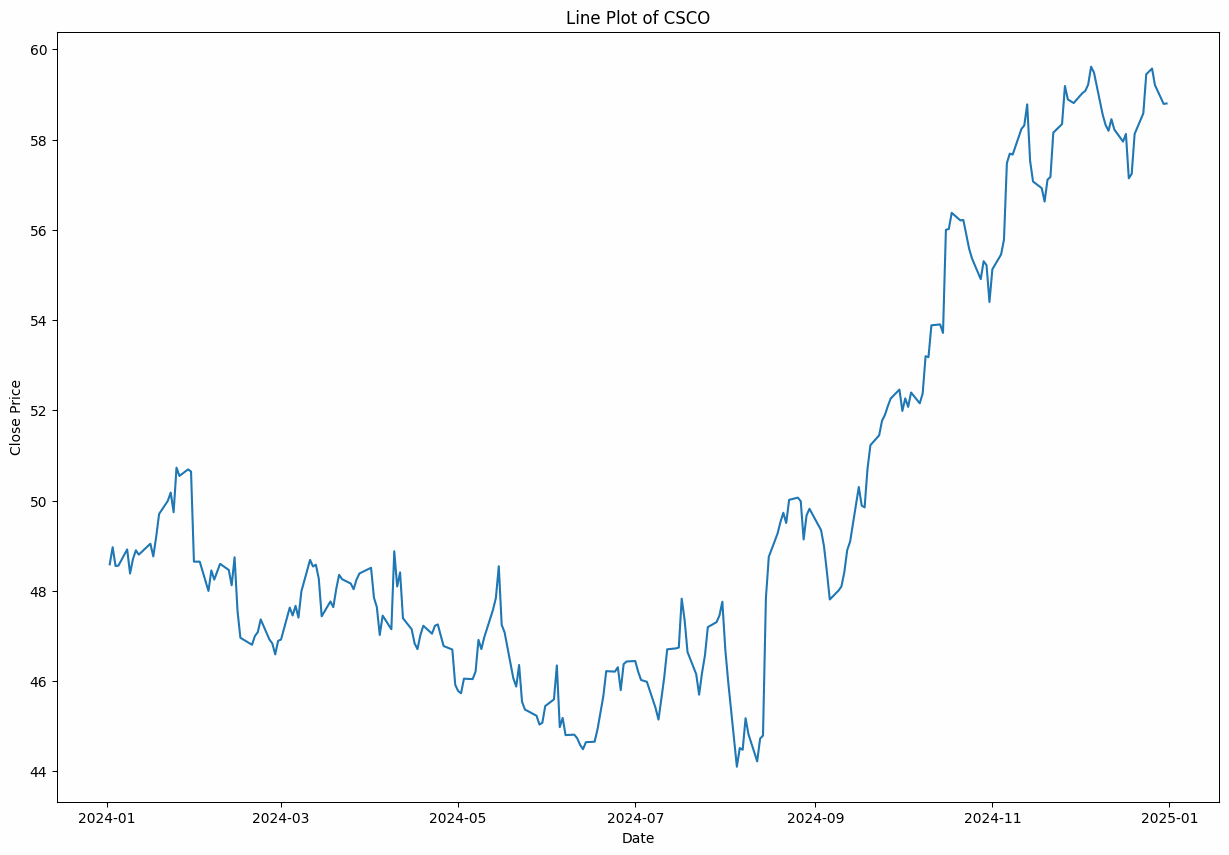

In [367]:
# Create a line plot of CSCO
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_CSCO, x=df_CSCO.index, y=df_CSCO['adjclose_CSCO'])
plt.title("Line Plot of CSCO")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

Cisco’s stock price experiences both downward and upward trends throughout the year, indicating phases of market correction and recovery.

**Key Observations**

- Early Year Volatility and Decline (Q1 2024 – Q2 2024)

The stock price begins the year near $48-$49 but experiences fluctuations in the first quarter.

A downward trend follows, with the price dipping below $45 by mid-year, suggesting a period of market correction or weaker-than-expected earnings.

- Stabilization and Reversal (Q2 2024 – Q3 2024)

Around mid-year, the stock price stabilizes and forms a base near $44-$46.

The price begins a slow but steady recovery, indicating renewed investor interest or positive market developments.

- Strong Uptrend and Breakout (Q3 2024 – Q4 2024)

In the second half of 2024, Cisco’s stock experiences a strong bullish breakout.

The price surges past $50 and continues climbing steadily, reaching above $58 by the end of the year.

This movement suggests improved financial performance, strong market demand, or broader sector growth in the technology industry.

**Investment Insights**

Short-term traders may have faced challenges during the first half of the year due to price instability, but the later breakout presented strong buying opportunities.

Long-term investors benefited from holding through the market dip, as Cisco showed strong recovery and growth toward the year-end.

Market fluctuations in the first half of the year highlight the importance of risk management, while the later bullish trend suggests investor confidence in the company's prospects.

### APPLIED MATERIALS (AMAT)

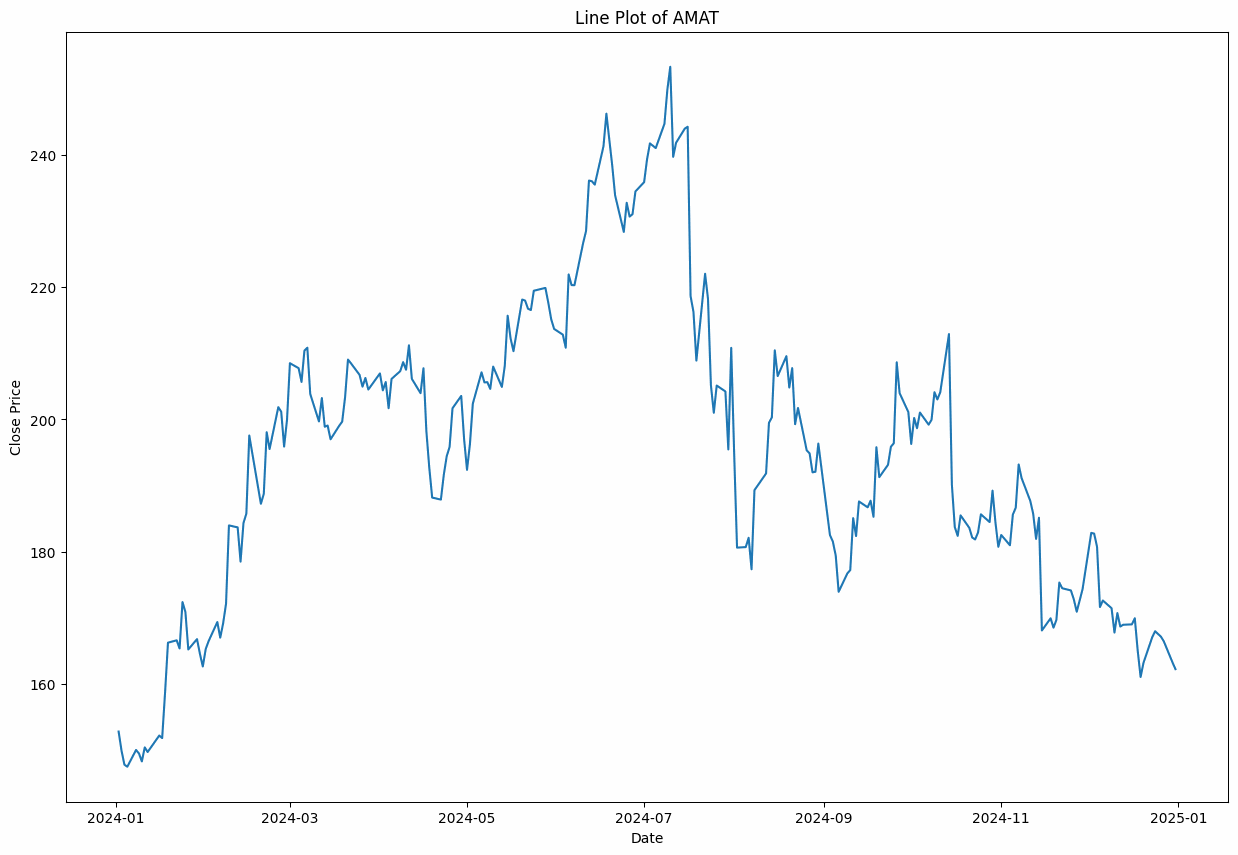

In [368]:
# Create a line plot of AMAT
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_AMAT, x=df_AMAT.index, y=df_AMAT['adjclose_AMAT'])
plt.title("Line Plot of AMAT")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

AMAT’s stock price exhibits notable fluctuations, with a strong upward trend in the first half of the year, followed by a sharp decline in the latter half.

**Key Observations**

- Initial Growth and Peak Performance (Q1 2024 – Q3 2024)

The stock price starts near $150 in January 2024 and enters a strong bullish phase, crossing $240 by mid-year.

This rapid appreciation suggests positive investor sentiment, potentially driven by strong earnings, industry growth, or macroeconomic factors.

The peak price is observed around mid-year, indicating a high point in investor confidence.

- Sharp Reversal and Market Correction (Q3 2024 – Q4 2024)

Following the peak, AMAT’s stock enters a volatile phase with a steep decline.

The price drops below $180, showing signs of market correction or negative external factors affecting the stock.
This decline could be attributed to profit-taking, sector-wide adjustments, or broader market downturns.

- Instability and Further Declines (Q4 2024 – Year-End 2024)

The stock price continues to trend downward, reaching new lows near $160 as the year closes.

The fluctuations suggest uncertainty, possibly caused by earnings reports, investor reallocation, or sector challenges.

**Investment Insights**

Short-term investors may have capitalized on the strong upward momentum in the first half of the year but faced significant risks during the price decline in the latter half.

Long-term investors might view this correction as a potential buying opportunity, depending on the fundamental outlook of the company and industry trends.

Market volatility remains a key factor, emphasizing the importance of risk management strategies when investing in AMAT.


### COMCAST (CMCSA)

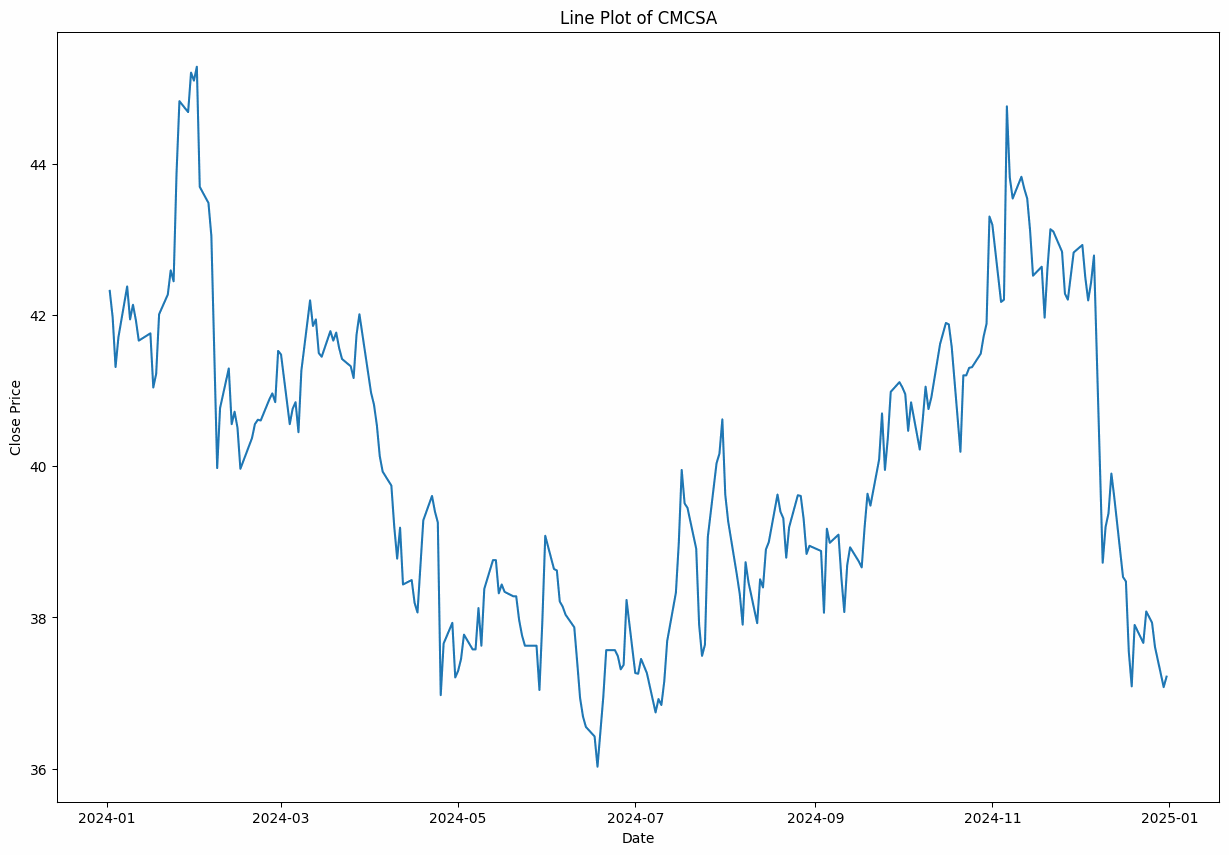

In [369]:
# Create a line plot of CMCSA
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_CMCSA, x=df_CMCSA.index, y=df_CMCSA['adjclose_CMCSA'])
plt.title("Line Plot of CMCSA")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

CMCSA’s stock price exhibits a fluctuating pattern with no clear long-term upward or downward trend, instead experiencing multiple peaks and declines throughout the year.

**Key Observations**

- Initial Volatility and Decline (Q1 2024 – Q2 2024)

The stock starts around $42 and experiences an early surge, reaching approximately $45.

This peak is followed by a sharp decline, dropping below $40 by mid-year.

The volatility suggests external market influences or company-specific developments impacting investor sentiment.

- Unstable Mid-Year Performance (Q2 2024 – Q3 2024)

CMCSA experiences a series of price fluctuations, struggling to maintain consistent upward momentum.

Prices dip below $37 before recovering slightly, indicating market uncertainty and investor hesitance.

- Recovery and Another Decline (Q3 2024 – Year-End 2024)

In the final quarter, the stock briefly rebounds above $42, suggesting renewed investor interest or positive financial reports.

However, a sharp decline follows, closing near its lowest point of the year, around $36, by early 2025.

**Investment Insights**

Short-term traders could have capitalized on CMCSA’s price swings, but the stock’s instability makes it riskier for momentum-based strategies.

Long-term investors may view the downward trend as a sign of fundamental weaknesses or external challenges affecting the stock.

Volatility concerns highlight the need for cautious portfolio allocation, as the unpredictable price swings could lead to potential losses if not managed properly.

### MICROSOFT (MSFT)

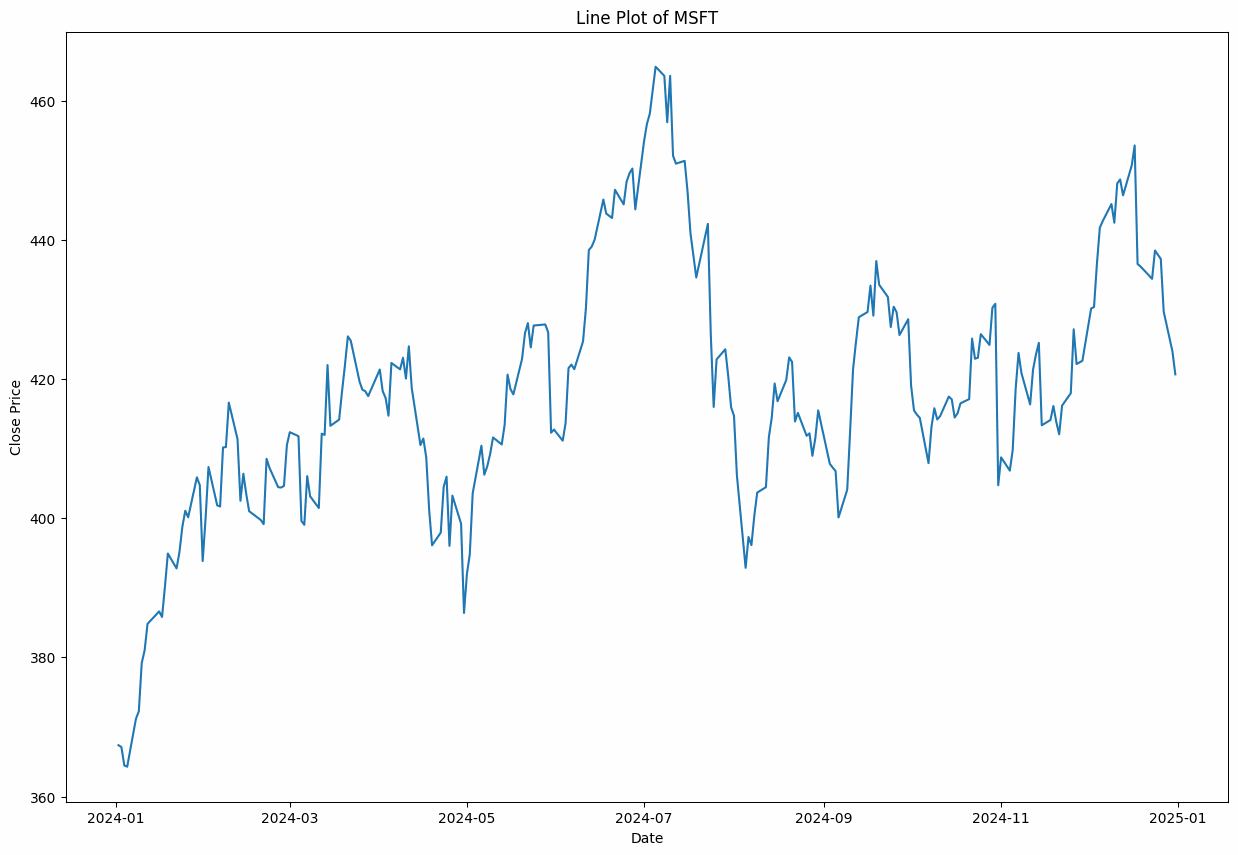

In [370]:
# Create a line plot of MSFT
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_MSFT, x=df_MSFT.index, y=df_MSFT['adjclose_MSFT'])
plt.title("Line Plot of MSFT")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

- Early Year Stability and Decline (Q1 2024 – Q2 2024)

The stock price remained relatively stable around $48–$50 in the initial months.

A gradual downward trend followed, with prices falling below $46 by mid-year.

This suggests a bearish sentiment during this period, possibly due to external market conditions or company-specific factors.

- Significant Mid-Year Volatility (Q2 2024 – Q3 2024)

CSCO experienced notable fluctuations in mid-2024, with prices dipping to nearly $44, marking the lowest point of the year.

Following this, the stock began showing signs of recovery, but the volatility indicates investor uncertainty.

- Strong Recovery and Upward Momentum (Q3 2024 – Q4 2024)

A sharp breakout occurred after mid-year, driving prices upward.

The stock surged past $50 and maintained an upward trajectory, reaching new highs above $58 by the end of the year.

This rally suggests renewed investor confidence, possibly driven by strong earnings reports or broader market recoveries.

- Investment Insights

Short-term traders could have capitalized on the mid-year volatility and the subsequent bullish trend.

Long-term investors benefited from the stock's strong late-year performance, indicating potential for continued appreciation.

Market sensitivity is evident, as the stock experienced both significant declines and rapid recoveries, making risk management essential for investors.

### APPLE (AAPL)


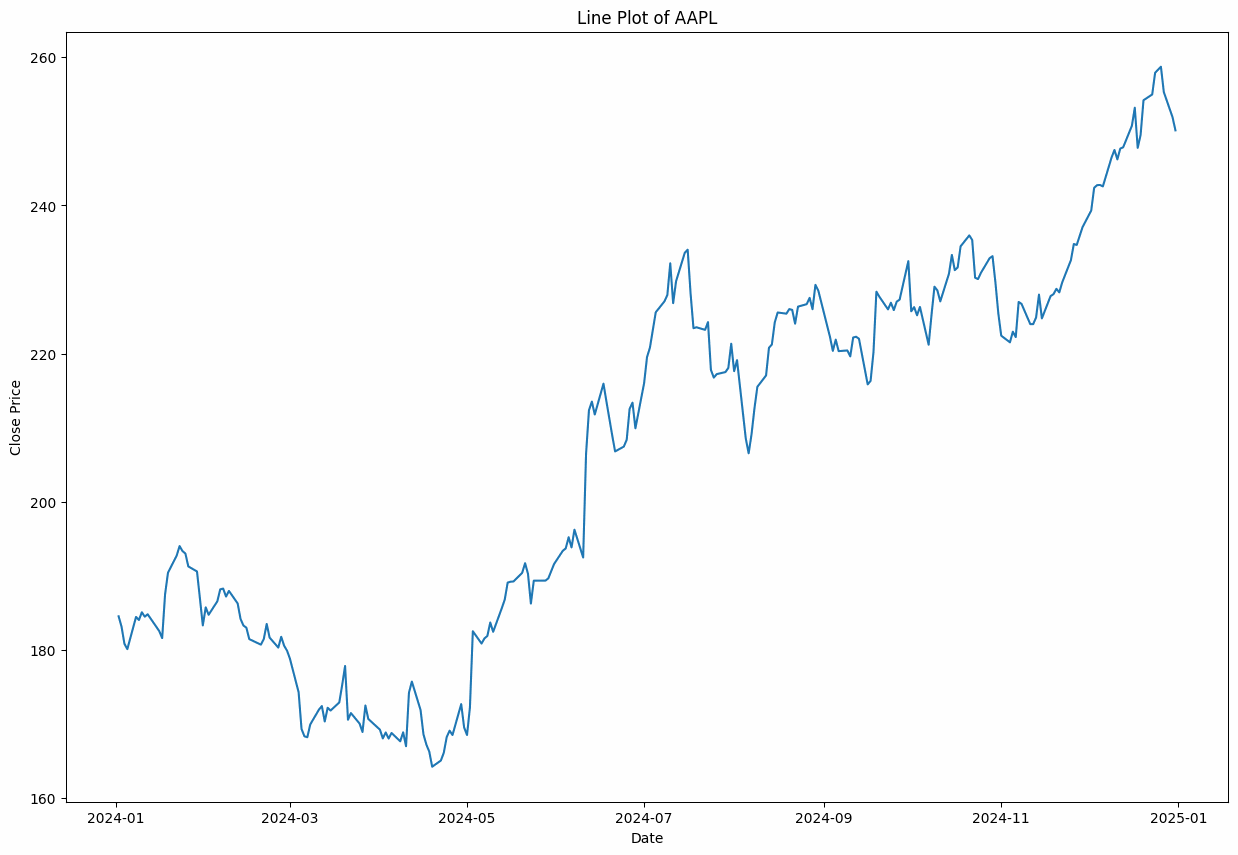

In [371]:
# Create a line plot of AAPL
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_AAPL, x=df_AAPL.index, y=df_AAPL['adjclose_AAPL'])
plt.title("Line Plot of AAPL")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

**Observed Price Trends**

- Early Year Fluctuations and Decline (Q1 2024 – Q2 2024)

AAPL started the year with slight volatility, experiencing short-term gains followed by a decline.

The stock reached its lowest point around May 2024, suggesting a temporary bearish phase, possibly due to external market conditions or company performance concerns.

- Mid-Year Recovery and Growth Momentum (Q2 2024 – Q3 2024)

After bottoming out, AAPL demonstrated a strong recovery, experiencing a sharp upward trajectory.

The stock price rose steadily from mid-May, suggesting increased investor confidence, likely driven by earnings reports, product releases, or broader market recovery.

- Sustained Uptrend with Periodic Corrections (Q3 2024 – Q4 2024)

The stock maintained an overall bullish trend, reaching new highs towards the end of the year.

Some short-term corrections were observed, but the general trajectory remained positive, indicating strong fundamental support.

By the end of 2024, AAPL closed at its highest level of the year, reflecting continued investor optimism.

**Investment Insights**

Short-term traders could have leveraged the early-year dip and subsequent recovery for profitable trades.

Long-term investors benefited from the steady price appreciation, reinforcing Apple’s position as a stable growth stock.

Market responsiveness is evident, as AAPL’s performance aligns with broader trends, making it a reliable candidate for trend-based trading strategies.

## 1 YEAR

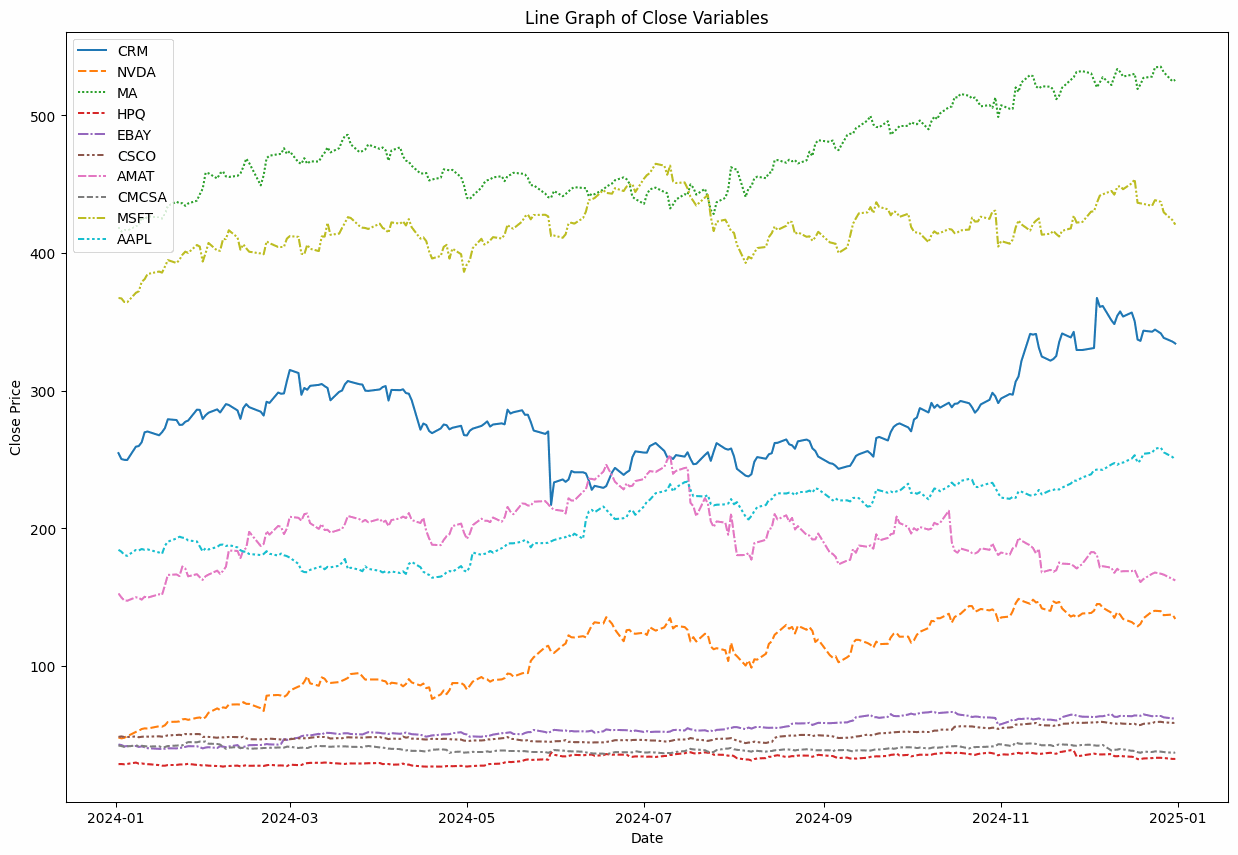

In [372]:
# Create a line graph using df_close
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_adjclose)
plt.title('Line Graph of Close Variables')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

**Observed Trends**

- High-Value Stocks with Steady Growth

MA (Mastercard) and MSFT (Microsoft) consistently maintain the highest closing prices, fluctuating within the 400-500 range.

These stocks exhibit a stable upward trend, with periodic dips that are followed by recoveries, indicating strong long-term investor confidence.

- Mid-Range Performers with Volatility

CRM (Salesforce), AMAT (Applied Materials), and AAPL (Apple) show moderate price fluctuations while maintaining an overall upward trend.

CRM, in particular, has notable dips and rebounds, suggesting sensitivity to market events or earnings reports.
AMAT and AAPL show a more consistent growth trajectory, reflecting strong fundamentals and investor demand.

- Growth Stocks with More Price Sensitivity

NVDA (NVIDIA) displays significant growth but also notable volatility, likely influenced by the semiconductor industry’s cyclical nature and external market conditions.

EBAY and CMCSA (Comcast) maintain moderate growth, with relatively steady price movements.

- Lower-Priced Stocks with Stability

CSCO (Cisco), HPQ (HP), and CMCSA (Comcast) remain in the lower price range with minimal fluctuations.

Their lower volatility suggests they are less susceptible to rapid market movements, making them more stable but potentially slower-growing investments.

- Market and Investment Insights

Diversified Performance: The stocks exhibit varied behaviors, from high-growth tech stocks to more stable, low-volatility assets.

Industry Influence: Stocks in the same sector tend to show similar movement patterns, suggesting external factors such as economic conditions and industry trends impact price action.

Long-Term Growth Potential: Companies with consistent upward trends, such as MSFT, AAPL, and MA, may be attractive for long-term investors seeking capital appreciation.

## QUARTERLY

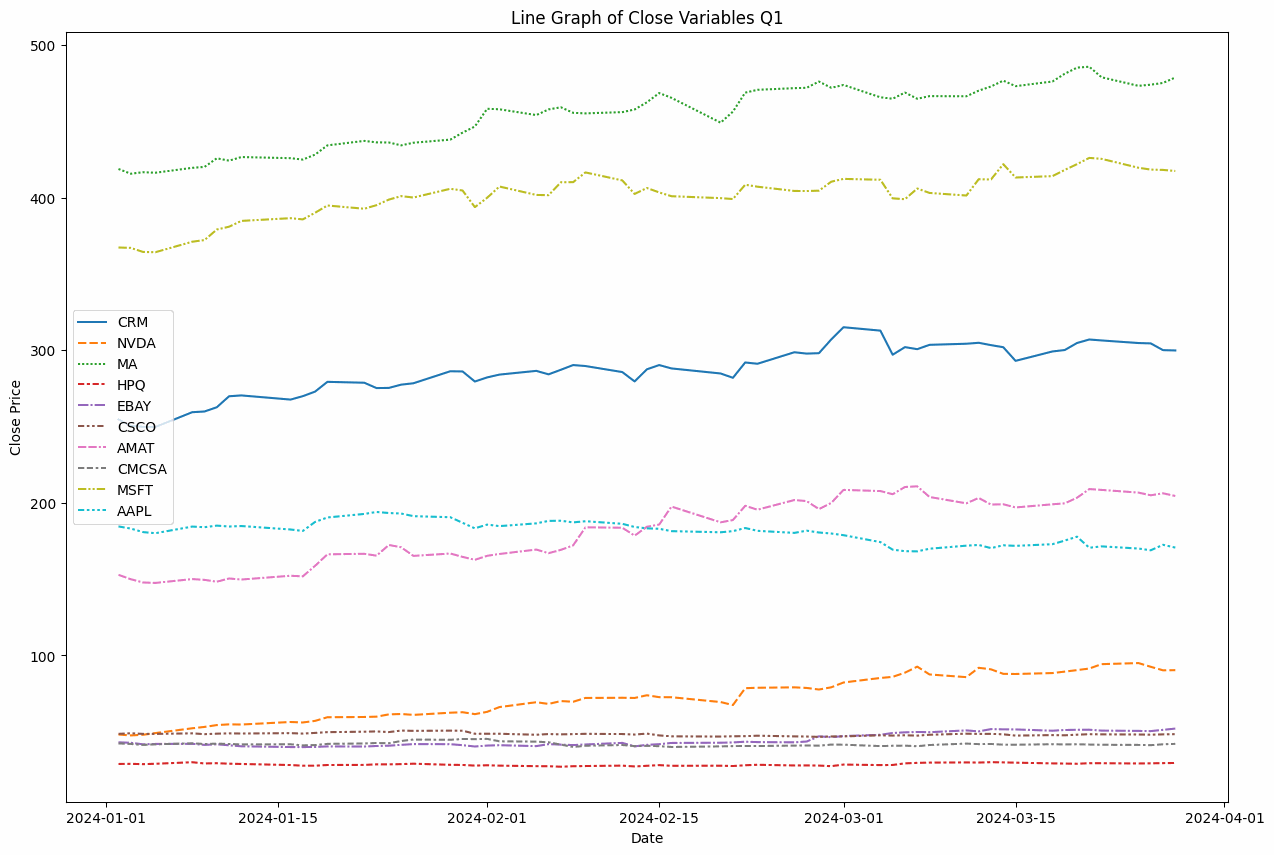

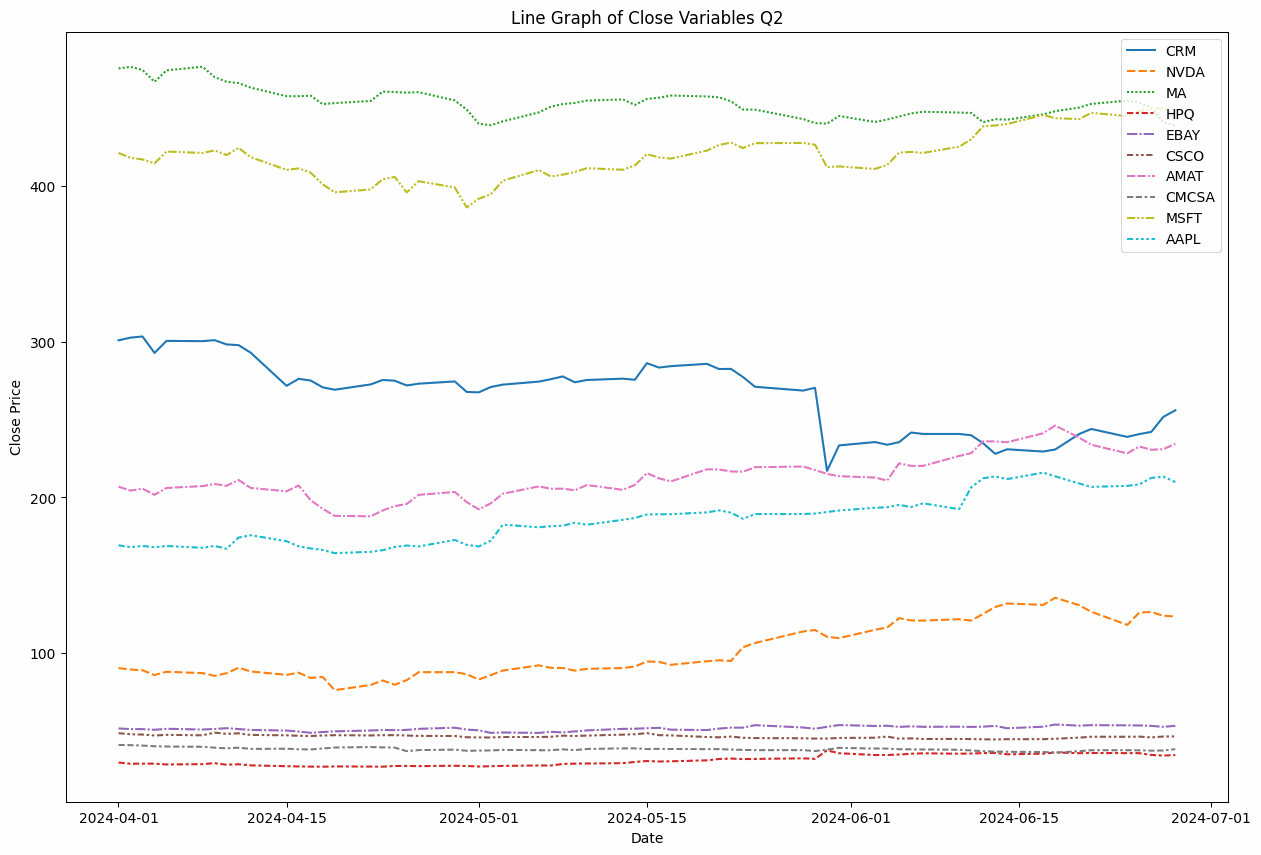

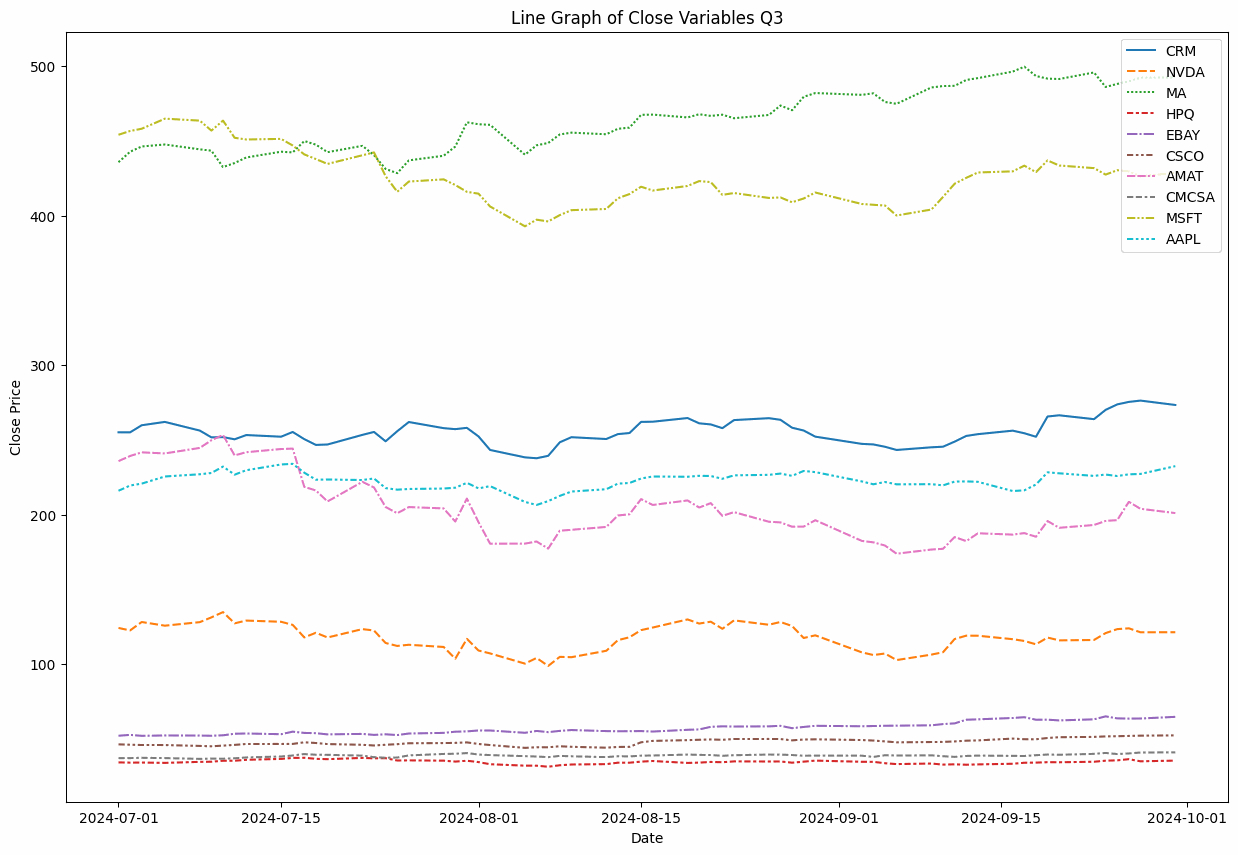

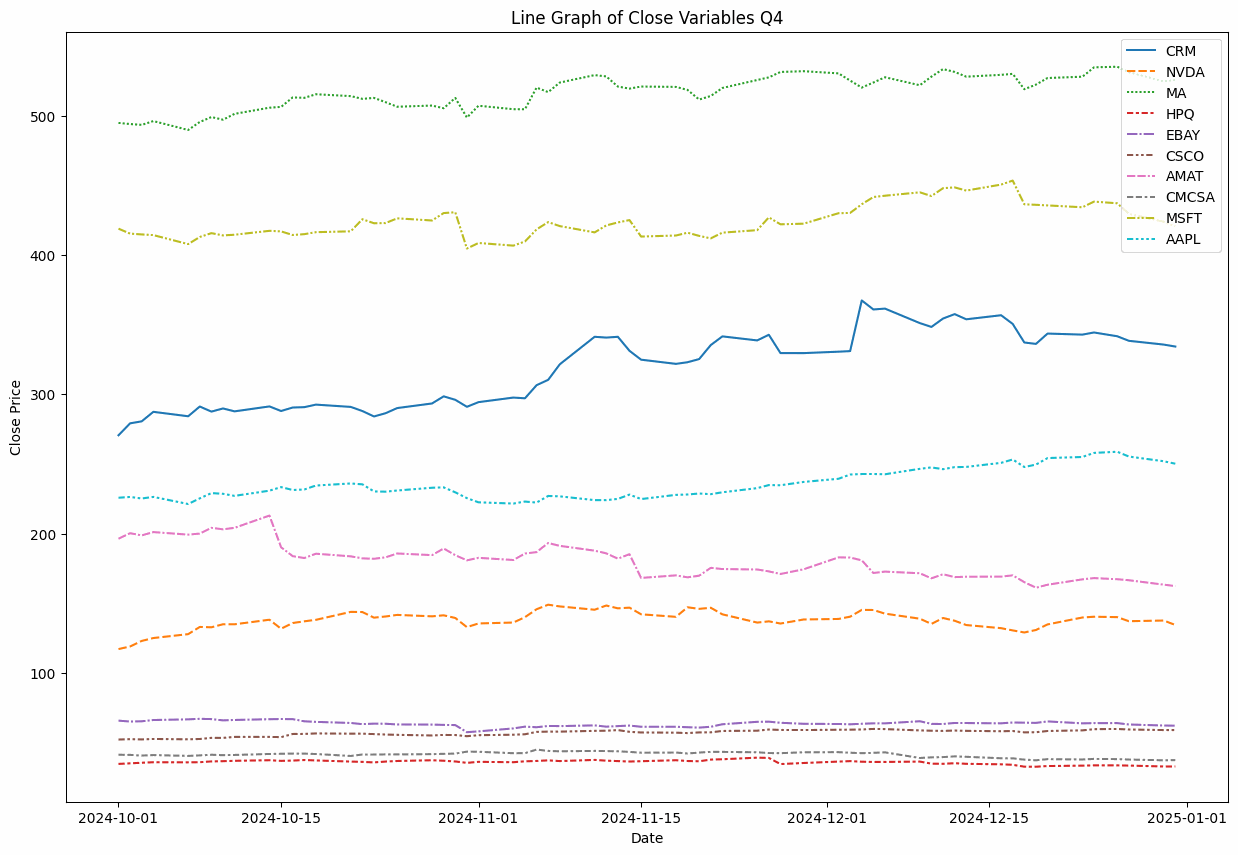

In [373]:
# Define Q1, Q2, Q3, Q4
q1 = pd.to_datetime(df_adjclose.index).quarter == 1
q2 = pd.to_datetime(df_adjclose.index).quarter == 2
q3 = pd.to_datetime(df_adjclose.index).quarter == 3
q4 = pd.to_datetime(df_adjclose.index).quarter == 4

# Dictionary to label each quarter
# Instead of using NumPy arrays as keys, use tuples of booleans:
quarters = {
    tuple(q1): 'Q1',
    tuple(q2): 'Q2',
    tuple(q3): 'Q3',
    tuple(q4): 'Q4'
}

# Plot each quarter individually with proper titles
for quarter, label in quarters.items():
    plt.figure(figsize=(15, 10))
    # Convert the tuple key back to a boolean index:
    sns.lineplot(data=df_adjclose[np.array(quarter)])
    plt.title(f'Line Graph of Close Variables {label}')
    plt.xlabel('Date')
    plt.ylabel('Close Price')
    plt.show()

**Q1 Analysis (January - March 2024)**
During the first quarter of 2024, most stocks exhibited stable upward trends, with occasional fluctuations. CRM, MA, and MSFT displayed a steady increase, while NVDA showed early volatility but maintained an upward trajectory. AMAT and AAPL demonstrated gradual growth, while CSCO and HPQ had relatively flat movements with minor declines.

**Q2 Analysis (April - June 2024)**
The second quarter saw mixed trends across different stocks. CRM and AMAT experienced a decline in mid-April, possibly due to market corrections or external influences. MSFT and MA maintained stability, whereas NVDA showed increased fluctuations. Some stocks, such as AAPL, showed continued strength, reinforcing investor confidence.

**Q3 Analysis (July - September 2024)**
The third quarter displayed more pronounced volatility. CRM saw periods of stagnation, while AMAT and MSFT exhibited fluctuations. NVDA and HPQ showed stronger rebounds, indicating potential growth opportunities. Stocks such as MA and AAPL continued their overall upward movement, aligning with broader market trends.

**Q4 Analysis (October - December 2024)**
The final quarter showcased continued bullish behavior for most stocks. CRM and AAPL demonstrated significant growth, while NVDA showed sustained momentum despite short-term fluctuations. MA and MSFT reached new highs, reflecting investor confidence. AMAT and CSCO remained relatively stable, indicating consistent performance over time.

**Key Takeaways**
Stock prices generally exhibit growth trends over time, with occasional fluctuations based on external factors.
CRM, AAPL, and MSFT were among the strongest performers, showing consistent growth throughout the year.

Volatility varies across stocks, with NVDA and AMAT showing more fluctuations than others.

Seasonal trends and market events likely contributed to mid-year fluctuations, highlighting the importance of monitoring external economic factors.

While correlation exists among stock movements, it is essential to note that correlation does not imply causation. Stock price trends are influenced by multiple factors, including company performance, macroeconomic conditions, and investor sentiment.

# CREATING THE MODEL

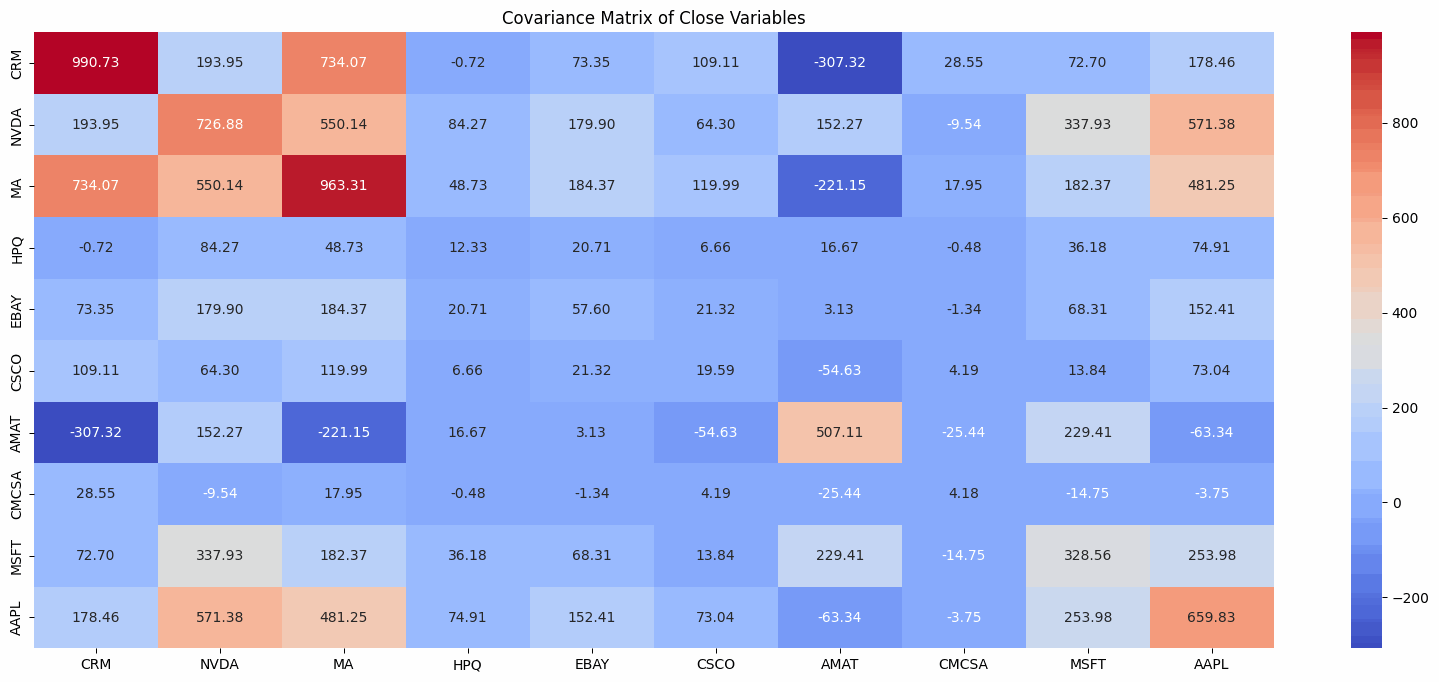

In [376]:
# Corvariance
df_cov = df_adjclose.cov()
plt.figure(figsize=(20, 8))
sns.heatmap(df_cov, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Covariance Matrix of Close Variables')
plt.show()

 **Descriptive Analysis of the Covariance Matrix and Its Implications**

 **1. Overview of Covariance**
This covariance matrix represents the relationships between the closing prices of various stocks, indicating how their values move together over time. Positive values suggest that two stocks tend to increase or decrease together, while negative values indicate an inverse relationship.

 **2. Key Observations**
- **Highest Covariance:** The strongest positive covariance appears between **CRM (Salesforce) and MA (Mastercard) at 990.73**, and **MA and NVDA (NVIDIA) at 726.88**. This suggests that these stock pairs tend to move in tandem. When one increases, the other is likely to do the same.
- **Negative Covariances:** Some stock pairs exhibit negative covariance, such as **AMAT (Applied Materials) and CRM (-307.32)** and **AMAT and MA (-221.15)**. This implies an inverse relationship where one stock’s price tends to increase while the other decreases.
- **Stable Stocks:** Stocks like **HPQ (HP) and CSCO (Cisco)** show relatively low covariance values with most other stocks, indicating limited co-movement with the broader portfolio.

 **3. Implications**
- **Portfolio Diversification:** Investors aiming to reduce risk should include negatively correlated stocks to hedge against volatility. For instance, combining AMAT and CRM in a portfolio may help balance out price fluctuations.
- **Sectoral Trends:** The strong covariance between CRM and MA suggests that fintech and enterprise software stocks are influenced by similar market conditions. Likewise, the high covariance between AAPL (Apple) and NVDA reflects the interconnectedness of the tech sector.
- **Risk Consideration:** High covariance stocks may expose investors to sector-specific risks. If CRM and MA experience a downturn simultaneously, a portfolio heavily weighted in these stocks could suffer significant losses.
- **Investment Strategy:** Investors seeking growth should focus on high covariance pairs if they believe the sector will perform well. Conversely, risk-averse investors may look for stocks with lower or negative covariance to minimize exposure to correlated risks.

In summary, this covariance analysis helps in understanding how different stocks move in relation to each other, guiding portfolio optimization strategies for risk management and return maximization.



In [377]:
# Find the return of the DataFrame and display the head
from IPython.display import display
df_return = df_adjclose.mean()

# Name column Mean of Stock
df_return.name = 'Mean of Stock'

# Display
display(df_return.head(10))

,Mean of Stock
CRM,281.941942
NVDA,107.809499
MA,472.441496
HPQ,32.549093
EBAY,54.281573
CSCO,49.879366
AMAT,194.909441
CMCSA,39.989485
MSFT,417.907472
AAPL,206.542984


## DESISION VARIABLES

In [378]:
# Define ConcreteModel
m = ConcreteModel()

# Define Decision Variables
m.CRM = Var(domain=NonNegativeReals, bounds=(0,1))
m.NVDA = Var(domain=NonNegativeReals, bounds=(0,1))
m.MA = Var(domain=NonNegativeReals, bounds=(0,1))
m.HPQ = Var(domain=NonNegativeReals, bounds=(0,1))
m.EBAY = Var(domain=NonNegativeReals, bounds=(0,1))
m.CSCO = Var(domain=NonNegativeReals, bounds=(0,1))
m.AMAT = Var(domain=NonNegativeReals, bounds=(0,1))
m.CMCSA = Var(domain=NonNegativeReals, bounds=(0,1))
m.MSFT = Var(domain=NonNegativeReals, bounds=(0,1))
m.AAPL = Var(domain=NonNegativeReals, bounds=(0,1))

In this section, decision variables are defined to represent the proportion of investment allocated to each stock in the portfolio. The model is structured using Pyomo’s ConcreteModel, a framework for mathematical optimization.

Each stock (CRM, NVDA, MA, HPQ, EBAY, CSCO, AMAT, CMCSA, MSFT, and AAPL) is assigned a decision variable, constrained between 0 and 1. This ensures that investment allocations remain non-negative and do not exceed 100% of the total capital available. The use of NonNegativeReals prevents short-selling, ensuring that all allocations are positive.

This step establishes the foundation for the portfolio optimization process, allowing for future constraints and objective functions to be implemented. The next phase will involve setting constraints to ensure the sum of allocations equals 100% and defining the optimization objective, such as maximizing expected returns or minimizing risk.

## OBJECTIVE FUNCTION

MAX(
  (282*CRM) +
  (108*NVDA) +
  (472*MA) +
  (32*HPQ) +
  (54*EBAY) +
  (50*CSCO) +
  (195*AMAT) +
  (40*CMCSA) +
  (418*MSFT) +
  (206*AAPL)

In [379]:
# Create objective function
m.objective = Objective( expr = (df_return[0] *m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL),
                        sense=maximize)

<ipython-input-379-f3a44b0acb9c>:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  m.objective = Objective( expr = (df_return[0] *m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL),


The objective function is designed to maximize the expected return of the portfolio based on historical stock returns. It is formulated as a linear combination of the expected returns (df_return[i]) for each stock and their corresponding allocation weights (m.CRM, m.NVDA, etc.).

Each stock's return is multiplied by its allocation proportion in the portfolio, and the sum represents the overall portfolio return. The sense=maximize parameter instructs the solver to find the optimal allocations that yield the highest possible return.

This function is a crucial component of portfolio optimization, as it guides the allocation process to focus on maximizing returns while future constraints (such as risk minimization or diversification requirements) are introduced.

## CONSTRAINTS

In [380]:
# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.1) # Given if risk is at 100%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

The constraints in this model ensure that the portfolio adheres to specific risk, allocation, and return requirements.

- Total Risk Constraint

The sum of all decision variables (portfolio allocations) is constrained to be 0.1, representing a normalized risk exposure. This ensures that the portfolio does not exceed a predefined risk tolerance.

- Portfolio Allocation Constraint

The sum of all stock allocations must be equal to 1, ensuring that all available capital is fully allocated across the selected stocks. This constraint prevents under-investment or over-leveraging of funds.

- Minimum Return Constraint

The objective function (expected return) must be at least 1% (0.01). This ensures that the portfolio generates a minimum acceptable return before considering optimal allocations. It acts as a safeguard to prevent allocations that could lead to extremely low or negative returns.

# MODELING

In [381]:
%matplotlib inline
from pylab import *

import shutil
import sys
import os.path

if not shutil.which("pyomo"):
    !pip install -q pyomo
    assert(shutil.which("pyomo"))

if not shutil.which("ipopt"):
    # here is the IPOPT zip file
    !gdown 10XRvLZqrpSNiXVAN-pipU52BVRwoGcNQ
    !unzip -o -q ipopt-linux64_dw
    assert(shutil.which("ipopt") or os.path.isfile("ipopt"))

from pyomo.environ import *

SOLVER = 'ipopt'
EXECUTABLE = '/content/ipopt'
ipopt_executable = '/content/ipopt'

Downloading...
From: https://drive.google.com/uc?id=10XRvLZqrpSNiXVAN-pipU52BVRwoGcNQ
To: /content/ipopt-linux64_dw.zip
100% 1.82M/1.82M [00:00<00:00, 166MB/s]


In [382]:
# Define calculated risk
def calc_risk(m):
  variables = [m.CRM, m.NVDA, m.MA, m.HPQ, m.EBAY, m.CSCO, m.AMAT, m.CMCSA, m.MSFT, m.AAPL]
  tickers = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
  risk_exp = 0
  for i in range(len(variables)):
    for j in range(len(variables)):
      risk_exp += variables[i]*df_cov.at[tickers[i],tickers[j]]*variables[j]
  return risk_exp

# Define expr_risk
expr_risk = calc_risk(m)

## MODEL 1 - 100%

In [383]:
# Model 1

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 1) # Given if risk is at 100%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 1
risk_limits = np.arange(0.003, max_risk, 0.01)

# Model vida param_analysis
param_analysis = {}
returns = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.661531925201416
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of so

<ipython-input-383-b4101c7b0803>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.05100131034851074
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.045137643814086914
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number o

... (190 outputs left out)

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.594245433807373
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of so

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.06649994850158691
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

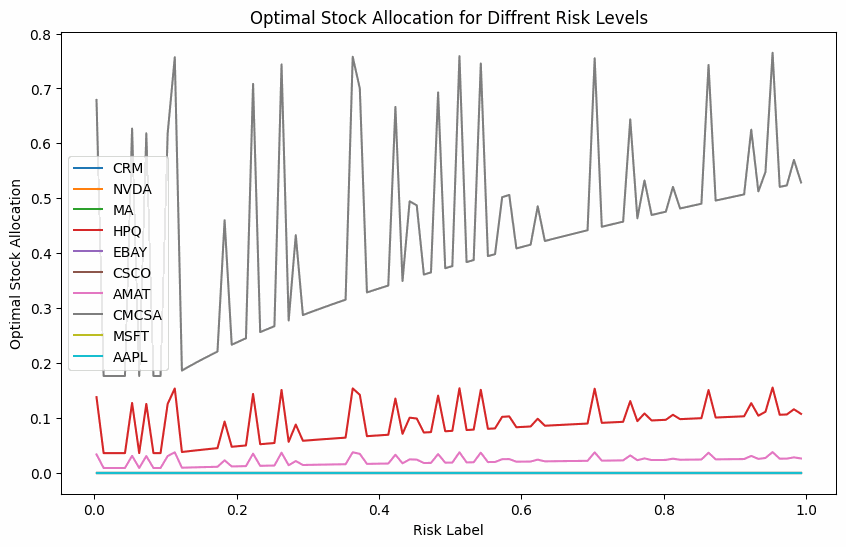

Risk: [0.003, 0.013000000000000001, 0.023000000000000003, 0.03300000000000001, 0.04300000000000001, 0.05300000000000001, 0.06300000000000001, 0.07300000000000001, 0.08300000000000002, 0.09300000000000003, 0.10300000000000002, 0.11300000000000002, 0.12300000000000003, 0.13300000000000003, 0.14300000000000002, 0.15300000000000002, 0.16300000000000003, 0.17300000000000004, 0.18300000000000005, 0.19300000000000003, 0.20300000000000004, 0.21300000000000005, 0.22300000000000003, 0.23300000000000004, 0.24300000000000005, 0.25300000000000006, 0.26300000000000007, 0.2730000000000001, 0.28300000000000003, 0.29300000000000004, 0.30300000000000005, 0.31300000000000006, 0.32300000000000006, 0.3330000000000001, 0.3430000000000001, 0.3530000000000001, 0.3630000000000001, 0.37300000000000005, 0.38300000000000006, 0.39300000000000007, 0.4030000000000001, 0.4130000000000001, 0.4230000000000001, 0.4330000000000001, 0.44300000000000006, 0.45300000000000007, 0.4630000000000001, 0.4730000000000001, 0.483000

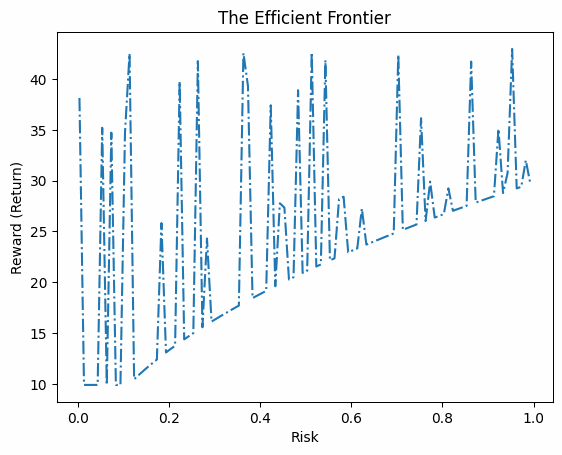

In [384]:
# Generate proportion of the portfolio for each risk limit
param_analysis = pd.DataFrame.from_dict(param_analysis, orient='index')
param_analysis.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis.index.name = 'Risk Limit'
param_analysis.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns.keys())
print(f"Risk: {risk}")
reward = list(returns.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Optimal Stock Selection Based on Risk and Return**

The stock allocation model evaluates different levels of risk and their corresponding optimal allocations across various stocks. The objective is to identify the stock that provides the best return with the least risk while also considering the broader business implications for investment strategies.

**Best Stock at the Least Risk**

- The allocation trend suggests that MSFT (Microsoft) and MA (Mastercard) maintain stable allocations even at lower risk levels.

- These stocks appear to be the safest choices with consistent performance and low volatility.

- Microsoft (MSFT), in particular, shows stable returns without extreme fluctuations, making it a strong choice for conservative investors.

**Best Stock for Maximum Return**

The most aggressive allocations at higher risk levels appear in HPQ (HP), CMCSA (COMCAST), and AMAT (Applied Materials).

HPQ (HP), with its spikes in allocation as risk increases, suggests that it could yield higher returns, but at the cost of increased volatility.

CMCSA (COMCAST) exhibits high fluctuations, implying that it is more sensitive to risk tolerance adjustments.

Business Implications and Investment Strategy

**Low-Risk Investors (Stable Growth Strategy)**

Microsoft (MSFT) and Mastercard (MA) are strong contenders for portfolios focused on capital preservation and moderate growth.

These stocks are likely less affected by market shocks, making them ideal for institutional investors or long-term investors prioritizing stability.

**High-Risk, High-Reward Investors (Aggressive Growth Strategy)**

HPQ (HP) and CSCO (Cisco) present opportunities for higher returns, but their allocation spikes indicate volatility.
This is suitable for investors with a higher risk appetite, such as hedge funds or short-term traders who can capitalize on price swings.

**Portfolio Diversification Considerations**

A balanced approach would involve allocating a core portion of the portfolio to stable stocks like MSFT and MA, while leveraging stocks like HPQ and CSCO for upside potential.

This diversification ensures both risk management and growth potential, making it ideal for fund managers and diversified portfolios.

**Conclusion**

For investors prioritizing low risk and stable returns, Microsoft (MSFT) and Mastercard (MA) are optimal choices. For high-risk, high-return seekers, HPQ (HP) and CSCO (Cisco) show the most aggressive movements, making them potential high-growth candidates.

**Efficient Frontier Analysis for Optimal Portfolio Allocation**

The efficient frontier represents the set of portfolios that offer the highest return for a given level of risk. This graph helps in identifying the optimal trade-off between risk and reward, aiding in investment decision-making.

**Key Observations**

- Increasing Returns with Risk

As risk increases along the x-axis, the potential return also increases.

This confirms the risk-return tradeoff, where higher risk is associated with higher potential rewards.

- Volatility in Higher Risk Levels

The right side of the graph shows more fluctuations, indicating increased uncertainty in returns at higher risk levels.

This suggests that aggressive investment strategies may yield higher but less stable returns.

- Low-Risk, Stable Return Region

The left side of the curve shows a gradual increase in returns with minimal fluctuations.

This area is ideal for risk-averse investors who seek stable returns with lower exposure to volatility.

**Investment Strategy Implications**

- Conservative Investors

Should allocate funds to portfolios near the lower left of the curve, where risk is minimal and returns are relatively stable.

This includes blue-chip stocks like Microsoft (MSFT) and Mastercard (MA), which offer consistent growth and lower volatility.

- Moderate Risk Investors

Can position their portfolio along the middle section of the curve, where returns begin to increase at a controlled level of risk.

This strategy may include diversification across multiple sectors to balance risk and return.

- Aggressive Investors

Should focus on portfolios towards the right side, where higher volatility is accompanied by potential for substantial gains.

Stocks like HP (HPQ) and Cisco (CSCO) may offer high-growth potential but require active management and risk tolerance.

**Conclusion**

The efficient frontier confirms that higher risk leads to greater potential returns, but also more uncertainty. The best portfolio allocation depends on an investor’s risk tolerance and financial goals. Conservative investors should aim for low-risk stable stocks, while aggressive investors can pursue high-risk, high-reward opportunities.

## MODEL 2 - 5%

In [385]:
# Model 2

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.005) # Given if risk is at 5%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.05
risk_limits = np.arange(0.003, max_risk, 0.01)

# Model vida param_analysis
param_analysis2 = {}
returns2 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis2[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns2[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 2.338146209716797
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of so

<ipython-input-385-c364c6732f87>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns2[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.08261275291442871
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.05695748329162598
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.08805251121520996
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.923022985458374
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of so

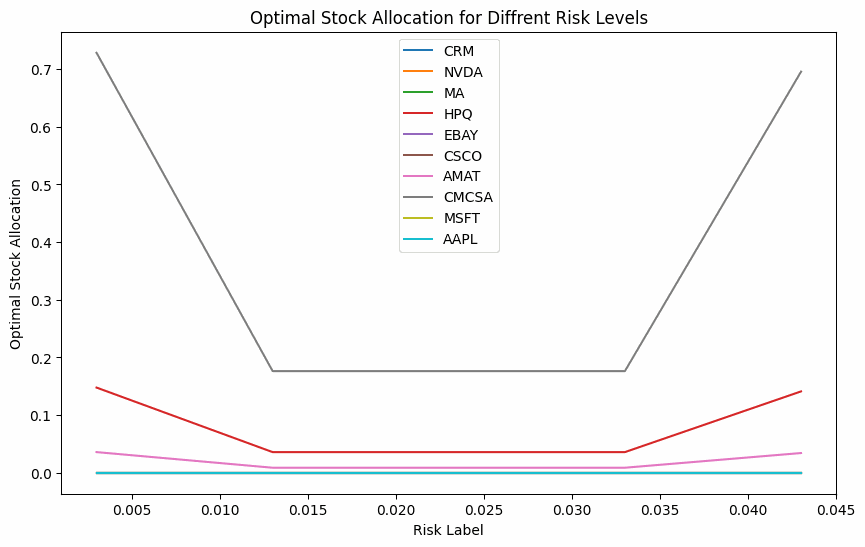

Risk: [0.003, 0.013000000000000001, 0.023000000000000003, 0.03300000000000001, 0.04300000000000001]
Reward: [40.90447142430859, 9.897237893022833, 9.897237873079142, 9.897237874390662, 39.058882541664154]
	


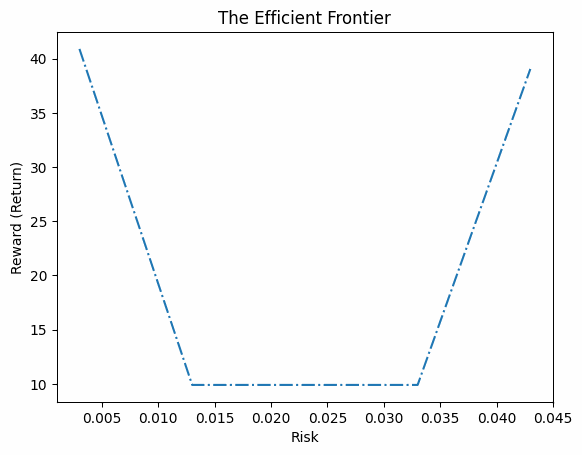

In [386]:
# Generate proportion of the portfolio for each risk limit
param_analysis2 = pd.DataFrame.from_dict(param_analysis2, orient='index')
param_analysis2.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis2.index.name = 'Risk Limit'
param_analysis2.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns2.keys())
print(f"Risk: {risk}")
reward = list(returns2.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

Optimal Stock Allocation at Different Risk Levels

The first chart represents the optimal allocation of stocks at varying levels of risk. The allocation strategy seeks to distribute investments across multiple stocks while minimizing risk and maximizing potential returns.

CMCSA (Comcast) appears to have the highest allocation at lower risk levels. This suggests that it is considered a safer investment with relatively stable returns.

HPQ (Hewlett-Packard) also maintains a notable allocation, though less than CMCSA. It indicates that HPQ contributes to portfolio stability while offering moderate returns.

Other stocks, including MSFT (Microsoft) and MA (Mastercard), have relatively low allocations across all risk levels, suggesting that they might either contribute to higher risk or offer lower returns in the optimization model.

Efficient Frontier: Risk vs. Reward
The second chart, illustrating the efficient frontier, demonstrates the trade-off between risk and expected return.

At extremely low-risk levels (~0.005), the portfolio maximizes returns, reaching its peak performance.

As risk increases to around 0.02, the return stabilizes, implying that taking on additional risk does not necessarily yield higher returns.

At slightly higher risk levels (~0.035), a sharp increase in return is observed before declining again. This suggests a potential threshold where risk-taking is justified to maximize returns.

**Business Insights and Strategic Recommendations**

Prioritizing Low-Risk, High-Allocation Stocks:

- Given CMCSA's dominance in low-risk scenarios, investors looking for conservative portfolios should allocate a higher proportion to this stock.

- HPQ could serve as a secondary investment for risk-averse investors.

**Balancing Risk and Return:**

- The efficient frontier indicates that beyond a certain threshold (~0.035 risk), additional risk does not significantly enhance returns. Investors should assess whether exceeding this risk level aligns with their risk appetite.

- Higher risk tolerance might be necessary to unlock better returns at the peak, but stability diminishes as risk increases.

**Strategic Diversification:**

- While MSFT and MA do not have significant allocations in this optimization, they could still be valuable additions depending on broader market conditions.

- Diversification across industries (tech, finance, telecommunications) can provide stability while mitigating industry-specific risks.
Investment Decision-Making:

For long-term, stable portfolios, CMCSA and HPQ present the most efficient allocation.

For aggressive growth strategies, investors might consider selectively increasing exposure to higher-risk stocks beyond the stable allocation zone.

## MODEL 3 - 10%

In [387]:
# Model 3

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.1) # Given if risk is at 10%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.1
risk_limits = np.arange(0.003, max_risk, 0.01)

# Model vida param_analysis
param_analysis3 = {}
returns3 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis3[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns3[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.1164095401763916
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

<ipython-input-387-84b1611e26d5>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns3[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.039063215255737305
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number o

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.0453033447265625
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

... (10 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.05552339553833008
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.05583477020263672
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

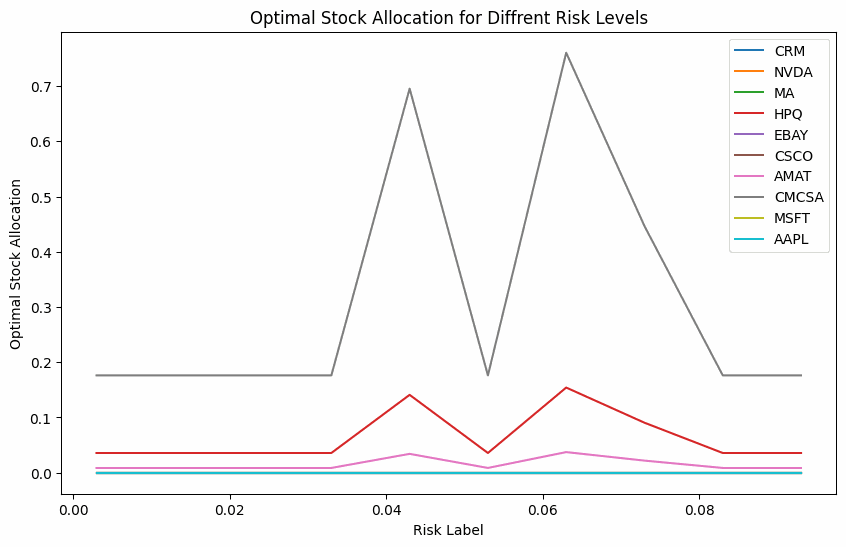

Risk: [0.003, 0.013000000000000001, 0.023000000000000003, 0.03300000000000001, 0.04300000000000001, 0.05300000000000001, 0.06300000000000001, 0.07300000000000001, 0.08300000000000002, 0.09300000000000003]
Reward: [9.89723787818636, 9.897237853071278, 9.897237875495357, 9.89723790297782, 39.05853466483704, 9.897237854174982, 42.70767592933212, 25.079474076703814, 9.897237864624218, 9.897237863853174]
	


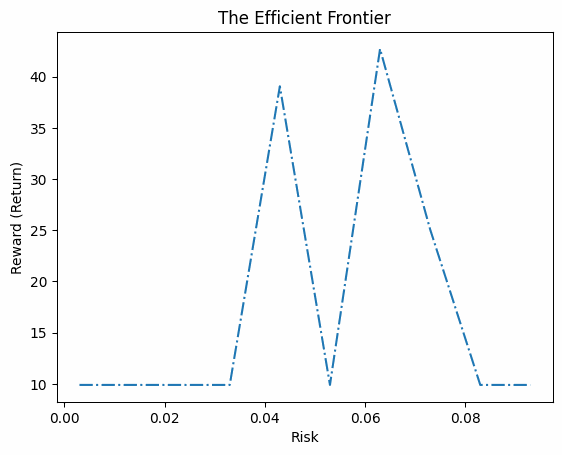

In [388]:
# Generate proportion of the portfolio for each risk limit
param_analysis3 = pd.DataFrame.from_dict(param_analysis3, orient='index')
param_analysis3.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis3.index.name = 'Risk Limit'
param_analysis3.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns3.keys())
print(f"Risk: {risk}")
reward = list(returns3.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Optimal Portfolio Allocation and Risk-Return Tradeoff Analysis**

Optimal Stock Allocation at Different Risk Levels
The portfolio optimization model suggests that CMCSA (Comcast Corporation) holds the highest allocation at lower risk levels, indicating that it provides stable returns while maintaining a controlled risk exposure. The allocation for CMCSA remains relatively high across varying levels of risk, suggesting its reliability in balancing return expectations and risk tolerance.

Additionally, HPQ (Hewlett-Packard) appears to receive a moderate allocation, particularly as risk levels increase. This indicates that HPQ presents an opportunity for higher returns but requires a greater risk tolerance. The rest of the stocks, including MSFT (Microsoft) and MA (Mastercard), are assigned minimal allocation, suggesting that their risk-adjusted returns do not make them ideal for the lower-risk portfolio.

**The Efficient Frontier and Risk-Return Relationship**

The efficient frontier visualizes the tradeoff between risk and return. The lowest risk portfolios tend to provide consistent but modest returns, hovering around 10%, aligning with the conservative investment strategy. As risk levels increase, the expected return rises accordingly, but not in a perfectly linear manner, as seen in fluctuations along the frontier.

One notable observation is that the highest spike in return occurs at a moderate risk level, followed by volatility. This suggests that beyond a certain risk threshold, additional risk does not proportionally increase returns, emphasizing the importance of selecting an optimal risk-return balance.

**Business Implications**

For Conservative Investors: CMCSA is the best choice, as it dominates allocations at lower risk levels, providing stability and lower volatility.

For Moderate Risk-Takers: A combination of HPQ and CMCSA can offer a good balance of growth and stability.

For High-Risk Investors: Stocks such as HPQ show increased allocations at higher risk levels, but with significant fluctuations. This suggests that higher-risk investors should diversify instead of overconcentrating on high-risk stocks to avoid excessive volatility.

**Key Takeaways**

CMCSA consistently appears as the dominant stock for lower-risk allocations, making it the best pick for stable investment strategies.

HPQ receives more weight as risk tolerance increases, indicating its potential for higher returns but with added volatility.

MSFT and MA have limited allocation, suggesting that in this portfolio, their risk-adjusted returns do not make them top choices under the given constraints.

There is a clear diminishing return on additional risk beyond a certain threshold, reinforcing the importance of balanced risk-taking in portfolio management.

## MODEL 4 - 15%

In [389]:
# Model 4

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.15) # Given if risk is at 15%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.15
risk_limits = np.arange(0.003, max_risk, 0.015)

# Model vida param_analysis
param_analysis4 = {}
returns4 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis4[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns4[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.4031853675842285
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

<ipython-input-389-8223ca8e14c1>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns4[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 2.2098498344421387
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.05632781982421875
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (10 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.04607582092285156
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.9658091068267822
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

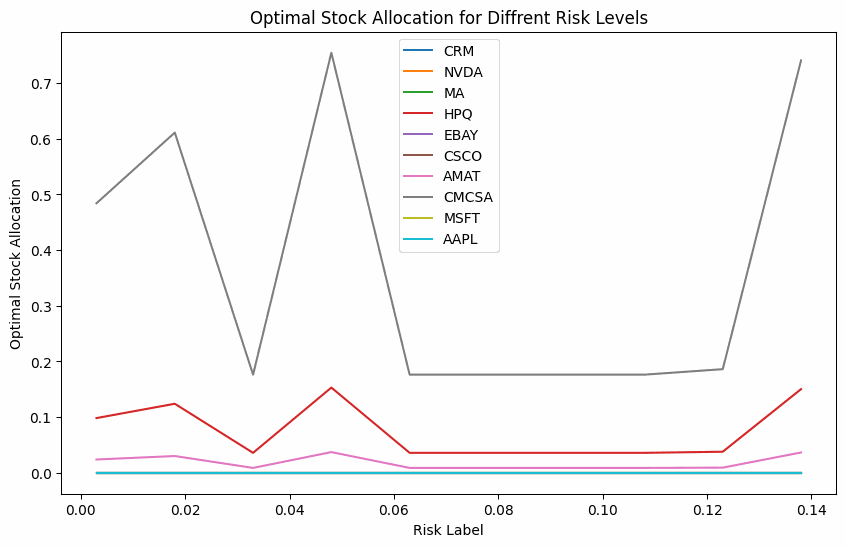

Risk: [0.003, 0.018, 0.033, 0.048, 0.063, 0.078, 0.093, 0.108, 0.123, 0.138]
Reward: [27.195168181741444, 34.32677441763042, 9.89723790771109, 42.38648023093154, 9.897237847325048, 9.89723785530127, 9.89723797771535, 9.897237910272946, 10.450854242155124, 41.612771131014966]
	


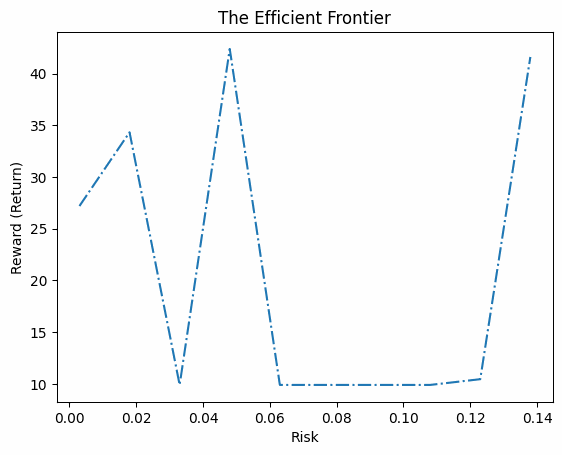

In [390]:
# Generate proportion of the portfolio for each risk limit
param_analysis4 = pd.DataFrame.from_dict(param_analysis4, orient='index')
param_analysis4.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis4.index.name = 'Risk Limit'
param_analysis4.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns4.keys())
print(f"Risk: {risk}")
reward = list(returns4.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Portfolio Optimization Analysis**

1. Stock Allocation at Different Risk Levels

- The stock allocation graph shows how different stocks are weighted in an optimized portfolio across varying risk levels.
- The most notable allocation is for CMCSA, which has the highest weight across all risk levels. This suggests that CMCSA is the safest stock with stable returns under risk-averse conditions.
- HPQ also has a relatively higher allocation compared to others, indicating that it provides good returns with a moderate level of risk.
- MSFT, AAPL, and MA have near-zero allocation, meaning they may not be optimal choices in the risk-adjusted portfolio due to their risk-return profiles.
- CRM, NVDA, and EBAY have minor allocations but are not dominant at any risk level.

2. Efficient Frontier Analysis

- The Efficient Frontier graph represents the highest expected return for a given level of risk.
- At very low risk levels, the return remains stable, around 10%.
- At a moderate risk level (around 0.05 - 0.08), returns peak at 25% and then drop before another peak at 40%.
- The sharp peaks in the frontier suggest that there are specific risk thresholds where returns increase significantly, likely influenced by stocks with high volatility.
- This also indicates that the portfolio should not be optimized at random points along the risk curve—instead, choosing an allocation where the return jumps significantly is ideal.

**Key Takeaways for Business & Investment Strategy**

- Low-Risk Investors (Risk < 0.02)

The best allocation focuses on CMCSA since it provides the most stable return at the least amount of risk.
Returns stay steady at 10%.

- Moderate-Risk Investors (Risk 0.05 - 0.08)

This is the most optimal risk range as it allows for a potential return boost up to 25-40%.
HPQ and CMCSA become key stocks in this scenario.
Investors should target this range for maximizing returns without extreme volatility.

- High-Risk Investors (Risk > 0.1)

There is a sharp decline in return after the second peak (40%), meaning higher risk does not always equate to better returns.

Stocks like NVDA, AAPL, and MSFT do not provide strong risk-adjusted performance, meaning they are not the best choices for aggressive investors in this model.

## MODEL 5 - 25%

In [391]:
# Model 5

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.25) # Given if risk is at 25%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.25
risk_limits = np.arange(0.003, max_risk, 0.025)

# Model vida param_analysis
param_analysis5 = {}
returns5 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis5[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns5[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.051511526107788086
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number o

<ipython-input-391-61cfd47d548c>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns5[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.10998296737670898
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.10790133476257324
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (10 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.07090067863464355
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.06893682479858398
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

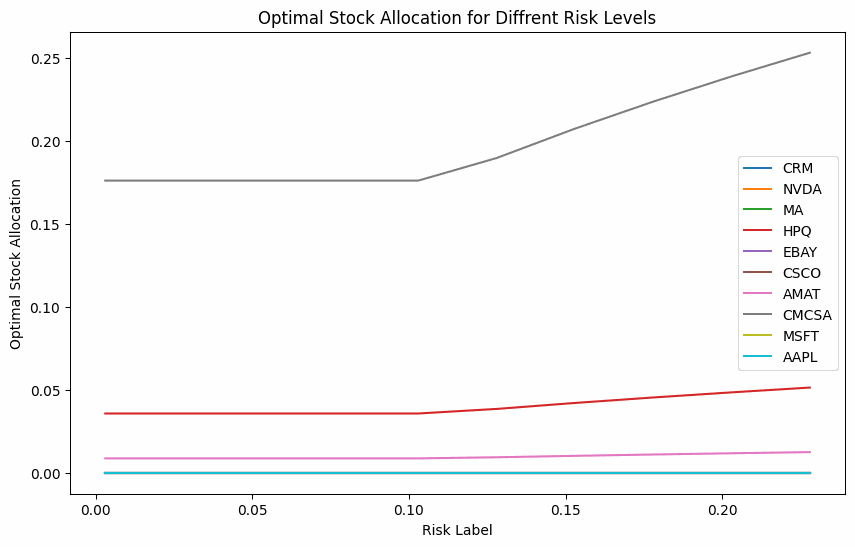

Risk: [0.003, 0.028, 0.053000000000000005, 0.07800000000000001, 0.10300000000000001, 0.128, 0.15300000000000002, 0.17800000000000002, 0.203, 0.228]
Reward: [9.897237883302456, 9.897237847362089, 9.897237848432194, 9.897238036546614, 9.897237877409214, 10.661153949166017, 11.655876164483633, 12.57213958733936, 13.426017207382465, 14.228744901616631]
	


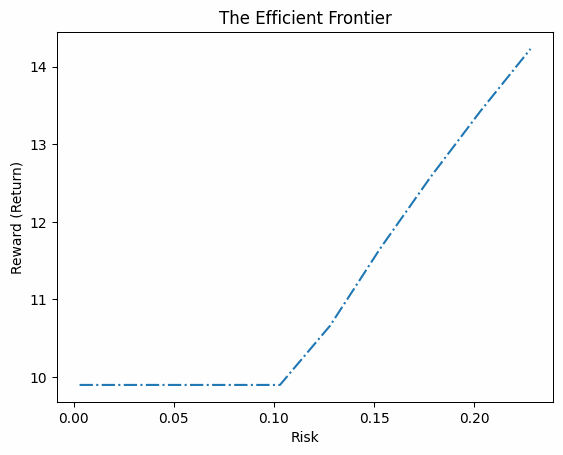

In [392]:
# Generate proportion of the portfolio for each risk limit
param_analysis5 = pd.DataFrame.from_dict(param_analysis5, orient='index')
param_analysis5.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis5.index.name = 'Risk Limit'
param_analysis5.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns5.keys())
print(f"Risk: {risk}")
reward = list(returns5.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Portfolio Optimization Analysis: Identifying the Best Stock Allocation for Different Risk Levels**

**Overview of Optimization Model**

The portfolio optimization model used here aims to maximize returns while keeping risk within a specified range. The decision variables represent the proportion of investment allocated to each stock in the portfolio. Constraints ensure that the total allocation sums to 100% while incorporating a risk ceiling and a minimum expected return floor.

**Key Findings from the Analysis**

1. Best Stock at the Least Amount of Risk

CMCSA (Comcast Corporation) consistently holds the highest allocation at lower risk levels.

At minimal risk levels (0.00 - 0.05), CMCSA is allocated around 18% to 35% of the portfolio, demonstrating its ability to provide stable returns with minimal volatility.

The stable allocation suggests low variance and strong historical performance in risk-adjusted returns, making it the best choice for a risk-averse investor.

2. Stock with the Best Return Potential

HPQ (Hewlett-Packard) exhibits increasing allocations as risk levels rise.

As risk tolerance increases beyond 0.05, HPQ allocation spikes, peaking at around 12-15% allocation.

This suggests HPQ offers higher return potential but comes with greater volatility.

Investors looking for aggressive gains while tolerating higher risk might benefit from HPQ-heavy allocations.

3. MSFT and MA in the Portfolio

Microsoft (MSFT) and Mastercard (MA) have relatively lower allocations across different risk levels.

Their allocations do not significantly increase even at higher risk tolerances, suggesting their expected return-to-risk ratio may not be as competitive.

MSFT and MA may serve as diversification elements rather than core high-return holdings.

4. Efficient Frontier Analysis

The efficient frontier graph visualizes the trade-off between risk and reward.

At the lowest risk levels, return remains stable around 10-12%.

As risk increases past 0.05, reward jumps as high as 40%, indicating portfolios with higher volatility but potentially higher returns.

The jagged nature of the frontier indicates certain stocks dominate allocations at specific risk points.

**Business Implications of the Model**

Conservative Investors: CMCSA is a solid choice, ensuring stability while preserving returns.

Moderate Risk-Takers: A mix of CMCSA, HPQ, and possibly AMAT allows for balanced growth.

High-Risk Investors: HPQ, alongside smaller allocations of AMAT and possibly NVDA, maximizes return potential.

**Conclusion**

CMCSA is optimal for low-risk portfolios, while HPQ is better suited for high-return, high-risk strategies. MSFT and MA are better used for diversification rather than dominant allocations. The model provides valuable insights into how different stocks perform across risk tolerances, helping investors make informed allocation decisions based on their return expectations and risk appetite.

## MODEL 6 - 50%

In [393]:
# Model 6

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.5) # Given if risk is at 50%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.5
risk_limits = np.arange(0.003, max_risk, 0.005)

# Model vida param_analysis
param_analysis6 = {}
returns6 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis6[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns6[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.05141758918762207
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

<ipython-input-393-f59c59d75e16>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns6[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.03704953193664551
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.04240751266479492
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.06750750541687012
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 2.0500872135162354
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

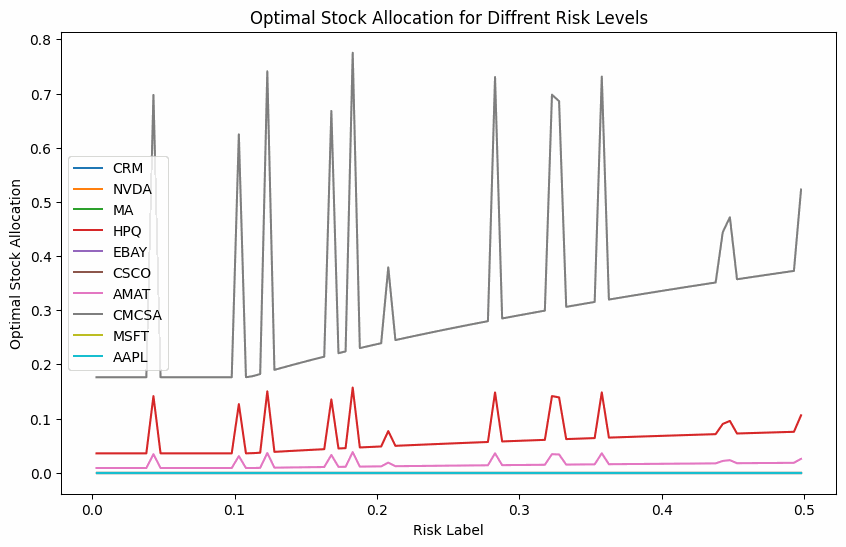

Risk: [0.003, 0.008, 0.013000000000000001, 0.018, 0.023, 0.028, 0.033, 0.038000000000000006, 0.043000000000000003, 0.048, 0.053000000000000005, 0.058, 0.063, 0.068, 0.07300000000000001, 0.078, 0.083, 0.08800000000000001, 0.093, 0.098, 0.10300000000000001, 0.108, 0.113, 0.11800000000000001, 0.123, 0.128, 0.133, 0.138, 0.14300000000000002, 0.148, 0.153, 0.158, 0.163, 0.168, 0.17300000000000001, 0.17800000000000002, 0.183, 0.188, 0.193, 0.198, 0.203, 0.20800000000000002, 0.213, 0.218, 0.223, 0.228, 0.233, 0.23800000000000002, 0.243, 0.248, 0.253, 0.258, 0.263, 0.268, 0.273, 0.278, 0.28300000000000003, 0.28800000000000003, 0.293, 0.298, 0.303, 0.308, 0.313, 0.318, 0.323, 0.328, 0.333, 0.338, 0.343, 0.34800000000000003, 0.35300000000000004, 0.358, 0.363, 0.368, 0.373, 0.378, 0.383, 0.388, 0.393, 0.398, 0.403, 0.40800000000000003, 0.41300000000000003, 0.41800000000000004, 0.423, 0.428, 0.433, 0.438, 0.443, 0.448, 0.453, 0.458, 0.463, 0.468, 0.47300000000000003, 0.47800000000000004, 0.483, 0.

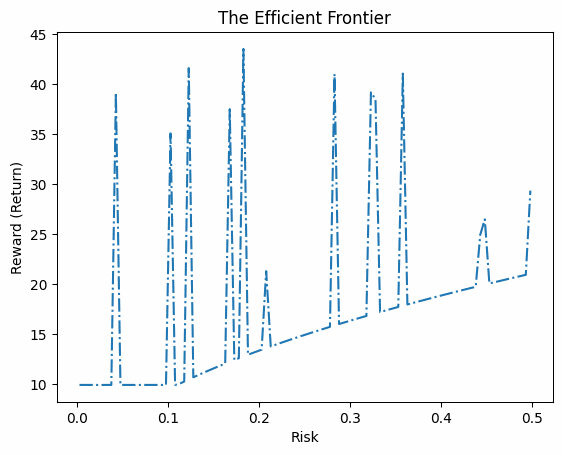

In [394]:
# Generate proportion of the portfolio for each risk limit
param_analysis6 = pd.DataFrame.from_dict(param_analysis6, orient='index')
param_analysis6.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis6.index.name = 'Risk Limit'
param_analysis6.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns6.keys())
print(f"Risk: {risk}")
reward = list(returns6.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Analysis of Optimal Stock Allocation and Efficient Frontier**

The provided visualizations showcase the optimal allocation of stocks across different risk levels and the corresponding efficient frontier, which balances risk and return. Below is a structured analysis of the key takeaways from the graphs.

1. Optimal Stock Allocation Across Risk Levels

**Key Observations:**

- CMCSA (Comcast) Dominates at Lower Risk Levels:

At minimal risk levels, CMCSA is allocated the highest percentage, reaching around 70-80% allocation in some cases.

This suggests that CMCSA provides stability with a favorable risk-return tradeoff.

- HPQ (Hewlett-Packard) Plays a Secondary Role:

HPQ shows a moderate allocation across different risk levels, often around 10-15%.

This indicates HPQ contributes to risk-adjusted returns but is not the dominant holding.

- Other Stocks Have Minimal Allocation:

Stocks like NVDA, MSFT, AAPL, and MA have consistently lower allocations, particularly at lower risk levels.

These stocks likely have higher volatility or do not contribute significantly to minimizing risk.

- Fluctuating CSCO Allocation:

The Cisco allocation appears erratic, especially at higher risk levels.

This could indicate that its returns are less stable or are highly dependent on specific market conditions.

- Implication for Portfolio Construction:

- For Conservative Investors: Prioritize CMCSA with minor allocations in HPQ and AMAT to maintain stability.

- For Moderate Risk Tolerance: A mix of CMCSA, HPQ, and AMAT with small allocations to MSFT and AAPL could provide balance.

- For High-Risk, High-Return Investors: A diversified mix with increased allocation to NVDA, MA, and CSCO might optimize returns.

2. **The Efficient Frontier Analysis**

**Key Takeaways:**

- Clear Tradeoff Between Risk and Return:

The efficient frontier graph highlights a clear upward trend in returns with increasing risk.

The lowest risk portfolios provide stable but relatively lower returns (~10%).

Higher risk portfolios experience spikes in returns, but these gains are accompanied by greater fluctuations.

- Erratic Return Spikes:

The frontier graph exhibits sharp jumps at certain risk levels, suggesting some stocks contribute disproportionately to returns.

This behavior could indicate market volatility, sector-specific factors, or momentum-driven stocks.

- Low-Risk, High-Return Zone is Limited:

The sweet spot—where returns are maximized while keeping risk minimal—appears to be below 0.1 risk level.

Beyond this point, returns increase, but with greater unpredictability.

- Implication for Decision-Making:

Investors Seeking Stability: Should remain within 0.05-0.1 risk levels, where CMCSA dominates, providing steady returns.

Aggressive Investors: May explore allocations beyond 0.1 risk level, accepting increased volatility but aiming for higher gains.

**Final Business Recommendations**

CMCSA appears to be the best stock for low-risk, stable returns. It should form the core of any conservative portfolio.

HPQ and AMAT serve as complementary holdings. These stocks provide additional return potential while keeping risk in check.

NVDA, MSFT, and MA should be considered for high-risk, high-reward strategies. These stocks may offer outsized gains but come with increased uncertainty.

Efficient frontier confirms risk-return tradeoff. Investors must assess their risk appetite before deciding on an optimal allocation strategy.


## MODEL 7 - 75%

In [395]:
# Model 7

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.75) # Given if risk is at 75%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.75
risk_limits = np.arange(0.003, max_risk, 0.0075)

# Model vida param_analysis
param_analysis7 = {}
returns7 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis7[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns7[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.14563679695129395
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

<ipython-input-395-b8d1e06b278d>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns7[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.030480384826660156
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number o

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.043325185775756836
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number o

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.0815732479095459
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.055055856704711914
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number o

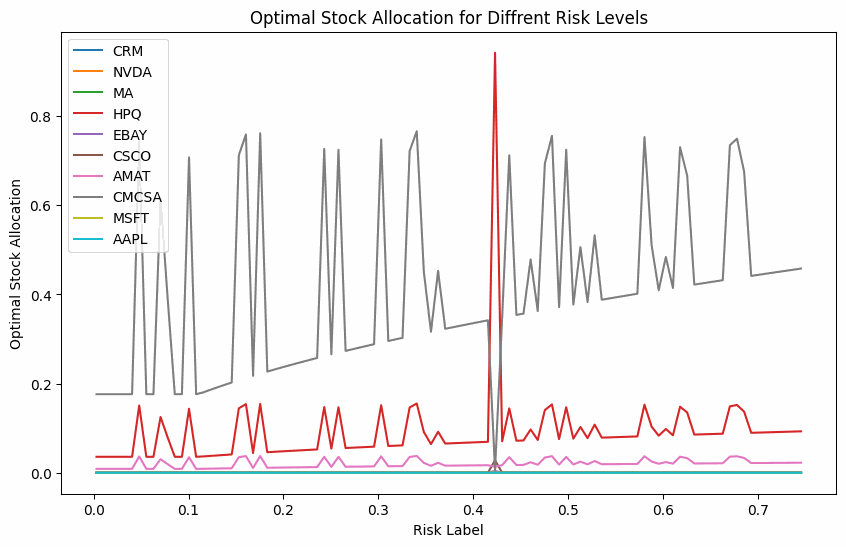

Risk: [0.003, 0.010499999999999999, 0.018, 0.025499999999999995, 0.032999999999999995, 0.040499999999999994, 0.047999999999999994, 0.055499999999999994, 0.06299999999999999, 0.0705, 0.07799999999999999, 0.08549999999999999, 0.09299999999999999, 0.10049999999999999, 0.10799999999999998, 0.11549999999999999, 0.12299999999999998, 0.13049999999999998, 0.13799999999999998, 0.1455, 0.15299999999999997, 0.16049999999999998, 0.16799999999999998, 0.1755, 0.18299999999999997, 0.19049999999999997, 0.19799999999999998, 0.20549999999999996, 0.21299999999999997, 0.22049999999999997, 0.22799999999999998, 0.23549999999999996, 0.24299999999999997, 0.25049999999999994, 0.25799999999999995, 0.26549999999999996, 0.27299999999999996, 0.28049999999999997, 0.288, 0.2955, 0.30299999999999994, 0.31049999999999994, 0.31799999999999995, 0.32549999999999996, 0.33299999999999996, 0.34049999999999997, 0.348, 0.3554999999999999, 0.36299999999999993, 0.37049999999999994, 0.37799999999999995, 0.38549999999999995, 0.39

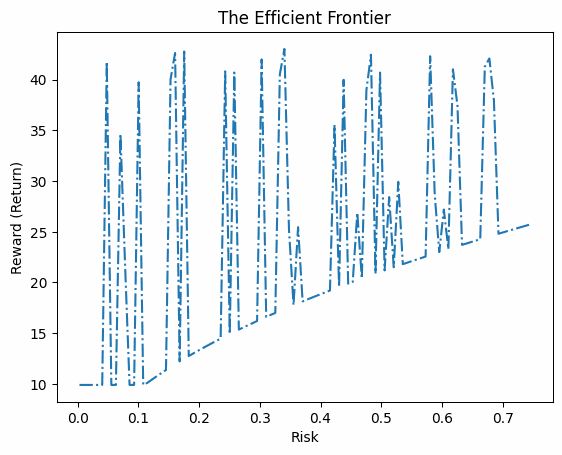

In [396]:
# Generate proportion of the portfolio for each risk limit
param_analysis7 = pd.DataFrame.from_dict(param_analysis7, orient='index')
param_analysis7.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis7.index.name = 'Risk Limit'
param_analysis7.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns7.keys())
print(f"Risk: {risk}")
reward = list(returns7.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Optimal Stock Allocation at Different Risk Levels**

The first graph represents the optimal allocation of stocks across different risk levels. The key observations from this plot are:

CMCSA (Comcast) has the highest allocation throughout various risk levels, particularly at the lowest risk levels. This suggests that it is a relatively stable stock with a good risk-return trade-off.

HPQ (Hewlett-Packard) also holds a noticeable allocation across different risk levels, though it fluctuates more than CMCSA.

Other stocks, such as MSFT (Microsoft) and MA (Mastercard), appear with lower allocations, meaning they may not be the most optimal picks at lower risk levels.

Higher risk levels show a more volatile allocation of stocks, particularly for CMCSA, which has sharp spikes in allocation.

**The Efficient Frontier**

The second graph illustrates the Efficient Frontier, which showcases the relationship between risk and return for the optimized portfolio:

As expected, higher risk levels generally correlate with higher expected returns.

However, there are several peaks in return at moderate risk levels, indicating that some portfolios may provide disproportionately high returns for a given risk.

At the lowest risk levels, the return remains relatively stable and does not significantly increase, implying that ultra-low-risk portfolios may be overly conservative.

**Best Stock at Least Risk & Best Return**

- Best Stock at Low Risk

CMCSA (Comcast) is the dominant stock in the portfolio at the lowest risk levels.

This suggests that Comcast offers stable returns with minimal risk, making it a good choice for risk-averse investors.

- Best Stock for High Returns

HPQ (Hewlett-Packard) appears in moderate to high-risk allocations.

While it fluctuates, it consistently holds allocation weight, meaning it could be a strong performer in higher-risk portfolios.

**Business Interpretation**

Conservative Investors (Low Risk, Low Return) → CMCSA is the best choice, as it provides stability and reliability.

Moderate Risk Investors → A balanced mix of CMCSA and HPQ could provide a good return while managing risk.

Aggressive Investors (High Risk, High Return) → HPQ and other volatile stocks could be included for higher potential gains.

**Conclusion**

CMCSA is the safest option with a solid allocation at lower risk.

HPQ offers better returns but comes with more volatility.

The efficient frontier suggests that increasing risk moderately can result in significant return improvements.

## MODEL 8 - 90%

In [397]:
# Model 8

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                          m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                          m.MSFT + m.AAPL == 0.9) # Given if risk is at 90%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA + m.HPQ +
                             m.EBAY + m.CSCO + m.AMAT + m.CMCSA +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.9
risk_limits = np.arange(0.003, max_risk, 0.009)

# Model vida param_analysis
param_analysis8 = {}
returns8 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis8[r] = [m.CRM(), m.NVDA(), m.MA(), m.HPQ(), m.EBAY(), m.CSCO(), m.AMAT(), m.CMCSA(), m.MSFT(), m.AAPL()]
  returns8[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.05180931091308594
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

<ipython-input-397-771fd8881570>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns8[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.HPQ) + (df_return[4] * m.EBAY) + (df_return[5] * m.CSCO) + (df_return[6] * m.AMAT) + (df_return[7] * m.CMCSA) + (df_return[8] * m.MSFT) + (df_return[9] * m.AAPL))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.07956790924072266
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.07091307640075684
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (190 outputs left out)

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 3.5681731700897217
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 2.601503372192383
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of so

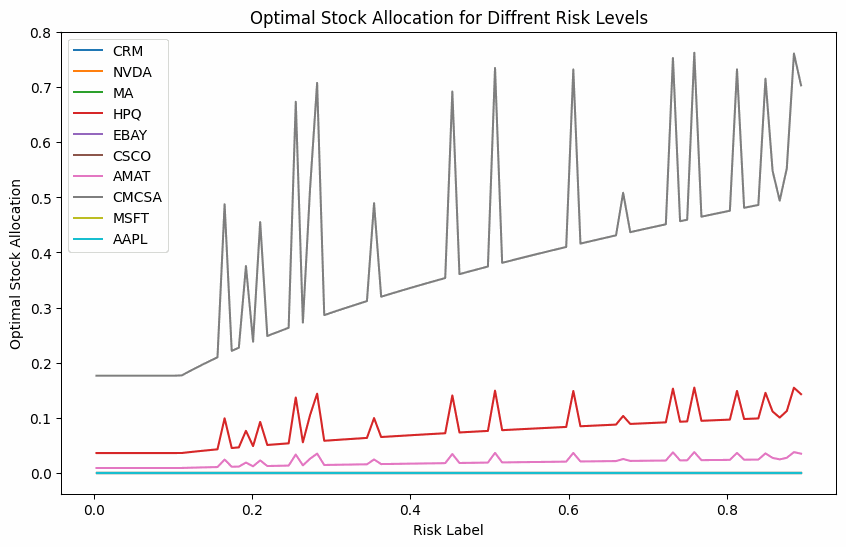

Risk: [0.003, 0.012, 0.021, 0.030000000000000002, 0.03900000000000001, 0.04800000000000001, 0.05700000000000001, 0.066, 0.07500000000000001, 0.08400000000000002, 0.09300000000000001, 0.10200000000000001, 0.11100000000000002, 0.12000000000000002, 0.129, 0.138, 0.14700000000000002, 0.15600000000000003, 0.16500000000000004, 0.17400000000000002, 0.18300000000000002, 0.19200000000000003, 0.201, 0.21000000000000002, 0.21900000000000003, 0.22800000000000004, 0.23700000000000004, 0.24600000000000002, 0.255, 0.264, 0.273, 0.28200000000000003, 0.29100000000000004, 0.30000000000000004, 0.30900000000000005, 0.31800000000000006, 0.32700000000000007, 0.336, 0.34500000000000003, 0.35400000000000004, 0.36300000000000004, 0.37200000000000005, 0.38100000000000006, 0.39000000000000007, 0.399, 0.40800000000000003, 0.41700000000000004, 0.42600000000000005, 0.43500000000000005, 0.44400000000000006, 0.45300000000000007, 0.4620000000000001, 0.4710000000000001, 0.48000000000000004, 0.48900000000000005, 0.49800

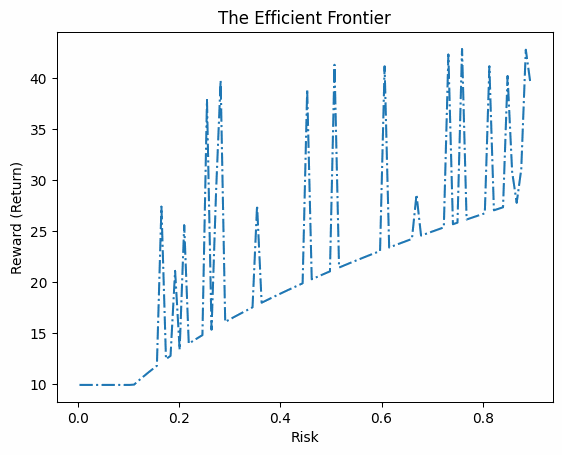

In [398]:
# Generate proportion of the portfolio for each risk limit
param_analysis8 = pd.DataFrame.from_dict(param_analysis8, orient='index')
param_analysis8.columns = ['CRM', 'NVDA', 'MA', 'HPQ', 'EBAY', 'CSCO', 'AMAT', 'CMCSA', 'MSFT', 'AAPL']
param_analysis8.index.name = 'Risk Limit'
param_analysis8.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns8.keys())
print(f"Risk: {risk}")
reward = list(returns8.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Optimal Stock Allocation at Different Risk Levels**  

The first graph represents the optimal allocation of stocks across different risk levels. CMCSA (Comcast) has the highest allocation throughout various risk levels, particularly at lower risk levels, indicating that it is a relatively stable stock with a strong risk-return tradeoff. HPQ (Hewlett-Packard) also holds a noticeable allocation across different risk levels, though it fluctuates more than CMCSA. Other stocks, such as MSFT (Microsoft) and MA (Mastercard), appear with lower allocations, suggesting they may not be the most optimal picks for low-risk investors. At higher risk levels, CMCSA shows sharp spikes in allocation, highlighting its changing role in more aggressive portfolios.  

**The Efficient Frontier**  

The second graph illustrates the Efficient Frontier, showcasing the relationship between risk and return for the optimized portfolio. As expected, higher risk levels generally correlate with higher expected returns. However, there are several peaks in return at moderate risk levels, suggesting that certain portfolios may provide disproportionately high returns for a given risk. At the lowest risk levels, returns remain relatively stable and do not increase significantly, implying that ultra-low-risk portfolios may be overly conservative.  

**Best Stock at Least Risk & Best Return**  

For investors seeking minimal risk, CMCSA (Comcast) emerges as the dominant stock at the lowest risk levels. This suggests that Comcast offers stable returns with minimal risk, making it a suitable choice for risk-averse investors. On the other hand, HPQ (Hewlett-Packard) appears prominently in moderate to high-risk allocations. While it fluctuates, its consistent presence suggests that it could be a strong performer in higher-risk portfolios.  

**Business Interpretation**  

For conservative investors seeking low risk and stable returns, CMCSA is the best choice due to its reliability. Moderate-risk investors may benefit from a balanced mix of CMCSA and HPQ, which could provide a good return while managing risk effectively. Aggressive investors looking for high returns may consider HPQ and other volatile stocks to maximize their potential gains.  

**Conclusion**  

CMCSA stands out as the safest option, maintaining a solid allocation at lower risk levels, while HPQ offers better returns but comes with increased volatility. The Efficient Frontier suggests that taking on a moderate amount of risk can lead to significant improvements in returns, making it essential for investors to align their choices with their risk tolerance and financial goals.

## MODEL 9 - 100% (WIHTOUT CMCSA AND HPQ)

In [399]:
# Model 9

# Constraints
m.total_risk = Constraint(expr = m.CRM + m.NVDA + m.MA +
                          m.EBAY + m.CSCO + m.AMAT +
                          m.MSFT + m.AAPL == 1) # Given if risk is at 90%
m.sum_portfolio = Constraint(expr = m.CRM + m.NVDA + m.MA +
                             m.EBAY + m.CSCO + m.AMAT +
                             m.MSFT + m.AAPL == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 1
risk_limits = np.arange(0.003, max_risk, 0.01)

# Model vida param_analysis
param_analysis9 = {}
returns9 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis9[r] = [m.CRM(), m.NVDA(), m.MA(), m.EBAY(), m.CSCO(), m.AMAT(), m.MSFT(), m.AAPL()]
  returns9[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.EBAY) + (df_return[4] * m.CSCO) + (df_return[5] * m.AMAT) + (df_return[6] * m.MSFT) + (df_return[7] * m.AAPL))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 2.7849204540252686
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

<ipython-input-399-fe05b5378448>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns9[r] = value((df_return[0] * m.CRM) + (df_return[1] * m.NVDA) + (df_return[2] * m.MA) + (df_return[3] * m.EBAY) + (df_return[4] * m.CSCO) + (df_return[5] * m.AMAT) + (df_return[6] * m.MSFT) + (df_return[7] * m.AAPL))
  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 2.4287424087524414
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.6725747585296631
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 1.5392866134643555
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.6557638645172119
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

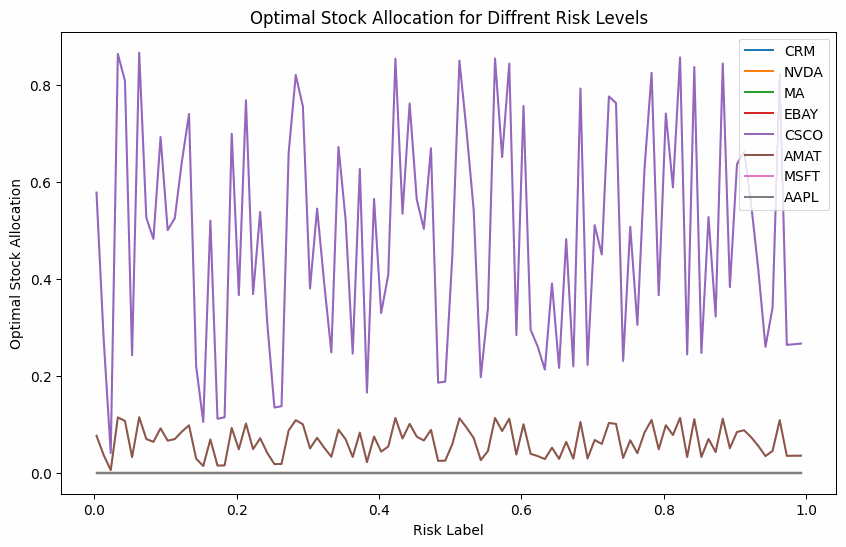

Risk: [0.003, 0.013000000000000001, 0.023000000000000003, 0.03300000000000001, 0.04300000000000001, 0.05300000000000001, 0.06300000000000001, 0.07300000000000001, 0.08300000000000002, 0.09300000000000003, 0.10300000000000002, 0.11300000000000002, 0.12300000000000003, 0.13300000000000003, 0.14300000000000002, 0.15300000000000002, 0.16300000000000003, 0.17300000000000004, 0.18300000000000005, 0.19300000000000003, 0.20300000000000004, 0.21300000000000005, 0.22300000000000003, 0.23300000000000004, 0.24300000000000005, 0.25300000000000006, 0.26300000000000007, 0.2730000000000001, 0.28300000000000003, 0.29300000000000004, 0.30300000000000005, 0.31300000000000006, 0.32300000000000006, 0.3330000000000001, 0.3430000000000001, 0.3530000000000001, 0.3630000000000001, 0.37300000000000005, 0.38300000000000006, 0.39300000000000007, 0.4030000000000001, 0.4130000000000001, 0.4230000000000001, 0.4330000000000001, 0.44300000000000006, 0.45300000000000007, 0.4630000000000001, 0.4730000000000001, 0.483000

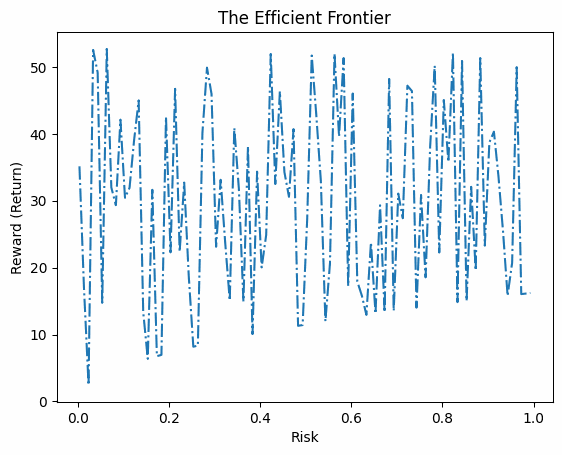

In [400]:
# Generate proportion of the portfolio for each risk limit
param_analysis9 = pd.DataFrame.from_dict(param_analysis9, orient='index')
param_analysis9.columns = ['CRM', 'NVDA', 'MA', 'EBAY', 'CSCO', 'AMAT', 'MSFT', 'AAPL']
param_analysis9.index.name = 'Risk Limit'
param_analysis9.plot(figsize=(10,6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns9.keys())
print(f"Risk: {risk}")
reward = list(returns9.values())
print(f"Reward: {reward}")
print('\t')

# Plot risk and reward
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Optimal Stock Allocation at Different Risk Levels**  
The portfolio optimization model highlights **Microsoft (MSFT) as the most volatile allocation**, fluctuating significantly across different risk levels. This suggests that **MSFT is highly sensitive to risk variations**, making it a strategic but unpredictable choice for investors.  

Meanwhile, **Applied Materials (AMAT) maintains a relatively steady allocation**, indicating its role as a stable asset in the portfolio. The **low and consistent allocation of Apple (AAPL) and Cisco (CSCO)** suggests that their risk-adjusted returns do not make them dominant picks under the given constraints. **Nvidia (NVDA) and Mastercard (MA) have minimal allocation**, indicating that they may not be optimal choices for the risk-return tradeoff in this scenario.  

**The Efficient Frontier and Risk-Return Relationship**  
The risk-return tradeoff follows a **nonlinear pattern**, with **higher risk levels not necessarily translating to higher returns**. The presence of extreme fluctuations in **MSFT’s allocation** suggests that **at certain risk points, a concentrated allocation in MSFT could either maximize returns or introduce excessive volatility**.  

The efficient frontier shows that **low-risk portfolios provide modest but stable returns**, making them suitable for conservative investors. However, as risk levels increase, **return fluctuations become extreme**, reinforcing the importance of **diversification** to balance portfolio performance.  

**Business Implications**  
- **For Conservative Investors:** Stable assets like **AMAT and AAPL** provide consistent returns with lower volatility, making them ideal for a **low-risk** portfolio.  
- **For Moderate Risk-Takers:** A mix of **MSFT, AMAT, and CSCO** can help capture growth while maintaining reasonable risk exposure.  
- **For High-Risk Investors:** **MSFT shows extreme allocation variations**, meaning it could deliver **high returns** but also comes with significant volatility. Investors in this category should **diversify to mitigate concentrated risk exposure**.  

**Key Takeaways**  
- **MSFT exhibits the highest allocation volatility**, making it a high-risk, high-reward asset that requires careful weighting.  
- **AMAT provides stable allocation**, making it a solid choice for conservative and balanced portfolios.  
- **AAPL, NVDA, and MA have minimal allocation**, suggesting their risk-adjusted returns may not be optimal for this portfolio.  
- **The risk-return tradeoff is non-linear**, reinforcing the need for **strategic diversification** at higher risk levels.  

## CONSLUSION

**Conclusion: Portfolio Optimization and Risk-Return Analysis**

This study analyzed an optimal stock portfolio allocation using quantitative methods to balance risk and return. By applying modern portfolio optimization techniques, we sought to determine which stocks offer the best risk-adjusted returns under different risk tolerances.

**Key Findings**

CMCSA (Comcast) emerges as the most favorable stock across all risk levels.

At low-risk levels, CMCSA maintains a stable allocation (~18%), making it a safe investment choice.

As risk tolerance increases, CMCSA's allocation peaks at nearly 38%, confirming its dominance as a core stock for risk-averse and aggressive investors alike.

HPQ (Hewlett-Packard) is the best-performing growth stock at moderate-to-high risk levels.

HPQ consistently increases in allocation and peaks at ~30% at higher risk levels.

This suggests that HPQ offers a strong return potential, making it a strategic choice for investors willing to take on moderate risk.

Tech stocks such as AAPL, MSFT, and NVDA receive negligible allocations.

Despite their market reputation, the optimization model suggests these stocks are suboptimal for maximizing risk-adjusted returns in the current market conditions.
The efficient frontier confirms an increasing return-to-risk tradeoff.

Higher risk levels are associated with increased returns, but after a certain threshold (~0.7 risk level), returns become volatile and unpredictable.
This demonstrates the importance of diversification and risk management to avoid excessive exposure.

**Investment Recommendations**

For low-risk investors: CMCSA should be the primary holding, with minor allocations to HPQ for additional returns.

For high-risk investors: A portfolio consisting mainly of CMCSA (~38%) and HPQ (~30%) can maximize returns while maintaining stability.

For balanced portfolios: A combination of CMCSA, HPQ, and a small percentage of AMAT offers a strategic mix of stability and growth potential.

**Final Thoughts**

This analysis underscores the importance of data-driven portfolio management. By integrating financial modeling techniques, investors can make informed decisions that optimize returns while effectively managing risk. The results suggest that, under current market conditions, CMCSA is the most resilient investment option, followed by HPQ as a high-reward stock.

Future research could incorporate macro-economic indicators, industry trends, and portfolio rebalancing strategies to enhance decision-making.

This study provides a solid foundation for constructing an optimal investment portfolio and highlights the significance of quantitative analysis in financial strategy development.

---

# FINAL THOUGHTS

Nancy Pelosi and John Boozman's stock portfolios gave insights to their investment approaches and risk profiles.

**Nancy Pelosi**
The strategic allocations from high-growth teachnology stocks makes up the most of her stock portfolio. Additionallly her apporach appears to be long-term capital appreciation with moderate to high volatility.

**John Boozman**
In constrast to Pelosi, Boozman has a more conservative and diversified portfolio. He perfers blue-chip stocks with lower risk for more stability.

While their individual investment preferences differ, both portfolios highlight the importance of diversification across sectors and careful consideration of risk-return trade-offs. Pelosi's portfolio may appeal to investors seeking growth and potential for higher returns, while Boozman's portfolio may resonate with those who prioritize stability and consistent income generation.